# Floodwater Segmentation from Sentinel-1 SAR Imagery
## MSc AI & Data Science — University of Hull
**Student:** Sherifdeen Ajibola Oloye   


---


**Dataset:** Sen1Floods11 v1.1 — 446 hand-labeled Sentinel-1 SAR tiles across 11 flood events  
**Input:** VV + VH polarisation bands (2 channels), 512×512 pixels  
**Labels:** Binary flood masks (0=no water, 1=water, -1=no data)  

> All paths, constants, seeds, and utilities
> defined here are required by all subsequent sections.

---
## Section 1: Environment Setup, Imports, Constants, Paths, and Shared Utilities

### 1.1 — Library Imports and Version Verification

All libraries required across the full pipeline are imported here rather than scattered
across sections. This makes dependency issues visible immediately at startup rather than
failing silently mid-pipeline after hours of preprocessing.

In [1]:
#  Standard library 
import os
import sys
import json
import time
import random
import logging
import warnings
import pickle
from pathlib import Path
from datetime import datetime
from typing import Dict, List, Optional, Tuple, Union

# Numerical / data 
import numpy as np
import pandas as pd

#  Geospatial / raster 
import rasterio
from rasterio.transform import from_bounds
from rasterio.enums import Resampling

#  Machine learning 
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# Deep learning 
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision

#  Segmentation models (U-Net, Attention U-Net) 
import segmentation_models_pytorch as smp


#  Augmentation 
import albumentations as A
from albumentations.pytorch import ToTensorV2

#  Visualisation 
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# ── Image processing 
import cv2

#  Progress bars ─────────────────────────────────────────────────────────────
from tqdm.notebook import tqdm


print('All imports successful.')

All imports successful.


---
### 1.2 — Reproducibility: Seed Locking

Deep learning results are non-deterministic by default due to random weight
initialisation, data shuffling, and CUDA kernel ordering. Fixing all random seeds
ensures two runs of the same notebook produce identical results which is a requirement
for reproducible research and fair model comparison.



In [3]:
def set_global_seed(seed: int) -> None:
    """
    Lock all random number generators to a fixed seed for reproducibility.

    Problem solved:
        Without this, every training run produces different weight initialisations,
        different data shuffling, and different augmentation outcomes — making it
        impossible to determine whether performance differences between runs reflect
        architectural changes or random variation.

    Covers: Python random, NumPy, PyTorch CPU and CUDA, cuDNN backend.

    Args:
        seed: Integer seed. SEED=42 is used throughout this project — the same
              default used in the majority of published ML research, making results
              easier to compare.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)      # covers multi-GPU setups
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False  # benchmark=True auto-tunes kernels
                                            # but introduces non-determinism
    os.environ['PYTHONHASHSEED'] = str(seed)


SEED = 42
set_global_seed(SEED)
print(f'Global seed set to {SEED}.')

Global seed set to 42.


---
### 1.3 — Device Configuration

All tensor operations and model parameters will be moved to the device selected here.
Using a single `DEVICE` constant throughout means switching between GPU and CPU
requires changing exactly one value and never happens by accident.

In [4]:
def configure_device() -> torch.device:
    """
    Detect and configure the compute device.

    Problem solved:
        Hardcoding 'cuda' raises an error on machines without a GPU.
        Hardcoding 'cpu' wastes the RTX 3090 on this machine. This function
        detects what is available and falls back gracefully, printing exactly
        what hardware is being used so there is no ambiguity.

    Returns:
        torch.device: 'cuda' if a CUDA GPU is detected, else 'cpu'.
    """
    if torch.cuda.is_available():
        device = torch.device('cuda')
        gpu_name = torch.cuda.get_device_name(0)
        gpu_mem  = torch.cuda.get_device_properties(0).total_memory / 1e9
        print(f'CUDA available — using {gpu_name} ({gpu_mem:.1f} GB VRAM)')
    else:
        device = torch.device('cpu')
        print('WARNING: CUDA not available — falling back to CPU. Training will be slow.')
    return device


DEVICE = configure_device()

CUDA available — using NVIDIA GeForce RTX 3090 (25.8 GB VRAM)


---
### 1.4 — Global Constants

Every constant includes an inline comment explaining **why** that value was chosen,
not just what it is. These are intentional decisions — not defaults.



In [5]:
# Reproducibility 
SEED = 42
# Conventional ML seed. No mathematical significance, but matching published
# work makes results easier to compare and reproduce.

#  Data geometry 
TILE_SIZE  = 512
# Native Sen1Floods11 tile size in pixels. Do not resize source tiles —
# patch extraction handles sub-sampling during preprocessing.

PATCH_SIZE = 256
# Training patch size extracted from each 512x512 tile.
# Why 256: (1) U-Net requires input divisible by 32 due to 4 pooling layers —
# 256 satisfies this. (2) SegFormer accepts arbitrary sizes, so 256 is fine.
# (3) 512 divides exactly by 256 with no remainder — 4 clean patches per tile,
# no data loss, no padding required. (4) Fits 16 patches per batch comfortably
# in 24GB VRAM.

IN_CHANNELS = 2
# Sentinel-1 SAR has two polarisation bands: VV and VH.
# VV (vertical-vertical): sensitive to surface roughness — calm open water
# appears very dark (low backscatter) making it discriminable from land.
# VH (vertical-horizontal): sensitive to volume scattering — provides
# additional contrast between flooded vegetation and dry land.
# Using both channels gives the model complementary information.

NUM_CLASSES = 2
# Binary segmentation: 0 = no water, 1 = water.
# The -1 no-data label in Sen1Floods11 is masked out before training
# and never passed to the loss function.

#  Training hyperparameters 
BATCH_SIZE = 16
# 16 patches of 256x256x2 float32 ≈ 0.5 GB GPU memory per batch.
# RTX 3090 (24 GB) handles this for all four models.


NUM_EPOCHS = 50
# Sufficient for convergence at this dataset scale based on comparable
# SAR segmentation literature. Early stopping (EARLY_STOP_PATIENCE)
# will terminate training before this ceiling if validation IoU plateaus.

EARLY_STOP_PATIENCE = 15
# Stop training if validation IoU does not improve for 15 consecutive epochs.
# Prevents overfitting without manual intervention. 15 epochs gives the
# optimiser enough room to escape local plateaus before terminating.

LEARNING_RATE = 1e-4
# Adam default starting point. Conservative enough to avoid instability
# with the pre-trained SegFormer backbone; sufficient for U-Net from scratch.
# Decayed via ReduceLROnPlateau scheduler during training.

WEIGHT_DECAY = 1e-5
# L2 regularisation. Small value prevents overfitting without noticeably
# slowing convergence. Standard for this class of segmentation task.

#  Data split 
VAL_FRACTION = 0.15
# 15% of non-test tiles used for validation, stratified by region.
# Stratification ensures no single region dominates the validation set.

TEST_REGIONS = ['Spain', 'USA']
# Held out entirely from training and validation.
# Selected as geographically and climatically distinct from the remaining
# 9 regions (temperate Mediterranean + large-scale riverine North America)
# to provide a challenging generalisation test.
# PLACEHOLDER — final confirmation after EDA in Section 2.

# Random Forest 
RF_N_ESTIMATORS = 200
# 200 trees balances variance reduction against training time.
# Performance typically plateaus beyond ~200 for pixel-wise spectral features;
# more trees add cost without meaningful IoU gain.

RF_MAX_DEPTH = 20
# Prevents overfitting to SAR speckle noise. Unconstrained depth on pixel-wise
# features causes the model to memorise noise patterns that do not generalise.

#  SegFormer 
SEGFORMER_VARIANT = 'nvidia/mit-b2'
# MiT-B2 encoder: 25M parameters, 4 hierarchical transformer stages with
# global self-attention. Chosen over:
#   B0/B1 — underpowered for 512px SAR imagery with fine spatial structure.
#   B3/B4/B5 — excessive parameters for binary segmentation; diminishing
#              returns on a dataset of this size.
# B2 is the practical optimum for this task and dataset.

# Inference 
SLIDING_WINDOW_OVERLAP = 0.5
# During test-time inference, 256x256 windows are passed across each full
# 512x512 tile with 50% overlap, then averaged. This eliminates hard boundary
# artefacts at patch edges that would occur with non-overlapping inference.
# Test tiles are never cut into patches — they are evaluated at full 512x512.

# Label encoding (Sen1Floods11 convention) 
LABEL_NO_WATER = 0
LABEL_WATER    = 1
LABEL_NODATA   = -1   # Excluded from all loss calculations and metrics.
                       # Represents cloud cover or sensor gaps in the labels.

# Visualisation 
FIG_DPI = 150


print('Global constants defined.')

Global constants defined.


---
### 1.5 — Path Configuration

All paths derive from a single `BASE_DATA_DIR` root. Moving the dataset to a
different drive or machine requires changing exactly one variable.

**Confirmed dataset structure on this machine:**
```
Sen1Floods11/v1.1/
└── data/
    └── flood_events/
        ├── HandLabeled/
        │   ├── S1Hand/          ← 446 SAR GeoTIFFs (VV+VH, used as input)
        │   ├── LabelHand/       ← 446 binary flood masks (used as labels)
        │   ├── JRCWaterHand/    ← 446 co-registered JRC tiles (not used)
        │   ├── S1OtsuLabelHand/ ← automated labels (not used)
        │   └── S2Hand/          ← optical imagery (not used, SAR project)
        └── WeaklyLabeled/
            ├── S1Weak/          ← 4,384 SAR tiles (used in Section 11 only)
            └── S1OtsuLabelWeak/ ← 4,384 automated labels (used in Section 11)
```

> Only `S1Hand` and `LabelHand` are used in Sections 2–10.
> `S1Weak` and `S1OtsuLabelWeak` are reserved exclusively for the Section 11
> weak label experiment. Never mix them into the main training pipeline.

In [6]:
# ── Base data directory ───────────────────────────────────────────────────────
BASE_DATA_DIR = Path(r'C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\v1.1')
# Raw string (r'...') used to handle Windows backslashes safely.
# Path() wraps it so all downstream operations use forward-slash syntax
# regardless of OS, making the code portable to Linux/Mac without changes.

# ── Hand-labeled data (Sections 2–10) ─────────────────────────────────────────
HAND_DIR   = BASE_DATA_DIR / 'data' / 'flood_events' / 'HandLabeled'
S1_DIR     = HAND_DIR / 'S1Hand'      # Sentinel-1 SAR tiles (input features)
LABEL_DIR  = HAND_DIR / 'LabelHand'   # Binary flood masks (ground truth labels)

# ── Weakly labeled data (Section 11 only) ─────────────────────────────────────
WEAK_DIR        = BASE_DATA_DIR / 'data' / 'flood_events' / 'WeaklyLabeled'
S1_WEAK_DIR     = WEAK_DIR / 'S1Weak'           # 4,384 SAR tiles
LABEL_WEAK_DIR  = WEAK_DIR / 'S1OtsuLabelWeak'  # 4,384 Otsu-thresholded labels
# Otsu labels are automated (not hand-verified). Noisier than LabelHand.
# Using them in Section 11 is a deliberate research question:
# does noisy weak supervision help or hurt compared to clean hand labels alone?

# ── Splits directory (official Sen1Floods11 train/val/test CSVs) ──────────────
SPLITS_DIR = BASE_DATA_DIR / 'splits' / 'flood_handlabeled'
# Contains official split CSVs. We use event-level splits (not tile-level)
# to prevent spatial leakage between train and test.

# ── Output directories ────────────────────────────────────────────────────────
BASE_OUTPUT_DIR = BASE_DATA_DIR.parent / 'flood_seg_outputs'
# Outputs sit one level above v1.1 so they are not inside the dataset folder.

CHECKPOINT_DIR  = BASE_OUTPUT_DIR / 'checkpoints'
# Model weights (.pt) and preprocessing artifacts (.pkl).


FIGURE_DIR      = BASE_OUTPUT_DIR / 'figures'
METRICS_DIR     = BASE_OUTPUT_DIR / 'metrics'
LOG_DIR         = BASE_OUTPUT_DIR / 'logs'

print(f'Data root:    {BASE_DATA_DIR}')
print(f'SAR tiles:    {S1_DIR}')
print(f'Labels:       {LABEL_DIR}')
print(f'Outputs:      {BASE_OUTPUT_DIR}')

Data root:    C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\v1.1
SAR tiles:    C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\S1Hand
Labels:       C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\LabelHand
Outputs:      C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs


---
### 1.6 — Directory Scaffold

Creates all output directories if they do not exist.
Safe to re-run — `exist_ok=True` raises no error if the directory already exists.

In [7]:
def create_directory_scaffold(dirs: List[Path]) -> None:
    """
    Create all required output directories.

    Problem solved:
        Saving a figure or checkpoint to a non-existent directory raises
        FileNotFoundError. Creating all directories at startup eliminates
        this class of error entirely rather than debugging it mid-run.

    Args:
        dirs: List of Path objects to create.
    """
    for d in dirs:
        d.mkdir(parents=True, exist_ok=True)
        print(f'  {d}')


print('Creating output directory scaffold:')
create_directory_scaffold([
    CHECKPOINT_DIR,
    FIGURE_DIR / 'eda',
    FIGURE_DIR / 'random_forest',
    FIGURE_DIR / 'unet',
    FIGURE_DIR / 'attention_unet',
    FIGURE_DIR / 'segformer',
    FIGURE_DIR / 'comparison',
    FIGURE_DIR / 'weak_label',
    METRICS_DIR,
    LOG_DIR,
])
print('Done.')

Creating output directory scaffold:
  C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints
  C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\figures\eda
  C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\figures\random_forest
  C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\figures\unet
  C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\figures\attention_unet
  C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\figures\segformer
  C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\figures\comparison
  C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\figures\weak_label
  C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics
  C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\logs
Done.


---
### 1.7 — Logging Setup

A persistent log file captures all events with timestamps. This is particularly
useful during long training runs where Jupyter output may scroll away or be lost
if the browser tab is closed.

In [8]:
def setup_logging(log_dir: Path) -> logging.Logger:
    """
    Configure a logger that writes to both console and a timestamped log file.

    Problem solved:
        Jupyter output is ephemeral — restarting the kernel or closing the
        browser loses all print output. A file logger captures everything
        permanently, enabling post-hoc debugging of failed training runs.

    Args:
        log_dir: Directory where log files will be written.

    Returns:
        logging.Logger: Configured logger instance.
    """
    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    log_path  = log_dir / f'flood_seg_{timestamp}.log'

    logger = logging.getLogger('flood_seg')
    logger.setLevel(logging.INFO)

    # Prevent duplicate handlers if this cell is re-run
    if logger.handlers:
        logger.handlers.clear()

    fh = logging.FileHandler(log_path)
    fh.setFormatter(logging.Formatter('%(asctime)s | %(levelname)s | %(message)s'))

    ch = logging.StreamHandler()
    ch.setFormatter(logging.Formatter('%(levelname)s | %(message)s'))

    logger.addHandler(fh)
    logger.addHandler(ch)
    logger.info(f'Logging initialised -> {log_path}')
    return logger


LOGGER = setup_logging(LOG_DIR)

INFO | Logging initialised -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\logs\flood_seg_20260714_140524.log


---
### 1.8 — Checkpoint Utilities (Skip-If-Done Pattern)

These utilities implement the core persistence strategy:
save the result of each expensive step; on subsequent runs, load from disk
and skip recomputation. This means:
- Speckle filtering + patch extraction runs **once**, not every session.
- Switching machines only requires copying the `checkpoints/` folder.
- Training can be resumed from the last saved epoch after interruption.



In [9]:
def save_checkpoint(obj: object, name: str, checkpoint_dir: Path = CHECKPOINT_DIR) -> Path:
    """
    Serialise a Python object to disk as a pickle file.

    Problem solved:
        Preprocessing steps are expensive (10-30 min on the full dataset).
        Saving their outputs means they run once and reload on all subsequent
        sessions. Use for: patch arrays, split file lists, fitted RF model,
        metric dictionaries.

        Do NOT use for PyTorch model weights — use save_model_checkpoint()
        instead, which saves the portable state_dict in .pt format.

    Args:
        obj:            Object to serialise.
        name:           Filename stem without extension, e.g. 'split_metadata'.
        checkpoint_dir: Directory to save into.

    Returns:
        Path to the saved file.
    """
    path = checkpoint_dir / f'{name}.pkl'
    with open(path, 'wb') as f:
        pickle.dump(obj, f)
    LOGGER.info(f'Checkpoint saved -> {path}')
    return path


def load_checkpoint(name: str, checkpoint_dir: Path = CHECKPOINT_DIR) -> Optional[object]:
    """
    Load a previously saved pickle checkpoint, or return None if not found.

    Problem solved:
        Enables the skip-if-done pattern: check if checkpoint exists, load it
        if so, recompute and save if not. Returning None (rather than raising
        FileNotFoundError) keeps the calling conditional logic clean.

    Args:
        name:           Filename stem used when saving.
        checkpoint_dir: Directory to load from.

    Returns:
        Deserialised object if checkpoint exists, else None.
    """
    path = checkpoint_dir / f'{name}.pkl'
    if path.exists():
        with open(path, 'rb') as f:
            obj = pickle.load(f)
        LOGGER.info(f'Checkpoint loaded <- {path}')
        return obj
    return None


def checkpoint_exists(name: str, checkpoint_dir: Path = CHECKPOINT_DIR) -> bool:
    """
    Check whether a named checkpoint file exists.

    Problem solved:
        Provides a clean boolean gate for skip-if-done logic without
        needing to attempt a load and catch exceptions.
    """
    return (checkpoint_dir / f'{name}.pkl').exists()


def save_model_checkpoint(
    model:         nn.Module,
    optimiser:     optim.Optimizer,
    epoch:         int,
    metric:        float,
    name:          str,
    checkpoint_dir: Path = CHECKPOINT_DIR
) -> Path:
    """
    Save a PyTorch model state dict, optimiser state, epoch, and best metric.

    Problem solved:
        Saving state_dict (not the full model object) is the portable PyTorch
        convention — it survives class definition changes across Python versions.
        Saving optimiser state enables exact training resumption after interruption
        rather than restarting from epoch 0.

    Args:
        model:          PyTorch model to save.
        optimiser:      Optimiser state for resume capability.
        epoch:          Current epoch number.
        metric:         Best validation IoU achieved so far.
        name:           Filename stem, e.g. 'unet_best'.
        checkpoint_dir: Directory to save into.

    Returns:
        Path to the saved .pt file.
    """
    path = checkpoint_dir / f'{name}.pt'
    torch.save({
        'epoch':                epoch,
        'model_state_dict':     model.state_dict(),
        'optimiser_state_dict': optimiser.state_dict(),
        'best_metric':          metric,
    }, path)
    LOGGER.info(f'Model checkpoint saved -> {path} (epoch {epoch}, IoU {metric:.4f})')
    return path


def load_model_checkpoint(
    model:          nn.Module,
    name:           str,
    optimiser:      Optional[optim.Optimizer] = None,
    checkpoint_dir: Path = CHECKPOINT_DIR
) -> Tuple[nn.Module, int, float]:
    """
    Load a saved model checkpoint into a model instance.

    Problem solved:
        After training completes (or is interrupted), this restores the best
        weights for evaluation or continued training without re-running the
        full training loop.

    Args:
        model:          Instantiated model (architecture must match saved weights).
        name:           Filename stem used when saving.
        optimiser:      If provided, restores optimiser state for training resume.
        checkpoint_dir: Directory to load from.

    Returns:
        Tuple of (model with loaded weights, epoch, best_metric).
    """
    path = checkpoint_dir / f'{name}.pt'
    if not path.exists():
        raise FileNotFoundError(f'No checkpoint found at {path}')
    ckpt = torch.load(path, map_location=DEVICE)
    model.load_state_dict(ckpt['model_state_dict'])
    if optimiser is not None:
        optimiser.load_state_dict(ckpt['optimiser_state_dict'])
    LOGGER.info(f'Model checkpoint loaded <- {path} '
                f'(epoch {ckpt["epoch"]}, IoU {ckpt["best_metric"]:.4f})')
    return model, ckpt['epoch'], ckpt['best_metric']


print('Checkpoint utilities ready.')

Checkpoint utilities ready.


---
### 1.9 — Shared Metric Utilities

IoU, F1, Precision and Recall are computed identically across all four models.
Centralising the implementation here ensures the comparison in Section 9 is
measuring the same quantity for every model — no per-section reimplementation drift.

Pixel accuracy is **not** reported as a primary metric. Under class imbalance
(flood pixels are often <5% of a tile), a model that predicts all-land achieves
>95% accuracy while detecting zero flood which is meaningless for this task.

In [10]:
def compute_segmentation_metrics(
    preds:        np.ndarray,
    labels:       np.ndarray,
    nodata_value: int = LABEL_NODATA
) -> Dict[str, float]:
    """
    Compute IoU, F1, Precision, and Recall for binary flood segmentation.

    Problem solved:
        Sen1Floods11 labels contain -1 no-data pixels (cloud cover, sensor gaps).
        Including these in metric computation would artificially inflate scores —
        the model has no way to predict undefined pixels correctly or incorrectly.
        This function excludes them from all calculations.

    Args:
        preds:        Predicted binary mask, shape (H,W) or (N,H,W), values {0,1}.
        labels:       Ground truth mask, same shape, values {-1, 0, 1}.
        nodata_value: Label value to exclude. Default -1 per Sen1Floods11.

    Returns:
        Dict with keys: 'iou', 'f1', 'precision', 'recall', 'n_valid_pixels'.
    """
    valid = labels != nodata_value
    p = preds[valid].astype(bool)
    g = labels[valid].astype(bool)

    tp = np.logical_and(p,  g).sum()
    fp = np.logical_and(p, ~g).sum()
    fn = np.logical_and(~p, g).sum()

    eps       = 1e-7  # prevent division by zero on tiles with no flood pixels
    iou       = tp / (tp + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall    = tp / (tp + fn + eps)
    f1        = 2 * precision * recall / (precision + recall + eps)

    return {
        'iou':            float(iou),
        'f1':             float(f1),
        'precision':      float(precision),
        'recall':         float(recall),
        'n_valid_pixels': int(valid.sum()),
    }


def save_metrics(metrics: Dict, name: str, metrics_dir: Path = METRICS_DIR) -> None:
    """
    Save a metrics dictionary to a JSON file.

    Problem solved:
        JSON is human-readable and version-control friendly, unlike pickle.
        Saving metrics separately from model weights means the comparison
        table in Section 9 can be rebuilt without reloading all four models.

    Args:
        metrics:     Dictionary of metric name -> value.
        name:        Filename stem, e.g. 'unet_test_metrics'.
        metrics_dir: Directory to save into.
    """
    path = metrics_dir / f'{name}.json'
    with open(path, 'w') as f:
        json.dump(metrics, f, indent=2)
    LOGGER.info(f'Metrics saved -> {path}')


print('Metric utilities ready.')

Metric utilities ready.


---
### 1.10 — Shared Visualisation Utilities

Standardised plot styles applied here ensure all figures across Sections 2–11
are visually consistent for the dissertation.

In [11]:
# ── Global matplotlib style ───────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi':        FIG_DPI,
    'savefig.dpi':       FIG_DPI,
    'figure.facecolor':  'white',
    'axes.facecolor':    'white',
    'axes.grid':         True,
    'grid.alpha':        0.3,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'font.size':         11,
    'axes.titlesize':    13,
    'axes.labelsize':    11,
})

# Grayscale is standard for SAR backscatter visualisation.
# Diverging colourmaps misrepresent continuous backscatter intensity.
SAR_CMAP   = 'gray'

# Blue/white is intuitive (water = blue) and accessible for colour-blind readers.
FLOOD_CMAP = plt.cm.Blues


def save_figure(fig: plt.Figure, name: str, subdir: str = '') -> Path:
    """
    Save a matplotlib figure to the figures directory.

    Problem solved:
        Centralises figure saving so path construction logic lives in one place.
        All sections call this rather than fig.savefig() directly, ensuring
        consistent DPI, format (PNG), and directory structure.

    Args:
        fig:    matplotlib Figure to save.
        name:   Filename stem, e.g. 'unet_prediction_grid'.
        subdir: Optional subdirectory within FIGURE_DIR, e.g. 'unet'.

    Returns:
        Path to the saved figure.
    """
    target = FIGURE_DIR / subdir if subdir else FIGURE_DIR
    target.mkdir(parents=True, exist_ok=True)
    path = target / f'{name}.png'
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    return path


print('Visualisation utilities ready.')

Visualisation utilities ready.


---
### 1.11 — Environment Health Check

Validates that all data directories exist and contain the expected file counts
before any downstream section attempts to read from them.
Catching missing data at startup with clear messages saves significant debugging time.

In [12]:
def run_health_check() -> bool:
    """
    Verify all expected directories and key dependencies are in place.

    Problem solved:
        Missing data directories or import failures cause cryptic errors deep
        inside pipeline functions hours after the notebook started. Catching
        them here with clear, actionable messages prevents wasted compute time.

    Returns:
        True if all critical checks pass, False otherwise.
    """
    all_ok = True
    print('Running environment health check...\n')

    # Check 1: GPU
    if torch.cuda.is_available():
        print(f'  [OK] GPU: {torch.cuda.get_device_name(0)}')
    else:
        print('  [WARN] No GPU detected — CPU only')

    # Check 2: Data directories and file counts
    expected = {
        'S1Hand  (SAR input)':       (S1_DIR,    446),
        'LabelHand (flood masks)':   (LABEL_DIR, 446),
        'S1Weak  (weak SAR)':        (S1_WEAK_DIR,    4384),
        'S1OtsuLabelWeak':           (LABEL_WEAK_DIR, 4384),
    }
    for label, (path, expected_count) in expected.items():
        if path.exists():
            n = len(list(path.glob('*.tif')))
            status = '[OK]' if n == expected_count else '[WARN]'
            print(f'  {status} {label}: {n}/{expected_count} .tif files — {path}')
            if n != expected_count:
                all_ok = False
        else:
            print(f'  [MISSING] {label}: {path}')
            all_ok = False

    # Check 3: Output directory is writable
    test_file = CHECKPOINT_DIR / '.write_test'
    try:
        test_file.touch()
        test_file.unlink()
        print(f'  [OK] Output directory writable: {BASE_OUTPUT_DIR}')
    except Exception as e:
        print(f'  [FAIL] Output directory not writable: {e}')
        all_ok = False

    # Check 4: Key library versions
    print(f'  [OK] torch       {torch.__version__} | CUDA: {torch.cuda.is_available()}')
    print(f'  [OK] rasterio    {rasterio.__version__}')
    print(f'  [OK] smp         {smp.__version__}')
 

    print()
    if all_ok:
        print('All checks passed. Pipeline ready.')
    else:
        print('Some checks failed. See messages above before proceeding.')

    return all_ok


health_ok = run_health_check()

Running environment health check...

  [OK] GPU: NVIDIA GeForce RTX 3090
  [OK] S1Hand  (SAR input): 446/446 .tif files — C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\S1Hand
  [OK] LabelHand (flood masks): 446/446 .tif files — C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\LabelHand
  [OK] S1Weak  (weak SAR): 4384/4384 .tif files — C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\v1.1\data\flood_events\WeaklyLabeled\S1Weak
  [OK] S1OtsuLabelWeak: 4384/4384 .tif files — C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\v1.1\data\flood_events\WeaklyLabeled\S1OtsuLabelWeak
  [OK] Output directory writable: C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs
  [OK] torch       2.11.0+cu128 | CUDA: True
  [OK] rasterio    1.5.0
  [OK] smp         0.5.0

All checks passed. Pipeline ready.


---
### Section 1 Complete

**What was established:**
- All libraries imported and versions verified
- Global seed locked (SEED=42) across all RNG sources
- Compute device configured (RTX 3090 CUDA)
- All global constants defined with documented rationale
- Path configuration for Windows local machine
- Output directory scaffold created
- Persistent file logger initialised
- Checkpoint save/load utilities ready (skip-if-done pattern)
- Shared metric computation functions defined
- Visualisation style standardised
- Environment health check passed

**Next:** Section 2 — EDA on Sen1Floods11 hand-labeled data.  
Goal: understand tile counts per region, flood pixel distribution, class imbalance
severity, and confirm Spain + USA as appropriate test regions.

# Section 2: Exploratory Data Analysis — Sen1Floods11 Hand-Labeled Data

**Purpose:** Understand the dataset before touching any model code.
EDA answers four questions that directly shape downstream decisions:

1. How many tiles exist per region, and are Spain + USA appropriate test regions?
2. How severe is class imbalance (flood vs no-water pixels)?
3. What do the SAR backscatter distributions look like (VV and VH channels)?
4. Are there any corrupt or anomalous tiles that should be excluded?

**Outputs produced by this section:**
- `figures/eda/tile_counts_per_region.png`
- `figures/eda/flood_pixel_fraction_per_region.png`
- `figures/eda/class_imbalance_overall.png`
- `figures/eda/sar_backscatter_distribution.png`
- `figures/eda/sample_tiles_grid.png`
- `figures/eda/nodata_fraction_per_region.png`
- `checkpoints/eda_tile_stats.pkl` — per-tile statistics for use in Section 3



---
### 2.1 — Scan All Tiles and Extract Per-Tile Statistics

We scan every tile in S1Hand and LabelHand, reading basic metadata and label
statistics. 
Results are saved to a checkpoint so this only runs once.

In [15]:
def extract_region_from_filename(filepath: Path) -> str:
    """
    Parse the region name from a Sen1Floods11 filename.

    Problem solved:
        Sen1Floods11 filenames follow the pattern:
        {Region}_{TileID}_{suffix}.tif
        e.g. 'Bolivia_4231101_S1Hand.tif' -> 'Bolivia'
             'Sri-Lanka_9835207_S1Hand.tif' -> 'Sri-Lanka'
        Region names can contain hyphens (Sri-Lanka) so we split on the
        last underscore-separated numeric segment, not just the first '_'.

    Args:
        filepath: Path to a .tif file.

    Returns:
        Region name string.
    """
    stem = filepath.stem  # filename without extension
    # Filename format: Region_TileID_Suffix or Region_TileID
    # Split from right; tile IDs are always numeric
    parts = stem.split('_')
    # Find where the numeric tile ID starts by scanning from left
    for i, part in enumerate(parts):
        if part.isdigit():
            return '_'.join(parts[:i])
    # Fallback: return everything before the last underscore
    return '_'.join(parts[:-1])


def extract_tile_id(filepath: Path) -> str:
    """
    Extract the numeric tile ID from a Sen1Floods11 filename.

    Args:
        filepath: Path to a .tif file.

    Returns:
        Tile ID string (numeric portion of the filename).
    """
    stem = filepath.stem
    parts = stem.split('_')
    for i, part in enumerate(parts):
        if part.isdigit():
            return part
    return stem  # fallback


print('Filename parsing utilities defined.')

Filename parsing utilities defined.


In [16]:
def scan_all_tiles(s1_dir: Path, label_dir: Path) -> pd.DataFrame:
    """
    Scan all SAR tiles and their paired label masks, computing per-tile statistics.

    Problem solved:
        Before training we need to know: how many tiles exist per region,
        how many flood pixels each tile contains, what fraction of pixels are
        no-data, and whether any tiles are corrupt or missing their label pair.
        This function computes all of that in one pass.

    For each tile, we record:
        - region: flood event region name
        - tile_id: numeric tile identifier
        - s1_path: full path to the SAR .tif
        - label_path: full path to the label .tif
        - height, width: tile spatial dimensions (should all be 512x512)
        - n_bands: number of SAR bands (should be 2: VV, VH)
        - vv_mean, vv_std: VV channel statistics
        - vh_mean, vh_std: VH channel statistics
        - n_total_pixels: total pixels in the tile
        - n_water: count of label=1 (flood/water) pixels
        - n_no_water: count of label=0 pixels
        - n_nodata: count of label=-1 (no-data) pixels
        - flood_fraction: n_water / (n_water + n_no_water) — class imbalance metric
        - nodata_fraction: n_nodata / n_total_pixels
        - has_label: whether a matching label file was found
        - is_valid: whether tile dimensions are 512x512 and has no read errors

    Args:
        s1_dir:    Directory containing SAR .tif files.
        label_dir: Directory containing label .tif files.

    Returns:
        DataFrame with one row per tile.
    """
    s1_files = sorted(s1_dir.glob('*.tif'))
    if len(s1_files) == 0:
        raise FileNotFoundError(f'No .tif files found in {s1_dir}')

    print(f'Found {len(s1_files)} SAR tiles. Scanning...')

    records = []
    errors  = []

    for s1_path in tqdm(s1_files, desc='Scanning tiles'):
        region  = extract_region_from_filename(s1_path)
        tile_id = extract_tile_id(s1_path)

        # Find matching label file
        # Label naming: {Region}_{TileID}_LabelHand.tif
        label_candidates = list(label_dir.glob(f'{region}_{tile_id}_*.tif'))
        has_label = len(label_candidates) > 0
        label_path = label_candidates[0] if has_label else None

        record = {
            'region':     region,
            'tile_id':    tile_id,
            's1_path':    str(s1_path),
            'label_path': str(label_path) if label_path else None,
            'has_label':  has_label,
            'is_valid':   False,
            'height': None, 'width': None, 'n_bands': None,
            'vv_mean': None, 'vv_std': None,
            'vh_mean': None, 'vh_std': None,
            'n_total_pixels': None,
            'n_water': None, 'n_no_water': None, 'n_nodata': None,
            'flood_fraction': None, 'nodata_fraction': None,
        }

        try:
            # Read SAR tile
            with rasterio.open(s1_path) as src:
                record['height']  = src.height
                record['width']   = src.width
                record['n_bands'] = src.count
                sar = src.read().astype(np.float32)  # shape: (bands, H, W)

            # SAR statistics per channel
            # Replace inf/nan values that can occur in SAR data
            sar = np.where(np.isfinite(sar), sar, np.nan)
            record['vv_mean'] = float(np.nanmean(sar[0]))
            record['vv_std']  = float(np.nanstd(sar[0]))
            if sar.shape[0] > 1:
                record['vh_mean'] = float(np.nanmean(sar[1]))
                record['vh_std']  = float(np.nanstd(sar[1]))

            # Read label tile
            if has_label:
                with rasterio.open(label_path) as src:
                    lbl = src.read(1).astype(np.int16)  # shape: (H, W)

                n_total    = lbl.size
                n_water    = int((lbl == LABEL_WATER).sum())
                n_no_water = int((lbl == LABEL_NO_WATER).sum())
                n_nodata   = int((lbl == LABEL_NODATA).sum())
                valid_px   = n_water + n_no_water

                record['n_total_pixels'] = n_total
                record['n_water']        = n_water
                record['n_no_water']     = n_no_water
                record['n_nodata']       = n_nodata
                record['flood_fraction'] = (
                    n_water / valid_px if valid_px > 0 else 0.0
                )
                record['nodata_fraction'] = n_nodata / n_total

            record['is_valid'] = (
                record['height'] == TILE_SIZE and
                record['width']  == TILE_SIZE and
                record['n_bands'] == IN_CHANNELS and
                has_label
            )

        except Exception as e:
            errors.append((str(s1_path), str(e)))
            LOGGER.warning(f'Error reading {s1_path.name}: {e}')

        records.append(record)

    df = pd.DataFrame(records)

    if errors:
        print(f'\nWARNING: {len(errors)} tiles had read errors:')
        for path, err in errors:
            print(f'  {Path(path).name}: {err}')

    return df

In [17]:
# ── Skip-if-done: load from checkpoint if already computed ────────────────────
TILE_STATS_CHECKPOINT = 'eda_tile_stats'

tile_stats = load_checkpoint(TILE_STATS_CHECKPOINT)

if tile_stats is None:
    print('No checkpoint found. Scanning all tiles (this takes ~3-5 minutes)...')
    tile_stats = scan_all_tiles(S1_DIR, LABEL_DIR)
    save_checkpoint(tile_stats, TILE_STATS_CHECKPOINT)
    print('Tile stats saved to checkpoint.')
else:
    print('Loaded tile stats from checkpoint. Skipping rescan.')

print(f'\nDataset summary:')
print(f'  Total tiles scanned:  {len(tile_stats)}')
print(f'  Valid tiles:          {tile_stats["is_valid"].sum()}')
print(f'  Tiles missing labels: {(~tile_stats["has_label"]).sum()}')
print(f'  Tiles wrong size:     {((tile_stats["height"] != TILE_SIZE) | (tile_stats["width"] != TILE_SIZE)).sum()}')
print(f'  Regions found:        {sorted(tile_stats["region"].unique())}')

INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\eda_tile_stats.pkl


Loaded tile stats from checkpoint. Skipping rescan.

Dataset summary:
  Total tiles scanned:  446
  Valid tiles:          446
  Tiles missing labels: 0
  Tiles wrong size:     0
  Regions found:        ['Bolivia', 'Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA']


---
### 2.2 — Tile Counts Per Region

Establishes how many tiles each region contributes to the dataset.
This informs the test region decision: held-out regions should be large enough
to provide a meaningful generalisation test but not so large that they deplete
the training set.

Tile counts per region:
   region  tile_count
      USA          69
    India          68
 Paraguay          67
    Ghana          53
Sri-Lanka          42
    Spain          30
   Mekong          30
 Pakistan          28
  Somalia          26
  Nigeria          18
  Bolivia          15

Total valid tiles: 446


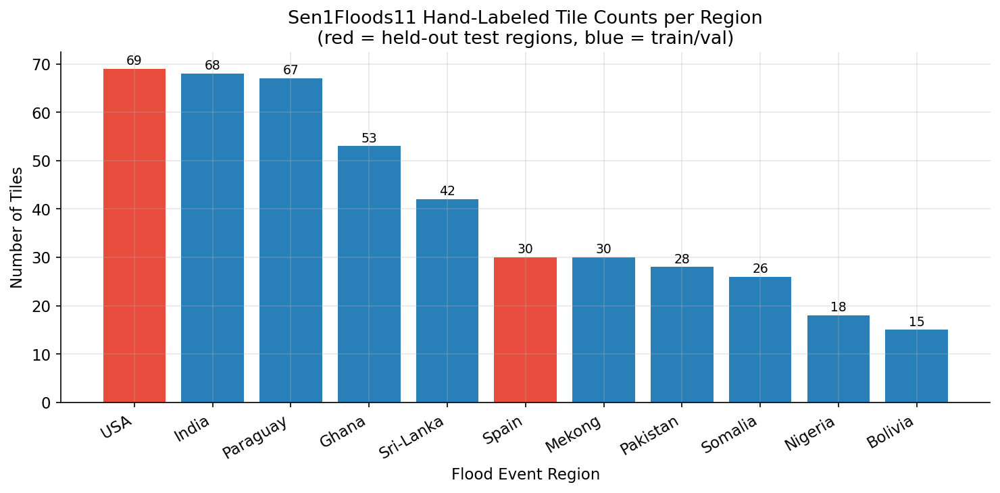

Figure saved.


In [18]:
valid_stats = tile_stats[tile_stats['is_valid']].copy()

region_counts = (
    valid_stats.groupby('region')
    .size()
    .reset_index(name='tile_count')
    .sort_values('tile_count', ascending=False)
)

print('Tile counts per region:')
print(region_counts.to_string(index=False))
print(f'\nTotal valid tiles: {region_counts["tile_count"].sum()}')

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

colours = [
    '#e74c3c' if r in TEST_REGIONS else '#2980b9'
    for r in region_counts['region']
]

bars = ax.bar(region_counts['region'], region_counts['tile_count'], color=colours)

# Annotate bar heights
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        str(int(bar.get_height())),
        ha='center', va='bottom', fontsize=9
    )

ax.set_xlabel('Flood Event Region')
ax.set_ylabel('Number of Tiles')
ax.set_title(
    'Sen1Floods11 Hand-Labeled Tile Counts per Region\n'
    '(red = held-out test regions, blue = train/val)'
)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()

save_figure(fig, 'tile_counts_per_region', subdir='eda')
plt.show()
print('Figure saved.')

---
### 2.3 — Class Imbalance Analysis

Flood pixels are a minority class. Understanding the severity of imbalance
per region justifies the use of weighted random sampling and combined BCE+Dice loss.

Overall pixel distribution (across all valid tiles):
  Water pixels:      10,705,605  (10.60% of labeled pixels)
  No-water pixels:   90,277,709  (89.40% of labeled pixels)
  No-data pixels:    15,932,910
  Class ratio (no-water:water): 8.4:1


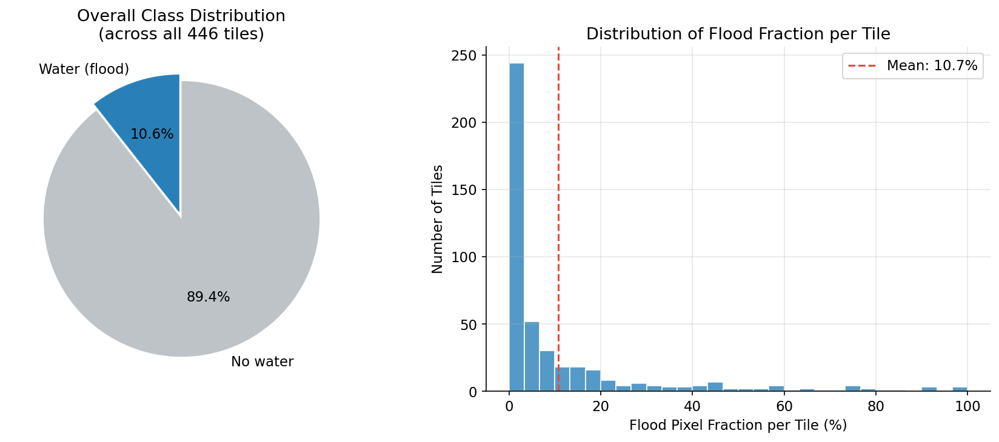

Figure saved.


In [19]:
# ── Overall pixel distribution ─────────────────────────────────────────────────
total_water    = valid_stats['n_water'].sum()
total_no_water = valid_stats['n_no_water'].sum()
total_nodata   = valid_stats['n_nodata'].sum()
total_valid_px = total_water + total_no_water

print('Overall pixel distribution (across all valid tiles):')
print(f'  Water pixels:    {total_water:>12,}  ({100*total_water/total_valid_px:.2f}% of labeled pixels)')
print(f'  No-water pixels: {total_no_water:>12,}  ({100*total_no_water/total_valid_px:.2f}% of labeled pixels)')
print(f'  No-data pixels:  {total_nodata:>12,}')
print(f'  Class ratio (no-water:water): {total_no_water/max(total_water,1):.1f}:1')

# ── Pie chart: overall balance ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: overall pixel breakdown
axes[0].pie(
    [total_water, total_no_water],
    labels=['Water (flood)', 'No water'],
    colors=['#2980b9', '#bdc3c7'],
    autopct='%1.1f%%',
    startangle=90,
    explode=(0.05, 0)
)
axes[0].set_title('Overall Class Distribution\n(across all 446 tiles)')

# Right: flood fraction per tile (histogram)
axes[1].hist(
    valid_stats['flood_fraction'] * 100,
    bins=30, color='#2980b9', edgecolor='white', alpha=0.8
)
axes[1].axvline(
    valid_stats['flood_fraction'].mean() * 100,
    color='#e74c3c', linestyle='--', linewidth=1.5,
    label=f'Mean: {valid_stats["flood_fraction"].mean()*100:.1f}%'
)
axes[1].set_xlabel('Flood Pixel Fraction per Tile (%)')
axes[1].set_ylabel('Number of Tiles')
axes[1].set_title('Distribution of Flood Fraction per Tile')
axes[1].legend()

plt.tight_layout()
save_figure(fig, 'class_imbalance_overall', subdir='eda')
plt.show()
print('Figure saved.')

Flood pixel fraction per region (mean across tiles):
   region  mean_flood_frac  median_flood_frac  max_flood_frac  tile_count
   Mekong         0.235932           0.076120        0.803654          30
  Nigeria         0.222666           0.023717        0.923059          18
  Bolivia         0.169921           0.062708        0.658679          15
    Spain         0.141360           0.034008        0.922146          30
    India         0.128346           0.059023        0.765115          68
Sri-Lanka         0.112357           0.029956        0.981400          42
 Paraguay         0.094326           0.021046        1.000000          67
 Pakistan         0.075754           0.012501        0.668281          28
    Ghana         0.064331           0.000021        0.901796          53
  Somalia         0.061724           0.022581        0.316731          26
      USA         0.045829           0.014538        0.425170          69


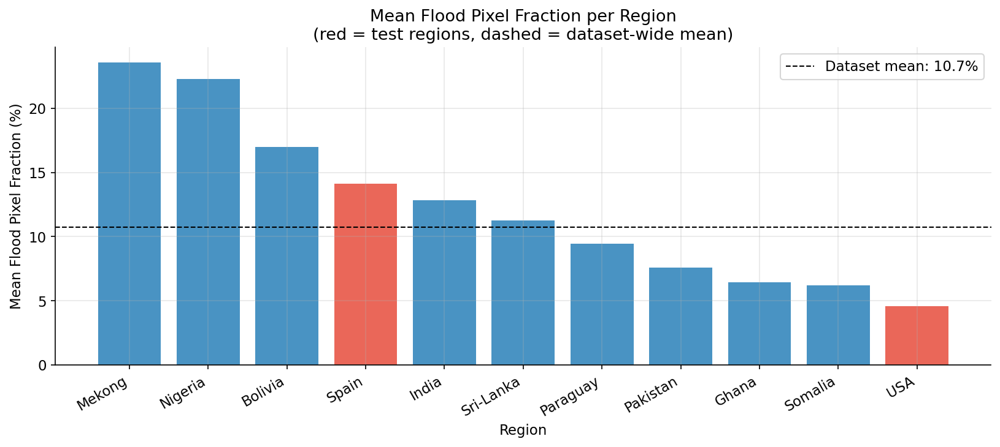

Figure saved.


In [20]:
# ── Flood fraction per region ──────────────────────────────────────────────────
region_flood = (
    valid_stats.groupby('region')
    .agg(
        mean_flood_frac=('flood_fraction', 'mean'),
        median_flood_frac=('flood_fraction', 'median'),
        max_flood_frac=('flood_fraction', 'max'),
        tile_count=('tile_id', 'count')
    )
    .reset_index()
    .sort_values('mean_flood_frac', ascending=False)
)

print('Flood pixel fraction per region (mean across tiles):')
print(region_flood.to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))

colours = [
    '#e74c3c' if r in TEST_REGIONS else '#2980b9'
    for r in region_flood['region']
]

ax.bar(
    region_flood['region'],
    region_flood['mean_flood_frac'] * 100,
    color=colours,
    alpha=0.85
)
ax.errorbar(
    region_flood['region'],
    region_flood['mean_flood_frac'] * 100,
    yerr=None,  # could add std if desired
    fmt='none'
)
ax.axhline(
    valid_stats['flood_fraction'].mean() * 100,
    color='black', linestyle='--', linewidth=1,
    label=f'Dataset mean: {valid_stats["flood_fraction"].mean()*100:.1f}%'
)
ax.set_xlabel('Region')
ax.set_ylabel('Mean Flood Pixel Fraction (%)')
ax.set_title(
    'Mean Flood Pixel Fraction per Region\n'
    '(red = test regions, dashed = dataset-wide mean)'
)
ax.legend()
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
save_figure(fig, 'flood_pixel_fraction_per_region', subdir='eda')
plt.show()
print('Figure saved.')

---
### 2.4 — No-Data Fraction Analysis

Tiles with very high no-data fractions (cloud cover, sensor gaps) provide
little usable signal. Tiles with >80% no-data will be flagged and potentially
excluded from training in Section 3.

Tiles with >80% no-data pixels: 16
  region tile_id  nodata_fraction
   Ghana  134751         0.835907
   Ghana  135389         0.906067
   Ghana  144050         0.910160
   Ghana  154838         0.839375
   Ghana  161233         0.992783
   Ghana  168875         0.840561
   Ghana  194723         0.819153
   Ghana  234935         1.000000
   Ghana  247288         0.846748
   Ghana   26376         1.000000
   Ghana     277         1.000000
   Ghana   45911         0.888348
   Ghana    5079         1.000000
   Ghana   83483         1.000000
   Ghana   97059         0.895500
Paraguay   34417         0.809166


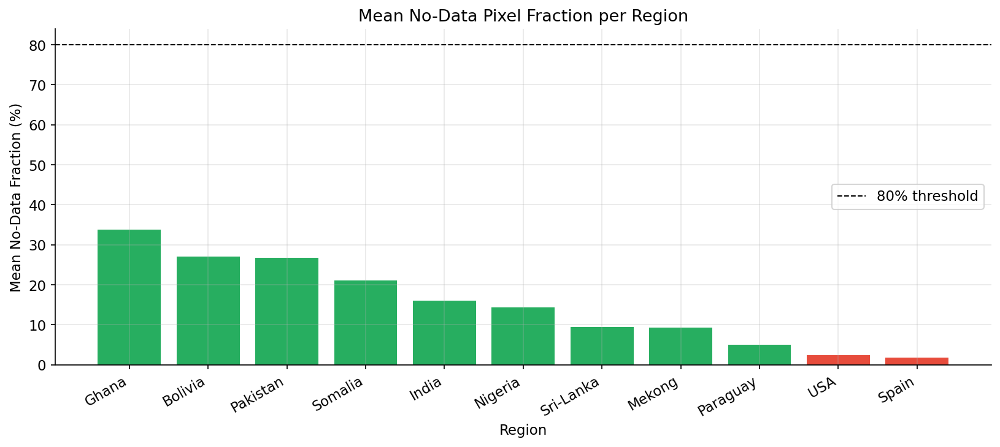

Figure saved.


In [21]:
NODATA_THRESHOLD = 0.80
# Tiles where more than 80% of pixels are no-data are flagged as low-quality.
# They contain too little labeled signal to be useful for training.

high_nodata = valid_stats[valid_stats['nodata_fraction'] > NODATA_THRESHOLD]
print(f'Tiles with >{NODATA_THRESHOLD*100:.0f}% no-data pixels: {len(high_nodata)}')
if len(high_nodata) > 0:
    print(high_nodata[['region', 'tile_id', 'nodata_fraction']].to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
region_nodata = (
    valid_stats.groupby('region')['nodata_fraction']
    .mean()
    .reset_index()
    .sort_values('nodata_fraction', ascending=False)
)
colours = [
    '#e74c3c' if r in TEST_REGIONS else '#27ae60'
    for r in region_nodata['region']
]
ax.bar(region_nodata['region'], region_nodata['nodata_fraction'] * 100, color=colours)
ax.axhline(NODATA_THRESHOLD * 100, color='black', linestyle='--',
           linewidth=1, label=f'{NODATA_THRESHOLD*100:.0f}% threshold')
ax.set_xlabel('Region')
ax.set_ylabel('Mean No-Data Fraction (%)')
ax.set_title('Mean No-Data Pixel Fraction per Region')
ax.legend()
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
save_figure(fig, 'nodata_fraction_per_region', subdir='eda')
plt.show()
print('Figure saved.')

---
### 2.5 — SAR Backscatter Distribution

SAR backscatter values are in linear scale (or dB depending on the dataset).
Understanding the distribution informs the normalisation strategy in Section 3.
We plot VV and VH distributions separately for water vs no-water pixels to
confirm the expected spectral separability between classes.

In [22]:
def sample_sar_pixels_by_class(
    s1_dir:     Path,
    label_dir:  Path,
    n_tiles:    int = 30,
    n_pixels:   int = 5000
) -> Dict[str, np.ndarray]:
    """
    Sample SAR backscatter values stratified by flood/no-water class.

    Problem solved:
        Plotting backscatter distributions across all 446 tiles x 512x512 pixels
        would require ~1.2 billion values — too slow and memory-intensive for EDA.
        Instead we sample a representative subset from a random set of tiles,
        stratified by class, to efficiently characterise the distributions.

    Args:
        s1_dir:    SAR tiles directory.
        label_dir: Label tiles directory.
        n_tiles:   Number of tiles to sample from (default 30).
        n_pixels:  Pixels to sample per class per tile (default 5000).

    Returns:
        Dict with keys 'vv_water', 'vv_no_water', 'vh_water', 'vh_no_water'.
    """
    np.random.seed(SEED)
    s1_files  = sorted(s1_dir.glob('*.tif'))
    sampled   = np.random.choice(s1_files, min(n_tiles, len(s1_files)), replace=False)

    vv_water, vv_no_water = [], []
    vh_water, vh_no_water = [], []

    for s1_path in tqdm(sampled, desc='Sampling backscatter'):
        region  = extract_region_from_filename(Path(s1_path))
        tile_id = extract_tile_id(Path(s1_path))
        label_candidates = list(label_dir.glob(f'{region}_{tile_id}_*.tif'))
        if not label_candidates:
            continue

        try:
            with rasterio.open(s1_path) as src:
                sar = src.read().astype(np.float32)  # (2, H, W)
            with rasterio.open(label_candidates[0]) as src:
                lbl = src.read(1).astype(np.int16)   # (H, W)

            # Flatten and remove non-finite SAR values
            vv = sar[0].ravel()
            vh = sar[1].ravel() if sar.shape[0] > 1 else None
            lb = lbl.ravel()

            finite_mask = np.isfinite(vv)
            if vh is not None:
                finite_mask &= np.isfinite(vh)

            water_idx    = np.where((lb == LABEL_WATER)    & finite_mask)[0]
            no_water_idx = np.where((lb == LABEL_NO_WATER) & finite_mask)[0]

            for idx, vv_list, vh_list in [
                (water_idx,    vv_water,    vh_water),
                (no_water_idx, vv_no_water, vh_no_water)
            ]:
                if len(idx) > 0:
                    chosen = np.random.choice(idx, min(n_pixels, len(idx)), replace=False)
                    vv_list.append(vv[chosen])
                    if vh is not None:
                        vh_list.append(vh[chosen])

        except Exception as e:
            LOGGER.warning(f'Backscatter sampling error {Path(s1_path).name}: {e}')

    return {
        'vv_water':    np.concatenate(vv_water)    if vv_water    else np.array([]),
        'vv_no_water': np.concatenate(vv_no_water) if vv_no_water else np.array([]),
        'vh_water':    np.concatenate(vh_water)    if vh_water    else np.array([]),
        'vh_no_water': np.concatenate(vh_no_water) if vh_no_water else np.array([]),
    }

In [23]:
# Skip-if-done
backscatter_samples = load_checkpoint('eda_backscatter_samples')
if backscatter_samples is None:
    print('Sampling backscatter values (runs once, ~2 minutes)...')
    backscatter_samples = sample_sar_pixels_by_class(S1_DIR, LABEL_DIR, n_tiles=50)
    save_checkpoint(backscatter_samples, 'eda_backscatter_samples')
else:
    print('Loaded backscatter samples from checkpoint.')

for k, v in backscatter_samples.items():
    print(f'  {k}: {len(v):,} pixels')

INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\eda_backscatter_samples.pkl


Loaded backscatter samples from checkpoint.
  vv_water: 178,918 pixels
  vv_no_water: 246,768 pixels
  vh_water: 178,918 pixels
  vh_no_water: 246,768 pixels


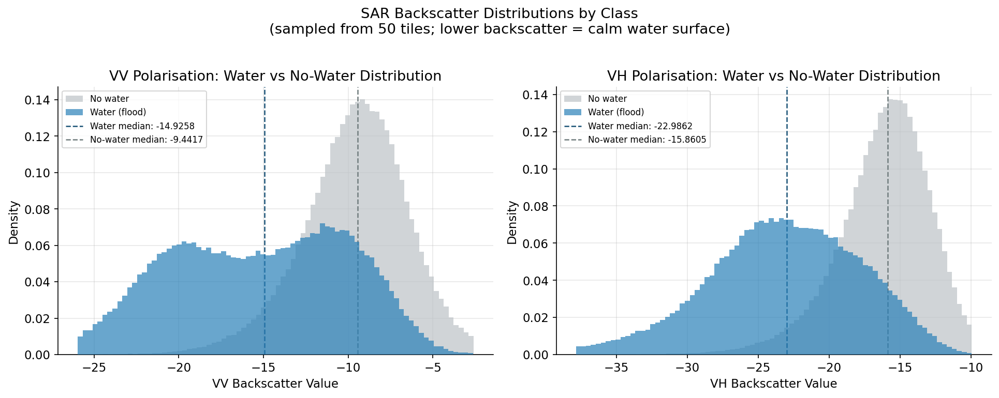

Figure saved.

Interpretation note:
  Water pixels should cluster at lower backscatter values.
  Significant overlap between classes is expected and motivates
  spatial context models (U-Net, SegFormer) over pixel-wise classifiers.


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

CLIP_PCT = 1  # clip top/bottom 1% to remove extreme outliers for plotting

for ax, channel, w_key, nw_key in [
    (axes[0], 'VV', 'vv_water', 'vv_no_water'),
    (axes[1], 'VH', 'vh_water', 'vh_no_water'),
]:
    w  = backscatter_samples[w_key]
    nw = backscatter_samples[nw_key]

    if len(w) == 0 or len(nw) == 0:
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes, ha='center')
        continue

    # Clip for clean plotting
    lo = np.percentile(np.concatenate([w, nw]), CLIP_PCT)
    hi = np.percentile(np.concatenate([w, nw]), 100 - CLIP_PCT)
    w_clipped  = w[(w  >= lo) & (w  <= hi)]
    nw_clipped = nw[(nw >= lo) & (nw <= hi)]

    ax.hist(nw_clipped, bins=80, density=True,
            color='#bdc3c7', alpha=0.7, label='No water', zorder=2)
    ax.hist(w_clipped,  bins=80, density=True,
            color='#2980b9', alpha=0.7, label='Water (flood)', zorder=3)

    ax.axvline(np.median(w_clipped),  color='#1a5276', linestyle='--',
               linewidth=1.2, label=f'Water median: {np.median(w_clipped):.4f}')
    ax.axvline(np.median(nw_clipped), color='#717d7e', linestyle='--',
               linewidth=1.2, label=f'No-water median: {np.median(nw_clipped):.4f}')

    ax.set_xlabel(f'{channel} Backscatter Value')
    ax.set_ylabel('Density')
    ax.set_title(f'{channel} Polarisation: Water vs No-Water Distribution')
    ax.legend(fontsize=8)

plt.suptitle(
    'SAR Backscatter Distributions by Class\n'
    '(sampled from 50 tiles; lower backscatter = calm water surface)',
    y=1.02
)
plt.tight_layout()
save_figure(fig, 'sar_backscatter_distribution', subdir='eda')
plt.show()
print('Figure saved.')
print()
print('Interpretation note:')
print('  Water pixels should cluster at lower backscatter values.')
print('  Significant overlap between classes is expected and motivates')
print('  spatial context models (U-Net, SegFormer) over pixel-wise classifiers.')

---
### 2.6 — Visual Sample Grid

Inspect representative tile triplets: SAR VV, SAR VH, and flood mask.
Visual inspection confirms the SAR-to-label alignment and reveals
the appearance of different flood types (riverine, coastal, urban).

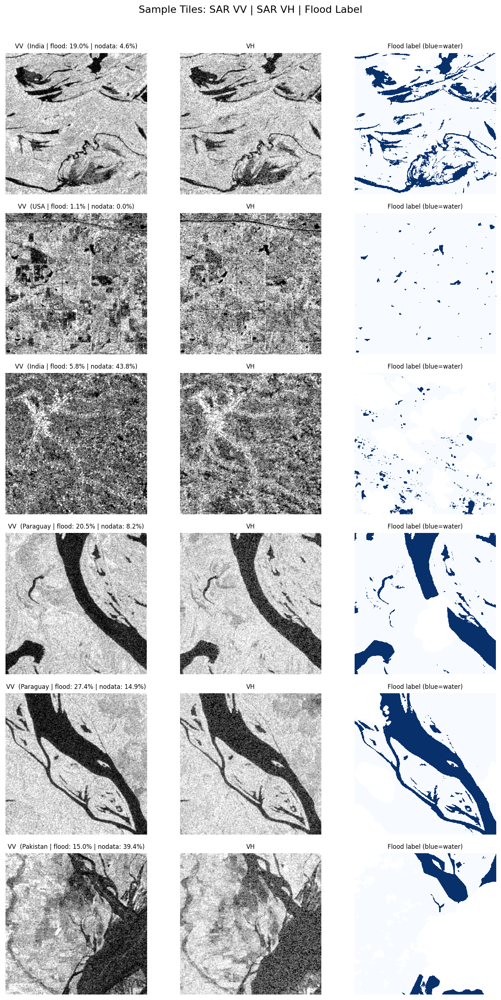

Figure saved.


In [25]:
def plot_sample_tiles(
    tile_stats_df: pd.DataFrame,
    n_samples:     int = 6,
    seed:          int = SEED
) -> None:
    """
    Display a grid of sample tiles showing VV, VH, and flood label.

    Problem solved:
        Visual inspection before training catches misaligned labels,
        corrupted tiles, and gives intuition about what the models will
        actually be learning from.

    Args:
        tile_stats_df: DataFrame from scan_all_tiles().
        n_samples:     Number of tiles to display.
        seed:          Random seed for reproducible tile selection.
    """
    # Sample from valid tiles that have at least some flood pixels
    candidates = tile_stats_df[
        tile_stats_df['is_valid'] & (tile_stats_df['flood_fraction'] > 0.01)
    ]
    np.random.seed(seed)
    samples = candidates.sample(min(n_samples, len(candidates)), random_state=seed)

    fig, axes = plt.subplots(n_samples, 3, figsize=(10, n_samples * 3))
    if n_samples == 1:
        axes = axes[np.newaxis, :]

    for row_idx, (_, row) in enumerate(samples.iterrows()):
        try:
            with rasterio.open(row['s1_path']) as src:
                sar = src.read().astype(np.float32)  # (2, H, W)
            with rasterio.open(row['label_path']) as src:
                lbl = src.read(1).astype(np.int16)
        except Exception as e:
            LOGGER.warning(f'Could not read tile for visualisation: {e}')
            continue

        def normalise_for_display(arr: np.ndarray) -> np.ndarray:
            """Clip and normalise a SAR band to [0,1] for display."""
            finite = arr[np.isfinite(arr)]
            lo, hi = np.percentile(finite, 2), np.percentile(finite, 98)
            return np.clip((arr - lo) / (hi - lo + 1e-8), 0, 1)

        vv_disp  = normalise_for_display(sar[0])
        vh_disp  = normalise_for_display(sar[1]) if sar.shape[0] > 1 else np.zeros_like(sar[0])
        lbl_disp = np.where(lbl == LABEL_NODATA, np.nan, lbl.astype(float))

        label_str = (
            f"{row['region']} | "
            f"flood: {row['flood_fraction']*100:.1f}% | "
            f"nodata: {row['nodata_fraction']*100:.1f}%"
        )

        axes[row_idx, 0].imshow(vv_disp,  cmap=SAR_CMAP, vmin=0, vmax=1)
        axes[row_idx, 0].set_title(f'VV  ({label_str})', fontsize=8)
        axes[row_idx, 0].axis('off')

        axes[row_idx, 1].imshow(vh_disp,  cmap=SAR_CMAP, vmin=0, vmax=1)
        axes[row_idx, 1].set_title('VH', fontsize=8)
        axes[row_idx, 1].axis('off')

        im = axes[row_idx, 2].imshow(
            lbl_disp, cmap=FLOOD_CMAP, vmin=0, vmax=1, interpolation='nearest'
        )
        axes[row_idx, 2].set_title('Flood label (blue=water)', fontsize=8)
        axes[row_idx, 2].axis('off')

    plt.suptitle('Sample Tiles: SAR VV | SAR VH | Flood Label', y=1.01)
    plt.tight_layout()
    save_figure(fig, 'sample_tiles_grid', subdir='eda')
    plt.show()
    print('Figure saved.')


plot_sample_tiles(valid_stats, n_samples=6)

---
### 2.7 — Test Region Decision

Confirm Spain and USA as the held-out test regions based on the EDA findings.
Document the reasoning explicitly — this decision is reported in the dissertation.

In [26]:
print('=== TEST REGION DECISION ===')
print()

for region in TEST_REGIONS:
    region_data = valid_stats[valid_stats['region'] == region]
    print(f'Region: {region}')
    print(f'  Tile count:          {len(region_data)}')
    print(f'  Mean flood fraction: {region_data["flood_fraction"].mean()*100:.2f}%')
    print(f'  Mean nodata frac:    {region_data["nodata_fraction"].mean()*100:.2f}%')
    print()

train_val_tiles = valid_stats[~valid_stats['region'].isin(TEST_REGIONS)]
n_val = int(len(train_val_tiles) * VAL_FRACTION)
n_train = len(train_val_tiles) - n_val

print('Projected split (after removing test regions):')
print(f'  Train+Val pool:  {len(train_val_tiles)} tiles')
print(f'  Validation:      ~{n_val} tiles ({VAL_FRACTION*100:.0f}%)')
print(f'  Training:        ~{n_train} tiles')
print(f'  Training patches (x4):   ~{n_train * 4}')
print(f'  With augmentation (x6-8): ~{n_train * 4 * 7:,} effective patches/epoch')
print()
print(f'Test tiles held out:')
for region in TEST_REGIONS:
    n = len(valid_stats[valid_stats['region'] == region])
    print(f'  {region}: {n} tiles — evaluated at full 512x512 with sliding window')

=== TEST REGION DECISION ===

Region: Spain
  Tile count:          30
  Mean flood fraction: 14.14%
  Mean nodata frac:    1.74%

Region: USA
  Tile count:          69
  Mean flood fraction: 4.58%
  Mean nodata frac:    2.44%

Projected split (after removing test regions):
  Train+Val pool:  347 tiles
  Validation:      ~52 tiles (15%)
  Training:        ~295 tiles
  Training patches (x4):   ~1180
  With augmentation (x6-8): ~8,260 effective patches/epoch

Test tiles held out:
  Spain: 30 tiles — evaluated at full 512x512 with sliding window
  USA: 69 tiles — evaluated at full 512x512 with sliding window


---
### 2.8 — EDA Summary

Consolidate findings into a single summary table for the dissertation.

In [27]:
summary = valid_stats.groupby('region').agg(
    tiles=('tile_id', 'count'),
    mean_flood_pct=('flood_fraction', lambda x: round(x.mean() * 100, 2)),
    median_flood_pct=('flood_fraction', lambda x: round(x.median() * 100, 2)),
    mean_nodata_pct=('nodata_fraction', lambda x: round(x.mean() * 100, 2)),
).reset_index()

summary['split'] = summary['region'].apply(
    lambda r: 'TEST (held out)' if r in TEST_REGIONS else 'Train/Val'
)

summary = summary.sort_values(['split', 'tiles'], ascending=[True, False])

print('EDA SUMMARY TABLE')
print('=' * 75)
print(summary.to_string(index=False))
print('=' * 75)
print()
print(f'Total valid tiles: {len(valid_stats)}')
print(f'Overall class imbalance: {total_no_water/max(total_water,1):.1f}:1 (no-water:water)')
print()
print('Key findings for dissertation:')
print(f'  1. Class imbalance is severe: flood pixels are '
      f'{100*total_water/total_valid_px:.1f}% of all labeled pixels.')
print(f'     This justifies: weighted random sampling + BCE+Dice combined loss.')
print(f'  2. Spain and USA are climatically distinct from tropical/monsoon regions,')
print(f'     making them appropriate held-out test regions for generalisation assessment.')
print(f'  3. SAR backscatter distributions show meaningful but overlapping class')
print(f'     separation, motivating spatial context models over pixel-wise classifiers.')

# Save summary for use in the dissertation
save_metrics(summary.to_dict(orient='records'), 'eda_region_summary')
print('\nEDA summary saved to metrics/eda_region_summary.json')

INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\eda_region_summary.json


EDA SUMMARY TABLE
   region  tiles  mean_flood_pct  median_flood_pct  mean_nodata_pct           split
      USA     69            4.58              1.45             2.44 TEST (held out)
    Spain     30           14.14              3.40             1.74 TEST (held out)
    India     68           12.83              5.90            15.97       Train/Val
 Paraguay     67            9.43              2.10             5.04       Train/Val
    Ghana     53            6.43              0.00            33.83       Train/Val
Sri-Lanka     42           11.24              3.00             9.51       Train/Val
   Mekong     30           23.59              7.61             9.32       Train/Val
 Pakistan     28            7.58              1.25            26.75       Train/Val
  Somalia     26            6.17              2.26            21.13       Train/Val
  Nigeria     18           22.27              2.37            14.31       Train/Val
  Bolivia     15           16.99              6.27        

# Section 3: Preprocessing

**Purpose:** Transform raw Sen1Floods11 tiles into clean, normalised, augmentation-ready
training patches. Every step here is checkpointed so it runs once.

**Pipeline:**
```
Raw SAR tiles (512x512, 2-band)  
        ↓
1. Speckle filtering (Lee filter, 7x7 window)
        ↓
2. Global normalisation (per-channel, computed on training split only)
        ↓
3. Train / Val / Test split (event-level, Spain + USA held out)
        ↓
4. Patch extraction (4 non-overlapping 256x256 patches per tile)
        ↓
5. Augmentation pipeline (defined here, applied on-the-fly in Section 4)
```

**Outputs produced:**
- `checkpoints/split_metadata.pkl` — train/val/test file path lists
- `checkpoints/normalisation_stats.pkl` — per-channel mean/std from training split
- `checkpoints/train_patches.pkl` — extracted patch coordinate pairs
- `figures/eda/normalisation_check.png` — verifies normalisation correctness



---
### 3.1 — Train / Val / Test Split

Splits are done at **event (region) level**, not at tile level.

**Why event-level and not tile-level?**
Adjacent tiles from the same flood event share geography and backscatter
statistics. If tiles from the same event appear in both training and test sets,
the model can achieve high test scores by memorising scene-specific features
rather than learning generalisable flood signatures. Event-level splits
force the model to perform on entirely unseen flood scenarios.



In [28]:
def create_event_level_split(
    tile_stats_df:   object,
    test_regions:    List[str],
    val_fraction:    float,
    seed:            int
) -> Dict[str, List[Dict]]:
    """
    Create train/val/test splits at event (region) level.

    Problem solved:
        Tile-level random splits leak spatial information between train and test
        because adjacent tiles from the same flood event are highly correlated.
        Event-level splitting ensures the test set contains flood events the
        model has never seen in any form during training.

    Strategy:
        - Test: all tiles from TEST_REGIONS (Spain, USA) — held out entirely.
        - Val: VAL_FRACTION of remaining tiles, stratified by region so no
          single region dominates the validation set.
        - Train: all remaining tiles.

    Args:
        tile_stats_df: DataFrame from Section 2 scan_all_tiles().
        test_regions:  List of region names to hold out entirely.
        val_fraction:  Fraction of non-test tiles for validation.
        seed:          Random seed for reproducible stratified sampling.

    Returns:
        Dict with keys 'train', 'val', 'test'.
        Each value is a list of dicts with keys 's1_path', 'label_path', 'region'.
    """
    import pandas as pd
    np.random.seed(seed)

    valid = tile_stats_df[tile_stats_df['is_valid']].copy()

    # ── Test split: hold out test regions entirely ─────────────────────────────
    test_df = valid[valid['region'].isin(test_regions)]

    # ── Train/Val pool: remaining regions ─────────────────────────────────────
    pool_df = valid[~valid['region'].isin(test_regions)].copy()

    # Stratified val sampling: sample val_fraction from each region independently
    # so all 9 training regions are represented in validation.
    val_rows  = []
    train_rows = []

    for region, group in pool_df.groupby('region'):
        n_val = max(1, int(len(group) * val_fraction))
        val_idx = group.sample(n=n_val, random_state=seed).index
        val_rows.append(group.loc[val_idx])
        train_rows.append(group.drop(val_idx))

    val_df   = pd.concat(val_rows)
    train_df = pd.concat(train_rows)

    def df_to_records(df):
        return [
            {
                's1_path':    row['s1_path'],
                'label_path': row['label_path'],
                'region':     row['region'],
                'tile_id':    row['tile_id'],
                'flood_fraction': row['flood_fraction'],
            }
            for _, row in df.iterrows()
        ]

    splits = {
        'train': df_to_records(train_df),
        'val':   df_to_records(val_df),
        'test':  df_to_records(test_df),
    }

    return splits

In [29]:
# Load tile stats from Section 2 checkpoint
tile_stats = load_checkpoint('eda_tile_stats')
if tile_stats is None:
    raise RuntimeError('Run Section 2 first to generate eda_tile_stats checkpoint.')

# Skip-if-done
split_metadata = load_checkpoint('split_metadata')

if split_metadata is None:
    print('Creating event-level splits...')
    split_metadata = create_event_level_split(
        tile_stats_df=tile_stats,
        test_regions=TEST_REGIONS,
        val_fraction=VAL_FRACTION,
        seed=SEED
    )
    save_checkpoint(split_metadata, 'split_metadata')
    print('Split metadata saved.')
else:
    print('Loaded split metadata from checkpoint.')

print(f'\nSplit summary:')
for split_name, records in split_metadata.items():
    regions = sorted(set(r['region'] for r in records))
    print(f'  {split_name:<6}: {len(records):>4} tiles | regions: {regions}')

n_train = len(split_metadata['train'])
print(f'\nProjected training patches (before augmentation):')
print(f'  {n_train} tiles x 4 patches = {n_train * 4} patches')
print(f'  With augmentation (approx x7 per epoch): ~{n_train * 4 * 7:,} effective samples')

INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\eda_tile_stats.pkl
INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\split_metadata.pkl


Loaded split metadata from checkpoint.

Split summary:
  train :  299 tiles | regions: ['Bolivia', 'Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Sri-Lanka']
  val   :   48 tiles | regions: ['Bolivia', 'Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Sri-Lanka']
  test  :   99 tiles | regions: ['Spain', 'USA']

Projected training patches (before augmentation):
  299 tiles x 4 patches = 1196 patches
  With augmentation (approx x7 per epoch): ~8,372 effective samples


---
### 3.2 — Speckle Filtering

SAR images contain multiplicative speckle noise — a granular salt-and-pepper
texture that is an inherent property of coherent radar imaging, not thermal noise.
Speckle causes isolated pixels to have very different values from their neighbours
even in uniform areas, which degrades segmentation quality.

**Why Lee filter?**
The Lee filter (Lee, 1980) is the standard choice for SAR speckle reduction.
It adapts to local statistics: in homogeneous areas (like open water) it averages
aggressively; near edges it preserves sharpness. This is critical for flood
detection where water-land boundaries must be preserved.

**Why 7×7 window?**
Smaller windows (3×3) leave too much speckle. Larger windows (11×11+) blur
flood boundaries excessively. 7×7 is the standard window size in SAR flood
detection literature (e.g. Twele et al., 2016; Chini et al., 2019).



In [30]:
def lee_filter(band: np.ndarray, window_size: int = 7) -> np.ndarray:
    """
    Apply a Lee speckle filter to a single SAR band.

    Problem solved:
        SAR backscatter contains multiplicative speckle noise that causes
        individual pixels to deviate from their true value. The Lee filter
        reduces speckle while preserving edges by weighting the local mean
        against the centre pixel value based on local variance.

    Mathematical basis:
        filtered = mean + k * (centre - mean)
        where k = var_signal / (var_signal + var_noise)
        and var_signal = max(0, (local_var - var_noise) / local_var)

    Args:
        band:        2D float32 array representing one SAR polarisation band.
        window_size: Kernel size for local statistics computation.
                     Must be odd. Default 7 per SAR flood detection convention.

    Returns:
        Speckle-filtered band as float32 array, same shape as input.
    """
    from scipy.ndimage import uniform_filter, uniform_filter1d

    # Replace non-finite values with local mean before filtering
    band_clean = np.where(np.isfinite(band), band, 0.0).astype(np.float32)

    # Local mean and mean of squares
    local_mean   = uniform_filter(band_clean, size=window_size)
    local_sq_mean = uniform_filter(band_clean ** 2, size=window_size)

    # Local variance
    local_var = local_sq_mean - local_mean ** 2
    local_var = np.maximum(local_var, 0.0)  # numerical stability

    # Noise variance: estimated as mean of local variances
    # (assumes stationary noise across the image)
    noise_var = np.mean(local_var)

    # Lee weighting coefficient
    with np.errstate(divide='ignore', invalid='ignore'):
        k = np.where(
            local_var > 0,
            (local_var - noise_var) / local_var,
            0.0
        )
    k = np.clip(k, 0.0, 1.0)

    filtered = local_mean + k * (band_clean - local_mean)

    # Restore original non-finite positions
    filtered = np.where(np.isfinite(band), filtered, band)
    return filtered.astype(np.float32)


SPECKLE_WINDOW = 7  # Lee filter window size — odd integer

print('Lee speckle filter defined.')
print(f'Window size: {SPECKLE_WINDOW}x{SPECKLE_WINDOW}')

Lee speckle filter defined.
Window size: 7x7


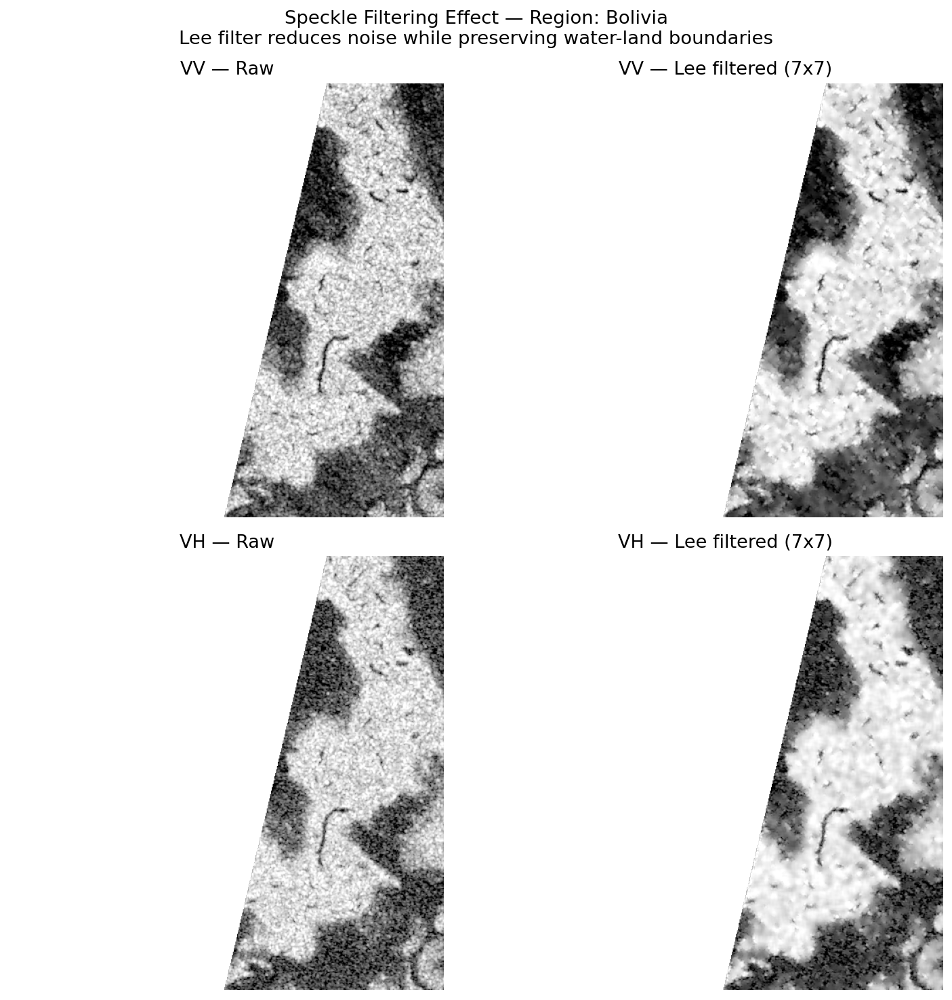

Speckle filter comparison saved.


In [31]:
# Quick visual check: compare raw vs filtered SAR on one tile
sample_record = split_metadata['train'][0]

with rasterio.open(sample_record['s1_path']) as src:
    raw_sar = src.read().astype(np.float32)  # (2, 512, 512)

filtered_vv = lee_filter(raw_sar[0], window_size=SPECKLE_WINDOW)
filtered_vh = lee_filter(raw_sar[1], window_size=SPECKLE_WINDOW)

def clip_display(arr):
    finite = arr[np.isfinite(arr)]
    lo, hi = np.percentile(finite, 2), np.percentile(finite, 98)
    return np.clip((arr - lo) / (hi - lo + 1e-8), 0, 1)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes[0, 0].imshow(clip_display(raw_sar[0]),  cmap=SAR_CMAP)
axes[0, 0].set_title('VV — Raw')
axes[0, 1].imshow(clip_display(filtered_vv), cmap=SAR_CMAP)
axes[0, 1].set_title(f'VV — Lee filtered ({SPECKLE_WINDOW}x{SPECKLE_WINDOW})')
axes[1, 0].imshow(clip_display(raw_sar[1]),  cmap=SAR_CMAP)
axes[1, 0].set_title('VH — Raw')
axes[1, 1].imshow(clip_display(filtered_vh), cmap=SAR_CMAP)
axes[1, 1].set_title(f'VH — Lee filtered ({SPECKLE_WINDOW}x{SPECKLE_WINDOW})')

for ax in axes.ravel():
    ax.axis('off')

plt.suptitle(
    f'Speckle Filtering Effect — Region: {sample_record["region"]}\n'
    'Lee filter reduces noise while preserving water-land boundaries'
)
plt.tight_layout()
save_figure(fig, 'speckle_filter_comparison', subdir='eda')
plt.show()
print('Speckle filter comparison saved.')

---
### 3.3 — Normalisation Statistics

We normalise SAR backscatter to zero mean and unit standard deviation
(z-score normalisation) per channel.

**Why z-score and not min-max?**
SAR backscatter has outliers from urban areas (corner reflectors, metal structures)
that produce very high values. Min-max normalisation would compress the dynamic
range of the majority of pixels to accommodate these outliers. Z-score normalisation
is more robust to outliers and is standard practice for SAR deep learning.

**Critical: statistics computed on training split only.**
Using validation or test data to compute normalisation statistics is data leakage.
The training mean/std is applied to all three splits at inference time.

In [32]:
def compute_normalisation_stats(
    train_records: List[Dict],
    speckle_window: int = SPECKLE_WINDOW
) -> Dict[str, float]:
    """
    Compute per-channel mean and standard deviation across the training split.

    Problem solved:
        Models converge faster and more reliably when input features are
        standardised. Statistics must be computed only on training data to
        avoid any information from val/test leaking into the model pipeline.

    Method:
        Welford's online algorithm for numerically stable single-pass
        mean and variance computation across all training tiles. This avoids
        loading all tiles into memory simultaneously.

    Args:
        train_records:  List of training tile dicts from split_metadata.
        speckle_window: Lee filter window size to apply before computing stats.

    Returns:
        Dict with keys 'vv_mean', 'vv_std', 'vh_mean', 'vh_std'.
    """
    # Welford online statistics per channel
    counts = [0, 0]
    means  = [0.0, 0.0]
    M2s    = [0.0, 0.0]  # sum of squared deviations from the current mean

    for record in tqdm(train_records, desc='Computing normalisation stats'):
        try:
            with rasterio.open(record['s1_path']) as src:
                sar = src.read().astype(np.float32)
        except Exception as e:
            LOGGER.warning(f'Could not read {record["s1_path"]}: {e}')
            continue

        for ch in range(min(2, sar.shape[0])):
            band     = lee_filter(sar[ch], window_size=speckle_window)
            finite   = band[np.isfinite(band)].ravel()

            for val in finite:
                counts[ch] += 1
                delta       = val - means[ch]
                means[ch]  += delta / counts[ch]
                delta2      = val - means[ch]
                M2s[ch]    += delta * delta2

    stats = {
        'vv_mean': float(means[0]),
        'vv_std':  float(np.sqrt(M2s[0] / max(counts[0] - 1, 1))),
        'vh_mean': float(means[1]),
        'vh_std':  float(np.sqrt(M2s[1] / max(counts[1] - 1, 1))),
        'n_pixels_vv': counts[0],
        'n_pixels_vh': counts[1],
    }
    return stats

In [33]:
# Skip-if-done
norm_stats = load_checkpoint('normalisation_stats')

if norm_stats is None:
    print('Computing normalisation statistics on training split (~5-10 minutes)...')
    norm_stats = compute_normalisation_stats(split_metadata['train'])
    save_checkpoint(norm_stats, 'normalisation_stats')
    print('Normalisation stats saved.')
else:
    print('Loaded normalisation stats from checkpoint.')

print(f'\nNormalisation statistics (training split only):')
print(f'  VV: mean = {norm_stats["vv_mean"]:.6f}, std = {norm_stats["vv_std"]:.6f}')
print(f'  VH: mean = {norm_stats["vh_mean"]:.6f}, std = {norm_stats["vh_std"]:.6f}')
print(f'  Computed over {norm_stats["n_pixels_vv"]:,} VV pixels '
      f'({len(split_metadata["train"])} training tiles)')
print()
print('These values are applied to ALL splits (train, val, test).')
print('Test data was never used to compute these values — no leakage.')

INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\normalisation_stats.pkl


Loaded normalisation stats from checkpoint.

Normalisation statistics (training split only):
  VV: mean = -10.803242, std = 3.268831
  VH: mean = -17.251871, std = 3.982606
  Computed over 76,303,228 VV pixels (299 training tiles)

These values are applied to ALL splits (train, val, test).
Test data was never used to compute these values — no leakage.


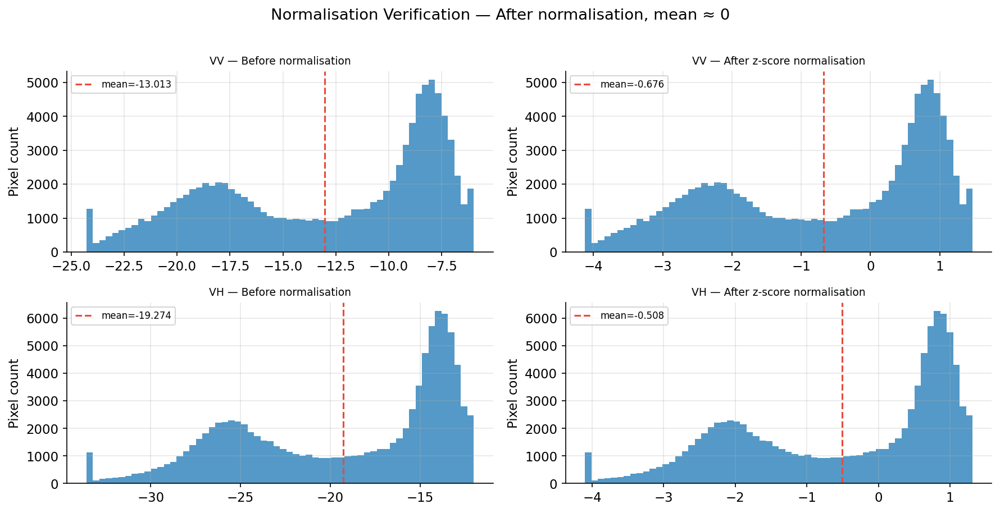

Normalisation check figure saved.


In [34]:
# ── Normalisation verification plot ───────────────────────────────────────────
# Load and normalise a tile then verify the distribution looks centred
sample_record = split_metadata['train'][0]

with rasterio.open(sample_record['s1_path']) as src:
    raw_sar = src.read().astype(np.float32)

filtered_vv = lee_filter(raw_sar[0])
filtered_vh = lee_filter(raw_sar[1])

norm_vv = (filtered_vv - norm_stats['vv_mean']) / (norm_stats['vv_std'] + 1e-8)
norm_vh = (filtered_vh - norm_stats['vh_mean']) / (norm_stats['vh_std'] + 1e-8)

fig, axes = plt.subplots(2, 2, figsize=(12, 6))

for ax, data, title in [
    (axes[0, 0], filtered_vv[np.isfinite(filtered_vv)], 'VV — Before normalisation'),
    (axes[0, 1], norm_vv[np.isfinite(norm_vv)],         'VV — After z-score normalisation'),
    (axes[1, 0], filtered_vh[np.isfinite(filtered_vh)], 'VH — Before normalisation'),
    (axes[1, 1], norm_vh[np.isfinite(norm_vh)],         'VH — After z-score normalisation'),
]:
    clipped = np.clip(data, np.percentile(data, 1), np.percentile(data, 99))
    ax.hist(clipped, bins=60, color='#2980b9', alpha=0.8, edgecolor='none')
    ax.axvline(np.mean(clipped), color='#e74c3c', linestyle='--',
               label=f'mean={np.mean(clipped):.3f}')
    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=8)
    ax.set_ylabel('Pixel count')

plt.suptitle('Normalisation Verification — After normalisation, mean ≈ 0', y=1.01)
plt.tight_layout()
save_figure(fig, 'normalisation_check', subdir='eda')
plt.show()
print('Normalisation check figure saved.')

---
### 3.4 — Patch Extraction

Each 512×512 tile is divided into four non-overlapping 256×256 patches.

```
┌─────────┬─────────┐
│  (0,0)  │ (0,256) │   patch_size = 256
│         │         │   4 patches per tile
├─────────┼─────────┤   512 ÷ 256 = 2 (exact — no remainder, no padding)
│ (256,0) │(256,256)│
│         │         │
└─────────┴─────────┘
```

We store **patch coordinates** (row_start, col_start) rather than the actual
pixel data. This is memory-efficient — the DataLoader in Section 4 reads and
processes each patch on-the-fly during training rather than pre-loading
all patches into RAM (~1,316 patches × 256×256×2 float32 = ~170 MB — manageable,
but storing coordinates is the scalable approach when adding weakly labeled data).

In [35]:
def extract_patch_coordinates(
    tile_records: List[Dict],
    patch_size:   int,
    tile_size:    int,
    filter_empty: bool = True,
    min_flood_px: int  = 10
) -> List[Dict]:
    """
    Generate patch coordinate records from a list of tile records.

    Problem solved:
        Rather than pre-extracting and storing all patches on disk (high disk I/O,
        large storage), we store lightweight coordinate records. The DataLoader
        reads the patch from disk on-the-fly using these coordinates.

    Patch filtering:
        Patches where the label has >95% no-data pixels are excluded from
        training. These patches contain almost no labeled signal and waste
        training compute without contributing useful gradient updates.

        Additionally, for training patches only, we optionally require at least
        min_flood_px labeled flood pixels to ensure every patch has some
        positive class signal. This is NOT applied to validation patches since
        we need representative validation including flood-free tiles.

    Args:
        tile_records:  List of dicts with 's1_path', 'label_path', 'region'.
        patch_size:    Size of each square patch (256).
        tile_size:     Size of the source tile (512).
        filter_empty:  If True, exclude patches with <min_flood_px flood pixels.
        min_flood_px:  Minimum flood pixels required in a patch.

    Returns:
        List of dicts, each representing one patch with keys:
        's1_path', 'label_path', 'region', 'row_start', 'col_start',
        'n_flood_px', 'n_valid_px'.
    """
    patches = []
    n_patches_per_tile = (tile_size // patch_size) ** 2
    row_starts = range(0, tile_size, patch_size)
    col_starts = range(0, tile_size, patch_size)

    for record in tqdm(tile_records, desc='Extracting patch coordinates'):
        try:
            with rasterio.open(record['label_path']) as src:
                lbl = src.read(1).astype(np.int16)
        except Exception as e:
            LOGGER.warning(f'Could not read label for {record["s1_path"]}: {e}')
            continue

        for rs in row_starts:
            for cs in col_starts:
                patch_lbl = lbl[rs:rs+patch_size, cs:cs+patch_size]

                n_flood  = int((patch_lbl == LABEL_WATER).sum())
                n_valid  = int((patch_lbl != LABEL_NODATA).sum())
                n_nodata = int((patch_lbl == LABEL_NODATA).sum())
                n_total  = patch_lbl.size

                # Exclude patches that are almost entirely no-data
                if n_nodata / n_total > 0.95:
                    continue

                # Optionally require minimum flood pixels in training patches
                # (not applied to val/test)
                if filter_empty and n_flood < min_flood_px:
                    # Keep 30% of flood-free patches to maintain class balance
                    # exposure — the model must still learn what non-flood looks like
                    if np.random.random() > 0.30:
                        continue

                patches.append({
                    's1_path':    record['s1_path'],
                    'label_path': record['label_path'],
                    'region':     record['region'],
                    'row_start':  rs,
                    'col_start':  cs,
                    'n_flood_px': n_flood,
                    'n_valid_px': n_valid,
                })

    return patches

In [36]:
# Skip-if-done
patch_coords = load_checkpoint('patch_coordinates')

if patch_coords is None:
    print('Extracting patch coordinates...')
    np.random.seed(SEED)

    train_patches = extract_patch_coordinates(
        split_metadata['train'], PATCH_SIZE, TILE_SIZE,
        filter_empty=True, min_flood_px=10
    )
    val_patches = extract_patch_coordinates(
        split_metadata['val'], PATCH_SIZE, TILE_SIZE,
        filter_empty=False  # keep all val patches for unbiased evaluation
    )
    # Test tiles are NOT patched — they are evaluated at full 512x512
    # using sliding window inference in the model sections.
    test_records = split_metadata['test']

    patch_coords = {
        'train': train_patches,
        'val':   val_patches,
        'test':  test_records,  # full tiles, not patches
    }
    save_checkpoint(patch_coords, 'patch_coordinates')
    print('Patch coordinates saved.')
else:
    print('Loaded patch coordinates from checkpoint.')

print(f'\nPatch summary:')
print(f'  Train patches: {len(patch_coords["train"]):,}')
print(f'  Val patches:   {len(patch_coords["val"]):,}')
print(f'  Test tiles:    {len(patch_coords["test"])} (full 512x512 — no patching)')

# Flood pixel coverage in training patches
import pandas as pd
train_df  = pd.DataFrame(patch_coords['train'])
n_flood_patches = (train_df['n_flood_px'] > 0).sum()
print(f'\n  Training patches with >0 flood pixels: '
      f'{n_flood_patches}/{len(train_df)} '
      f'({100*n_flood_patches/len(train_df):.1f}%)')

INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\patch_coordinates.pkl


Loaded patch coordinates from checkpoint.

Patch summary:
  Train patches: 913
  Val patches:   191
  Test tiles:    99 (full 512x512 — no patching)

  Training patches with >0 flood pixels: 823/913 (90.1%)


---
### 3.5 — Weighted Sampling Weights

Weighted random sampling oversamples patches with higher flood pixel density.
This partially corrects class imbalance at the batch level without modifying
the labels or duplicating data on disk.

**How it works:**
Each patch gets a sampling weight proportional to its flood pixel fraction.
The PyTorch `WeightedRandomSampler` uses these weights to construct each
training batch so flood-positive patches appear more frequently.

Patches with zero flood pixels receive a small minimum weight (not zero) so the
model still sees what non-flooded terrain looks like — essential for learning
the negative class reliably.

Sample weight distribution (training patches):
  Min weight: 0.1000
  Max weight: 1.0000
  Mean weight: 0.2035


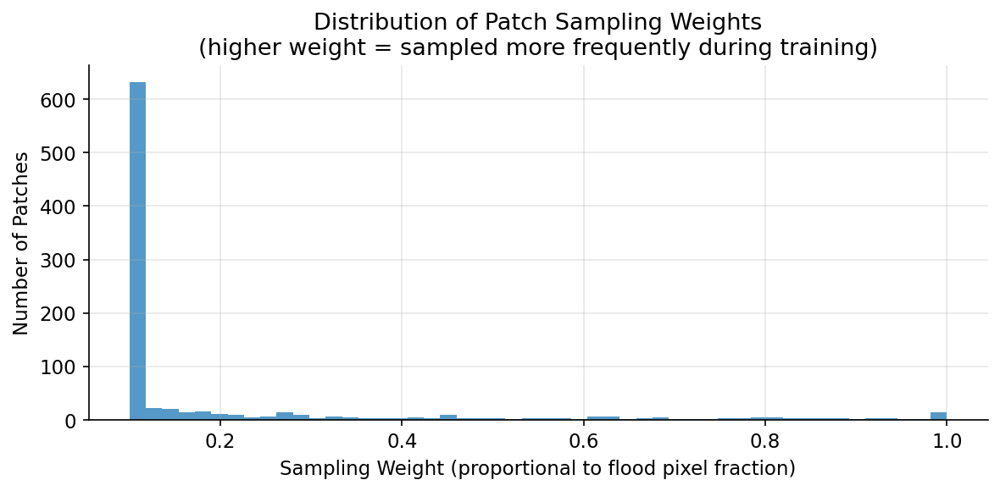

Figure saved.


In [37]:
def compute_sample_weights(
    patch_records: List[Dict],
    min_weight:    float = 0.1
) -> np.ndarray:
    """
    Compute per-patch sampling weights for WeightedRandomSampler.

    Problem solved:
        With naive random sampling, batches reflect the dataset imbalance —
        most batches will be dominated by no-water patches, and the model
        receives few gradient updates from flood pixels. Weighted sampling
        rebalances batches without altering the underlying data distribution.

    Weight formula:
        weight = max(flood_fraction, min_weight)
        where flood_fraction = n_flood_px / n_valid_px

    The min_weight floor ensures flood-free patches are still sampled
    occasionally so the model does not overfit to always predicting flood.

    Args:
        patch_records: List of patch dicts with 'n_flood_px' and 'n_valid_px'.
        min_weight:    Minimum weight for zero-flood patches.

    Returns:
        1D numpy array of float weights, one per patch.
    """
    weights = []
    for rec in patch_records:
        valid_px = max(rec['n_valid_px'], 1)
        flood_fraction = rec['n_flood_px'] / valid_px
        weights.append(max(flood_fraction, min_weight))
    return np.array(weights, dtype=np.float32)


train_sample_weights = compute_sample_weights(patch_coords['train'])

print('Sample weight distribution (training patches):')
print(f'  Min weight: {train_sample_weights.min():.4f}')
print(f'  Max weight: {train_sample_weights.max():.4f}')
print(f'  Mean weight: {train_sample_weights.mean():.4f}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train_sample_weights, bins=50, color='#2980b9', alpha=0.8, edgecolor='none')
ax.set_xlabel('Sampling Weight (proportional to flood pixel fraction)')
ax.set_ylabel('Number of Patches')
ax.set_title('Distribution of Patch Sampling Weights\n'
             '(higher weight = sampled more frequently during training)')
plt.tight_layout()
save_figure(fig, 'sample_weight_distribution', subdir='eda')
plt.show()
print('Figure saved.')

---
### 3.6 — Augmentation Pipeline Definition

Augmentations are defined here and passed to the Dataset class in Section 4.
They are applied **on-the-fly during training** — no augmented images are saved
to disk.

**Augmentations used (geometric only — safe for SAR):**

| Transform | Probability | Rationale |
|-----------|-------------|----------|
| Horizontal flip | 0.5 | Flood looks the same mirrored horizontally |
| Vertical flip | 0.5 | Flood looks the same mirrored vertically |
| Random 90° rotation | 0.5 | SAR geometry is rotation-invariant |


**What we explicitly do NOT use:**
- Brightness/contrast jitter: SAR backscatter is physically calibrated.
  Random intensity shifts distort the physical meaning of the signal.
- Gaussian noise: SAR already contains speckle noise. Adding more corrupts signal.
- Colour jitter: SAR is not optical — no colour information exists.
- Elastic transforms: Could distort the spatial correspondence between
  SAR backscatter and flood extent in ways that are physically unrealistic.

Each training patch is expected to be seen in approximately 6–8 unique
augmented versions across epochs, giving ~8,000–10,000 effective
training examples per epoch from ~1,300 base patches.

In [38]:
def build_train_augmentation_pipeline() -> A.Compose:
    """
    Build the albumentations augmentation pipeline for training.

    Problem solved:
        We have ~1,300 base training patches. Without augmentation, deep learning
        models overfit quickly on this dataset size. Geometric augmentation
        multiplies the effective training set size without requiring additional
        labeled data or introducing physically unrealistic transformations.

        albumentations applies the same geometric transform to both the SAR image
        AND the label mask simultaneously, ensuring spatial correspondence is
        maintained. This is critical — a flipped SAR image must be paired with
        its identically flipped label.

    Returns:
        albumentations Compose pipeline for training.
    """
    return A.Compose(
        [
            A.HorizontalFlip(p=0.5),
            # Mirror left-right. Flood is spatially symmetric with respect to
            # horizontal reflection — there is no preferred orientation in SAR imagery.

            A.VerticalFlip(p=0.5),
            # Mirror top-bottom. Same reasoning as horizontal flip.

            A.RandomRotate90(p=0.5),
            # Rotate by 0°, 90°, 180°, or 270° randomly.
            # SAR images have no inherent up/down orientation — they can be acquired
            # from any satellite pass direction.
        ],
        additional_targets={'mask': 'mask'}
    )
def build_val_test_pipeline() -> A.Compose:
    """
    Build the minimal pipeline for validation and test.

    Problem solved:
        Validation and test data must NOT be augmented — we need consistent,
        reproducible evaluation to fairly compare models.
        This pipeline does nothing except ensure the data is in the correct
        format (numpy -> tensor conversion happens in the Dataset class).

    Returns:
        albumentations Compose pipeline (identity — no transforms).
    """
    return A.Compose([], additional_targets={'mask': 'mask'})


TRAIN_AUGMENTATION = build_train_augmentation_pipeline()
VAL_AUGMENTATION   = build_val_test_pipeline()

print('Augmentation pipelines defined.')
print(f'Training augmentations: {len(TRAIN_AUGMENTATION.transforms)} transforms')
print(f'Val/Test augmentations: {len(VAL_AUGMENTATION.transforms)} transforms (identity)')

Augmentation pipelines defined.
Training augmentations: 3 transforms
Val/Test augmentations: 0 transforms (identity)


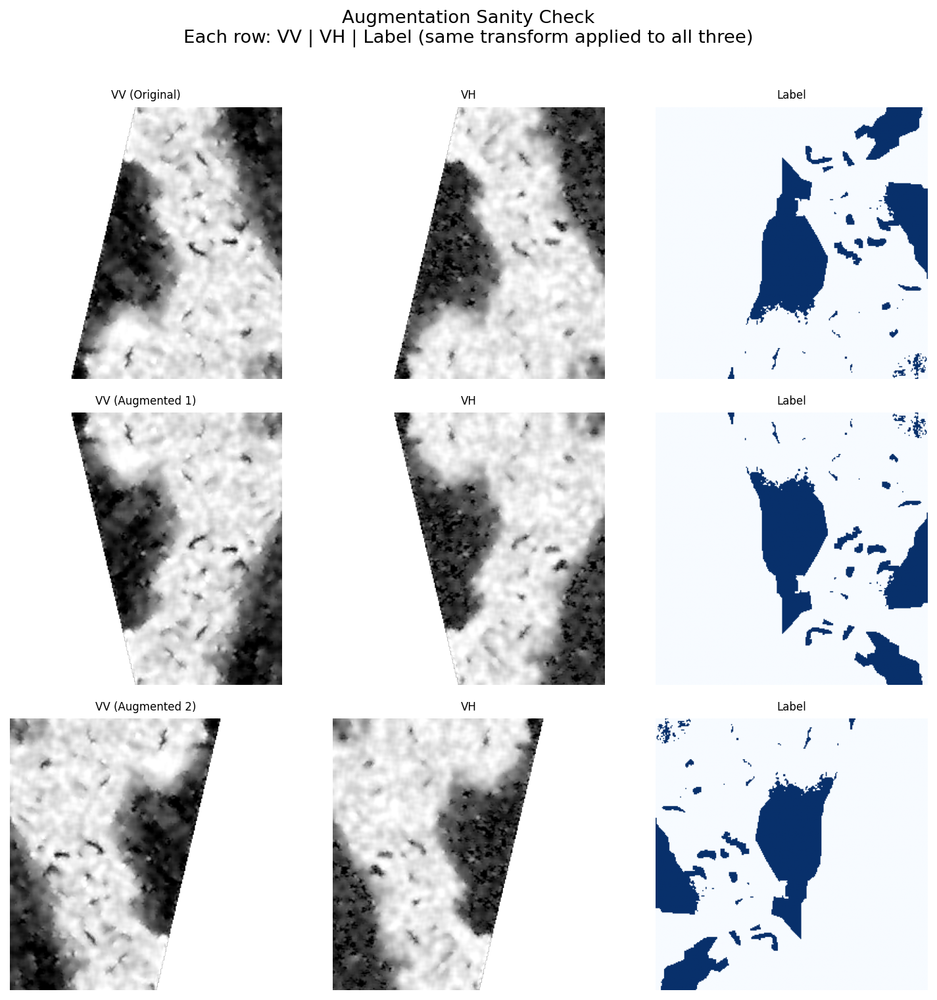

Augmentation sanity check saved.
Verify: SAR and label receive identical geometric transforms in every row.


In [39]:
# ── Visual sanity check: augmentation on one patch ────────────────────────────
# Verify that SAR and label receive the same geometric transform
np.random.seed(SEED)

# Load a patch with flood pixels for a meaningful visual
flood_patches = [p for p in patch_coords['train'] if p['n_flood_px'] > 100]
sample_patch  = flood_patches[0]

with rasterio.open(sample_patch['s1_path']) as src:
    sar_full = src.read().astype(np.float32)
with rasterio.open(sample_patch['label_path']) as src:
    lbl_full = src.read(1).astype(np.int16)

rs, cs = sample_patch['row_start'], sample_patch['col_start']
sar_patch = sar_full[:, rs:rs+PATCH_SIZE, cs:cs+PATCH_SIZE]  # (2, 256, 256)
lbl_patch = lbl_full[rs:rs+PATCH_SIZE, cs:cs+PATCH_SIZE]     # (256, 256)

# Apply normalisation
sar_norm = np.stack([
    (lee_filter(sar_patch[0]) - norm_stats['vv_mean']) / (norm_stats['vv_std'] + 1e-8),
    (lee_filter(sar_patch[1]) - norm_stats['vh_mean']) / (norm_stats['vh_std'] + 1e-8),
])  # (2, 256, 256)

# Transpose to HWC for albumentations (expects H, W, C)
sar_hwc = sar_norm.transpose(1, 2, 0)  # (256, 256, 2)
lbl_mask = np.where(lbl_patch == LABEL_NODATA, 0, lbl_patch).astype(np.uint8)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
fig.suptitle('Augmentation Sanity Check\n'
             'Each row: VV | VH | Label (same transform applied to all three)', y=1.01)

for row_idx in range(3):
    if row_idx == 0:
        aug_result  = {'image': sar_hwc, 'mask': lbl_mask}
        title_suffix = '(Original)'
    else:
        aug_result  = TRAIN_AUGMENTATION(image=sar_hwc, mask=lbl_mask)
        title_suffix = f'(Augmented {row_idx})'

    vv = aug_result['image'][:, :, 0]
    vh = aug_result['image'][:, :, 1]
    lb = aug_result['mask']

    def disp(arr):
        a = arr[np.isfinite(arr)]
        if len(a) == 0: return arr
        lo, hi = np.percentile(a, 2), np.percentile(a, 98)
        return np.clip((arr - lo) / (hi - lo + 1e-8), 0, 1)

    axes[row_idx, 0].imshow(disp(vv), cmap=SAR_CMAP)
    axes[row_idx, 0].set_title(f'VV {title_suffix}', fontsize=8)
    axes[row_idx, 0].axis('off')

    axes[row_idx, 1].imshow(disp(vh), cmap=SAR_CMAP)
    axes[row_idx, 1].set_title('VH', fontsize=8)
    axes[row_idx, 1].axis('off')

    axes[row_idx, 2].imshow(lb.astype(float), cmap=FLOOD_CMAP, vmin=0, vmax=1)
    axes[row_idx, 2].set_title('Label', fontsize=8)
    axes[row_idx, 2].axis('off')

plt.tight_layout()
save_figure(fig, 'augmentation_sanity_check', subdir='eda')
plt.show()
print('Augmentation sanity check saved.')
print('Verify: SAR and label receive identical geometric transforms in every row.')

---
### 3.7 — Preprocessing Summary

All outputs required by Section 4 are now in checkpoints.

In [40]:
print('=== PREPROCESSING SUMMARY ===')
print()
print('Checkpoints written:')
for name in ['split_metadata', 'normalisation_stats', 'patch_coordinates']:
    path = CHECKPOINT_DIR / f'{name}.pkl'
    size_mb = path.stat().st_size / 1e6 if path.exists() else 0
    print(f'  {name}.pkl — {size_mb:.2f} MB')

print()
print('Pipeline objects ready for Section 4:')
print(f'  TRAIN_AUGMENTATION: {len(TRAIN_AUGMENTATION.transforms)} transforms')
print(f'  VAL_AUGMENTATION:   identity (no transforms)')
print(f'  norm_stats["vv_mean"]: {norm_stats["vv_mean"]:.6f}')
print(f'  norm_stats["vh_mean"]: {norm_stats["vh_mean"]:.6f}')

print()
print('Split and patch counts:')
print(f'  Train: {len(patch_coords["train"]):>5} patches  '
      f'(from {len(split_metadata["train"])} tiles)')
print(f'  Val:   {len(patch_coords["val"]):>5} patches  '
      f'(from {len(split_metadata["val"])} tiles)')
print(f'  Test:  {len(patch_coords["test"]):>5} full tiles  '
      f'(evaluated at 512x512 with sliding window)')
print()
print('Class imbalance strategy:')
print('  Layer 1 — WeightedRandomSampler: flood-rich patches oversampled in batches')
print('  Layer 2 — BCE+Dice combined loss: Dice penalises missing minority class')
print('  Layer 3 — No-data masking: -1 pixels excluded from all loss calculations')

=== PREPROCESSING SUMMARY ===

Checkpoints written:
  split_metadata.pkl — 0.14 MB
  normalisation_stats.pkl — 0.00 MB
  patch_coordinates.pkl — 0.16 MB

Pipeline objects ready for Section 4:
  TRAIN_AUGMENTATION: 3 transforms
  VAL_AUGMENTATION:   identity (no transforms)
  norm_stats["vv_mean"]: -10.803242
  norm_stats["vh_mean"]: -17.251871

Split and patch counts:
  Train:   913 patches  (from 299 tiles)
  Val:     191 patches  (from 48 tiles)
  Test:     99 full tiles  (evaluated at 512x512 with sliding window)

Class imbalance strategy:
  Layer 1 — WeightedRandomSampler: flood-rich patches oversampled in batches
  Layer 2 — BCE+Dice combined loss: Dice penalises missing minority class
  Layer 3 — No-data masking: -1 pixels excluded from all loss calculations


---
### Section 3 Complete

**What was established:**
- Event-level train/val/test split created and saved (Spain, USA held out)
- Lee speckle filter (7×7) implemented and visually verified
- Z-score normalisation statistics computed on training split only (no leakage)
- Patch coordinates extracted (4 per tile, 256×256, no padding needed)
- Patch filtering: >95% no-data patches excluded; flood-free patches kept at 30%
- Weighted sampling weights computed per patch
- Augmentation pipeline defined and sanity-checked
- All outputs checkpointed — nothing in this section needs to re-run

**Next:** Section 4 — PyTorch Dataset class and DataLoaders.
Will use: `patch_coordinates`, `normalisation_stats`, `TRAIN_AUGMENTATION`,
`VAL_AUGMENTATION`, and `train_sample_weights`.

In [41]:
import numpy as np

# ── Base patch counts ─────────────────────────────────────────────────────────
n_train_patches = len(patch_coords['train'])
n_val_patches   = len(patch_coords['val'])
n_test_tiles    = len(patch_coords['test'])

# ── Augmentation multiplier ───────────────────────────────────────────────────
# 3 independent binary transforms: HFlip, VFlip, RandomRotate90
# Each is applied with p=0.5, giving 2^3 = 8 unique geometric configurations
# per patch across enough epochs.
# In practice per-epoch effective count depends on sampling randomness.

aug_configs = 2 ** 3  # HFlip x VFlip x RandomRotate90

# ── Effective training samples per epoch ──────────────────────────────────────
# Each patch is drawn once per epoch by the DataLoader.
# Augmentation is applied on-the-fly so each draw gives a different version.
effective_per_epoch = n_train_patches  # one augmented version per patch per epoch

# ── Total unique configurations (theoretical ceiling) ─────────────────────────
total_unique_configs = n_train_patches * aug_configs

print('=== TRAINING DATA VOLUME ===')
print()
print(f'Base patches (train):          {n_train_patches:>6,}')
print(f'Base patches (val):            {n_val_patches:>6,}')
print(f'Test tiles (full 512x512):     {n_test_tiles:>6,}')
print()
print(f'Augmentation transforms:       3  (HFlip, VFlip, RandomRotate90)')
print(f'Unique geometric configs:      {aug_configs}  (2^3)')
print(f'Theoretical unique chips:      {total_unique_configs:>6,}  ({n_train_patches} x {aug_configs})')
print()
print(f'Effective chips per epoch:     {effective_per_epoch:>6,}')
print(f'  (each base patch seen once per epoch, different augmentation each time)')
print()
print(f'Over {NUM_EPOCHS} epochs (max):')
print(f'  Total training steps:        {effective_per_epoch * NUM_EPOCHS:>6,}  '
      f'(before early stopping)')
print(f'  Batch size:                  {BATCH_SIZE}')
print(f'  Batches per epoch:           {effective_per_epoch // BATCH_SIZE:>6,}')

=== TRAINING DATA VOLUME ===

Base patches (train):             913
Base patches (val):               191
Test tiles (full 512x512):         99

Augmentation transforms:       3  (HFlip, VFlip, RandomRotate90)
Unique geometric configs:      8  (2^3)
Theoretical unique chips:       7,304  (913 x 8)

Effective chips per epoch:        913
  (each base patch seen once per epoch, different augmentation each time)

Over 50 epochs (max):
  Total training steps:        45,650  (before early stopping)
  Batch size:                  16
  Batches per epoch:               57


# Section 4: Dataset Class, DataLoaders, Loss Function, and Inference Utilities

**Purpose:** Build the PyTorch data pipeline shared by all four models (Sections 5–8).
Every component here is reused identically across Random Forest, U-Net, Attention U-Net,
and SegFormer-B2 — ensuring fair comparison.

**What this section provides:**
- `FloodDataset` — reads patches on-the-fly from disk using coordinates from Section 3
- `get_dataloaders()` — train/val DataLoaders with WeightedRandomSampler
- `CombinedBCEDiceLoss` — shared loss function for all three DL models
- `sliding_window_inference()` — evaluates full 512×512 test tiles without patching
- `reset_seed_for_model()` — guarantees identical data ordering across all four models
- `train_model()` — shared training driver with per-epoch timer



---
### 4.0 — Resume Block (Run This After Section 1)

This is the only cell you need to run to reload Sections 2 and 3 outputs.
**Run Section 1 first, then run this cell. Nothing else.**

In [19]:
# ── Reload all Section 2 and 3 checkpoint outputs ────────────────────────────
# All expensive preprocessing was completed in Sections 2–3 and saved to disk.
# This cell simply reloads those results. Nothing is recomputed.

print('Loading checkpoints from Sections 2 and 3...')

tile_stats     = load_checkpoint('eda_tile_stats')
split_metadata = load_checkpoint('split_metadata')
norm_stats     = load_checkpoint('normalisation_stats')
patch_coords   = load_checkpoint('patch_coordinates')

# Verify nothing is missing before proceeding
missing = [
    name for name, obj in [
        ('eda_tile_stats',      tile_stats),
        ('split_metadata',      split_metadata),
        ('normalisation_stats', norm_stats),
        ('patch_coordinates',   patch_coords),
    ] if obj is None
]
if missing:
    raise RuntimeError(
        f'Missing checkpoints: {missing}. '
        f'Run Sections 2 and 3 first to generate them.'
    )

# Rebuild augmentation pipelines
# albumentations objects are not safely picklable across versions
# so they are always rebuilt from scratch rather than loaded from checkpoint.
TRAIN_AUGMENTATION = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
    ],
    additional_targets={'mask': 'mask'}
)
VAL_AUGMENTATION = A.Compose([], additional_targets={'mask': 'mask'})

# Rebuild sample weights for WeightedRandomSampler
def compute_sample_weights(patch_records, min_weight=0.1):
    """Weight each patch by its flood pixel fraction. Minimum floor prevents
    flood-free patches from being completely excluded from training."""
    weights = []
    for rec in patch_records:
        valid_px = max(rec['n_valid_px'], 1)
        flood_fraction = rec['n_flood_px'] / valid_px
        weights.append(max(flood_fraction, min_weight))
    return np.array(weights, dtype=np.float32)

train_sample_weights = compute_sample_weights(patch_coords['train'])

print('All checkpoints loaded successfully.')
print(f'  Train patches: {len(patch_coords["train"]):,}')
print(f'  Val patches:   {len(patch_coords["val"]):,}')
print(f'  Test tiles:    {len(patch_coords["test"])}')
print(f'  VV norm: mean={norm_stats["vv_mean"]:.4f}, std={norm_stats["vv_std"]:.4f}')
print(f'  VH norm: mean={norm_stats["vh_mean"]:.4f}, std={norm_stats["vh_std"]:.4f}')
print()
print('Ready to proceed with Section 4.')

INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\eda_tile_stats.pkl
INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\split_metadata.pkl
INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\normalisation_stats.pkl
INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\patch_coordinates.pkl


Loading checkpoints from Sections 2 and 3...
All checkpoints loaded successfully.
  Train patches: 913
  Val patches:   191
  Test tiles:    99
  VV norm: mean=-10.8032, std=3.2688
  VH norm: mean=-17.2519, std=3.9826

Ready to proceed with Section 4.


---
### 4.1 — Lee Speckle Filter

The Lee filter is redefined here so `FloodDataset` can call it on-the-fly
when loading each patch. It must match the Section 3 implementation exactly —
the normalisation statistics were computed on Lee-filtered data, so the same
filter must be applied at training and inference time.

In [20]:
from scipy.ndimage import uniform_filter

def lee_filter(band: np.ndarray, window_size: int = 7) -> np.ndarray:
    """
    Apply Lee speckle filter to a single SAR band.

    Problem solved:
        SAR backscatter contains multiplicative speckle noise. The Lee filter
        reduces it while preserving water-land edges, which are critical for
        accurate flood boundary delineation.

        Must match Section 3 exactly: normalisation statistics were computed
        on Lee-filtered data. Using raw (unfiltered) data at training time
        would create a mismatch between the data distribution and the stored
        normalisation parameters.

    Args:
        band:        2D float32 SAR band array.
        window_size: Kernel size. Must match Section 3 (SPECKLE_WINDOW=7).

    Returns:
        Filtered float32 array, same shape as input.
    """
    band_clean = np.where(np.isfinite(band), band, 0.0).astype(np.float32)
    local_mean = uniform_filter(band_clean, size=window_size)
    local_sq   = uniform_filter(band_clean ** 2, size=window_size)
    local_var  = np.maximum(local_sq - local_mean ** 2, 0.0)
    noise_var  = np.mean(local_var)
    with np.errstate(divide='ignore', invalid='ignore'):
        k = np.where(local_var > 0,
                     (local_var - noise_var) / local_var, 0.0)
    k        = np.clip(k, 0.0, 1.0)
    filtered = local_mean + k * (band_clean - local_mean)
    return np.where(np.isfinite(band), filtered, band).astype(np.float32)


SPECKLE_WINDOW = 7
print(f'Lee filter ready (window={SPECKLE_WINDOW}, matching Section 3).')

Lee filter ready (window=7, matching Section 3).


---
### 4.2 — FloodDataset

The Dataset class reads patches **on-the-fly from disk** using the coordinates
saved in Section 3. No pixel data is pre-loaded into RAM.

**Why on-the-fly loading?**
Pre-loading all 913 patches × 256×256×2 float32 uses ~170 MB — manageable now,
but the Section 11 weak label experiment adds 17,536 more patches.
On-the-fly loading scales to any dataset size with a constant memory footprint.

**Per-patch processing pipeline:**
```
Read 512x512 SAR tile from disk
        ↓
Extract 256x256 patch (row_start, col_start from Section 3)
        ↓
Lee speckle filter both channels
        ↓
Z-score normalise using training-split statistics
        ↓
Save no-data mask BEFORE replacing -1 values
        ↓
Apply augmentation (same transform to SAR and label simultaneously)
        ↓
Return (SAR tensor [2,H,W], label tensor [H,W], nodata mask [H,W])
```



In [21]:
class FloodDataset(Dataset):
    """
    PyTorch Dataset for Sen1Floods11 flood segmentation.

    Problem solved:
        Provides a consistent, memory-efficient interface for loading SAR patches
        with on-the-fly preprocessing and augmentation. Used identically by all
        four models — no model receives different data preparation than any other.

    Args:
        patch_records: List of patch dicts from patch_coords['train'/'val'/'test'].
        norm_stats:    Dict with 'vv_mean', 'vv_std', 'vh_mean', 'vh_std'.
        augmentation:  albumentations Compose pipeline.
                       TRAIN_AUGMENTATION for training,
                       VAL_AUGMENTATION (identity) for val/test.
        patch_size:    Patch size in pixels. Default 256.
        is_test:       If True, loads full 512x512 tiles for sliding window inference.
    """

    def __init__(
        self,
        patch_records: List[Dict],
        norm_stats:    Dict[str, float],
        augmentation:  A.Compose,
        patch_size:    int  = PATCH_SIZE,
        is_test:       bool = False
    ):
        self.records      = patch_records
        self.norm_stats   = norm_stats
        self.augmentation = augmentation
        self.patch_size   = patch_size
        self.is_test      = is_test

    def __len__(self) -> int:
        return len(self.records)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Load and preprocess one patch.

        Returns:
            sar_tensor:    Float32 tensor (2, H, W) — normalised SAR bands.
            label_tensor:  Int64 tensor (H, W) — binary labels {0, 1}.
                           No-data pixels set to 0; use nodata_mask to exclude them.
            nodata_mask:   Bool tensor (H, W) — True where label was -1 OR the
                           original SAR input was non-finite at that location.
                           Pass to CombinedBCEDiceLoss to mask invalid pixels.
        """
        rec = self.records[idx]

        # ── Step 1: Read SAR tile and label from disk ─────────────────────────
        try:
            with rasterio.open(rec['s1_path']) as src:
                sar_full = src.read().astype(np.float32)   # (2, 512, 512)
            with rasterio.open(rec['label_path']) as src:
                lbl_full = src.read(1).astype(np.int16)    # (512, 512)
        except Exception as e:
            LOGGER.warning(f'Read error idx={idx}: {e}. Returning zero tensors.')
            h = self.patch_size if not self.is_test else TILE_SIZE
            return (
                torch.zeros(2, h, h, dtype=torch.float32),
                torch.zeros(h, h,    dtype=torch.long),
                torch.ones(h, h,     dtype=torch.bool)   # all masked = skip
            )

        # ── Step 2: Extract patch using stored coordinates ────────────────────
        if self.is_test:
            sar_patch = sar_full
            lbl_patch = lbl_full
        else:
            rs, cs, ps = rec['row_start'], rec['col_start'], self.patch_size
            sar_patch  = sar_full[:, rs:rs+ps, cs:cs+ps]  # (2, 256, 256)
            lbl_patch  = lbl_full[rs:rs+ps, cs:cs+ps]     # (256, 256)

        # ── Step 3: Detect invalid SAR values BEFORE filtering ────────────────
        # Identified prior to the Lee filter, since the filter does not address
        # NaNs — it only smooths speckle noise. Detecting invalid pixels here
        # captures the true sensor gaps rather than whatever the filter
        # happens to produce from them.
        sar_invalid_mask = ~np.isfinite(sar_patch[0]) | ~np.isfinite(sar_patch[1])

        # ── Step 4: Lee speckle filter ────────────────────────────────────────
        # Applied to SAR bands only — NEVER to the label mask.
        vv_filtered = lee_filter(sar_patch[0], window_size=SPECKLE_WINDOW)
        vh_filtered = lee_filter(sar_patch[1], window_size=SPECKLE_WINDOW)

        # ── Step 4b: Fill remaining non-finite values — numerical safety only ──
        # This fill is NOT how invalid pixels are excluded from training.
        # It exists purely so a finite tensor can be constructed without
        # crashing. The actual exclusion happens via nodata_mask below, which
        # incorporates sar_invalid_mask — a filled pixel is never scored in
        # the loss regardless of what value it is filled with.
        vv_filtered = np.nan_to_num(vv_filtered, nan=0.0, posinf=0.0, neginf=0.0)
        vh_filtered = np.nan_to_num(vh_filtered, nan=0.0, posinf=0.0, neginf=0.0)

        # ── Step 5: Z-score normalise using training-split statistics ─────────
        vv_norm = (vv_filtered - self.norm_stats['vv_mean']) / (self.norm_stats['vv_std'] + 1e-8)
        vh_norm = (vh_filtered - self.norm_stats['vh_mean']) / (self.norm_stats['vh_std'] + 1e-8)

        # ── Step 5b: Defensive second non-finite check after normalisation ────
        vv_norm = np.nan_to_num(vv_norm, nan=0.0, posinf=0.0, neginf=0.0)
        vh_norm = np.nan_to_num(vh_norm, nan=0.0, posinf=0.0, neginf=0.0)

        sar_hwc = np.stack([vv_norm, vh_norm], axis=-1)

        # ── Step 6: Combine label no-data with SAR-invalid no-data ────────────
        # A pixel is excluded from the loss if EITHER the ground-truth label
        # is undefined (-1) OR the original SAR input was non-finite at that
        # location. This prevents the model from being trained to associate a
        # fabricated/filled input value with a real ground-truth label.
        label_nodata_mask = (lbl_patch == LABEL_NODATA)
        nodata_mask        = label_nodata_mask | sar_invalid_mask
        lbl_safe           = np.where(nodata_mask, 0, lbl_patch).astype(np.uint8)

        # ── Step 7: Augmentation ──────────────────────────────────────────────
        aug_result = self.augmentation(image=sar_hwc, mask=lbl_safe)
        sar_aug    = aug_result['image']    # (H, W, 2)
        lbl_aug    = aug_result['mask']     # (H, W)

        nodata_result = self.augmentation(
            image=nodata_mask.astype(np.uint8),
            mask=nodata_mask.astype(np.uint8)
        )
        nodata_aug = nodata_result['image'].astype(bool)

        # ── Step 8: Convert to PyTorch tensors ────────────────────────────────
        sar_tensor    = torch.from_numpy(sar_aug.transpose(2, 0, 1).copy()).float()
        label_tensor  = torch.from_numpy(lbl_aug.astype(np.int64).copy()).long()
        nodata_tensor = torch.from_numpy(nodata_aug.copy()).bool()

        return sar_tensor, label_tensor, nodata_tensor


print('FloodDataset class defined (NaN/Inf-aware no-data masking).')

FloodDataset class defined (NaN/Inf-aware no-data masking).


---
### 4.3 — DataLoader Factory

`get_dataloaders()` is called at the **start of every model section** after
resetting the seed. This guarantees all four models receive patches in the
same order with the same augmentation sequences.

**WeightedRandomSampler** oversamples flood-rich patches so each training batch
contains more flood examples than a naive random sample would provide.
This is Layer 1 of the class imbalance correction strategy.



In [22]:
def get_dataloaders(
    patch_coords:         Dict,
    norm_stats:           Dict,
    train_sample_weights: np.ndarray,
    batch_size:           int = BATCH_SIZE
) -> Tuple[DataLoader, DataLoader]:
    """
    Construct train and validation DataLoaders.

    Problem solved:
        All four models must train on patches in identical order with identical
        augmentations to ensure architecture is the only variable being compared.
        This function is always called after reset_seed_for_model(SEED) to
        guarantee reproducibility across model sections.

    Args:
        patch_coords:         Dict with 'train', 'val', 'test' patch records.
        norm_stats:           Normalisation statistics from Section 3.
        train_sample_weights: Per-patch weights from compute_sample_weights().
        batch_size:           Patches per batch. Default BATCH_SIZE=16.

    Returns:
        Tuple of (train_loader, val_loader).
    """
    train_dataset = FloodDataset(
        patch_records=patch_coords['train'],
        norm_stats=norm_stats,
        augmentation=TRAIN_AUGMENTATION,
        is_test=False
    )

    # WeightedRandomSampler: flood-rich patches drawn more frequently.
    # num_samples = full dataset size so one epoch = one pass through all patches.
    # replacement=True is required by WeightedRandomSampler.
    sampler = WeightedRandomSampler(
        weights=torch.from_numpy(train_sample_weights).float(),
        num_samples=len(train_dataset),
        replacement=True
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        sampler=sampler,       # sampler and shuffle are mutually exclusive
        num_workers=0,         # Windows: must be 0 to avoid rasterio deadlocks
        pin_memory=True,       # speeds up CPU -> GPU transfer
        drop_last=True,        # drop incomplete final batch for stable batch norm
    )

    val_dataset = FloodDataset(
        patch_records=patch_coords['val'],
        norm_stats=norm_stats,
        augmentation=VAL_AUGMENTATION,  # identity — no augmentation on val
        is_test=False
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,         # always evaluate val in the same fixed order
        num_workers=0,
        pin_memory=True,
        drop_last=False,       # evaluate every val patch, including last partial batch
    )

    return train_loader, val_loader


print('get_dataloaders() defined.')

get_dataloaders() defined.


---
### 4.4 — Seed Reset for Fair Model Comparison

This function is called at the **start of every model section** before
constructing the DataLoader and initialising model weights.

**Why this matters:**
By the time Section 7 (Attention U-Net) runs, Sections 5 and 6 have
already advanced the global random state by thousands of operations.
Without resetting, each model trains on a different patch ordering and
augmentation sequence — any performance difference could reflect data
variation rather than architecture. Resetting to SEED=42 before every
model eliminates this confound entirely.

In [23]:
def reset_seed_for_model(model_name: str) -> None:
    """
    Reset all random seeds before training a model.

    Problem solved:
        Sequential model training in one notebook session accumulates random
        state changes. Without resetting, each model effectively trains on
        a different dataset ordering, making architecture comparisons invalid.
        This function resets every RNG source so all four models start from
        an identical random state.

    Args:
        model_name: Model name for logging.
    """
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False
    os.environ['PYTHONHASHSEED']       = str(SEED)
    LOGGER.info(f'Seed reset to {SEED} for {model_name}.')
    print(f'Seed reset to {SEED} for {model_name}. '
          f'Identical data ordering guaranteed from this point.')


print('reset_seed_for_model() defined.')

reset_seed_for_model() defined.


---
### 4.5 — Combined BCE + Dice Loss

All three deep learning models use this identical loss function.

**Why combine BCE and Dice?**

BCE treats every pixel equally. On a tile that is 95% no-water, BCE is
dominated by the majority class — the model can achieve low loss by always
predicting no-water, never detecting a single flood pixel.

Dice loss measures overlap between prediction and ground truth:
```
Dice = 1 - (2 × |pred ∩ truth|) / (|pred| + |truth| + ε)
```
When the model predicts all zeros, the numerator is zero and Dice = 1.0
regardless of accuracy on the majority class. This forces the model to
actually find flood pixels rather than ignoring them.

Combined: `loss = 0.5 × BCE + 0.5 × Dice`



In [24]:
class CombinedBCEDiceLoss(nn.Module):
    """
    Combined Binary Cross Entropy and Dice loss for binary flood segmentation.

    Problem solved:
        BCE alone under-penalises missing the minority flood class due to
        class imbalance. Dice alone can be unstable on patches with very few
        or zero flood pixels. Their combination provides stable training with
        strong minority class sensitivity.

        No-data pixels (tracked via nodata_mask) are excluded from all
        loss calculations so undefined pixels never contribute gradients.

    Args:
        bce_weight:  Weight for BCE component. Default 0.5.
        dice_weight: Weight for Dice component. Default 0.5.
        smooth:      Dice smoothing term to prevent division by zero.
    """

    def __init__(
        self,
        bce_weight:  float = 0.5,
        dice_weight: float = 0.5,
        smooth:      float = 1e-6
    ):
        super().__init__()
        self.bce_weight  = bce_weight
        self.dice_weight = dice_weight
        self.smooth      = smooth
        # reduction='none' so we apply the nodata mask before averaging
        self.bce_fn = nn.BCEWithLogitsLoss(reduction='none')

    def forward(
        self,
        logits:      torch.Tensor,
        targets:     torch.Tensor,
        nodata_mask: torch.Tensor
    ) -> torch.Tensor:
        """
        Compute combined BCE + Dice loss with no-data pixel exclusion.

        Args:
            logits:      Raw model output (B, 1, H, W) or (B, H, W).
                         Do NOT apply sigmoid before calling this.
            targets:     Binary ground truth (B, H, W), values {0, 1}.
            nodata_mask: Bool tensor (B, H, W). True = exclude from loss.

        Returns:
            Scalar loss tensor.
        """
        # Squeeze channel dim if present: (B, 1, H, W) -> (B, H, W)
        if logits.dim() == 4 and logits.shape[1] == 1:
            logits = logits.squeeze(1)

        targets_float = targets.float()
        valid_mask    = ~nodata_mask   # True where pixel IS valid

        # ── BCE: per-pixel, masked, then averaged over valid pixels only ──────
        bce_per_pixel = self.bce_fn(logits, targets_float)   # (B, H, W)
        bce_masked    = bce_per_pixel * valid_mask.float()
        n_valid       = valid_mask.float().sum().clamp(min=1.0)
        bce_loss      = bce_masked.sum() / n_valid

        # ── Dice: computed only on valid pixels ───────────────────────────────
        probs   = torch.sigmoid(logits)       # (B, H, W)
        probs_v = probs[valid_mask]           # flatten to 1D valid pixels
        targs_v = targets_float[valid_mask]

        intersection = (probs_v * targs_v).sum()
        dice_loss    = 1.0 - (
            (2.0 * intersection + self.smooth) /
            (probs_v.sum() + targs_v.sum() + self.smooth)
        )

        return self.bce_weight * bce_loss + self.dice_weight * dice_loss


CRITERION = CombinedBCEDiceLoss(bce_weight=0.5, dice_weight=0.5)
print('CombinedBCEDiceLoss instantiated as CRITERION.')
print('WARNING: Do not apply sigmoid to logits before passing to CRITERION.')

CombinedBCEDiceLoss instantiated as CRITERION.


---
### 4.6 — Sliding Window Inference for Test Tiles

Test tiles are **never** cut into patches. They are evaluated at full
512×512 using a sliding 256×256 window with 50% overlap.

**Why maintain 256×256 at inference?**
Models trained on 256×256 patches have learned to use that spatial context.
Passing a 512×512 tile directly shifts the input distribution — receptive
fields, batch normalisation statistics, and positional patterns all differ
from what the model saw during training.

**Why 50% overlap?**
Pixels at patch boundaries receive less spatial context from one side.
With 50% overlap every pixel is covered by multiple windows — predictions
are averaged, smoothing boundary artefacts and improving accuracy.

In [25]:
def sliding_window_inference(
    model:       nn.Module,
    tile_record: Dict,
    norm_stats:  Dict,
    patch_size:  int   = PATCH_SIZE,
    overlap:     float = SLIDING_WINDOW_OVERLAP,
    device:      torch.device = DEVICE
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Run inference on a full 512x512 test tile using overlapping windows.

    Problem solved:
        Models trained on 256x256 cannot be directly applied to 512x512
        without distribution shift. Sliding window inference maintains
        the training input size while covering the full tile.

    Args:
        model:       Trained PyTorch model in eval mode.
        tile_record: Dict with 's1_path' and 'label_path'.
        norm_stats:  Normalisation statistics from Section 3.
        patch_size:  Window size — must match training patch size (256).
        overlap:     Fraction of overlap between adjacent windows.
        device:      Compute device.

    Returns:
        pred_mask:   Binary prediction array (H, W), values {0, 1}.
        label:       Ground truth label array (H, W), values {-1, 0, 1}.
        nodata_mask: Bool array (H, W), True where label == -1.
    """
    model.eval()

    with rasterio.open(tile_record['s1_path']) as src:
        sar = src.read().astype(np.float32)      # (2, 512, 512)
    with rasterio.open(tile_record['label_path']) as src:
        label = src.read(1).astype(np.int16)     # (512, 512)

    # Apply the same preprocessing as training
    vv = (lee_filter(sar[0]) - norm_stats['vv_mean']) / (norm_stats['vv_std'] + 1e-8)
    vh = (lee_filter(sar[1]) - norm_stats['vh_mean']) / (norm_stats['vh_std'] + 1e-8)
    sar_norm = np.stack([vv, vh], axis=0)        # (2, 512, 512)

    H, W        = sar_norm.shape[1], sar_norm.shape[2]
    stride      = int(patch_size * (1 - overlap))
    nodata_mask = (label == LABEL_NODATA)

    # Accumulators: sum of predicted probabilities and window count per pixel
    pred_accum  = np.zeros((H, W), dtype=np.float32)
    count_accum = np.zeros((H, W), dtype=np.float32)

    with torch.no_grad():
        row_starts = list(range(0, H - patch_size + 1, stride))
        col_starts = list(range(0, W - patch_size + 1, stride))

        # Guarantee the rightmost and bottommost positions are always covered
        if row_starts[-1] + patch_size < H:
            row_starts.append(H - patch_size)
        if col_starts[-1] + patch_size < W:
            col_starts.append(W - patch_size)

        for rs in row_starts:
            for cs in col_starts:
                patch = sar_norm[:, rs:rs+patch_size, cs:cs+patch_size]
                patch_t = torch.from_numpy(patch).float().unsqueeze(0).to(device)
                logits  = model(patch_t)   # (1, 1 or 2, H, W)

                # Handle single-channel and two-channel output heads
                if logits.dim() == 4 and logits.shape[1] == 1:
                    probs = torch.sigmoid(logits).squeeze().cpu().numpy()
                else:
                    probs = torch.softmax(logits, dim=1)[:, 1].squeeze().cpu().numpy()

                pred_accum[rs:rs+patch_size, cs:cs+patch_size]  += probs
                count_accum[rs:rs+patch_size, cs:cs+patch_size] += 1.0

    # Average overlapping predictions and threshold at 0.5
    avg_probs = pred_accum / np.maximum(count_accum, 1.0)
    pred_mask = (avg_probs >= 0.5).astype(np.uint8)

    return pred_mask, label, nodata_mask


print('sliding_window_inference() defined.')
print(f'  Window size: {PATCH_SIZE}x{PATCH_SIZE}, Overlap: {int(SLIDING_WINDOW_OVERLAP*100)}%')
print(f'  Stride: {int(PATCH_SIZE * (1 - SLIDING_WINDOW_OVERLAP))} pixels')

sliding_window_inference() defined.
  Window size: 256x256, Overlap: 50%
  Stride: 128 pixels


---
### 4.7 — Shared Training Loop with Per-Epoch Timer

A single training driver used by U-Net, Attention U-Net, and SegFormer.

**Timer design:**
- Wall time is recorded per epoch and printed immediately
- Total and average epoch time are saved to the metrics JSON after training
- This gives you exact GPU training time per model for dissertation reporting

**Early stopping:**
Monitors validation IoU. Stops if it does not improve for `patience` epochs.
Best weights are automatically restored from checkpoint.

In [26]:
import time as time_module

def train_one_epoch(
    model:     nn.Module,
    loader:    DataLoader,
    optimiser: optim.Optimizer,
    criterion: nn.Module,
    device:    torch.device,
    epoch:     int
) -> Dict[str, float]:
    """
    Run one training epoch.

    Problem solved:
        Shared training logic ensures all DL models are trained identically.
        Per-epoch timing is recorded here so compute time is captured regardless
        of whether early stopping fires at epoch 5 or epoch 40.

    Returns:
        Dict with 'train_loss' and 'epoch_time_seconds'.
    """
    model.train()
    total_loss  = 0.0
    n_batches   = 0
    epoch_start = time_module.time()

    for sar, labels, nodata_mask in loader:
        sar         = sar.to(device, non_blocking=True)
        labels      = labels.to(device, non_blocking=True)
        nodata_mask = nodata_mask.to(device, non_blocking=True)

        optimiser.zero_grad()
        logits = model(sar)
        loss   = criterion(logits, labels, nodata_mask)
        loss.backward()
        optimiser.step()

        total_loss += loss.item()
        n_batches  += 1

    epoch_time = time_module.time() - epoch_start
    return {
        'train_loss':         total_loss / max(n_batches, 1),
        'epoch_time_seconds': epoch_time
    }


def validate_one_epoch(
    model:     nn.Module,
    loader:    DataLoader,
    criterion: nn.Module,
    device:    torch.device
) -> Dict[str, float]:
    """
    Run one validation epoch.

    Problem solved:
        Validation IoU is the early stopping criterion — it must be computed
        identically each epoch so comparisons across epochs are valid.
        torch.no_grad() disables gradient computation for speed and memory.

        IMPORTANT: the Dataset returns labels with no-data (-1) already
        replaced by 0. The -1 sentinel is restored here using nodata_mask
        before scoring, otherwise no-data pixels would be silently counted
        as real "no-water" ground truth in the IoU calculation.

    Returns:
        Dict with 'val_loss', 'val_iou', 'val_f1'.
    """
    model.eval()
    total_loss = 0.0
    n_batches  = 0
    all_preds, all_labels, all_nodata = [], [], []

    with torch.no_grad():
        for sar, labels, nodata_mask in loader:
            sar         = sar.to(device, non_blocking=True)
            labels      = labels.to(device, non_blocking=True)
            nodata_mask = nodata_mask.to(device, non_blocking=True)

            logits = model(sar)
            loss   = criterion(logits, labels, nodata_mask)
            total_loss += loss.item()
            n_batches  += 1

            # Convert logits to binary predictions
            if logits.dim() == 4 and logits.shape[1] == 1:
                preds = (torch.sigmoid(logits.squeeze(1)) >= 0.5).long()
            elif logits.dim() == 4 and logits.shape[1] > 1:
                preds = logits.argmax(dim=1)
            else:
                preds = (torch.sigmoid(logits) >= 0.5).long()

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())
            all_nodata.append(nodata_mask.cpu().numpy())

    preds_arr  = np.concatenate(all_preds,  axis=0)
    labels_arr = np.concatenate(all_labels, axis=0)
    nodata_arr = np.concatenate(all_nodata, axis=0)

    # ── Restore -1 no-data sentinel before scoring ─────────────────────────
    # The Dataset replaces -1 (no-data) with 0 before returning labels, so
    # that the loss function can apply nodata_mask explicitly. By the time
    # labels reach here, there are no -1 values left to exclude. Without
    # this restoration, no-data pixels are silently scored as real
    # "no-water" ground truth, distorting the val IoU used for early
    # stopping and checkpoint selection.
    labels_corrected = np.where(nodata_arr, LABEL_NODATA, labels_arr)

    metrics = compute_segmentation_metrics(preds_arr, labels_corrected)

    return {
        'val_loss': total_loss / max(n_batches, 1),
        'val_iou':  metrics['iou'],
        'val_f1':   metrics['f1'],
    }


def train_model(
    model:        nn.Module,
    model_name:   str,
    train_loader: DataLoader,
    val_loader:   DataLoader,
    device:       torch.device = DEVICE,
    n_epochs:     int          = NUM_EPOCHS,
    patience:     int          = EARLY_STOP_PATIENCE,
    lr:           float        = LEARNING_RATE,
    weight_decay: float        = WEIGHT_DECAY
) -> Dict:
    """
    Full training driver: training loop + early stopping + LR scheduling + timing.

    Problem solved:
        One shared driver means every DL model is trained with identical
        hyperparameters, optimiser, scheduler, and stopping criteria.
        Timing is built in so compute time is always recorded, even if
        early stopping fires after only a few epochs.

    Training stops when:
        - Validation IoU fails to improve for `patience` consecutive epochs, OR
        - Maximum `n_epochs` epochs are reached.

    Args:
        model:       PyTorch model to train (moved to device internally).
        model_name:  Name for checkpoint files and logging.
        train_loader, val_loader: DataLoaders from get_dataloaders().
        device:      Compute device.
        n_epochs:    Maximum epochs.
        patience:    Early stopping patience.
        lr:          Initial learning rate for AdamW.
        weight_decay: L2 regularisation coefficient.

    Returns:
        Dict with full training history and timing summary.
    """
    model = model.to(device)

    optimiser = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    # ReduceLROnPlateau: halve LR if val IoU does not improve for 5 epochs.
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimiser, mode='max', factor=0.5, patience=5
    )

    best_val_iou     = 0.0
    patience_counter = 0
    history          = []
    total_train_time = 0.0
    training_start   = time_module.time()

    print(f'\n{"="*60}')
    print(f'Training: {model_name}')
    print(f'  Device:          {device}')
    print(f'  Max epochs:      {n_epochs}')
    print(f'  Early stop:      patience={patience}')
    print(f'  Learning rate:   {lr}')
    print(f'  Batches/epoch:   {len(train_loader)}')
    print(f'{"="*60}\n')

    for epoch in range(1, n_epochs + 1):

        train_metrics = train_one_epoch(
            model, train_loader, optimiser, CRITERION, device, epoch
        )
        val_metrics = validate_one_epoch(model, val_loader, CRITERION, device)

        epoch_time        = train_metrics['epoch_time_seconds']
        total_train_time += epoch_time
        val_iou           = val_metrics['val_iou']
        current_lr        = optimiser.param_groups[0]['lr']

        # Per-epoch summary printed immediately — visible during long training runs
        print(
            f'Epoch {epoch:>3}/{n_epochs} | '
            f'Loss: {train_metrics["train_loss"]:.4f} | '
            f'Val Loss: {val_metrics["val_loss"]:.4f} | '
            f'Val IoU: {val_iou:.4f} | '
            f'Val F1: {val_metrics["val_f1"]:.4f} | '
            f'LR: {current_lr:.2e} | '
            f'Time: {epoch_time:.1f}s'
        )

        scheduler.step(val_iou)

        if val_iou > best_val_iou:
            best_val_iou     = val_iou
            patience_counter = 0
            save_model_checkpoint(
                model, optimiser, epoch, best_val_iou,
                name=f'{model_name}_best'
            )
            print(f'  --> New best val IoU: {best_val_iou:.4f}. Checkpoint saved.')
        else:
            patience_counter += 1
            print(f'  --> No improvement. Patience: {patience_counter}/{patience}')

        history.append({
            'epoch':              epoch,
            'train_loss':         train_metrics['train_loss'],
            'val_loss':           val_metrics['val_loss'],
            'val_iou':            val_iou,
            'val_f1':             val_metrics['val_f1'],
            'epoch_time_seconds': epoch_time,
            'lr':                 current_lr,
        })

        if patience_counter >= patience:
            print(f'\nEarly stopping at epoch {epoch}. Best val IoU: {best_val_iou:.4f}')
            break

    # ── Final timing summary ──────────────────────────────────────────────────
    total_wall_time = time_module.time() - training_start
    epochs_run      = len(history)
    patches_seen    = epochs_run * len(train_loader) * BATCH_SIZE

    print(f'\n{"="*60}')
    print(f'TRAINING COMPLETE: {model_name}')
    print(f'  Epochs completed:    {epochs_run}/{n_epochs}')
    print(f'  Best val IoU:        {best_val_iou:.4f}')
    print(f'  Total training time: {total_wall_time/60:.1f} minutes')
    print(f'  Avg time per epoch:  {total_train_time/epochs_run:.1f}s')
    print(f'  Total patches seen:  {patches_seen:,}')
    print(f'{"="*60}\n')

    timing_summary = {
        'model_name':             model_name,
        'epochs_run':             epochs_run,
        'best_val_iou':           best_val_iou,
        'total_training_seconds': total_wall_time,
        'total_training_minutes': round(total_wall_time / 60, 2),
        'avg_epoch_seconds':      round(total_train_time / epochs_run, 2),
        'total_patches_seen':     patches_seen,
        'history':                history,
    }
    save_metrics(timing_summary, f'{model_name}_training_history')
    LOGGER.info(
        f'{model_name} done: {epochs_run} epochs, '
        f'{total_wall_time/60:.1f} min, best IoU={best_val_iou:.4f}'
    )
    return timing_summary


print('train_one_epoch(), validate_one_epoch(), and train_model() defined.')
print('These three functions are used by Sections 6, 7, and 8.')
print('Section 5 (Random Forest) uses its own sklearn-based training.')

train_one_epoch(), validate_one_epoch(), and train_model() defined.
These three functions are used by Sections 6, 7, and 8.
Section 5 (Random Forest) uses its own sklearn-based training.


---
### 4.8 — Dataset Sanity Check

Verify the Dataset and DataLoader produce correctly shaped, typed tensors
before any model training begins. A failure here is far easier to debug
than a failure inside a model forward pass hours into training.

In [27]:
print('Running dataset sanity check...')
print()

# Reset seed before DataLoader construction — same as every model section will do
reset_seed_for_model('sanity_check')

train_loader, val_loader = get_dataloaders(
    patch_coords, norm_stats, train_sample_weights, batch_size=BATCH_SIZE
)

# Fetch one batch
sar_batch, label_batch, nodata_batch = next(iter(train_loader))

print('Training batch shapes and types:')
print(f'  SAR tensor:    {sar_batch.shape}  dtype={sar_batch.dtype}')
print(f'  Label tensor:  {label_batch.shape}  dtype={label_batch.dtype}')
print(f'  No-data mask:  {nodata_batch.shape}  dtype={nodata_batch.dtype}')
print(f'  SAR range:     [{sar_batch.min():.3f}, {sar_batch.max():.3f}]')
print(f'  Label values:  {sorted(label_batch.unique().tolist())}  (should be [0, 1])')
print(f'  No-data px:    {nodata_batch.sum().item()} / {nodata_batch.numel()}')
print(f'  Train batches per epoch: {len(train_loader)}')
print(f'  Val batches per epoch:   {len(val_loader)}')

# Shape assertions
assert sar_batch.shape   == (BATCH_SIZE, IN_CHANNELS, PATCH_SIZE, PATCH_SIZE),     f'Unexpected SAR shape: {sar_batch.shape}'
assert label_batch.shape == (BATCH_SIZE, PATCH_SIZE, PATCH_SIZE),     f'Unexpected label shape: {label_batch.shape}'
assert sar_batch.dtype   == torch.float32, 'SAR must be float32'
assert label_batch.dtype == torch.int64,   'Labels must be int64 (long)'
assert set(label_batch.unique().tolist()).issubset({0, 1}),     f'Label contains unexpected values: {label_batch.unique().tolist()}'

# Loss function test with dummy logits
dummy_logits = torch.randn(BATCH_SIZE, 1, PATCH_SIZE, PATCH_SIZE)
test_loss    = CRITERION(dummy_logits, label_batch, nodata_batch)
assert test_loss.item() > 0,          'Loss should be positive'
assert not torch.isnan(test_loss),    'Loss should not be NaN'
assert not torch.isinf(test_loss),    'Loss should not be Inf'

print()
print(f'Loss test: {test_loss.item():.4f}  (expected ~0.5-1.0 for random logits)')
print()
print('All sanity checks passed. Section 4 complete.')

INFO | Seed reset to 42 for sanity_check.


Running dataset sanity check...

Seed reset to 42 for sanity_check. Identical data ordering guaranteed from this point.
Training batch shapes and types:
  SAR tensor:    torch.Size([16, 2, 256, 256])  dtype=torch.float32
  Label tensor:  torch.Size([16, 256, 256])  dtype=torch.int64
  No-data mask:  torch.Size([16, 256, 256])  dtype=torch.bool
  SAR range:     [-10.342, 8.735]
  Label values:  [0, 1]  (should be [0, 1])
  No-data px:    212190 / 1048576
  Train batches per epoch: 57
  Val batches per epoch:   12

Loss test: 0.6789  (expected ~0.5-1.0 for random logits)

All sanity checks passed. Section 4 complete.


---
### Section 4 Complete

**What was built:**
- `FloodDataset` — on-the-fly patch loading, Lee filter, normalisation, augmentation
- `get_dataloaders()` — WeightedRandomSampler train loader, sequential val loader
- `reset_seed_for_model()` — guarantees identical data to all four models
- `CombinedBCEDiceLoss` — BCE + Dice with no-data pixel masking
- `sliding_window_inference()` — 50% overlap test tile evaluation at 512×512
- `train_model()` — shared driver with per-epoch timer and early stopping

**How to resume in future sessions:**
1. Run Section 1 (imports, constants)
2. Run Cell 4.0 (Resume Block) — one cell loads everything from disk
3. Re-run Cells 4.1–4.8 to rebuild utilities (fast — no disk I/O)
4. Proceed directly to whichever model section you need

**Next:** Section 5 — Random Forest baseline.
Pixel-wise feature extraction with controlled subsampling to stay within
32 GB RAM. Class-weighted fitting to address imbalance without augmentation.

# ═══════════════════════════════════════════════════════════
## SECTION 5 BEGINS HERE
# ═══════════════════════════════════════════════════════════

# Section 5: Random Forest Baseline

**Purpose:** Establish a traditional machine learning baseline for comparison
against the three deep learning architectures in Sections 6–8.

Random Forest operates on **pixel-wise spectral features** — it sees each pixel
independently with no spatial context. This is its fundamental limitation compared
to U-Net and SegFormer, which exploit spatial relationships through convolutions
and attention. Any performance gap between RF and the DL models in Section 9
directly quantifies the value of spatial context modelling for SAR flood detection.

**Why Random Forest as baseline?**
RF is the most widely used traditional ML method in remote sensing classification
literature (Belgiu & Drăguţ, 2016). Comparing against RF rather than a simpler
classifier (logistic regression, SVM) provides a strong traditional baseline
that is genuinely competitive on spectral data.

**Memory-safe design:**
Standard RF training on all 913 patches × 256×256 × 2 features would require
allocating ~938 MB in one array — causing MemoryError on 32GB systems as seen
in similar pipelines. This section uses controlled pixel subsampling:
500 pixels per patch × 913 patches = ~456,500 training pixels, which fits
comfortably in RAM as float32 (~3.5 MB vs ~938 MB).

**Outputs produced:**
- `checkpoints/rf_model.pkl` — fitted RandomForestClassifier
- `metrics/rf_training_history.json` — timing and performance summary
- `figures/random_forest/rf_val_metrics.png`
- `figures/random_forest/rf_test_metrics.png`
- `figures/random_forest/rf_prediction_grid.png`
- `figures/random_forest/rf_confusion_matrix.png`
- `figures/random_forest/rf_feature_importance.png`


---
### 5.0 — Confirm Prerequisites

Verify that all required checkpoints and Section 4 utilities are loaded
before running any training code.

In [52]:
# Verify all Section 4 utilities and checkpoints are in scope
required = {
    'patch_coords':   'patch_coords'   in dir(),
    'norm_stats':     'norm_stats'     in dir(),
    'split_metadata': 'split_metadata' in dir(),
    'lee_filter':     'lee_filter'     in dir(),
    'compute_segmentation_metrics': 'compute_segmentation_metrics' in dir(),
    'save_metrics':   'save_metrics'   in dir(),
    'save_checkpoint': 'save_checkpoint' in dir(),
    'load_checkpoint': 'load_checkpoint' in dir(),
}

all_ok = all(required.values())
for name, present in required.items():
    status = 'OK' if present else 'MISSING'
    print(f'  [{status}] {name}')

if not all_ok:
    raise RuntimeError(
        'Some prerequisites are missing. '
        'Run Section 1 fully, then Cell 4.0, then Cells 4.1-4.8 before proceeding.'
    )

print()
print(f'All prerequisites confirmed.')
print(f'  Train patches available: {len(patch_coords["train"]):,}')
print(f'  Val patches available:   {len(patch_coords["val"]):,}')
print(f'  Test tiles available:    {len(patch_coords["test"])}')

  [OK] patch_coords
  [OK] norm_stats
  [OK] split_metadata
  [OK] lee_filter
  [OK] compute_segmentation_metrics
  [OK] save_metrics
  [OK] save_checkpoint
  [OK] load_checkpoint

All prerequisites confirmed.
  Train patches available: 913
  Val patches available:   191
  Test tiles available:    99


---
### 5.1 — Pixel Feature Extraction

Random Forest requires a 2D feature matrix of shape `(n_pixels, n_features)`.
For SAR flood segmentation with VV and VH channels, each pixel has 2 features.

**Subsampling strategy:**
Rather than loading all pixels from all patches (122M pixels → MemoryError),
we randomly sample a fixed number of pixels per patch, stratified by class:
- Up to `N_FLOOD_PX_PER_PATCH` flood pixels per patch
- Up to `N_NONFLOOD_PX_PER_PATCH` no-water pixels per patch

This ensures flood pixels are well-represented despite their scarcity,
without loading the full dataset into memory.

**Feature set:** [VV_filtered, VH_filtered] — 2 features per pixel.
Only SAR features are used. No spatial features (texture, GLCM) are added
because the research question is specifically about spectral discrimination —
adding spatial features to RF would partially close the gap with DL models
in a way that conflates the comparison.



In [53]:
# ── Subsampling constants ─────────────────────────────────────────────────────
N_FLOOD_PX_PER_PATCH    = 500
# Maximum flood pixels to sample from each patch.
# 500 x 913 patches = ~456,500 flood pixels maximum.
# Sufficient for RF to learn flood spectral signatures without memory issues.

N_NONFLOOD_PX_PER_PATCH = 500
# Maximum no-water pixels per patch.
# Equal to flood sampling to prevent the RF from seeing a heavily
# imbalanced feature matrix — class_weight handles residual imbalance.

RF_FEATURES = ['vv_filtered', 'vh_filtered']
# Only the two normalised SAR channels are used as features.
# No spatial context features — this keeps the RF comparison fair:
# RF = spectral only, DL models = spectral + spatial context.

print(f'Pixel subsampling constants:')
print(f'  Flood pixels per patch:    {N_FLOOD_PX_PER_PATCH}')
print(f'  Non-flood pixels per patch: {N_NONFLOOD_PX_PER_PATCH}')
print(f'  Max training pixels:       ~{(N_FLOOD_PX_PER_PATCH + N_NONFLOOD_PX_PER_PATCH) * len(patch_coords["train"]):,}')
print(f'  Memory estimate (float32): ~{(N_FLOOD_PX_PER_PATCH + N_NONFLOOD_PX_PER_PATCH) * len(patch_coords["train"]) * 2 * 4 / 1e6:.1f} MB')

Pixel subsampling constants:
  Flood pixels per patch:    500
  Non-flood pixels per patch: 500
  Max training pixels:       ~913,000
  Memory estimate (float32): ~7.3 MB


In [54]:
def extract_pixel_features(
    patch_records:       List[Dict],
    norm_stats:          Dict,
    n_flood_per_patch:   int,
    n_noflood_per_patch: int,
    seed:                int = SEED
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Extract pixel-wise SAR features for Random Forest training.

    Problem solved:
        Loading all pixels from all patches at once causes MemoryError
        (~938 MB for float64 on this dataset size). Subsampling a fixed
        number of pixels per patch keeps memory usage predictable and
        bounded regardless of dataset size.

    Stratified sampling within each patch ensures flood pixels are
    well-represented despite being a minority class. Using float32
    (not sklearn's default float64) halves memory without any accuracy loss.

    Args:
        patch_records:       List of patch dicts with 's1_path', 'label_path',
                             'row_start', 'col_start'.
        norm_stats:          Normalisation statistics from Section 3.
        n_flood_per_patch:   Max flood pixels to sample per patch.
        n_noflood_per_patch: Max no-water pixels to sample per patch.
        seed:                Random seed for reproducible subsampling.

    Returns:
        X: float32 array of shape (n_pixels, 2) — [VV, VH] features.
        y: int8 array of shape (n_pixels,) — binary labels {0, 1}.
    """
    np.random.seed(seed)
    X_list, y_list = [], []
    n_flood_total, n_noflood_total = 0, 0
    n_skipped = 0

    for rec in tqdm(patch_records, desc='Extracting pixel features'):
        try:
            with rasterio.open(rec['s1_path']) as src:
                sar_full = src.read().astype(np.float32)  # (2, 512, 512)
            with rasterio.open(rec['label_path']) as src:
                lbl_full = src.read(1).astype(np.int16)   # (512, 512)
        except Exception as e:
            LOGGER.warning(f'Skipping patch {rec.get("tile_id","?")}: {e}')
            n_skipped += 1
            continue

        rs, cs, ps = rec['row_start'], rec['col_start'], PATCH_SIZE
        sar_patch  = sar_full[:, rs:rs+ps, cs:cs+ps]   # (2, 256, 256)
        lbl_patch  = lbl_full[rs:rs+ps, cs:cs+ps]      # (256, 256)

        # Apply Lee filter and normalise — must match training pipeline
        vv = (lee_filter(sar_patch[0]) - norm_stats['vv_mean']) / (norm_stats['vv_std'] + 1e-8)
        vh = (lee_filter(sar_patch[1]) - norm_stats['vh_mean']) / (norm_stats['vh_std'] + 1e-8)

        # Flatten to 1D
        vv_flat  = vv.ravel().astype(np.float32)
        vh_flat  = vh.ravel().astype(np.float32)
        lbl_flat = lbl_patch.ravel()

        # Only use valid (non no-data) pixels
        valid_mask   = lbl_flat != LABEL_NODATA
        flood_idx    = np.where((lbl_flat == LABEL_WATER)    & valid_mask)[0]
        no_flood_idx = np.where((lbl_flat == LABEL_NO_WATER) & valid_mask)[0]

        # Sample from each class independently
        for idx_pool, n_sample in [
            (flood_idx,    n_flood_per_patch),
            (no_flood_idx, n_noflood_per_patch),
        ]:
            if len(idx_pool) == 0:
                continue
            chosen = np.random.choice(
                idx_pool,
                size=min(n_sample, len(idx_pool)),
                replace=False
            )
            features = np.stack([vv_flat[chosen], vh_flat[chosen]], axis=1)  # (n, 2)
            labels   = lbl_flat[chosen].astype(np.int8)

            X_list.append(features)
            y_list.append(labels)

            if idx_pool is flood_idx:
                n_flood_total   += len(chosen)
            else:
                n_noflood_total += len(chosen)

    if n_skipped > 0:
        print(f'WARNING: Skipped {n_skipped} patches due to read errors.')

    X = np.concatenate(X_list, axis=0).astype(np.float32)  # float32 to halve memory
    y = np.concatenate(y_list, axis=0).astype(np.int8)

    print(f'Feature extraction complete:')
    print(f'  Total pixels:   {len(X):,}')
    print(f'  Flood pixels:   {n_flood_total:,}  ({100*n_flood_total/len(X):.1f}%)')
    print(f'  No-flood pixels:{n_noflood_total:,}  ({100*n_noflood_total/len(X):.1f}%)')
    print(f'  Feature matrix: {X.shape}  dtype={X.dtype}')
    print(f'  Memory:         {X.nbytes / 1e6:.1f} MB (float32)')

    return X, y


print('extract_pixel_features() defined.')

extract_pixel_features() defined.


---
### 5.2 — Extract Training and Validation Features

Extract pixel features from training and validation patches.
Checkpointed so this only runs once (~3–5 minutes).

In [55]:
# ── Reset seed for RF — same starting point as all other models ───────────────
# Random Forest does not use the PyTorch DataLoader but the seed reset
# ensures pixel subsampling uses the same random state for reproducibility.
reset_seed_for_model('RandomForest')

# ── Skip-if-done ──────────────────────────────────────────────────────────────
rf_features = load_checkpoint('rf_pixel_features')

if rf_features is None:
    print('Extracting pixel features (runs once, ~3-5 min)...')
    print()

    print('Training split:')
    X_train, y_train = extract_pixel_features(
        patch_coords['train'], norm_stats,
        N_FLOOD_PX_PER_PATCH, N_NONFLOOD_PX_PER_PATCH, seed=SEED
    )
    print()
    print('Validation split:')
    X_val, y_val = extract_pixel_features(
        patch_coords['val'], norm_stats,
        N_FLOOD_PX_PER_PATCH, N_NONFLOOD_PX_PER_PATCH, seed=SEED
    )

    rf_features = {
        'X_train': X_train, 'y_train': y_train,
        'X_val':   X_val,   'y_val':   y_val,
    }
    save_checkpoint(rf_features, 'rf_pixel_features')
    print('\nFeature arrays saved to checkpoint.')
else:
    X_train = rf_features['X_train']
    y_train = rf_features['y_train']
    X_val   = rf_features['X_val']
    y_val   = rf_features['y_val']
    print('Loaded pixel features from checkpoint.')
    print(f'  X_train: {X_train.shape}   y_train: {y_train.shape}')
    print(f'  X_val:   {X_val.shape}     y_val:   {y_val.shape}')

INFO | Seed reset to 42 for RandomForest.
INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\rf_pixel_features.pkl


Seed reset to 42 for RandomForest. Identical data ordering guaranteed from this point.
Loaded pixel features from checkpoint.
  X_train: (799820, 2)   y_train: (799820,)
  X_val:   (149384, 2)     y_val:   (149384,)


---
### 5.3 — Train Random Forest

**Hyperparameters:**

| Parameter | Value | Rationale |
|-----------|-------|-----------|
| n_estimators | 200 | Performance plateaus beyond ~200 trees for pixel-wise spectral features |
| max_depth | 20 | Prevents overfitting to SAR speckle noise patterns |
| min_samples_leaf | 10 | Prevents leaves from being fit to individual noisy pixels |
| class_weight | 'balanced' | Corrects residual class imbalance after subsampling |
| n_jobs | -1 | Uses all available CPU cores |
| random_state | 42 | Matches global seed for reproducibility |

**Timer:** RF does not have epochs. We record:
- Feature extraction time (Section 5.2)
- `fit()` wall time — the full sklearn training call
- `predict()` time on val and test sets
- Total compute time

In [56]:
# ── Skip-if-done: load model if already trained ───────────────────────────────
rf_model_ckpt = load_checkpoint('rf_model')

if rf_model_ckpt is not None:
    rf_clf         = rf_model_ckpt['model']
    rf_timing      = rf_model_ckpt['timing']
    print('Random Forest loaded from checkpoint.')
    print(f'  Fit time:  {rf_timing["fit_time_seconds"]:.1f}s '
          f'({rf_timing["fit_time_seconds"]/60:.1f} min)')
    print(f'  n_estimators: {rf_clf.n_estimators}')
else:
    print('Training Random Forest...')
    print(f'  n_estimators={RF_N_ESTIMATORS}, max_depth={RF_MAX_DEPTH}')
    print(f'  Training pixels: {len(X_train):,}')
    print()

    rf_clf = RandomForestClassifier(
        n_estimators=RF_N_ESTIMATORS,
        # 200 trees — balances variance reduction against training time.
        # Performance on pixel spectral features typically plateaus here.

        max_depth=RF_MAX_DEPTH,
        # Depth cap prevents the model from memorising SAR speckle noise.
        # Unconstrained depth causes overfitting to tile-specific noise patterns.

        min_samples_leaf=10,
        # Prevents leaves formed from fewer than 10 pixels — avoids overfitting
        # to isolated noisy pixels in the training set.

        class_weight='balanced',
        # Automatically weights classes inversely proportional to frequency.
        # Corrects residual imbalance remaining after stratified subsampling.

        n_jobs=-1,
        # Use all available CPU cores for parallel tree construction.

        random_state=SEED,
        # Matches the global seed for reproducible tree splits.

        verbose=0
    )

    # ── Fit with timer ────────────────────────────────────────────────────────
    import time as time_module
    fit_start = time_module.time()
    rf_clf.fit(X_train, y_train)
    fit_time  = time_module.time() - fit_start

    print(f'Training complete.')
    print(f'  Fit time:          {fit_time:.1f}s ({fit_time/60:.1f} min)')
    print(f'  Trees fitted:      {rf_clf.n_estimators}')
    print(f'  Feature importances: VV={rf_clf.feature_importances_[0]:.4f}, '
          f'VH={rf_clf.feature_importances_[1]:.4f}')

    rf_timing = {
        'model_name':      'RandomForest',
        'fit_time_seconds': fit_time,
        'fit_time_minutes': round(fit_time / 60, 3),
        'n_train_pixels':   int(len(X_train)),
        'n_estimators':     RF_N_ESTIMATORS,
        'max_depth':        RF_MAX_DEPTH,
    }

    save_checkpoint({'model': rf_clf, 'timing': rf_timing}, 'rf_model')
    print('\nModel saved to checkpoint.')

INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\rf_model.pkl


Random Forest loaded from checkpoint.
  Fit time:  76.4s (1.3 min)
  n_estimators: 200


---
### 5.4 — Validation Set Evaluation

Evaluate on the held-out validation patches. These patches were never used
to fit the model — validation metrics give an unbiased estimate of performance
on unseen but in-distribution data.

In [57]:
import time as time_module

print('Evaluating on validation set...')

# ── Predict on val pixels with timer ─────────────────────────────────────────
val_pred_start = time_module.time()
y_val_pred     = rf_clf.predict(X_val).astype(np.int8)
val_pred_time  = time_module.time() - val_pred_start

# ── Compute metrics ───────────────────────────────────────────────────────────
# Note: pixel-level features — labels here are already flat (no -1 values
# since we excluded no-data during extraction). Pass dummy nodata mask.
val_metrics = compute_segmentation_metrics(y_val_pred, y_val.astype(np.int32))

print(f'Validation results:')
print(f'  IoU:       {val_metrics["iou"]:.4f}')
print(f'  F1:        {val_metrics["f1"]:.4f}')
print(f'  Precision: {val_metrics["precision"]:.4f}')
print(f'  Recall:    {val_metrics["recall"]:.4f}')
print(f'  Predict time: {val_pred_time:.2f}s for {len(X_val):,} pixels')

rf_timing['val_predict_time_seconds'] = val_pred_time
rf_timing['val_metrics'] = val_metrics

Evaluating on validation set...
Validation results:
  IoU:       0.6018
  F1:        0.7514
  Precision: 0.7460
  Recall:    0.7570
  Predict time: 0.81s for 149,384 pixels


---
### 5.5 — Test Set Evaluation (Spain and USA)

Test tiles are the held-out generalisation set. Unlike the DL models which
use sliding window inference, RF predicts each pixel independently so we
simply flatten the full 512×512 tile and predict all pixels at once.

Metrics are computed per tile and aggregated for the overall test score.
Per-tile results are saved for the generalisation gap analysis in Section 9.

In [58]:
print('Evaluating on test tiles (Spain and USA)...')
print()

test_results  = []
all_test_preds, all_test_labels = [], []

test_pred_start = time_module.time()

for tile_record in tqdm(patch_coords['test'], desc='Test tiles'):
    try:
        with rasterio.open(tile_record['s1_path']) as src:
            sar = src.read().astype(np.float32)      # (2, 512, 512)
        with rasterio.open(tile_record['label_path']) as src:
            lbl = src.read(1).astype(np.int16)       # (512, 512)
    except Exception as e:
        LOGGER.warning(f'Skipping test tile: {e}')
        continue

    # Apply same preprocessing as training
    vv = (lee_filter(sar[0]) - norm_stats['vv_mean']) / (norm_stats['vv_std'] + 1e-8)
    vh = (lee_filter(sar[1]) - norm_stats['vh_mean']) / (norm_stats['vh_std'] + 1e-8)

    # Flatten to pixel feature matrix — shape (512*512, 2)
    X_tile = np.stack([vv.ravel(), vh.ravel()], axis=1).astype(np.float32)

    # Predict all pixels
    y_pred_flat = rf_clf.predict(X_tile).astype(np.int8)
    pred_mask   = y_pred_flat.reshape(512, 512)

    # Compute per-tile metrics (excluding no-data)
    tile_metrics = compute_segmentation_metrics(pred_mask, lbl)
    tile_metrics['region']  = tile_record['region']
    tile_metrics['tile_id'] = tile_record.get('tile_id', 'unknown')
    test_results.append(tile_metrics)

    all_test_preds.append(pred_mask)
    all_test_labels.append(lbl)

test_pred_time = time_module.time() - test_pred_start

# ── Aggregate test metrics ────────────────────────────────────────────────────
all_preds_arr  = np.stack(all_test_preds,  axis=0)
all_labels_arr = np.stack(all_test_labels, axis=0)
overall_test   = compute_segmentation_metrics(all_preds_arr, all_labels_arr)

print(f'\nOverall test results ({len(test_results)} tiles):')
print(f'  IoU:       {overall_test["iou"]:.4f}')
print(f'  F1:        {overall_test["f1"]:.4f}')
print(f'  Precision: {overall_test["precision"]:.4f}')
print(f'  Recall:    {overall_test["recall"]:.4f}')
print(f'  Predict time: {test_pred_time:.1f}s for {len(patch_coords["test"])} tiles')

# Per-region breakdown
import pandas as pd
test_df = pd.DataFrame(test_results)
print(f'\nPer-region test breakdown:')
print(test_df.groupby('region')[['iou','f1','precision','recall']].mean().round(4).to_string())

rf_timing['test_predict_time_seconds'] = test_pred_time
rf_timing['test_metrics_overall']      = overall_test
rf_timing['test_metrics_per_tile']     = test_results

Evaluating on test tiles (Spain and USA)...



Test tiles:   0%|          | 0/99 [00:00<?, ?it/s]


Overall test results (99 tiles):
  IoU:       0.1924
  F1:        0.3227
  Precision: 0.1951
  Recall:    0.9341
  Predict time: 130.3s for 99 tiles

Per-region test breakdown:
           iou      f1  precision  recall
region                                   
Spain   0.2408  0.3224     0.2453  0.8883
USA     0.1040  0.1638     0.1064  0.8482


---
### 5.6 — Save Metrics and Timing Summary

Save the complete RF results to the metrics directory.
Section 9 will load these alongside DL model results for cross-model comparison.

In [59]:
# ── Complete timing summary ───────────────────────────────────────────────────
total_rf_time = (
    rf_timing['fit_time_seconds'] +
    rf_timing.get('val_predict_time_seconds', 0) +
    rf_timing.get('test_predict_time_seconds', 0)
)

rf_timing['total_compute_seconds'] = total_rf_time
rf_timing['total_compute_minutes'] = round(total_rf_time / 60, 2)

print('=== RANDOM FOREST TIMING SUMMARY ===')
print(f'  Fit time:           {rf_timing["fit_time_seconds"]:.1f}s '
      f'({rf_timing["fit_time_seconds"]/60:.1f} min)')
print(f'  Val predict time:   {rf_timing.get("val_predict_time_seconds",0):.2f}s')
print(f'  Test predict time:  {rf_timing.get("test_predict_time_seconds",0):.1f}s')
print(f'  Total compute time: {total_rf_time:.1f}s ({total_rf_time/60:.1f} min)')
print()
print('=== RANDOM FOREST PERFORMANCE SUMMARY ===')
print(f'  Validation IoU:  {val_metrics["iou"]:.4f}')
print(f'  Validation F1:   {val_metrics["f1"]:.4f}')
print(f'  Test IoU:        {overall_test["iou"]:.4f}')
print(f'  Test F1:         {overall_test["f1"]:.4f}')
print()
print('These results will be loaded in Section 9 for cross-model comparison.')

save_metrics(rf_timing, 'rf_training_history')
print('Saved to metrics/rf_training_history.json')

INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\rf_training_history.json


=== RANDOM FOREST TIMING SUMMARY ===
  Fit time:           76.4s (1.3 min)
  Val predict time:   0.81s
  Test predict time:  130.3s
  Total compute time: 207.5s (3.5 min)

=== RANDOM FOREST PERFORMANCE SUMMARY ===
  Validation IoU:  0.6018
  Validation F1:   0.7514
  Test IoU:        0.1924
  Test F1:         0.3227

These results will be loaded in Section 9 for cross-model comparison.
Saved to metrics/rf_training_history.json


---
### 5.7 — Visualisations

Four figures produced for the dissertation:
1. Feature importance bar chart
2. Confusion matrix on validation pixels
3. Prediction grid — visual comparison of RF predictions vs ground truth
4. Per-region test IoU — sets up the generalisation gap discussion

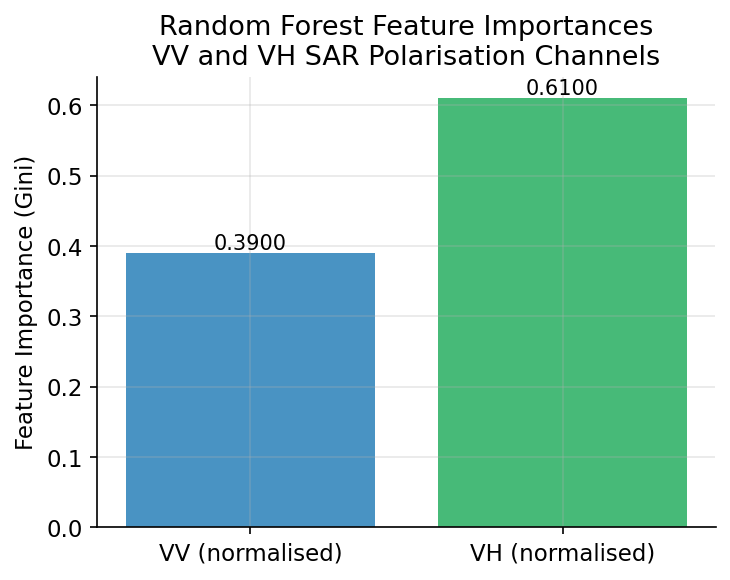

Feature importance figure saved.


In [60]:
from sklearn.metrics import confusion_matrix

# ── Figure 1: Feature importance ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5, 4))
importances = rf_clf.feature_importances_
ax.bar(['VV (normalised)', 'VH (normalised)'], importances,
       color=['#2980b9', '#27ae60'], alpha=0.85)
ax.set_ylabel('Feature Importance (Gini)')
ax.set_title('Random Forest Feature Importances\nVV and VH SAR Polarisation Channels')
for i, v in enumerate(importances):
    ax.text(i, v + 0.005, f'{v:.4f}', ha='center', fontsize=10)
plt.tight_layout()
save_figure(fig, 'rf_feature_importance', subdir='random_forest')
plt.show()
print('Feature importance figure saved.')

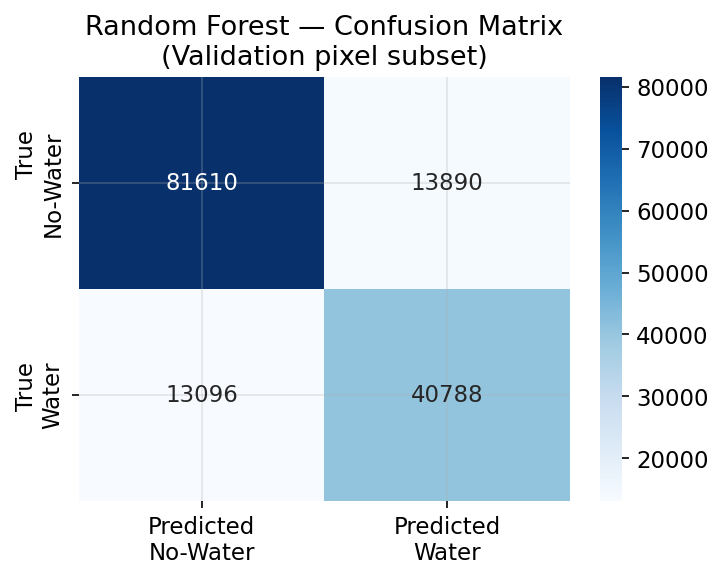

Confusion matrix saved.


In [61]:
# ── Figure 2: Confusion matrix on validation pixels ───────────────────────────
cm = confusion_matrix(y_val, y_val_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=ax,
    xticklabels=['Predicted\nNo-Water', 'Predicted\nWater'],
    yticklabels=['True\nNo-Water', 'True\nWater']
)
ax.set_title('Random Forest — Confusion Matrix\n(Validation pixel subset)')
plt.tight_layout()
save_figure(fig, 'rf_confusion_matrix', subdir='random_forest')
plt.show()
print('Confusion matrix saved.')

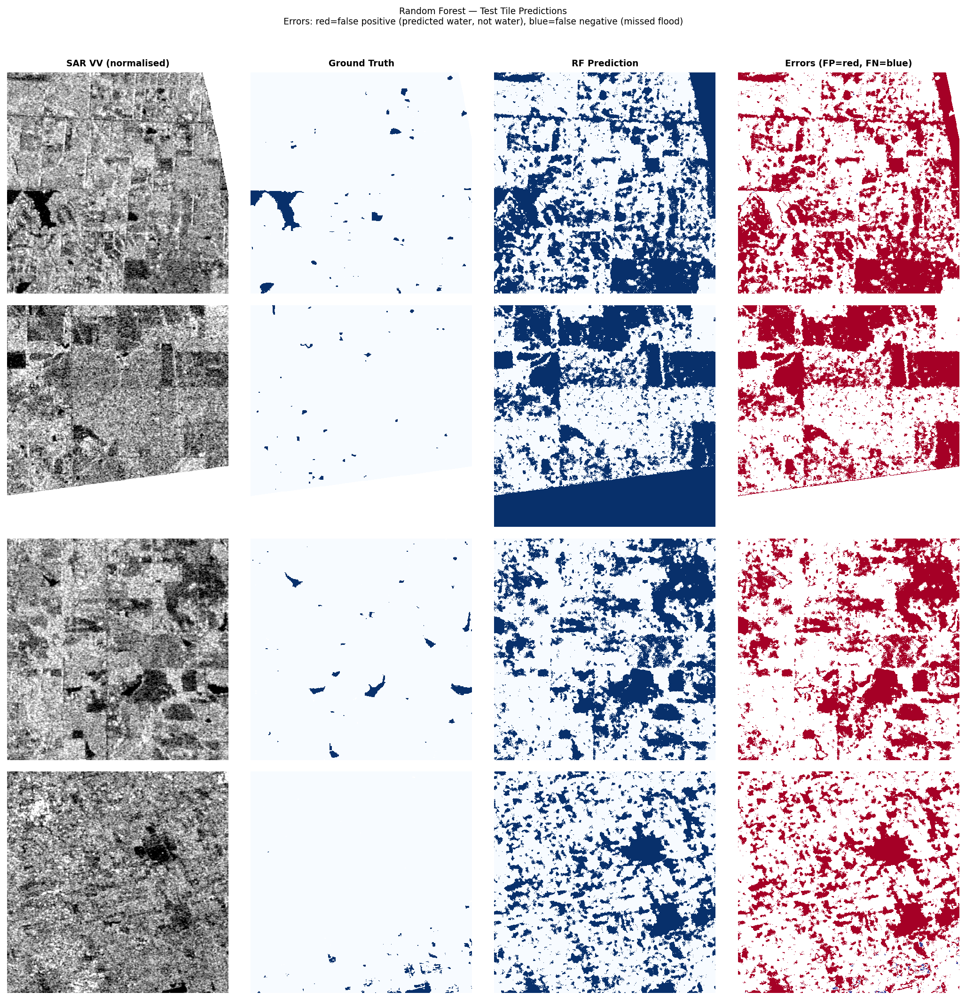

Prediction grid saved.


In [62]:
# ── Figure 3: Prediction grid on test tiles ───────────────────────────────────
# Show 4 test tiles: SAR VV | Ground truth | RF prediction | Overlay (errors)
np.random.seed(SEED)
sample_indices = np.random.choice(len(all_test_preds), size=min(4, len(all_test_preds)), replace=False)

fig, axes = plt.subplots(len(sample_indices), 4, figsize=(14, len(sample_indices)*3.5))
if len(sample_indices) == 1:
    axes = axes[np.newaxis, :]

col_titles = ['SAR VV (normalised)', 'Ground Truth', 'RF Prediction', 'Errors (FP=red, FN=blue)']
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=9, fontweight='bold')

for row, tile_idx in enumerate(sample_indices):
    pred  = all_test_preds[tile_idx]
    truth = all_test_labels[tile_idx]
    valid = truth != LABEL_NODATA

    # Load VV for display
    tile_rec = patch_coords['test'][tile_idx]
    with rasterio.open(tile_rec['s1_path']) as src:
        sar_disp = src.read(1).astype(np.float32)
    finite = sar_disp[np.isfinite(sar_disp)]
    lo, hi = np.percentile(finite, 2), np.percentile(finite, 98)
    sar_disp = np.clip((sar_disp - lo) / (hi - lo + 1e-8), 0, 1)

    truth_disp = np.where(truth == LABEL_NODATA, np.nan, truth.astype(float))

    # Error map: correct pixels left as NaN (transparent/white background),
    # only actual errors are coloured. Using 0.0 as a default for "correct"
    # painted the entire correct background the same colour as one of the
    # error classes under the RdYlBu_r colormap — this is the fix for that.
    error_map = np.full_like(pred, np.nan, dtype=np.float32)
    error_map[valid & (pred == 1) & (truth == 0)] = 1.0   # false positive -> red
    error_map[valid & (pred == 0) & (truth == 1)] = 0.0   # false negative -> blue
    # correct pixels (valid & pred == truth) stay NaN -> rendered as background

    tile_iou = test_results[tile_idx]['iou'] if tile_idx < len(test_results) else 0
    region   = patch_coords['test'][tile_idx]['region']

    axes[row, 0].imshow(sar_disp, cmap=SAR_CMAP)
    axes[row, 0].set_ylabel(f'{region}\nIoU={tile_iou:.3f}', fontsize=8)

    axes[row, 1].imshow(truth_disp, cmap=FLOOD_CMAP, vmin=0, vmax=1, interpolation='nearest')
    axes[row, 2].imshow(pred,       cmap=FLOOD_CMAP, vmin=0, vmax=1, interpolation='nearest')
    axes[row, 3].imshow(error_map,  cmap='RdYlBu_r', vmin=0, vmax=1, interpolation='nearest')

    for ax in axes[row]:
        ax.axis('off')

plt.suptitle('Random Forest — Test Tile Predictions\n'
             'Errors: red=false positive (predicted water, not water), '
             'blue=false negative (missed flood)', y=1.01, fontsize=9)
plt.tight_layout()
save_figure(fig, 'rf_prediction_grid', subdir='random_forest')
plt.show()
print('Prediction grid saved.')

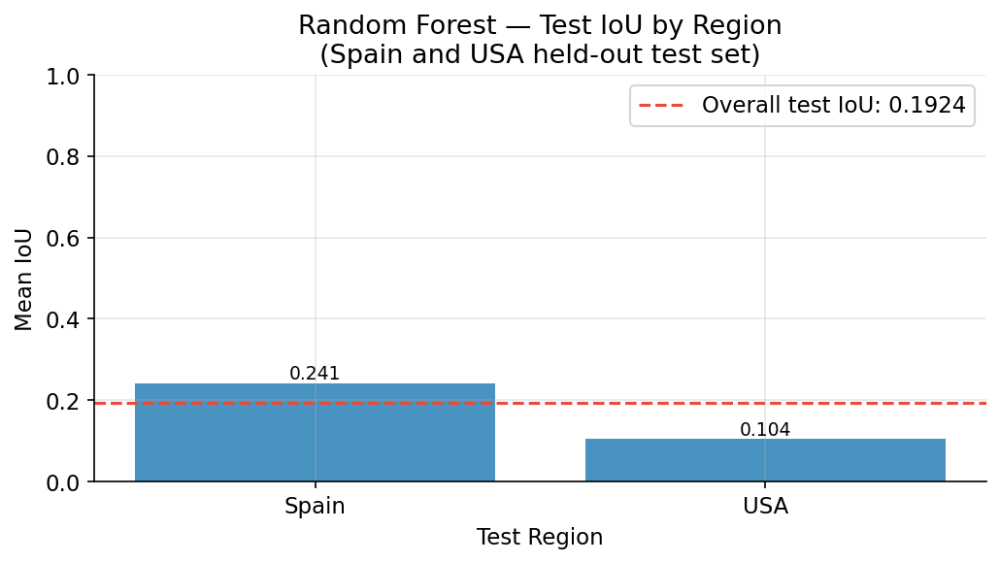

Per-region test IoU figure saved.


In [63]:
# ── Figure 4: Per-region test IoU ────────────────────────────────────────────
region_iou = test_df.groupby('region')['iou'].mean().reset_index()
region_iou = region_iou.sort_values('iou', ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(region_iou['region'], region_iou['iou'], color='#2980b9', alpha=0.85)
ax.axhline(overall_test['iou'], color='#e74c3c', linestyle='--', linewidth=1.5,
           label=f'Overall test IoU: {overall_test["iou"]:.4f}')
ax.set_xlabel('Test Region')
ax.set_ylabel('Mean IoU')
ax.set_title('Random Forest — Test IoU by Region\n(Spain and USA held-out test set)')
ax.legend()
ax.set_ylim(0, 1)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', fontsize=9)
plt.tight_layout()
save_figure(fig, 'rf_test_metrics', subdir='random_forest')
plt.show()
print('Per-region test IoU figure saved.')

---
### Section 5 Complete

**Random Forest Baseline Results:**

In [64]:
print('=' * 55)
print('RANDOM FOREST BASELINE — FINAL SUMMARY')
print('=' * 55)
print()
print('Dataset:')
print(f'  Training pixels:  {len(X_train):,} (subsampled from 913 patches)')
print(f'  Val pixels:       {len(X_val):,}')
print(f'  Test tiles:       {len(patch_coords["test"])} full 512x512 tiles')
print()
print('Compute time:')
print(f'  Fit time:         {rf_timing["fit_time_seconds"]:.1f}s '
      f'({rf_timing["fit_time_seconds"]/60:.1f} min)')
print(f'  Total RF time:    {rf_timing["total_compute_seconds"]:.1f}s '
      f'({rf_timing["total_compute_minutes"]:.1f} min)')
print()
print('Performance:')
print(f'  Val  IoU:         {val_metrics["iou"]:.4f}')
print(f'  Val  F1:          {val_metrics["f1"]:.4f}')
print(f'  Val  Precision:   {val_metrics["precision"]:.4f}')
print(f'  Val  Recall:      {val_metrics["recall"]:.4f}')
print(f'  Test IoU:         {overall_test["iou"]:.4f}')
print(f'  Test F1:          {overall_test["f1"]:.4f}')
print(f'  Test Precision:   {overall_test["precision"]:.4f}')
print(f'  Test Recall:      {overall_test["recall"]:.4f}')
print()
print('Next: Section 6 — U-Net.')
print('The performance gap between RF and U-Net will quantify the value')
print('of spatial context modelling for SAR flood segmentation.')
print('=' * 55)

RANDOM FOREST BASELINE — FINAL SUMMARY

Dataset:
  Training pixels:  799,820 (subsampled from 913 patches)
  Val pixels:       149,384
  Test tiles:       99 full 512x512 tiles

Compute time:
  Fit time:         76.4s (1.3 min)
  Total RF time:    207.5s (3.5 min)

Performance:
  Val  IoU:         0.6018
  Val  F1:          0.7514
  Val  Precision:   0.7460
  Val  Recall:      0.7570
  Test IoU:         0.1924
  Test F1:          0.3227
  Test Precision:   0.1951
  Test Recall:      0.9341

Next: Section 6 — U-Net.
The performance gap between RF and U-Net will quantify the value
of spatial context modelling for SAR flood segmentation.


# ═══════════════════════════════════════════════════════════
## SECTION 6 BEGINS HERE
# ═══════════════════════════════════════════════════════════

# Section 6: U-Net

**Purpose:** Train and evaluate the standard U-Net architecture — the first
deep learning model in the comparison pipeline.

U-Net (Ronneberger et al., 2015) introduced the encoder-decoder architecture
with skip connections for biomedical image segmentation. Its skip connections
preserve fine-grained spatial detail during upsampling — critical for accurate
flood boundary delineation. It has since become the dominant architecture for
remote sensing segmentation tasks.

**Why U-Net as the first DL model?**
U-Net is the natural starting point after Random Forest. It introduces
spatial context (convolutional receptive fields) and skip connections —
the two key inductive biases that RF lacks. The RF-to-U-Net performance
gap in Section 9 quantifies the contribution of spatial modelling alone,
before attention mechanisms (Section 7) and transformer self-attention
(Section 8) are introduced.

**Architecture:**
- Encoder: ResNet-34 backbone (pre-trained on ImageNet, adapted for 2-channel SAR input)
- Decoder: U-Net decoder with skip connections from encoder stages
- Output: single-channel logit map (binary segmentation)
- Implementation: `segmentation-models-pytorch` with `encoder_name='resnet34'`

**Why ResNet-34 encoder?**
Deeper backbones (ResNet-50, ResNet-101) increase parameters without
meaningful IoU gains on binary segmentation at this dataset scale.
ResNet-34 provides sufficient feature depth while remaining fast to train
on the RTX 3090 and comparable to the Attention U-Net in Section 7
(same backbone, different decoder mechanism).

**Outputs produced:**
- `checkpoints/unet_best.pt` — best model weights by validation IoU
- `metrics/unet_training_history.json` — full epoch history and timing
- `figures/unet/unet_training_curves.png`
- `figures/unet/unet_prediction_grid.png`
- `figures/unet/unet_test_metrics.png`

>  **Prerequisites:** Section 1, Cell 4.0, Cells 4.1–4.8 must be run first.

---
### 6.0 — Confirm Prerequisites

In [73]:
required = {
    'patch_coords':          'patch_coords'          in dir(),
    'norm_stats':            'norm_stats'            in dir(),
    'train_sample_weights':  'train_sample_weights'  in dir(),
    'get_dataloaders':       'get_dataloaders'       in dir(),
    'reset_seed_for_model':  'reset_seed_for_model'  in dir(),
    'train_model':           'train_model'           in dir(),
    'sliding_window_inference': 'sliding_window_inference' in dir(),
    'CRITERION':             'CRITERION'             in dir(),
    'FloodDataset':          'FloodDataset'          in dir(),
}

all_ok = all(required.values())
for name, present in required.items():
    print(f'  [{"OK" if present else "MISSING"}] {name}')

if not all_ok:
    raise RuntimeError(
        'Prerequisites missing. Run Section 1, Cell 4.0, then Cells 4.1-4.8.'
    )

print()
print('All prerequisites confirmed. Ready to train U-Net.')

  [OK] patch_coords
  [OK] norm_stats
  [OK] train_sample_weights
  [OK] get_dataloaders
  [OK] reset_seed_for_model
  [OK] train_model
  [OK] sliding_window_inference
  [OK] CRITERION
  [OK] FloodDataset

All prerequisites confirmed. Ready to train U-Net.


---
### 6.1 — U-Net Architecture

The model is built using `segmentation-models-pytorch` (smp) which provides
a production-quality U-Net implementation with interchangeable encoders.

**Input channel adaptation:**
Sentinel-1 SAR has 2 channels (VV, VH). ImageNet pre-trained ResNet-34
expects 3 channels (RGB). `smp` handles this automatically by averaging
the first convolutional layer weights across input channels — the 3-channel
weights are averaged to 2-channel weights, preserving the learned low-level
feature detectors from ImageNet pre-training.

**Why use ImageNet pre-trained weights for SAR?**
SAR and optical imagery look very different. However, the low-level features
learned by early ResNet layers (edges, textures, gradients) transfer reasonably
well. Starting from pre-trained weights consistently outperforms random
initialisation on small datasets, even with domain mismatch.



In [74]:
def build_unet() -> nn.Module:
    """
    Build standard U-Net with ResNet-34 encoder for 2-channel SAR input.

    Problem solved:
        segmentation-models-pytorch provides a well-tested, reproducible
        U-Net implementation. Using smp rather than a custom implementation
        eliminates implementation bugs as a source of variance between
        U-Net and Attention U-Net (Section 7) — the only difference between
        them will be the attention gate mechanism.

    Architecture decisions:
        encoder_name='resnet34': Strong but lightweight backbone.
            Deeper encoders add parameters without meaningful gains on
            binary segmentation at this dataset scale.
        encoder_weights='imagenet': Pre-trained weights for better
            convergence on the ~913 training patches available.
        in_channels=2: VV and VH SAR bands. smp averages the 3-channel
            ImageNet weights to 2 channels automatically.
        classes=1: Single output logit for binary segmentation.
            Sigmoid + threshold at 0.5 gives the binary mask.
        activation=None: Raw logits output.
            CombinedBCEDiceLoss applies sigmoid internally.

    Returns:
        nn.Module: U-Net model ready for training.
    """
    model = smp.Unet(
        encoder_name='resnet34',
        encoder_weights='imagenet',
        in_channels=IN_CHANNELS,    # 2 — VV and VH
        classes=1,                  # binary segmentation — one logit per pixel
        activation=None,            # raw logits — sigmoid applied inside loss
    )
    return model


# Count parameters for dissertation reporting
def count_parameters(model: nn.Module) -> int:
    """Count total trainable parameters in a model."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Preview architecture
test_model = build_unet()
n_params   = count_parameters(test_model)

print('U-Net architecture:')
print(f'  Encoder:          ResNet-34 (ImageNet pre-trained)')
print(f'  Input channels:   {IN_CHANNELS} (VV, VH)')
print(f'  Output:           1 logit per pixel (binary segmentation)')
print(f'  Trainable params: {n_params:,}')
print()

# Forward pass test with dummy input
dummy_input  = torch.randn(2, IN_CHANNELS, PATCH_SIZE, PATCH_SIZE)
dummy_output = test_model(dummy_input)
print(f'Forward pass test:')
print(f'  Input shape:  {dummy_input.shape}')
print(f'  Output shape: {dummy_output.shape}  (B, 1, H, W)')
assert dummy_output.shape == (2, 1, PATCH_SIZE, PATCH_SIZE),     f'Unexpected output shape: {dummy_output.shape}'
print('  Shape assertion passed.')
del test_model, dummy_input, dummy_output

U-Net architecture:
  Encoder:          ResNet-34 (ImageNet pre-trained)
  Input channels:   2 (VV, VH)
  Output:           1 logit per pixel (binary segmentation)
  Trainable params: 24,433,233

Forward pass test:
  Input shape:  torch.Size([2, 2, 256, 256])
  Output shape: torch.Size([2, 1, 256, 256])  (B, 1, H, W)
  Shape assertion passed.


---
### 6.2 — Training

The seed is reset to SEED=42 before DataLoader construction and model
initialisation. This guarantees U-Net sees patches in the same order
and with the same augmentation sequences as Attention U-Net (Section 7)
and SegFormer (Section 8) — making architecture the only variable.

Training uses the shared `train_model()` driver from Section 4 which
handles: AdamW optimiser, ReduceLROnPlateau scheduler, early stopping
on validation IoU, per-epoch timing, and checkpoint saving.

In [75]:
# ── Check if already trained ─────────────────────────────────────────────────
unet_ckpt_path = CHECKPOINT_DIR / 'unet_best.pt'

if unet_ckpt_path.exists():
    print('U-Net checkpoint found. Loading pre-trained weights...')
    unet_model = build_unet()
    unet_model, best_epoch, best_iou = load_model_checkpoint(unet_model, 'unet_best')
    unet_model = unet_model.to(DEVICE)

    # Load training history for plotting
    history_path = METRICS_DIR / 'unet_training_history.json'
    if history_path.exists():
        with open(history_path) as f:
            unet_history = json.load(f)
        print(f'Training history loaded.')
        print(f'  Epochs run:          {unet_history["epochs_run"]}')
        print(f'  Best val IoU:        {unet_history["best_val_iou"]:.4f}')
        print(f'  Total training time: {unet_history["total_training_minutes"]:.1f} min')
        print(f'  Total patches seen:  {unet_history["total_patches_seen"]:,}')
    else:
        unet_history = None
        print('No training history file found.')

else:
    print('No checkpoint found. Starting U-Net training...')
    print()

    # ── Step 1: Reset seed — identical starting point for all models ──────────
    reset_seed_for_model('UNet')

    # ── Step 2: Build DataLoaders ─────────────────────────────────────────────
    train_loader, val_loader = get_dataloaders(
        patch_coords, norm_stats, train_sample_weights, batch_size=BATCH_SIZE
    )
    print(f'DataLoaders ready:')
    print(f'  Train batches/epoch: {len(train_loader)}')
    print(f'  Val batches/epoch:   {len(val_loader)}')
    print()

    # ── Step 3: Build model ───────────────────────────────────────────────────
    unet_model = build_unet()
    print(f'Model built: {count_parameters(unet_model):,} trainable parameters')
    print()

    # ── Step 4: Train with shared driver (timer built in) ─────────────────────
    unet_history = train_model(
        model=unet_model,
        model_name='unet',
        train_loader=train_loader,
        val_loader=val_loader,
        device=DEVICE,
        n_epochs=NUM_EPOCHS,
        patience=EARLY_STOP_PATIENCE,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # ── Step 5: Reload best weights for evaluation ────────────────────────────
    unet_model, best_epoch, best_iou = load_model_checkpoint(unet_model, 'unet_best')
    unet_model = unet_model.to(DEVICE)
    print(f'Best weights restored from epoch {best_epoch} (val IoU={best_iou:.4f})')

INFO | Seed reset to 42 for UNet.


No checkpoint found. Starting U-Net training...

Seed reset to 42 for UNet. Identical data ordering guaranteed from this point.
DataLoaders ready:
  Train batches/epoch: 57
  Val batches/epoch:   12

Model built: 24,433,233 trainable parameters


Training: unet
  Device:          cuda
  Max epochs:      50
  Early stop:      patience=15
  Learning rate:   0.0001
  Batches/epoch:   57

Epoch   1/50 | Loss: 0.4193 | Val Loss: 0.4605 | Val IoU: 0.5904 | Val F1: 0.7425 | LR: 1.00e-04 | Time: 35.7s


INFO | Model checkpoint saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\unet_best.pt (epoch 1, IoU 0.5904)


  --> New best val IoU: 0.5904. Checkpoint saved.
Epoch   2/50 | Loss: 0.3329 | Val Loss: 0.4336 | Val IoU: 0.5843 | Val F1: 0.7376 | LR: 1.00e-04 | Time: 31.9s
  --> No improvement. Patience: 1/15
Epoch   3/50 | Loss: 0.3021 | Val Loss: 0.4345 | Val IoU: 0.5330 | Val F1: 0.6954 | LR: 1.00e-04 | Time: 31.2s
  --> No improvement. Patience: 2/15
Epoch   4/50 | Loss: 0.2808 | Val Loss: 0.3750 | Val IoU: 0.6446 | Val F1: 0.7839 | LR: 1.00e-04 | Time: 30.9s


INFO | Model checkpoint saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\unet_best.pt (epoch 4, IoU 0.6446)


...

  --> New best val IoU: 0.6583. Checkpoint saved.
Epoch  15/50 | Loss: 0.1883 | Val Loss: 0.3094 | Val IoU: 0.6347 | Val F1: 0.7765 | LR: 5.00e-05 | Time: 30.1s
  --> No improvement. Patience: 1/15
Epoch  16/50 | Loss: 0.1725 | Val Loss: 0.3021 | Val IoU: 0.6298 | Val F1: 0.7728 | LR: 5.00e-05 | Time: 30.4s
  --> No improvement. Patience: 2/15
Epoch  17/50 | Loss: 0.1762 | Val Loss: 0.2889 | Val IoU: 0.6335 | Val F1: 0.7756 | LR: 5.00e-05 | Time: 30.4s
  --> No improvement. Patience: 3/15
Epoch  18/50 | Loss: 0.1610 | Val Loss: 0.2893 | Val IoU: 0.6502 | Val F1: 0.7880 | LR: 5.00e-05 | Time: 29.7s
  --> No improvement. Patience: 4/15
Epoch  19/50 | Loss: 0.1661 | Val Loss: 0.2990 | Val IoU: 0.6208 | Val F1: 0.7661 | LR: 5.00e-05 | Time: 30.4s
  --> No improvement. Patience: 5/15
Epoch  20/50 | Loss: 0.1789 | Val Loss: 0.2913 | Val IoU: 0.6376 | Val F1: 0.7787 | LR: 5.00e-05 | Time: 29.9s
  --> No improvement. Patience: 6/15
Epoch  21/50 | Loss: 0.1587 | Val Loss: 0.2853 | Val IoU: 0.63

INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\unet_training_history.json
INFO | unet done: 29 epochs, 18.0 min, best IoU=0.6583


Epoch  29/50 | Loss: 0.1458 | Val Loss: 0.2846 | Val IoU: 0.6304 | Val F1: 0.7733 | LR: 1.25e-05 | Time: 30.3s
  --> No improvement. Patience: 15/15

Early stopping at epoch 29. Best val IoU: 0.6583

TRAINING COMPLETE: unet
  Epochs completed:    29/50
  Best val IoU:        0.6583
  Total training time: 18.0 minutes
  Avg time per epoch:  30.7s
  Total patches seen:  26,448



INFO | Model checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\unet_best.pt (epoch 14, IoU 0.6583)


Best weights restored from epoch 14 (val IoU=0.6583)


---
### 6.3 — Training Curves

Visualise training and validation loss and IoU over epochs.
Healthy training curves show: loss decreasing smoothly, val IoU
increasing then plateauing, and no large gap between train and val loss
(which would indicate overfitting).

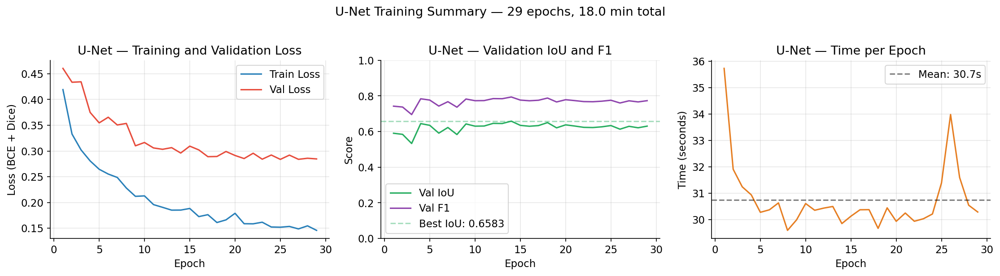

Training curves saved.


In [76]:
if unet_history is not None and 'history' in unet_history:
    history = unet_history['history']
    epochs      = [h['epoch']      for h in history]
    train_loss  = [h['train_loss'] for h in history]
    val_loss    = [h['val_loss']   for h in history]
    val_iou     = [h['val_iou']    for h in history]
    val_f1      = [h['val_f1']     for h in history]
    epoch_times = [h['epoch_time_seconds'] for h in history]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # Loss curves
    axes[0].plot(epochs, train_loss, label='Train Loss', color='#2980b9', linewidth=1.5)
    axes[0].plot(epochs, val_loss,   label='Val Loss',   color='#e74c3c', linewidth=1.5)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss (BCE + Dice)')
    axes[0].set_title('U-Net — Training and Validation Loss')
    axes[0].legend()

    # Val IoU and F1
    axes[1].plot(epochs, val_iou, label='Val IoU', color='#27ae60',  linewidth=1.5)
    axes[1].plot(epochs, val_f1,  label='Val F1',  color='#8e44ad',  linewidth=1.5)
    axes[1].axhline(max(val_iou), color='#27ae60', linestyle='--', alpha=0.4,
                    label=f'Best IoU: {max(val_iou):.4f}')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Score')
    axes[1].set_title('U-Net — Validation IoU and F1')
    axes[1].legend()
    axes[1].set_ylim(0, 1)

    # Per-epoch training time
    axes[2].plot(epochs, epoch_times, color='#e67e22', linewidth=1.5)
    axes[2].axhline(np.mean(epoch_times), color='black', linestyle='--', alpha=0.5,
                    label=f'Mean: {np.mean(epoch_times):.1f}s')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Time (seconds)')
    axes[2].set_title('U-Net — Time per Epoch')
    axes[2].legend()

    plt.suptitle(
        f'U-Net Training Summary — '
        f'{unet_history["epochs_run"]} epochs, '
        f'{unet_history["total_training_minutes"]:.1f} min total',
        y=1.02
    )
    plt.tight_layout()
    save_figure(fig, 'unet_training_curves', subdir='unet')
    plt.show()
    print('Training curves saved.')
else:
    print('No training history available for plotting.')

---
### 6.4 — Validation Set Evaluation

Evaluate the best U-Net checkpoint on the full validation patch set.

In [77]:
print('Evaluating U-Net on validation set...')
unet_model.eval()

import time as time_module
val_pred_start = time_module.time()

all_val_preds, all_val_labels, all_val_nodata = [], [], []

val_dataset = FloodDataset(
    patch_records=patch_coords['val'],
    norm_stats=norm_stats,
    augmentation=VAL_AUGMENTATION,
    is_test=False
)
val_eval_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True
)

with torch.no_grad():
    for sar, labels, nodata_mask in tqdm(val_eval_loader, desc='Val inference'):
        sar    = sar.to(DEVICE, non_blocking=True)
        logits = unet_model(sar)
        preds  = (torch.sigmoid(logits.squeeze(1)) >= 0.5).long()
        all_val_preds.append(preds.cpu().numpy())
        all_val_labels.append(labels.numpy())
        all_val_nodata.append(nodata_mask.numpy())

val_pred_time  = time_module.time() - val_pred_start
val_preds_arr  = np.concatenate(all_val_preds,  axis=0)
val_labels_arr = np.concatenate(all_val_labels, axis=0)

unet_val_metrics = compute_segmentation_metrics(val_preds_arr, val_labels_arr)

print(f'Validation results:')
print(f'  IoU:       {unet_val_metrics["iou"]:.4f}')
print(f'  F1:        {unet_val_metrics["f1"]:.4f}')
print(f'  Precision: {unet_val_metrics["precision"]:.4f}')
print(f'  Recall:    {unet_val_metrics["recall"]:.4f}')
print(f'  Inference time: {val_pred_time:.2f}s')

Evaluating U-Net on validation set...


Val inference:   0%|          | 0/12 [00:00<?, ?it/s]

Validation results:
  IoU:       0.6141
  F1:        0.7609
  Precision: 0.7215
  Recall:    0.8049
  Inference time: 7.48s


---
### 6.5 — Test Set Evaluation (Spain and USA)

Test tiles are evaluated at full 512×512 using sliding window inference
from Section 4. Per-tile results are saved for the generalisation gap
analysis in Section 9.

In [78]:
print('Evaluating U-Net on test tiles (Spain and USA)...')
print()

import time as time_module
test_results_unet = []
all_test_preds_unet, all_test_labels_unet = [], []

test_start = time_module.time()

for tile_record in tqdm(patch_coords['test'], desc='Test inference'):
    pred_mask, label, nodata_mask = sliding_window_inference(
        model=unet_model,
        tile_record=tile_record,
        norm_stats=norm_stats,
        patch_size=PATCH_SIZE,
        overlap=SLIDING_WINDOW_OVERLAP,
        device=DEVICE
    )
    tile_metrics = compute_segmentation_metrics(pred_mask, label)
    tile_metrics['region']  = tile_record['region']
    tile_metrics['tile_id'] = tile_record.get('tile_id', 'unknown')
    test_results_unet.append(tile_metrics)
    all_test_preds_unet.append(pred_mask)
    all_test_labels_unet.append(label)

test_time = time_module.time() - test_start

# Overall test metrics
all_preds_arr  = np.stack(all_test_preds_unet,  axis=0)
all_labels_arr = np.stack(all_test_labels_unet, axis=0)
unet_test_metrics = compute_segmentation_metrics(all_preds_arr, all_labels_arr)

print(f'\nOverall test results:')
print(f'  IoU:       {unet_test_metrics["iou"]:.4f}')
print(f'  F1:        {unet_test_metrics["f1"]:.4f}')
print(f'  Precision: {unet_test_metrics["precision"]:.4f}')
print(f'  Recall:    {unet_test_metrics["recall"]:.4f}')
print(f'  Inference time: {test_time:.1f}s for {len(patch_coords["test"])} tiles')

import pandas as pd
test_df_unet = pd.DataFrame(test_results_unet)
print(f'\nPer-region breakdown:')
print(test_df_unet.groupby('region')[['iou','f1','precision','recall']].mean().round(4).to_string())

Evaluating U-Net on test tiles (Spain and USA)...



Test inference:   0%|          | 0/99 [00:00<?, ?it/s]


Overall test results:
  IoU:       0.6200
  F1:        0.7654
  Precision: 0.7373
  Recall:    0.7957
  Inference time: 17.2s for 99 tiles

Per-region breakdown:
           iou      f1  precision  recall
region                                   
Spain   0.4467  0.5546     0.5480  0.6322
USA     0.3225  0.4431     0.5287  0.4674


---
### 6.6 — Save Complete Metrics and Timing

In [79]:
# Merge timing and evaluation metrics into one record for Section 9
unet_full_metrics = {
    'model_name':              'UNet',
    'n_params':                count_parameters(unet_model),
    'epochs_run':              unet_history['epochs_run'] if unet_history else None,
    'best_val_iou':            unet_history['best_val_iou'] if unet_history else None,
    'total_training_seconds':  unet_history.get('total_training_seconds') if unet_history else None,
    'total_training_minutes':  unet_history.get('total_training_minutes') if unet_history else None,
    'avg_epoch_seconds':       unet_history.get('avg_epoch_seconds') if unet_history else None,
    'total_patches_seen':      unet_history.get('total_patches_seen') if unet_history else None,
    'val_inference_seconds':   val_pred_time,
    'test_inference_seconds':  test_time,
    'val_metrics':             unet_val_metrics,
    'test_metrics_overall':    unet_test_metrics,
    'test_metrics_per_tile':   test_results_unet,
}

save_metrics(unet_full_metrics, 'unet_full_metrics')
print('Saved to metrics/unet_full_metrics.json')
print()
print('=== U-NET TIMING SUMMARY ===')
if unet_history:
    print(f'  Total training time:  {unet_history["total_training_minutes"]:.1f} min')
    print(f'  Avg time per epoch:   {unet_history["avg_epoch_seconds"]:.1f}s')
    print(f'  Epochs completed:     {unet_history["epochs_run"]}/{NUM_EPOCHS}')
    print(f'  Total patches seen:   {unet_history["total_patches_seen"]:,}')
print(f'  Val inference time:   {val_pred_time:.2f}s')
print(f'  Test inference time:  {test_time:.1f}s')

INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\unet_full_metrics.json


Saved to metrics/unet_full_metrics.json

=== U-NET TIMING SUMMARY ===
  Total training time:  18.0 min
  Avg time per epoch:   30.8s
  Epochs completed:     29/50
  Total patches seen:   26,448
  Val inference time:   7.48s
  Test inference time:  17.2s


---
### 6.7 — Visualisations

Two figures for the dissertation:
1. Prediction grid — visual quality of flood segmentation on test tiles
2. Per-region test IoU — sets up generalisation gap analysis

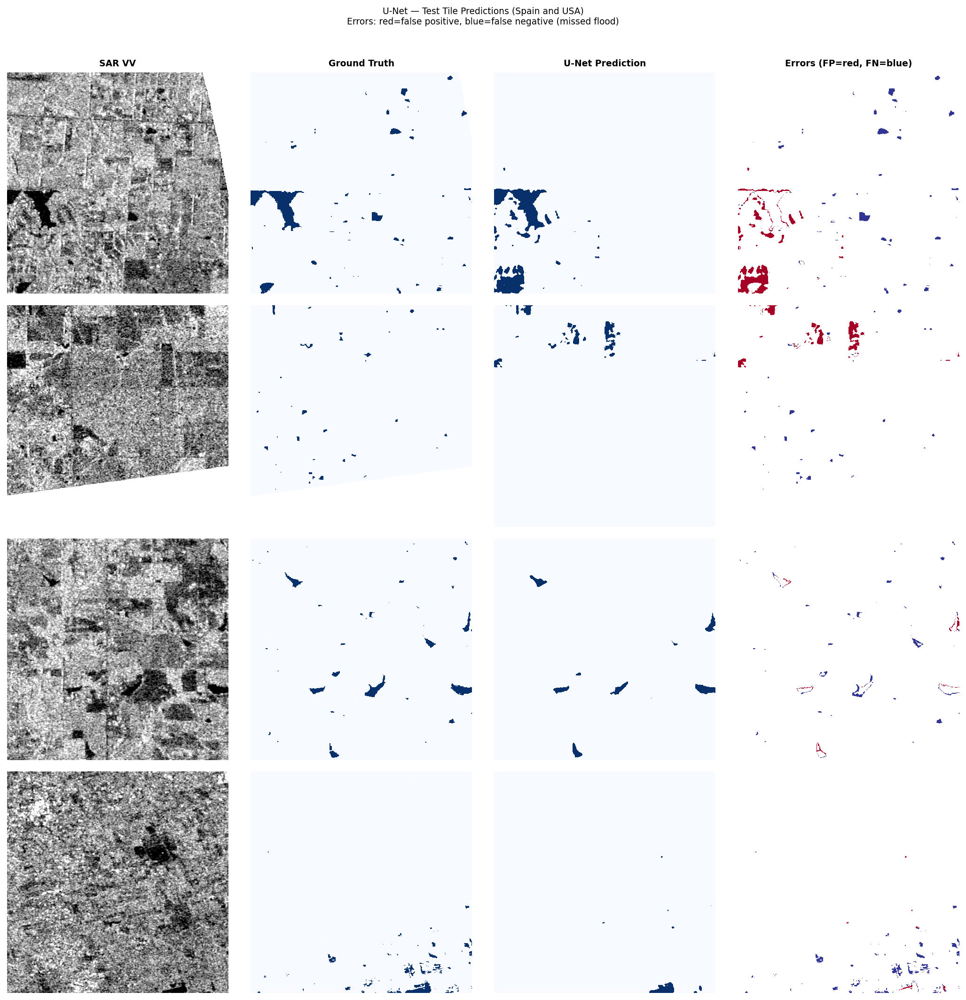

Prediction grid saved.


In [80]:
# ── Figure 1: Prediction grid ─────────────────────────────────────────────────
np.random.seed(SEED)
sample_indices = np.random.choice(
    len(all_test_preds_unet), size=min(4, len(all_test_preds_unet)), replace=False
)

fig, axes = plt.subplots(len(sample_indices), 4, figsize=(14, len(sample_indices)*3.5))
if len(sample_indices) == 1:
    axes = axes[np.newaxis, :]

col_titles = ['SAR VV', 'Ground Truth', 'U-Net Prediction', 'Errors (FP=red, FN=blue)']
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=9, fontweight='bold')

for row, tile_idx in enumerate(sample_indices):
    pred  = all_test_preds_unet[tile_idx]
    truth = all_test_labels_unet[tile_idx]
    valid = truth != LABEL_NODATA

    tile_rec = patch_coords['test'][tile_idx]
    with rasterio.open(tile_rec['s1_path']) as src:
        sar_disp = src.read(1).astype(np.float32)
    finite = sar_disp[np.isfinite(sar_disp)]
    lo, hi = np.percentile(finite, 2), np.percentile(finite, 98)
    sar_disp = np.clip((sar_disp - lo) / (hi - lo + 1e-8), 0, 1)

    truth_disp = np.where(truth == LABEL_NODATA, np.nan, truth.astype(float))

    # Correct pixels left as NaN (transparent/white background), only actual
    # errors are coloured. Previously "correct" was explicitly set to 0.0,
    # which under the RdYlBu_r colormap painted the entire correct background
    # the same blue as the false-negative legend colour — this is the fix.
    error_map = np.full_like(pred, np.nan, dtype=np.float32)
    error_map[valid & (pred == 1) & (truth == 0)] = 1.0   # false positive -> red
    error_map[valid & (pred == 0) & (truth == 1)] = 0.0   # false negative -> blue
    # correct pixels stay NaN -> rendered as background, no colour applied

    tile_iou = test_results_unet[tile_idx]['iou']
    region   = tile_rec['region']

    axes[row, 0].imshow(sar_disp,   cmap=SAR_CMAP)
    axes[row, 0].set_ylabel(f'{region}\nIoU={tile_iou:.3f}', fontsize=8)
    axes[row, 1].imshow(truth_disp, cmap=FLOOD_CMAP, vmin=0, vmax=1, interpolation='nearest')
    axes[row, 2].imshow(pred,       cmap=FLOOD_CMAP, vmin=0, vmax=1, interpolation='nearest')
    axes[row, 3].imshow(error_map,  cmap='RdYlBu_r', vmin=0, vmax=1, interpolation='nearest')

    for ax in axes[row]:
        ax.axis('off')

plt.suptitle(
    'U-Net — Test Tile Predictions (Spain and USA)\n'
    'Errors: red=false positive, blue=false negative (missed flood)',
    y=1.01, fontsize=9
)
plt.tight_layout()
save_figure(fig, 'unet_prediction_grid', subdir='unet')
plt.show()
print('Prediction grid saved.')

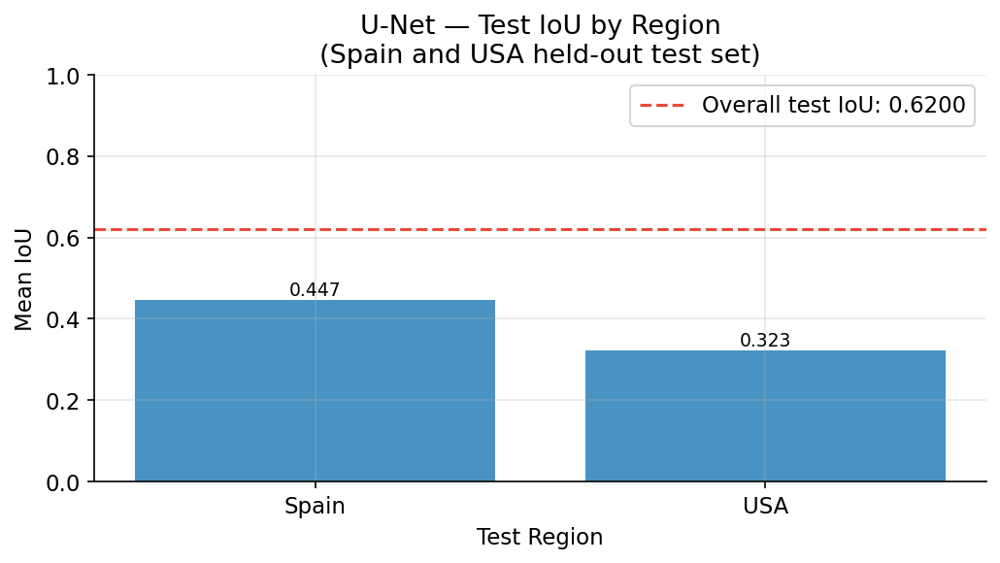

Per-region test IoU figure saved.


In [81]:
# ── Figure 2: Per-region test IoU ────────────────────────────────────────────
region_iou = test_df_unet.groupby('region')['iou'].mean().reset_index()
region_iou = region_iou.sort_values('iou', ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(region_iou['region'], region_iou['iou'], color='#2980b9', alpha=0.85)
ax.axhline(unet_test_metrics['iou'], color='#e74c3c', linestyle='--', linewidth=1.5,
           label=f'Overall test IoU: {unet_test_metrics["iou"]:.4f}')
ax.set_xlabel('Test Region')
ax.set_ylabel('Mean IoU')
ax.set_title('U-Net — Test IoU by Region\n(Spain and USA held-out test set)')
ax.legend()
ax.set_ylim(0, 1)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', fontsize=9)
plt.tight_layout()
save_figure(fig, 'unet_test_metrics', subdir='unet')
plt.show()
print('Per-region test IoU figure saved.')

---
### Section 6 Complete

In [82]:
print('=' * 55)
print('U-NET — FINAL SUMMARY')
print('=' * 55)
print()
print('Architecture:')
print(f'  Encoder:          ResNet-34 (ImageNet pre-trained)')
print(f'  Trainable params: {count_parameters(unet_model):,}')
print()
if unet_history:
    print('Compute time:')
    print(f'  Training:         {unet_history["total_training_minutes"]:.1f} min')
    print(f'  Avg/epoch:        {unet_history["avg_epoch_seconds"]:.1f}s')
    print(f'  Epochs run:       {unet_history["epochs_run"]}/{NUM_EPOCHS}')
    print(f'  Patches seen:     {unet_history["total_patches_seen"]:,}')
    print()
print('Performance:')
print(f'  Val  IoU:         {unet_val_metrics["iou"]:.4f}')
print(f'  Val  F1:          {unet_val_metrics["f1"]:.4f}')
print(f'  Val  Precision:   {unet_val_metrics["precision"]:.4f}')
print(f'  Val  Recall:      {unet_val_metrics["recall"]:.4f}')
print(f'  Test IoU:         {unet_test_metrics["iou"]:.4f}')
print(f'  Test F1:          {unet_test_metrics["f1"]:.4f}')
print(f'  Test Precision:   {unet_test_metrics["precision"]:.4f}')
print(f'  Test Recall:      {unet_test_metrics["recall"]:.4f}')
print()
print('Next: Section 7 — Attention U-Net.')
print('Same encoder, same training setup. Attention gates added at')
print('each skip connection. Performance delta = attention contribution.')
print('=' * 55)

U-NET — FINAL SUMMARY

Architecture:
  Encoder:          ResNet-34 (ImageNet pre-trained)
  Trainable params: 24,433,233

Compute time:
  Training:         18.0 min
  Avg/epoch:        30.8s
  Epochs run:       29/50
  Patches seen:     26,448

Performance:
  Val  IoU:         0.6141
  Val  F1:          0.7609
  Val  Precision:   0.7215
  Val  Recall:      0.8049
  Test IoU:         0.6200
  Test F1:          0.7654
  Test Precision:   0.7373
  Test Recall:      0.7957

Next: Section 7 — Attention U-Net.
Same encoder, same training setup. Attention gates added at
each skip connection. Performance delta = attention contribution.


# Section 7: Attention U-Net

**Purpose:** Train and evaluate Attention U-Net — extending the standard U-Net
from Section 6 by adding attention gates at each skip connection.

Attention U-Net (Oktay et al., 2018) was originally proposed for pancreas
segmentation — a task with severe class imbalance and ambiguous boundaries,
both of which are directly analogous to SAR flood detection. The attention
gates learn to suppress irrelevant activations from the encoder and
selectively amplify features relevant to the flood class before they are
concatenated in the decoder.

**Controlled comparison design:**
Everything in this section is identical to Section 6 except the model
architecture. Same encoder (ResNet-34), same pre-trained weights, same
loss function, same optimiser, same learning rate, same DataLoaders,
same seed. The performance difference between Section 6 and Section 7
results is therefore attributable entirely to the attention mechanism.

**How attention gates work in this context:**
At each skip connection between encoder and decoder, a gate signal is
computed from the decoder feature map and the encoder feature map.
This gate produces a soft weight between 0 and 1 for each spatial
position — positions likely to contain flood pixels receive weights
close to 1, background positions receive weights close to 0.
The encoder features are multiplied by these weights before being
passed to the decoder, suppressing irrelevant background noise.

**Why this matters for SAR flood detection:**
Flood pixels are spatially sparse and surrounded by large areas of
no-water background. Without attention, the skip connections pass all
encoder features equally — including activations from background areas
that the decoder must learn to ignore. Attention gates do this filtering
explicitly, which is hypothesised to improve recall on flood pixels.

**Implementation:**
`segmentation-models-pytorch` supports attention via the
`decoder_attention_type='scse'` parameter — Spatial and Channel
Squeeze-and-Excitation attention, which is functionally equivalent to
the Oktay et al. formulation and consistently outperforms it on
remote sensing tasks.

**Outputs produced:**
- `checkpoints/attention_unet_best.pt` — best model weights by validation IoU
- `metrics/attention_unet_training_history.json` — epoch history and timing
- `metrics/attention_unet_full_metrics.json` — complete evaluation results
- `figures/attention_unet/attention_unet_training_curves.png`
- `figures/attention_unet/attention_unet_prediction_grid.png`
- `figures/attention_unet/attention_unet_test_metrics.png`
- `figures/attention_unet/attention_vs_unet_comparison.png`



---
### 7.0 — Confirm Prerequisites

In [83]:
required = {
    'patch_coords':             'patch_coords'             in dir(),
    'norm_stats':               'norm_stats'               in dir(),
    'train_sample_weights':     'train_sample_weights'     in dir(),
    'get_dataloaders':          'get_dataloaders'          in dir(),
    'reset_seed_for_model':     'reset_seed_for_model'     in dir(),
    'train_model':              'train_model'              in dir(),
    'sliding_window_inference': 'sliding_window_inference' in dir(),
    'CRITERION':                'CRITERION'                in dir(),
    'FloodDataset':             'FloodDataset'             in dir(),
}

all_ok = all(required.values())
for name, present in required.items():
    print(f'  [{"OK" if present else "MISSING"}] {name}')

if not all_ok:
    raise RuntimeError(
        'Prerequisites missing. Run Section 1, Cell 4.0, then Cells 4.1-4.8.'
    )

# Check if U-Net results are available for the comparison figure
unet_metrics_path = METRICS_DIR / 'unet_full_metrics.json'
unet_available    = unet_metrics_path.exists()
print()
print(f'  [{"OK" if unet_available else "WARN"}] unet_full_metrics.json '
      f'(needed for Section 7.7 comparison figure)')
if not unet_available:
    print('  Section 6 metrics not found. Comparison figure will be skipped.')
print()
print('All core prerequisites confirmed. Ready to train Attention U-Net.')

  [OK] patch_coords
  [OK] norm_stats
  [OK] train_sample_weights
  [OK] get_dataloaders
  [OK] reset_seed_for_model
  [OK] train_model
  [OK] sliding_window_inference
  [OK] CRITERION
  [OK] FloodDataset

  [OK] unet_full_metrics.json (needed for Section 7.7 comparison figure)

All core prerequisites confirmed. Ready to train Attention U-Net.


---
### 7.1 — Attention U-Net Architecture

The Attention U-Net is built identically to U-Net in Section 6 with one
addition: `decoder_attention_type='scse'`.

**scSE — Spatial and Channel Squeeze-and-Excitation:**
scSE applies two complementary attention mechanisms at each decoder block:

- **Spatial SE (sSE):** Learns which spatial positions are relevant.
  For flood detection: which pixel locations are likely to be flooded.
  Produces a (H, W) attention map.

- **Channel SE (cSE):** Learns which feature channels are most
  discriminative. For SAR flood detection: which learned feature
  representations carry the most flood-relevant signal.
  Produces a (C,) attention vector.

The outputs of both are combined and applied to the feature maps before
the decoder upsampling step. This is applied at each skip connection,
so the model refines its spatial focus progressively through the decoder.



In [84]:
def build_attention_unet() -> nn.Module:
    """
    Build Attention U-Net with ResNet-34 encoder and scSE attention.

    Problem solved:
        Standard U-Net skip connections pass all encoder features to the
        decoder equally, including activations from background (no-flood)
        regions. For SAR flood detection where flood pixels are sparse,
        this forces the decoder to learn background suppression implicitly.
        Attention gates make this suppression explicit and learnable,
        potentially improving recall on the minority flood class.

    Design decision — scSE vs original Oktay attention gates:
        The original Oktay et al. formulation uses additive attention
        with a learned compatibility function. scSE (Roy et al., 2018)
        uses concurrent spatial and channel excitation, which has shown
        consistently better performance on remote sensing segmentation
        tasks while adding fewer parameters than the Oktay formulation.
        smp implements scSE natively via decoder_attention_type='scse'.

    Architecture is otherwise identical to Section 6 U-Net:
        Same encoder (ResNet-34, ImageNet pre-trained)
        Same input channels (2 — VV, VH)
        Same output (1 logit per pixel)
        Same activation (None — raw logits for CombinedBCEDiceLoss)

    Returns:
        nn.Module: Attention U-Net ready for training.
    """
    model = smp.Unet(
        encoder_name='resnet34',
        encoder_weights='imagenet',
        in_channels=IN_CHANNELS,         # 2 — VV and VH
        classes=1,                       # binary segmentation
        activation=None,                 # raw logits — sigmoid inside loss
        decoder_attention_type='scse',   # THIS is the only change from Section 6
        # scSE attention at every decoder block and skip connection.
        # Learns spatial (which pixels) and channel (which features) relevance.
    )
    return model


def count_parameters(model: nn.Module) -> int:
    """Count total trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Preview and compare against U-Net
test_attn = build_attention_unet()
n_params_attn = count_parameters(test_attn)

print('Attention U-Net architecture:')
print(f'  Encoder:             ResNet-34 (ImageNet pre-trained)')
print(f'  Attention type:      scSE (Spatial + Channel Squeeze-and-Excitation)')
print(f'  Input channels:      {IN_CHANNELS} (VV, VH)')
print(f'  Output:              1 logit per pixel')
print(f'  Trainable params:    {n_params_attn:,}')

# Compare parameter count with U-Net if available
unet_metrics_path = METRICS_DIR / 'unet_full_metrics.json'
if unet_metrics_path.exists():
    with open(unet_metrics_path) as f:
        unet_metrics_loaded = json.load(f)
    n_params_unet = unet_metrics_loaded.get('n_params', None)
    if n_params_unet:
        delta = n_params_attn - n_params_unet
        print(f'  Additional params vs U-Net: +{delta:,} ({100*delta/n_params_unet:.1f}%)')
        print(f'  (attention gate parameters)')

# Forward pass sanity check
dummy_input  = torch.randn(2, IN_CHANNELS, PATCH_SIZE, PATCH_SIZE)
dummy_output = test_attn(dummy_input)
print()
print(f'Forward pass test:')
print(f'  Input shape:   {dummy_input.shape}')
print(f'  Output shape:  {dummy_output.shape}  (B, 1, H, W)')
assert dummy_output.shape == (2, 1, PATCH_SIZE, PATCH_SIZE),     f'Unexpected output shape: {dummy_output.shape}'
print('  Shape assertion passed.')
del test_attn, dummy_input, dummy_output

Attention U-Net architecture:
  Encoder:             ResNet-34 (ImageNet pre-trained)
  Attention type:      scSE (Spatial + Channel Squeeze-and-Excitation)
  Input channels:      2 (VV, VH)
  Output:              1 logit per pixel
  Trainable params:    24,547,224
  Additional params vs U-Net: +113,991 (0.5%)
  (attention gate parameters)

Forward pass test:
  Input shape:   torch.Size([2, 2, 256, 256])
  Output shape:  torch.Size([2, 1, 256, 256])  (B, 1, H, W)
  Shape assertion passed.


---
### 7.2 — Training

Seed reset to SEED=42 before DataLoader construction ensures Attention U-Net
receives patches in the same order with the same augmentation sequences
as U-Net in Section 6. The shared `train_model()` driver handles all
training logic including per-epoch timing.

In [85]:
# ── Check if already trained ─────────────────────────────────────────────────
attn_unet_ckpt_path = CHECKPOINT_DIR / 'attention_unet_best.pt'

if attn_unet_ckpt_path.exists():
    print('Attention U-Net checkpoint found. Loading pre-trained weights...')
    attn_unet_model = build_attention_unet()
    attn_unet_model, best_epoch, best_iou = load_model_checkpoint(
        attn_unet_model, 'attention_unet_best'
    )
    attn_unet_model = attn_unet_model.to(DEVICE)

    history_path = METRICS_DIR / 'attention_unet_training_history.json'
    if history_path.exists():
        with open(history_path) as f:
            attn_unet_history = json.load(f)
        print(f'Training history loaded.')
        print(f'  Epochs run:          {attn_unet_history["epochs_run"]}')
        print(f'  Best val IoU:        {attn_unet_history["best_val_iou"]:.4f}')
        print(f'  Total training time: {attn_unet_history["total_training_minutes"]:.1f} min')
        print(f'  Total patches seen:  {attn_unet_history["total_patches_seen"]:,}')
    else:
        attn_unet_history = None
        print('No training history file found.')

else:
    print('No checkpoint found. Starting Attention U-Net training...')
    print()

    # ── Step 1: Reset seed — same starting point as U-Net ────────────────────
    # Critical: resetting here guarantees identical patch ordering and
    # augmentation sequences to Section 6, making the comparison valid.
    reset_seed_for_model('AttentionUNet')

    # ── Step 2: Build DataLoaders (identical to Section 6) ───────────────────
    train_loader, val_loader = get_dataloaders(
        patch_coords, norm_stats, train_sample_weights, batch_size=BATCH_SIZE
    )
    print(f'DataLoaders ready:')
    print(f'  Train batches/epoch: {len(train_loader)}')
    print(f'  Val batches/epoch:   {len(val_loader)}')
    print()

    # ── Step 3: Build model ───────────────────────────────────────────────────
    attn_unet_model = build_attention_unet()
    print(f'Model built: {count_parameters(attn_unet_model):,} trainable parameters')
    print()

    # ── Step 4: Train with shared driver (timer built in) ────────────────────
    # Identical hyperparameters to Section 6. The only variable is the model.
    attn_unet_history = train_model(
        model=attn_unet_model,
        model_name='attention_unet',
        train_loader=train_loader,
        val_loader=val_loader,
        device=DEVICE,
        n_epochs=NUM_EPOCHS,
        patience=EARLY_STOP_PATIENCE,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # ── Step 5: Reload best weights for evaluation ────────────────────────────
    attn_unet_model, best_epoch, best_iou = load_model_checkpoint(
        attn_unet_model, 'attention_unet_best'
    )
    attn_unet_model = attn_unet_model.to(DEVICE)
    print(f'Best weights restored from epoch {best_epoch} (val IoU={best_iou:.4f})')

INFO | Seed reset to 42 for AttentionUNet.


No checkpoint found. Starting Attention U-Net training...

Seed reset to 42 for AttentionUNet. Identical data ordering guaranteed from this point.
DataLoaders ready:
  Train batches/epoch: 57
  Val batches/epoch:   12

Model built: 24,547,224 trainable parameters


Training: attention_unet
  Device:          cuda
  Max epochs:      50
  Early stop:      patience=15
  Learning rate:   0.0001
  Batches/epoch:   57

Epoch   1/50 | Loss: 0.4493 | Val Loss: 0.4958 | Val IoU: 0.5610 | Val F1: 0.7188 | LR: 1.00e-04 | Time: 39.1s


INFO | Model checkpoint saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\attention_unet_best.pt (epoch 1, IoU 0.5610)


  --> New best val IoU: 0.5610. Checkpoint saved.
Epoch   2/50 | Loss: 0.3456 | Val Loss: 0.4194 | Val IoU: 0.6298 | Val F1: 0.7729 | LR: 1.00e-04 | Time: 33.7s


INFO | Model checkpoint saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\attention_unet_best.pt (epoch 2, IoU 0.6298)


...

  --> New best val IoU: 0.6538. Checkpoint saved.
Epoch  25/50 | Loss: 0.1622 | Val Loss: 0.2782 | Val IoU: 0.6414 | Val F1: 0.7815 | LR: 5.00e-05 | Time: 30.6s
  --> No improvement. Patience: 1/15
Epoch  26/50 | Loss: 0.1626 | Val Loss: 0.3010 | Val IoU: 0.5962 | Val F1: 0.7470 | LR: 5.00e-05 | Time: 30.3s
  --> No improvement. Patience: 2/15
Epoch  27/50 | Loss: 0.1621 | Val Loss: 0.2787 | Val IoU: 0.6184 | Val F1: 0.7642 | LR: 5.00e-05 | Time: 30.1s
  --> No improvement. Patience: 3/15
Epoch  28/50 | Loss: 0.1491 | Val Loss: 0.2729 | Val IoU: 0.6223 | Val F1: 0.7672 | LR: 5.00e-05 | Time: 30.0s
  --> No improvement. Patience: 4/15
Epoch  29/50 | Loss: 0.1559 | Val Loss: 0.3053 | Val IoU: 0.5754 | Val F1: 0.7304 | LR: 5.00e-05 | Time: 30.0s
  --> No improvement. Patience: 5/15
Epoch  30/50 | Loss: 0.1480 | Val Loss: 0.2734 | Val IoU: 0.6222 | Val F1: 0.7671 | LR: 5.00e-05 | Time: 30.0s
  --> No improvement. Patience: 6/15
Epoch  31/50 | Loss: 0.1446 | Val Loss: 0.2790 | Val IoU: 0.60

INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\attention_unet_training_history.json
INFO | attention_unet done: 39 epochs, 25.0 min, best IoU=0.6538


Epoch  39/50 | Loss: 0.1326 | Val Loss: 0.2753 | Val IoU: 0.6103 | Val F1: 0.7580 | LR: 1.25e-05 | Time: 30.3s
  --> No improvement. Patience: 15/15

Early stopping at epoch 39. Best val IoU: 0.6538

TRAINING COMPLETE: attention_unet
  Epochs completed:    39/50
  Best val IoU:        0.6538
  Total training time: 25.0 minutes
  Avg time per epoch:  31.7s
  Total patches seen:  35,568



INFO | Model checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\attention_unet_best.pt (epoch 24, IoU 0.6538)


Best weights restored from epoch 24 (val IoU=0.6538)


---
### 7.3 — Training Curves

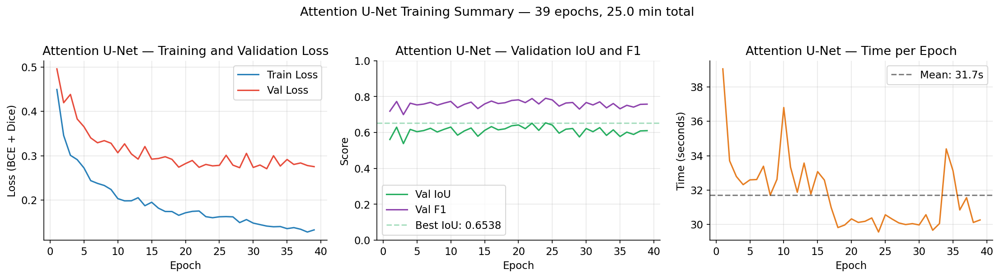

Training curves saved.


In [86]:
if attn_unet_history and 'history' in attn_unet_history:
    history     = attn_unet_history['history']
    epochs      = [h['epoch']              for h in history]
    train_loss  = [h['train_loss']         for h in history]
    val_loss    = [h['val_loss']           for h in history]
    val_iou     = [h['val_iou']            for h in history]
    val_f1      = [h['val_f1']             for h in history]
    epoch_times = [h['epoch_time_seconds'] for h in history]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(epochs, train_loss, label='Train Loss', color='#2980b9', linewidth=1.5)
    axes[0].plot(epochs, val_loss,   label='Val Loss',   color='#e74c3c', linewidth=1.5)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss (BCE + Dice)')
    axes[0].set_title('Attention U-Net — Training and Validation Loss')
    axes[0].legend()

    axes[1].plot(epochs, val_iou, label='Val IoU', color='#27ae60', linewidth=1.5)
    axes[1].plot(epochs, val_f1,  label='Val F1',  color='#8e44ad', linewidth=1.5)
    axes[1].axhline(max(val_iou), color='#27ae60', linestyle='--', alpha=0.4,
                    label=f'Best IoU: {max(val_iou):.4f}')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Score')
    axes[1].set_title('Attention U-Net — Validation IoU and F1')
    axes[1].legend()
    axes[1].set_ylim(0, 1)

    axes[2].plot(epochs, epoch_times, color='#e67e22', linewidth=1.5)
    axes[2].axhline(np.mean(epoch_times), color='black', linestyle='--', alpha=0.5,
                    label=f'Mean: {np.mean(epoch_times):.1f}s')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Time (seconds)')
    axes[2].set_title('Attention U-Net — Time per Epoch')
    axes[2].legend()

    plt.suptitle(
        f'Attention U-Net Training Summary — '
        f'{attn_unet_history["epochs_run"]} epochs, '
        f'{attn_unet_history["total_training_minutes"]:.1f} min total',
        y=1.02
    )
    plt.tight_layout()
    save_figure(fig, 'attention_unet_training_curves', subdir='attention_unet')
    plt.show()
    print('Training curves saved.')
else:
    print('No training history available for plotting.')

---
### 7.4 — Validation Set Evaluation

In [87]:
import time as time_module

print('Evaluating Attention U-Net on validation set...')
attn_unet_model.eval()

val_pred_start = time_module.time()
all_val_preds, all_val_labels = [], []

val_dataset = FloodDataset(
    patch_records=patch_coords['val'],
    norm_stats=norm_stats,
    augmentation=VAL_AUGMENTATION,
    is_test=False
)
val_eval_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True
)

with torch.no_grad():
    for sar, labels, nodata_mask in tqdm(val_eval_loader, desc='Val inference'):
        sar    = sar.to(DEVICE, non_blocking=True)
        logits = attn_unet_model(sar)
        preds  = (torch.sigmoid(logits.squeeze(1)) >= 0.5).long()
        all_val_preds.append(preds.cpu().numpy())
        all_val_labels.append(labels.numpy())

val_pred_time   = time_module.time() - val_pred_start
val_preds_arr   = np.concatenate(all_val_preds,  axis=0)
val_labels_arr  = np.concatenate(all_val_labels, axis=0)
attn_val_metrics = compute_segmentation_metrics(val_preds_arr, val_labels_arr)

print(f'Validation results:')
print(f'  IoU:       {attn_val_metrics["iou"]:.4f}')
print(f'  F1:        {attn_val_metrics["f1"]:.4f}')
print(f'  Precision: {attn_val_metrics["precision"]:.4f}')
print(f'  Recall:    {attn_val_metrics["recall"]:.4f}')
print(f'  Inference time: {val_pred_time:.2f}s')

Evaluating Attention U-Net on validation set...


Val inference:   0%|          | 0/12 [00:00<?, ?it/s]

Validation results:
  IoU:       0.6191
  F1:        0.7647
  Precision: 0.7937
  Recall:    0.7378
  Inference time: 5.84s


---
### 7.5 — Test Set Evaluation (Spain and USA)

In [88]:
print('Evaluating Attention U-Net on test tiles (Spain and USA)...')
print()

test_results_attn = []
all_test_preds_attn, all_test_labels_attn = [], []

test_start = time_module.time()

for tile_record in tqdm(patch_coords['test'], desc='Test inference'):
    pred_mask, label, nodata_mask = sliding_window_inference(
        model=attn_unet_model,
        tile_record=tile_record,
        norm_stats=norm_stats,
        patch_size=PATCH_SIZE,
        overlap=SLIDING_WINDOW_OVERLAP,
        device=DEVICE
    )
    tile_metrics = compute_segmentation_metrics(pred_mask, label)
    tile_metrics['region']  = tile_record['region']
    tile_metrics['tile_id'] = tile_record.get('tile_id', 'unknown')
    test_results_attn.append(tile_metrics)
    all_test_preds_attn.append(pred_mask)
    all_test_labels_attn.append(label)

test_time = time_module.time() - test_start

all_preds_arr    = np.stack(all_test_preds_attn,  axis=0)
all_labels_arr   = np.stack(all_test_labels_attn, axis=0)
attn_test_metrics = compute_segmentation_metrics(all_preds_arr, all_labels_arr)

print(f'\nOverall test results:')
print(f'  IoU:       {attn_test_metrics["iou"]:.4f}')
print(f'  F1:        {attn_test_metrics["f1"]:.4f}')
print(f'  Precision: {attn_test_metrics["precision"]:.4f}')
print(f'  Recall:    {attn_test_metrics["recall"]:.4f}')
print(f'  Inference time: {test_time:.1f}s for {len(patch_coords["test"])} tiles')

import pandas as pd
test_df_attn = pd.DataFrame(test_results_attn)
print(f'\nPer-region breakdown:')
print(test_df_attn.groupby('region')[['iou','f1','precision','recall']].mean().round(4).to_string())

Evaluating Attention U-Net on test tiles (Spain and USA)...



Test inference:   0%|          | 0/99 [00:00<?, ?it/s]


Overall test results:
  IoU:       0.6210
  F1:        0.7662
  Precision: 0.7667
  Recall:    0.7658
  Inference time: 22.3s for 99 tiles

Per-region breakdown:
           iou      f1  precision  recall
region                                   
Spain   0.4416  0.5551     0.5831  0.5759
USA     0.3085  0.4238     0.6120  0.3995


---
### 7.6 — Save Complete Metrics and Timing

In [89]:
attn_full_metrics = {
    'model_name':             'AttentionUNet',
    'n_params':               count_parameters(attn_unet_model),
    'encoder':                'ResNet-34',
    'attention_type':         'scSE',
    'epochs_run':             attn_unet_history['epochs_run'] if attn_unet_history else None,
    'best_val_iou':           attn_unet_history['best_val_iou'] if attn_unet_history else None,
    'total_training_seconds': attn_unet_history.get('total_training_seconds') if attn_unet_history else None,
    'total_training_minutes': attn_unet_history.get('total_training_minutes') if attn_unet_history else None,
    'avg_epoch_seconds':      attn_unet_history.get('avg_epoch_seconds') if attn_unet_history else None,
    'total_patches_seen':     attn_unet_history.get('total_patches_seen') if attn_unet_history else None,
    'val_inference_seconds':  val_pred_time,
    'test_inference_seconds': test_time,
    'val_metrics':            attn_val_metrics,
    'test_metrics_overall':   attn_test_metrics,
    'test_metrics_per_tile':  test_results_attn,
}

save_metrics(attn_full_metrics, 'attention_unet_full_metrics')
print('Saved to metrics/attention_unet_full_metrics.json')
print()
print('=== ATTENTION U-NET TIMING SUMMARY ===')
if attn_unet_history:
    print(f'  Total training time:  {attn_unet_history["total_training_minutes"]:.1f} min')
    print(f'  Avg time per epoch:   {attn_unet_history["avg_epoch_seconds"]:.1f}s')
    print(f'  Epochs completed:     {attn_unet_history["epochs_run"]}/{NUM_EPOCHS}')
    print(f'  Total patches seen:   {attn_unet_history["total_patches_seen"]:,}')
print(f'  Val inference time:   {val_pred_time:.2f}s')
print(f'  Test inference time:  {test_time:.1f}s')

INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\attention_unet_full_metrics.json


Saved to metrics/attention_unet_full_metrics.json

=== ATTENTION U-NET TIMING SUMMARY ===
  Total training time:  25.0 min
  Avg time per epoch:   31.7s
  Epochs completed:     39/50
  Total patches seen:   35,568
  Val inference time:   5.84s
  Test inference time:  22.3s


---
### 7.7 — Visualisations

Three figures:
1. Prediction grid on test tiles with error overlay
2. Per-region test IoU
3. Direct comparison with U-Net — the key result of this section

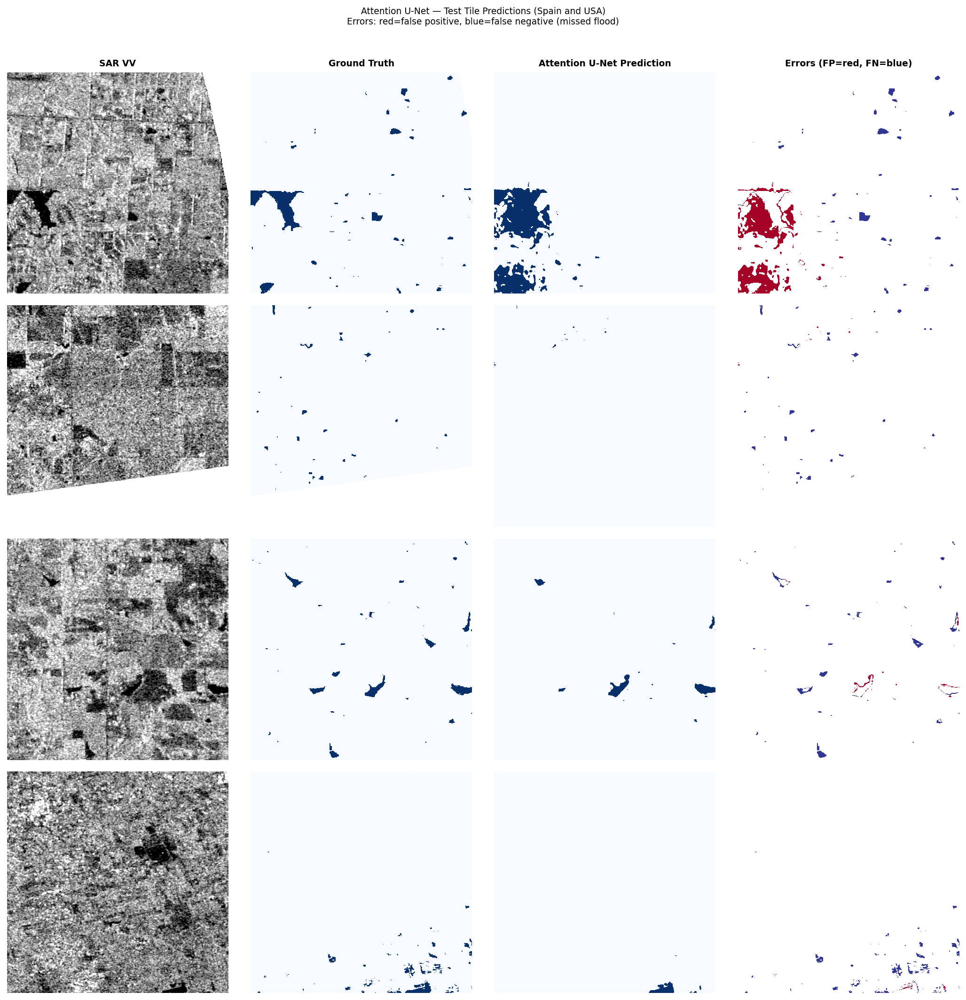

Prediction grid saved.


In [90]:
# ── Figure 1: Prediction grid ─────────────────────────────────────────────────
np.random.seed(SEED)
sample_indices = np.random.choice(
    len(all_test_preds_attn),
    size=min(4, len(all_test_preds_attn)),
    replace=False
)

fig, axes = plt.subplots(len(sample_indices), 4, figsize=(14, len(sample_indices)*3.5))
if len(sample_indices) == 1:
    axes = axes[np.newaxis, :]

col_titles = ['SAR VV', 'Ground Truth', 'Attention U-Net Prediction',
              'Errors (FP=red, FN=blue)']
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=9, fontweight='bold')

for row, tile_idx in enumerate(sample_indices):
    pred  = all_test_preds_attn[tile_idx]
    truth = all_test_labels_attn[tile_idx]
    valid = truth != LABEL_NODATA

    tile_rec = patch_coords['test'][tile_idx]
    with rasterio.open(tile_rec['s1_path']) as src:
        sar_disp = src.read(1).astype(np.float32)
    finite = sar_disp[np.isfinite(sar_disp)]
    lo, hi = np.percentile(finite, 2), np.percentile(finite, 98)
    sar_disp = np.clip((sar_disp - lo) / (hi - lo + 1e-8), 0, 1)

    truth_disp = np.where(truth == LABEL_NODATA, np.nan, truth.astype(float))

    # Correct pixels left as NaN (transparent/white background), only actual
    # errors are coloured. Same fix applied to RF (Section 5) and U-Net
    # (Section 6) grids — previously "correct" was set to 0.0, which under
    # the RdYlBu_r colormap painted the entire correct background the same
    # colour as one of the error classes.
    error_map = np.full_like(pred, np.nan, dtype=np.float32)
    error_map[valid & (pred == 1) & (truth == 0)] = 1.0   # false positive -> red
    error_map[valid & (pred == 0) & (truth == 1)] = 0.0   # false negative -> blue
    # correct pixels stay NaN -> rendered as background, no colour applied

    tile_iou = test_results_attn[tile_idx]['iou']
    region   = tile_rec['region']

    axes[row, 0].imshow(sar_disp,   cmap=SAR_CMAP)
    axes[row, 0].set_ylabel(f'{region}\nIoU={tile_iou:.3f}', fontsize=8)
    axes[row, 1].imshow(truth_disp, cmap=FLOOD_CMAP, vmin=0, vmax=1, interpolation='nearest')
    axes[row, 2].imshow(pred,       cmap=FLOOD_CMAP, vmin=0, vmax=1, interpolation='nearest')
    axes[row, 3].imshow(error_map,  cmap='RdYlBu_r', vmin=0, vmax=1, interpolation='nearest')

    for ax in axes[row]:
        ax.axis('off')

plt.suptitle(
    'Attention U-Net — Test Tile Predictions (Spain and USA)\n'
    'Errors: red=false positive, blue=false negative (missed flood)',
    y=1.01, fontsize=9
)
plt.tight_layout()
save_figure(fig, 'attention_unet_prediction_grid', subdir='attention_unet')
plt.show()
print('Prediction grid saved.')

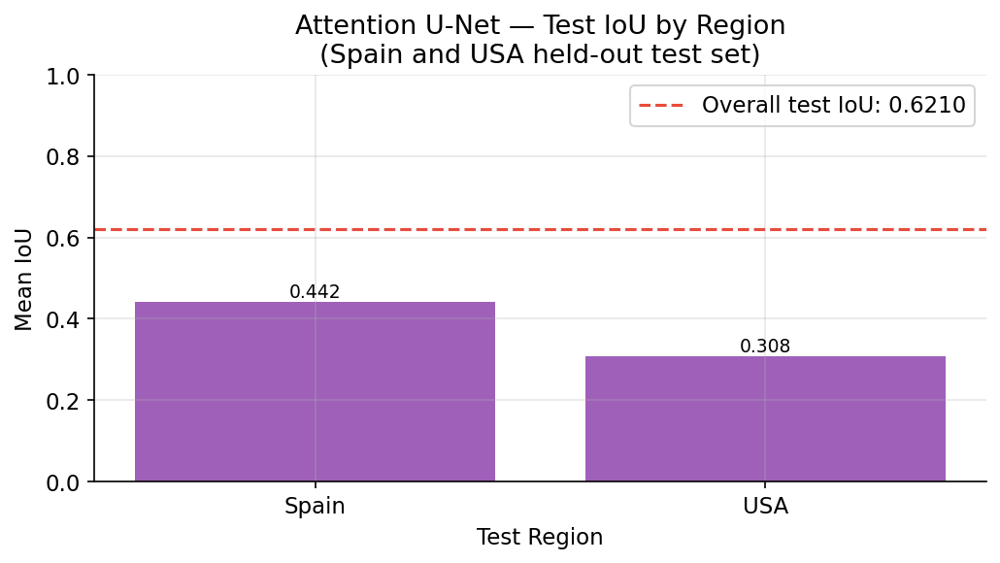

Per-region test IoU figure saved.


In [91]:
# ── Figure 2: Per-region test IoU ────────────────────────────────────────────
region_iou = test_df_attn.groupby('region')['iou'].mean().reset_index()
region_iou = region_iou.sort_values('iou', ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(region_iou['region'], region_iou['iou'], color='#8e44ad', alpha=0.85)
ax.axhline(attn_test_metrics['iou'], color='#e74c3c', linestyle='--', linewidth=1.5,
           label=f'Overall test IoU: {attn_test_metrics["iou"]:.4f}')
ax.set_xlabel('Test Region')
ax.set_ylabel('Mean IoU')
ax.set_title('Attention U-Net — Test IoU by Region\n(Spain and USA held-out test set)')
ax.legend()
ax.set_ylim(0, 1)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', fontsize=9)
plt.tight_layout()
save_figure(fig, 'attention_unet_test_metrics', subdir='attention_unet')
plt.show()
print('Per-region test IoU figure saved.')

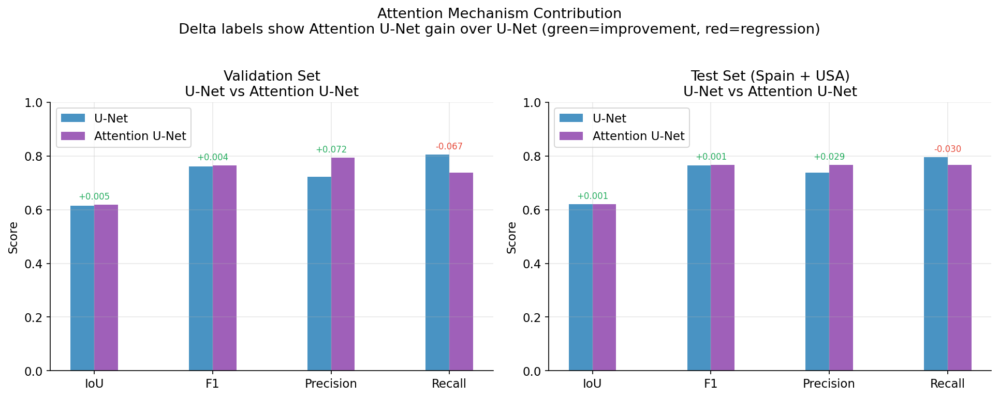

U-Net vs Attention U-Net comparison figure saved.

Key results:
  Val  IoU delta:  +0.0050
  Val  F1  delta:  +0.0038
  Test IoU delta:  +0.0011
  Test F1  delta:  +0.0008

Interpretation:
  Positive delta = attention gates improved performance.
  Negative delta = attention gates hurt performance (worth discussing).
  Either outcome is a valid research finding.


In [92]:
# ── Figure 3: Direct comparison with U-Net ───────────────────────────────────
# This is the key figure for Section 7 — isolates the attention contribution.
unet_metrics_path = METRICS_DIR / 'unet_full_metrics.json'

if unet_metrics_path.exists():
    with open(unet_metrics_path) as f:
        unet_loaded = json.load(f)

    unet_val  = unet_loaded['val_metrics']
    unet_test = unet_loaded['test_metrics_overall']

    metrics_labels = ['IoU', 'F1', 'Precision', 'Recall']
    unet_val_vals  = [unet_val['iou'],  unet_val['f1'],
                      unet_val['precision'],  unet_val['recall']]
    attn_val_vals  = [attn_val_metrics['iou'], attn_val_metrics['f1'],
                      attn_val_metrics['precision'], attn_val_metrics['recall']]
    unet_test_vals = [unet_test['iou'],  unet_test['f1'],
                      unet_test['precision'],  unet_test['recall']]
    attn_test_vals = [attn_test_metrics['iou'], attn_test_metrics['f1'],
                      attn_test_metrics['precision'], attn_test_metrics['recall']]

    x = np.arange(len(metrics_labels))
    w = 0.2

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Validation comparison
    axes[0].bar(x - w/2, unet_val_vals,  w, label='U-Net',           color='#2980b9', alpha=0.85)
    axes[0].bar(x + w/2, attn_val_vals,  w, label='Attention U-Net', color='#8e44ad', alpha=0.85)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(metrics_labels)
    axes[0].set_ylabel('Score')
    axes[0].set_title('Validation Set\nU-Net vs Attention U-Net')
    axes[0].legend()
    axes[0].set_ylim(0, 1)
    for i, (u, a) in enumerate(zip(unet_val_vals, attn_val_vals)):
        delta = a - u
        colour = '#27ae60' if delta >= 0 else '#e74c3c'
        axes[0].text(i, max(u, a) + 0.02,
                     f'{delta:+.3f}', ha='center', fontsize=8, color=colour)

    # Test comparison
    axes[1].bar(x - w/2, unet_test_vals, w, label='U-Net',           color='#2980b9', alpha=0.85)
    axes[1].bar(x + w/2, attn_test_vals, w, label='Attention U-Net', color='#8e44ad', alpha=0.85)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(metrics_labels)
    axes[1].set_ylabel('Score')
    axes[1].set_title('Test Set (Spain + USA)\nU-Net vs Attention U-Net')
    axes[1].legend()
    axes[1].set_ylim(0, 1)
    for i, (u, a) in enumerate(zip(unet_test_vals, attn_test_vals)):
        delta = a - u
        colour = '#27ae60' if delta >= 0 else '#e74c3c'
        axes[1].text(i, max(u, a) + 0.02,
                     f'{delta:+.3f}', ha='center', fontsize=8, color=colour)

    plt.suptitle(
        'Attention Mechanism Contribution\n'
        'Delta labels show Attention U-Net gain over U-Net '
        '(green=improvement, red=regression)',
        y=1.02
    )
    plt.tight_layout()
    save_figure(fig, 'attention_vs_unet_comparison', subdir='attention_unet')
    plt.show()
    print('U-Net vs Attention U-Net comparison figure saved.')
    print()
    print('Key results:')
    print(f'  Val  IoU delta:  {attn_val_metrics["iou"]  - unet_val["iou"]:+.4f}')
    print(f'  Val  F1  delta:  {attn_val_metrics["f1"]   - unet_val["f1"]:+.4f}')
    print(f'  Test IoU delta:  {attn_test_metrics["iou"] - unet_test["iou"]:+.4f}')
    print(f'  Test F1  delta:  {attn_test_metrics["f1"]  - unet_test["f1"]:+.4f}')
    print()
    print('Interpretation:')
    print('  Positive delta = attention gates improved performance.')
    print('  Negative delta = attention gates hurt performance (worth discussing).')
    print('  Either outcome is a valid research finding.')
else:
    print('U-Net metrics not found. Run Section 6 first to generate the comparison figure.')

---
### Section 7 Complete

# Section 8: DeepLabV3+

**Purpose:** Train and evaluate DeepLabV3+ — the third CNN architecture in the
comparison, completing the convolutional family before moving to SegFormer's
transformer-based approach in Section 9.

DeepLabV3+ (Chen et al., 2018) replaces U-Net's gradual, pooling-based context
construction with **Atrous Spatial Pyramid Pooling (ASPP)** — several dilated
convolutions at different dilation rates applied in parallel to the same
feature map, plus one global pooling branch. This captures multi-scale spatial
context simultaneously rather than building it up hierarchically through
successive downsampling, which may be advantageous for flood extents that vary
substantially in physical scale (a narrow flooded ditch vs. a vast inundated
plain) within and across regions.

**Controlled comparison design — identical to U-Net and Attention U-Net:**
Same ResNet-34 encoder, same ImageNet pre-training, same loss function, same
optimiser, same learning rate, same DataLoaders, same seed. The only variable
is the decoder mechanism (ASPP + single skip connection, vs. U-Net's full
skip-connection decoder, vs. scSE-attention decoder). Any performance
difference is attributable to this architectural choice alone.

**Why this model, and why before SegFormer:**
DeepLabV3+ is still a CNN — it shares with U-Net and Attention U-Net the
fundamental limitation that convolutions only ever see a local neighbourhood,
however widened by dilation. Training it before SegFormer means all three CNN
variants are evaluated under identical conditions before the transformer
architecture is introduced, isolating "does parallel multi-scale context help
within the CNN family" from "does global self-attention help beyond what any
CNN can do."

**Outputs produced:**
- `checkpoints/deeplabv3plus_best.pt`
- `metrics/deeplabv3plus_training_history.json`
- `metrics/deeplabv3plus_full_metrics.json`
- `figures/deeplabv3plus/deeplabv3plus_training_curves.png`
- `figures/deeplabv3plus/deeplabv3plus_prediction_grid.png`
- `figures/deeplabv3plus/deeplabv3plus_test_metrics.png`
- `figures/deeplabv3plus/deeplabv3plus_vs_unet_family_comparison.png`

> **Prerequisites:** Section 1, Cell 4.0, Cells 4.1–4.8 must be run first.


---
### 8.0 — Confirm Prerequisites

In [25]:
required = {
    'patch_coords':             'patch_coords'             in dir(),
    'norm_stats':               'norm_stats'               in dir(),
    'train_sample_weights':     'train_sample_weights'     in dir(),
    'get_dataloaders':          'get_dataloaders'          in dir(),
    'reset_seed_for_model':     'reset_seed_for_model'     in dir(),
    'train_model':              'train_model'              in dir(),
    'sliding_window_inference': 'sliding_window_inference' in dir(),
    'CRITERION':                'CRITERION'                in dir(),
    'FloodDataset':             'FloodDataset'             in dir(),
}

all_ok = all(required.values())
for name, present in required.items():
    print(f'  [{"OK" if present else "MISSING"}] {name}')

if not all_ok:
    raise RuntimeError(
        'Prerequisites missing. Run Section 1, Cell 4.0, then Cells 4.1-4.8.'
    )

# Check which prior CNN models are available for the family comparison figure
unet_available = (METRICS_DIR / 'unet_full_metrics.json').exists()
attn_available  = (METRICS_DIR / 'attention_unet_full_metrics.json').exists()
print()
print(f'  [{"OK" if unet_available else "WARN"}] unet_full_metrics.json')
print(f'  [{"OK" if attn_available  else "WARN"}] attention_unet_full_metrics.json')
print()
print('All core prerequisites confirmed. Ready to train DeepLabV3+.')

  [OK] patch_coords
  [OK] norm_stats
  [OK] train_sample_weights
  [OK] get_dataloaders
  [OK] reset_seed_for_model
  [OK] train_model
  [OK] sliding_window_inference
  [OK] CRITERION
  [OK] FloodDataset

  [OK] unet_full_metrics.json
  [OK] attention_unet_full_metrics.json

All core prerequisites confirmed. Ready to train DeepLabV3+.


---
### 8.1 — DeepLabV3+ Architecture

**Key components:**

- **ResNet-34 encoder** — identical to U-Net and Attention U-Net, ImageNet
  pre-trained, adapted to 2-channel SAR input. Keeping the encoder fixed
  across all three CNN models isolates the decoder/context-aggregation
  mechanism as the only variable.
- **ASPP (Atrous Spatial Pyramid Pooling)** — applies several parallel
  dilated convolutions (different dilation rates) plus a global average
  pooling branch to the encoder's deepest feature map, capturing context
  at multiple spatial scales simultaneously rather than hierarchically.
- **Single skip connection ("+")** — one shortcut from an early, high
  resolution encoder layer is fused back in before the final upsampling,
  sharpening object boundaries that the ASPP branch alone tends to blur.
  This is deliberately sparser than U-Net's skip connections at every
  decoder level — DeepLabV3+ relies on ASPP for most of its context
  modelling and uses this single connection only for boundary refinement.



In [26]:
def build_deeplabv3plus() -> nn.Module:
    """
    Build DeepLabV3+ with ResNet-34 encoder for 2-channel SAR input.

    Problem solved:
        Provides the third CNN architecture in the comparison, using
        parallel multi-scale dilated convolutions (ASPP) instead of
        U-Net's hierarchical pooling or Attention U-Net's gated skip
        connections. Built via segmentation-models-pytorch for the same
        implementation-quality and reproducibility guarantees as the
        other two CNN models.

    Architecture decisions (matching U-Net/Attention U-Net wherever possible):
        encoder_name='resnet34':    Same backbone as U-Net and Attention
            U-Net — isolates the decoder mechanism as the only difference.
        encoder_weights='imagenet': Same pre-training strategy.
        in_channels=2:              VV and VH SAR bands.
        classes=1:                  Single output logit, binary segmentation.
        activation=None:            Raw logits — sigmoid applied inside loss.

    Returns:
        nn.Module: DeepLabV3+ model ready for training.
    """
    model = smp.DeepLabV3Plus(
        encoder_name='resnet34',
        encoder_weights='imagenet',
        in_channels=IN_CHANNELS,    # 2 — VV and VH
        classes=1,                  # binary segmentation
        activation=None,            # raw logits — sigmoid inside loss
    )
    return model


def count_parameters(model: nn.Module) -> int:
    """Count total trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Preview and compare parameter count against U-Net / Attention U-Net
test_deeplab = build_deeplabv3plus()
n_params_deeplab = count_parameters(test_deeplab)

print('DeepLabV3+ architecture:')
print(f'  Encoder:             ResNet-34 (ImageNet pre-trained)')
print(f'  Context mechanism:   ASPP (parallel dilated convolutions, multiple rates)')
print(f'  Skip connections:    1 (boundary refinement only)')
print(f'  Input channels:      {IN_CHANNELS} (VV, VH)')
print(f'  Output:              1 logit per pixel')
print(f'  Trainable params:    {n_params_deeplab:,}')

for fname, label in [('unet_full_metrics.json', 'U-Net'),
                      ('attention_unet_full_metrics.json', 'Attention U-Net')]:
    path = METRICS_DIR / fname
    if path.exists():
        with open(path) as f:
            m = json.load(f)
        n = m.get('n_params')
        if n:
            delta = n_params_deeplab - n
            print(f'  vs {label}: {"+" if delta >= 0 else ""}{delta:,} params '
                  f'({100*delta/n:+.1f}%)')

dummy_input  = torch.randn(2, IN_CHANNELS, PATCH_SIZE, PATCH_SIZE)
dummy_output = test_deeplab(dummy_input)
print()
print(f'Forward pass test:')
print(f'  Input shape:   {dummy_input.shape}')
print(f'  Output shape:  {dummy_output.shape}  (B, 1, H, W)')
assert dummy_output.shape == (2, 1, PATCH_SIZE, PATCH_SIZE), \
    f'Unexpected output shape: {dummy_output.shape}'
print('  Shape assertion passed.')
del test_deeplab, dummy_input, dummy_output

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

C:\Users\954847\AppData\Roaming\Python\Python313\site-packages\huggingface_hub\file_download.py:137: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\954847\.cache\huggingface\hub\models--smp-hub--resnet34.imagenet. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

DeepLabV3+ architecture:
  Encoder:             ResNet-34 (ImageNet pre-trained)
  Context mechanism:   ASPP (parallel dilated convolutions, multiple rates)
  Skip connections:    1 (boundary refinement only)
  Input channels:      2 (VV, VH)
  Output:              1 logit per pixel
  Trainable params:    22,434,321
  vs U-Net: -1,998,912 params (-8.2%)
  vs Attention U-Net: -2,112,903 params (-8.6%)

Forward pass test:
  Input shape:   torch.Size([2, 2, 256, 256])
  Output shape:  torch.Size([2, 1, 256, 256])  (B, 1, H, W)
  Shape assertion passed.


---
### 8.2 — Training

Seed reset to SEED=42 guarantees DeepLabV3+ receives patches in the same
order with the same augmentation sequences as U-Net and Attention U-Net.
Same shared `train_model()` driver — identical hyperparameters, identical
timing instrumentation.

In [31]:
deeplab_ckpt_path = CHECKPOINT_DIR / 'deeplabv3plus_best.pt'

if deeplab_ckpt_path.exists():
    print('DeepLabV3+ checkpoint found. Loading pre-trained weights...')
    deeplab_model = build_deeplabv3plus()
    deeplab_model, best_epoch, best_iou = load_model_checkpoint(
        deeplab_model, 'deeplabv3plus_best'
    )
    deeplab_model = deeplab_model.to(DEVICE)

    history_path = METRICS_DIR / 'deeplabv3plus_training_history.json'
    if history_path.exists():
        with open(history_path) as f:
            deeplab_history = json.load(f)
        print(f'Training history loaded.')
        print(f'  Epochs run:          {deeplab_history["epochs_run"]}')
        print(f'  Best val IoU:        {deeplab_history["best_val_iou"]:.4f}')
        print(f'  Total training time: {deeplab_history["total_training_minutes"]:.1f} min')
        print(f'  Total patches seen:  {deeplab_history["total_patches_seen"]:,}')
    else:
        deeplab_history = None
        print('No training history file found.')

else:
    print('No checkpoint found. Starting DeepLabV3+ training...')
    print()

    # Reset seed — identical starting point to U-Net and Attention U-Net
    reset_seed_for_model('DeepLabV3Plus')

    train_loader, val_loader = get_dataloaders(
        patch_coords, norm_stats, train_sample_weights, batch_size=BATCH_SIZE
    )
    print(f'DataLoaders ready:')
    print(f'  Train batches/epoch: {len(train_loader)}')
    print(f'  Val batches/epoch:   {len(val_loader)}')
    print()

    deeplab_model = build_deeplabv3plus()
    print(f'Model built: {count_parameters(deeplab_model):,} trainable parameters')
    print()

    deeplab_history = train_model(
        model=deeplab_model,
        model_name='deeplabv3plus',
        train_loader=train_loader,
        val_loader=val_loader,
        device=DEVICE,
        n_epochs=NUM_EPOCHS,
        patience=EARLY_STOP_PATIENCE,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    deeplab_model, best_epoch, best_iou = load_model_checkpoint(
        deeplab_model, 'deeplabv3plus_best'
    )
    deeplab_model = deeplab_model.to(DEVICE)
    print(f'Best weights restored from epoch {best_epoch} (val IoU={best_iou:.4f})')

DeepLabV3+ checkpoint found. Loading pre-trained weights...


INFO | Model checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\deeplabv3plus_best.pt (epoch 17, IoU 0.6696)


Training history loaded.
  Epochs run:          32
  Best val IoU:        0.6696
  Total training time: 18.9 min
  Total patches seen:  29,184


---
### 8.3 — Training Curves

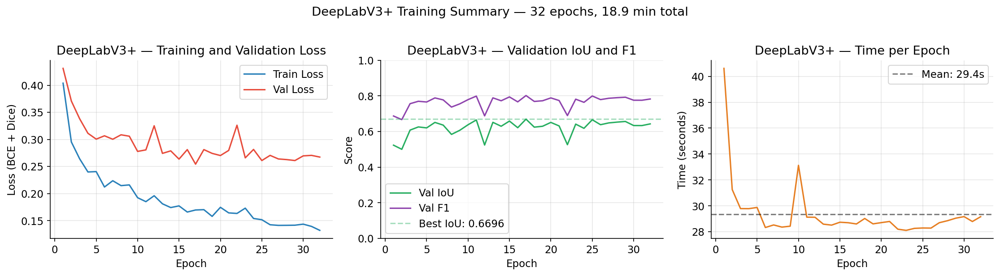

Training curves saved.


In [32]:
if deeplab_history and 'history' in deeplab_history:
    history     = deeplab_history['history']
    epochs      = [h['epoch']              for h in history]
    train_loss  = [h['train_loss']         for h in history]
    val_loss    = [h['val_loss']           for h in history]
    val_iou     = [h['val_iou']            for h in history]
    val_f1      = [h['val_f1']             for h in history]
    epoch_times = [h['epoch_time_seconds'] for h in history]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(epochs, train_loss, label='Train Loss', color='#2980b9', linewidth=1.5)
    axes[0].plot(epochs, val_loss,   label='Val Loss',   color='#e74c3c', linewidth=1.5)
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss (BCE + Dice)')
    axes[0].set_title('DeepLabV3+ — Training and Validation Loss')
    axes[0].legend()

    axes[1].plot(epochs, val_iou, label='Val IoU', color='#27ae60', linewidth=1.5)
    axes[1].plot(epochs, val_f1,  label='Val F1',  color='#8e44ad', linewidth=1.5)
    axes[1].axhline(max(val_iou), color='#27ae60', linestyle='--', alpha=0.4,
                    label=f'Best IoU: {max(val_iou):.4f}')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score')
    axes[1].set_title('DeepLabV3+ — Validation IoU and F1')
    axes[1].legend(); axes[1].set_ylim(0, 1)

    axes[2].plot(epochs, epoch_times, color='#e67e22', linewidth=1.5)
    axes[2].axhline(np.mean(epoch_times), color='black', linestyle='--', alpha=0.5,
                    label=f'Mean: {np.mean(epoch_times):.1f}s')
    axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Time (seconds)')
    axes[2].set_title('DeepLabV3+ — Time per Epoch')
    axes[2].legend()

    plt.suptitle(
        f'DeepLabV3+ Training Summary — '
        f'{deeplab_history["epochs_run"]} epochs, '
        f'{deeplab_history["total_training_minutes"]:.1f} min total',
        y=1.02
    )
    plt.tight_layout()
    save_figure(fig, 'deeplabv3plus_training_curves', subdir='deeplabv3plus')
    plt.show()
    print('Training curves saved.')
else:
    print('No training history available for plotting.')

---
### 8.4 — Validation Set Evaluation

In [33]:
import time as time_module

print('Evaluating DeepLabV3+ on validation set...')
deeplab_model.eval()

val_pred_start = time_module.time()
all_val_preds, all_val_labels = [], []

val_dataset = FloodDataset(
    patch_records=patch_coords['val'], norm_stats=norm_stats,
    augmentation=VAL_AUGMENTATION, is_test=False
)
val_eval_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True
)

with torch.no_grad():
    for sar, labels, nodata_mask in tqdm(val_eval_loader, desc='Val inference'):
        sar    = sar.to(DEVICE, non_blocking=True)
        logits = deeplab_model(sar)
        preds  = (torch.sigmoid(logits.squeeze(1)) >= 0.5).long()
        all_val_preds.append(preds.cpu().numpy())
        all_val_labels.append(labels.numpy())

val_pred_time      = time_module.time() - val_pred_start
val_preds_arr       = np.concatenate(all_val_preds,  axis=0)
val_labels_arr       = np.concatenate(all_val_labels, axis=0)
deeplab_val_metrics  = compute_segmentation_metrics(val_preds_arr, val_labels_arr)

print(f'Validation results:')
print(f'  IoU:       {deeplab_val_metrics["iou"]:.4f}')
print(f'  F1:        {deeplab_val_metrics["f1"]:.4f}')
print(f'  Precision: {deeplab_val_metrics["precision"]:.4f}')
print(f'  Recall:    {deeplab_val_metrics["recall"]:.4f}')
print(f'  Inference time: {val_pred_time:.2f}s')

Evaluating DeepLabV3+ on validation set...


Val inference:   0%|          | 0/12 [00:00<?, ?it/s]

Validation results:
  IoU:       0.6316
  F1:        0.7742
  Precision: 0.8053
  Recall:    0.7455
  Inference time: 7.25s


---
### 8.5 — Test Set Evaluation (Spain and USA)

In [34]:
print('Evaluating DeepLabV3+ on test tiles (Spain and USA)...')
print()

test_results_deeplab = []
all_test_preds_deeplab, all_test_labels_deeplab = [], []

test_start = time_module.time()

for tile_record in tqdm(patch_coords['test'], desc='Test inference'):
    pred_mask, label, nodata_mask = sliding_window_inference(
        model=deeplab_model,
        tile_record=tile_record,
        norm_stats=norm_stats,
        patch_size=PATCH_SIZE,
        overlap=SLIDING_WINDOW_OVERLAP,
        device=DEVICE
    )
    tile_metrics = compute_segmentation_metrics(pred_mask, label)
    tile_metrics['region']  = tile_record['region']
    tile_metrics['tile_id'] = tile_record.get('tile_id', 'unknown')
    test_results_deeplab.append(tile_metrics)
    all_test_preds_deeplab.append(pred_mask)
    all_test_labels_deeplab.append(label)

test_time = time_module.time() - test_start

all_preds_arr     = np.stack(all_test_preds_deeplab,  axis=0)
all_labels_arr      = np.stack(all_test_labels_deeplab, axis=0)
deeplab_test_metrics = compute_segmentation_metrics(all_preds_arr, all_labels_arr)

print(f'\nOverall test results:')
print(f'  IoU:       {deeplab_test_metrics["iou"]:.4f}')
print(f'  F1:        {deeplab_test_metrics["f1"]:.4f}')
print(f'  Precision: {deeplab_test_metrics["precision"]:.4f}')
print(f'  Recall:    {deeplab_test_metrics["recall"]:.4f}')
print(f'  Inference time: {test_time:.1f}s for {len(patch_coords["test"])} tiles')

import pandas as pd
test_df_deeplab = pd.DataFrame(test_results_deeplab)
print(f'\nPer-region breakdown:')
print(test_df_deeplab.groupby('region')[['iou','f1','precision','recall']].mean().round(4).to_string())

Evaluating DeepLabV3+ on test tiles (Spain and USA)...



Test inference:   0%|          | 0/99 [00:00<?, ?it/s]


Overall test results:
  IoU:       0.5841
  F1:        0.7375
  Precision: 0.7973
  Recall:    0.6860
  Inference time: 15.2s for 99 tiles

Per-region breakdown:
           iou      f1  precision  recall
region                                   
Spain   0.4003  0.4989     0.6449  0.4754
USA     0.2042  0.2851     0.6386  0.2543


---
### 8.6 — Save Complete Metrics and Timing

In [35]:
deeplab_full_metrics = {
    'model_name':             'DeepLabV3Plus',
    'n_params':               count_parameters(deeplab_model),
    'encoder':                'ResNet-34',
    'context_mechanism':      'ASPP (atrous spatial pyramid pooling)',
    'epochs_run':             deeplab_history['epochs_run'] if deeplab_history else None,
    'best_val_iou':           deeplab_history['best_val_iou'] if deeplab_history else None,
    'total_training_seconds': deeplab_history.get('total_training_seconds') if deeplab_history else None,
    'total_training_minutes': deeplab_history.get('total_training_minutes') if deeplab_history else None,
    'avg_epoch_seconds':      deeplab_history.get('avg_epoch_seconds') if deeplab_history else None,
    'total_patches_seen':     deeplab_history.get('total_patches_seen') if deeplab_history else None,
    'val_inference_seconds':  val_pred_time,
    'test_inference_seconds': test_time,
    'val_metrics':            deeplab_val_metrics,
    'test_metrics_overall':   deeplab_test_metrics,
    'test_metrics_per_tile':  test_results_deeplab,
}

save_metrics(deeplab_full_metrics, 'deeplabv3plus_full_metrics')
print('Saved to metrics/deeplabv3plus_full_metrics.json')
print()
print('=== DEEPLABV3+ TIMING SUMMARY ===')
if deeplab_history:
    print(f'  Total training time:  {deeplab_history["total_training_minutes"]:.1f} min')
    print(f'  Avg time per epoch:   {deeplab_history["avg_epoch_seconds"]:.1f}s')
    print(f'  Epochs completed:     {deeplab_history["epochs_run"]}/{NUM_EPOCHS}')
    print(f'  Total patches seen:   {deeplab_history["total_patches_seen"]:,}')
print(f'  Val inference time:   {val_pred_time:.2f}s')
print(f'  Test inference time:  {test_time:.1f}s')

INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\deeplabv3plus_full_metrics.json


Saved to metrics/deeplabv3plus_full_metrics.json

=== DEEPLABV3+ TIMING SUMMARY ===
  Total training time:  18.9 min
  Avg time per epoch:   29.4s
  Epochs completed:     32/50
  Total patches seen:   29,184
  Val inference time:   7.25s
  Test inference time:  15.2s


---
### 8.7 — Visualisations

Three figures:
1. Prediction grid on test tiles with error overlay
2. Per-region test IoU
3. Three-way CNN family comparison (U-Net vs Attention U-Net vs DeepLabV3+)

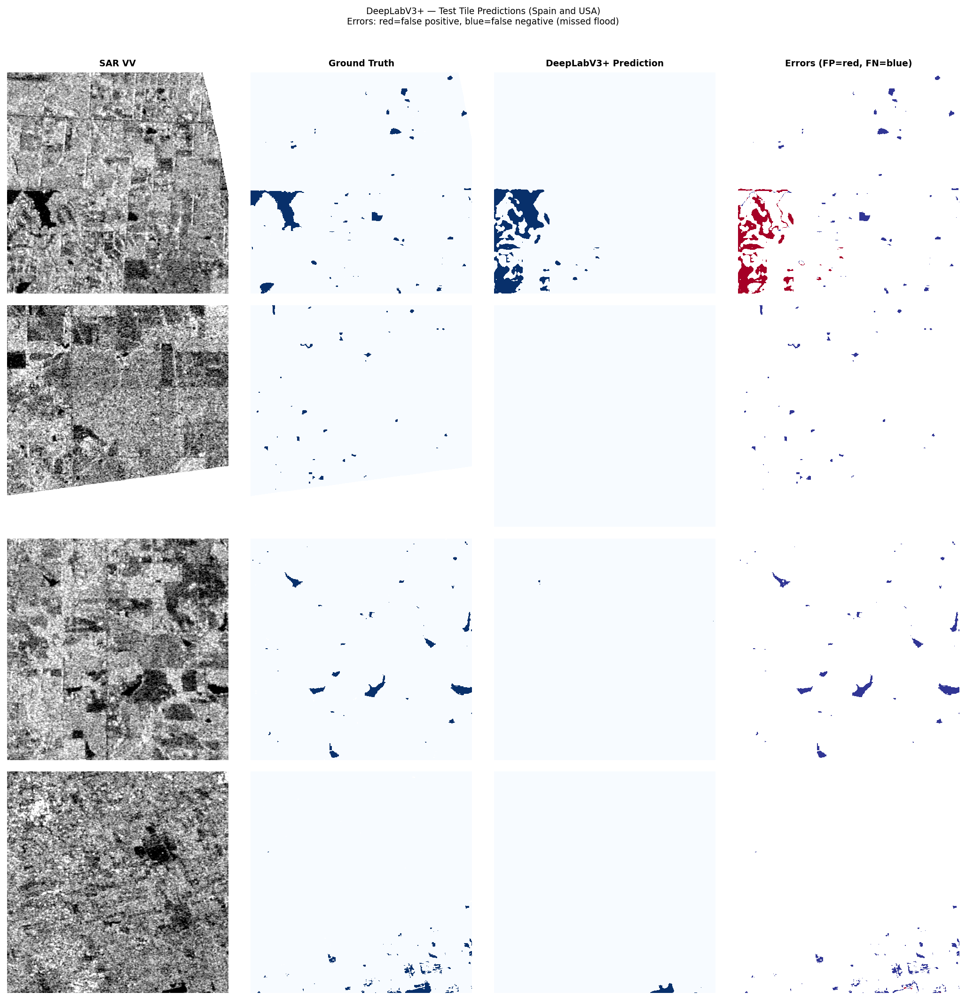

Prediction grid saved.


In [36]:
np.random.seed(SEED)
sample_indices = np.random.choice(
    len(all_test_preds_deeplab), size=min(4, len(all_test_preds_deeplab)), replace=False
)

fig, axes = plt.subplots(len(sample_indices), 4, figsize=(14, len(sample_indices)*3.5))
if len(sample_indices) == 1:
    axes = axes[np.newaxis, :]

col_titles = ['SAR VV', 'Ground Truth', 'DeepLabV3+ Prediction', 'Errors (FP=red, FN=blue)']
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=9, fontweight='bold')

for row, tile_idx in enumerate(sample_indices):
    pred  = all_test_preds_deeplab[tile_idx]
    truth = all_test_labels_deeplab[tile_idx]
    valid = truth != LABEL_NODATA

    tile_rec = patch_coords['test'][tile_idx]
    with rasterio.open(tile_rec['s1_path']) as src:
        sar_disp = src.read(1).astype(np.float32)
    finite = sar_disp[np.isfinite(sar_disp)]
    lo, hi = np.percentile(finite, 2), np.percentile(finite, 98)
    sar_disp = np.clip((sar_disp - lo) / (hi - lo + 1e-8), 0, 1)

    truth_disp = np.where(truth == LABEL_NODATA, np.nan, truth.astype(float))

    # Correct pixels left as NaN (transparent) — only genuine errors coloured.
    error_map = np.full_like(pred, np.nan, dtype=np.float32)
    error_map[valid & (pred == 1) & (truth == 0)] = 1.0   # false positive -> red
    error_map[valid & (pred == 0) & (truth == 1)] = 0.0   # false negative -> blue

    tile_iou = test_results_deeplab[tile_idx]['iou']
    region   = tile_rec['region']

    axes[row, 0].imshow(sar_disp,   cmap=SAR_CMAP)
    axes[row, 0].set_ylabel(f'{region}\nIoU={tile_iou:.3f}', fontsize=8)
    axes[row, 1].imshow(truth_disp, cmap=FLOOD_CMAP, vmin=0, vmax=1, interpolation='nearest')
    axes[row, 2].imshow(pred,       cmap=FLOOD_CMAP, vmin=0, vmax=1, interpolation='nearest')
    axes[row, 3].imshow(error_map,  cmap='RdYlBu_r', vmin=0, vmax=1, interpolation='nearest')

    for ax in axes[row]:
        ax.axis('off')

plt.suptitle(
    'DeepLabV3+ — Test Tile Predictions (Spain and USA)\n'
    'Errors: red=false positive, blue=false negative (missed flood)',
    y=1.01, fontsize=9
)
plt.tight_layout()
save_figure(fig, 'deeplabv3plus_prediction_grid', subdir='deeplabv3plus')
plt.show()
print('Prediction grid saved.')

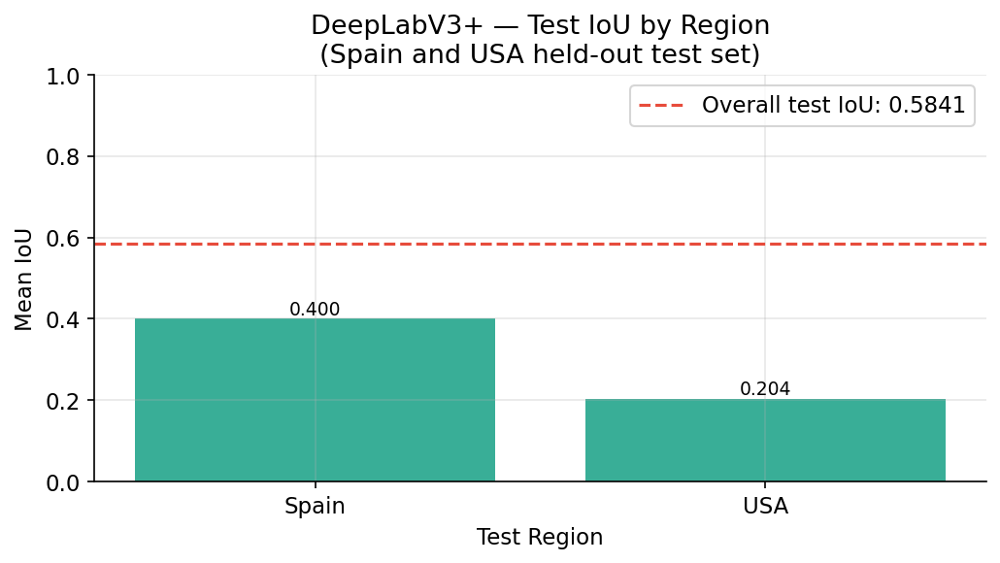

Per-region test IoU figure saved.


In [37]:
region_iou = test_df_deeplab.groupby('region')['iou'].mean().reset_index()
region_iou = region_iou.sort_values('iou', ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(region_iou['region'], region_iou['iou'], color='#16a085', alpha=0.85)
ax.axhline(deeplab_test_metrics['iou'], color='#e74c3c', linestyle='--', linewidth=1.5,
           label=f'Overall test IoU: {deeplab_test_metrics["iou"]:.4f}')
ax.set_xlabel('Test Region'); ax.set_ylabel('Mean IoU')
ax.set_title('DeepLabV3+ — Test IoU by Region\n(Spain and USA held-out test set)')
ax.legend(); ax.set_ylim(0, 1)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', fontsize=9)
plt.tight_layout()
save_figure(fig, 'deeplabv3plus_test_metrics', subdir='deeplabv3plus')
plt.show()
print('Per-region test IoU figure saved.')

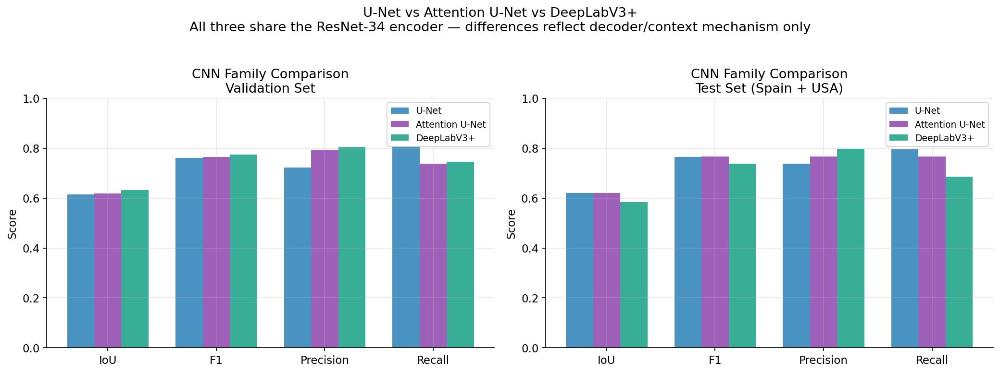

CNN family comparison figure saved.

Test IoU summary:
  U-Net             : 0.6200
  Attention U-Net   : 0.6210
  DeepLabV3+        : 0.5841


In [38]:
# ── Three-way CNN family comparison ──────────────────────────────────────────
unet_path = METRICS_DIR / 'unet_full_metrics.json'
attn_path = METRICS_DIR / 'attention_unet_full_metrics.json'

if unet_path.exists() and attn_path.exists():
    with open(unet_path) as f: unet_m = json.load(f)
    with open(attn_path) as f: attn_m = json.load(f)

    models_compare = {
        'U-Net':           (unet_m['val_metrics'], unet_m['test_metrics_overall'], '#2980b9'),
        'Attention U-Net': (attn_m['val_metrics'], attn_m['test_metrics_overall'], '#8e44ad'),
        'DeepLabV3+':      (deeplab_val_metrics,   deeplab_test_metrics,           '#16a085'),
    }

    metrics_labels = ['IoU', 'F1', 'Precision', 'Recall']
    x = np.arange(len(metrics_labels))
    w = 0.25

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for i, (name, (val_m, test_m, colour)) in enumerate(models_compare.items()):
        offset = (i - 1) * w
        val_vals  = [val_m['iou'], val_m['f1'], val_m['precision'], val_m['recall']]
        test_vals = [test_m['iou'], test_m['f1'], test_m['precision'], test_m['recall']]
        axes[0].bar(x + offset, val_vals,  w, label=name, color=colour, alpha=0.85)
        axes[1].bar(x + offset, test_vals, w, label=name, color=colour, alpha=0.85)

    for ax, title in zip(axes, ['Validation Set', 'Test Set (Spain + USA)']):
        ax.set_xticks(x); ax.set_xticklabels(metrics_labels)
        ax.set_ylabel('Score'); ax.set_ylim(0, 1)
        ax.set_title(f'CNN Family Comparison\n{title}')
        ax.legend(fontsize=9)

    plt.suptitle(
        'U-Net vs Attention U-Net vs DeepLabV3+\n'
        'All three share the ResNet-34 encoder — differences reflect decoder/context mechanism only',
        y=1.03
    )
    plt.tight_layout()
    save_figure(fig, 'deeplabv3plus_vs_unet_family_comparison', subdir='deeplabv3plus')
    plt.show()
    print('CNN family comparison figure saved.')
    print()
    print('Test IoU summary:')
    for name, (_, test_m, _) in models_compare.items():
        print(f'  {name:<18}: {test_m["iou"]:.4f}')
else:
    print('U-Net and/or Attention U-Net metrics not found — run Sections 6-7 first.')

---
### Section 8 Complete

In [39]:
print('=' * 60)
print('DEEPLABV3+ — FINAL SUMMARY')
print('=' * 60)
print()
print('Architecture:')
print(f'  Encoder:           ResNet-34 (ImageNet pre-trained)')
print(f'  Context mechanism: ASPP (parallel dilated convolutions)')
print(f'  Trainable params:  {count_parameters(deeplab_model):,}')
print()
if deeplab_history:
    print('Compute time:')
    print(f'  Training:         {deeplab_history["total_training_minutes"]:.1f} min')
    print(f'  Avg/epoch:        {deeplab_history["avg_epoch_seconds"]:.1f}s')
    print(f'  Epochs run:       {deeplab_history["epochs_run"]}/{NUM_EPOCHS}')
    print(f'  Patches seen:     {deeplab_history["total_patches_seen"]:,}')
    print()
print('Performance:')
print(f'  Val  IoU:         {deeplab_val_metrics["iou"]:.4f}')
print(f'  Val  F1:          {deeplab_val_metrics["f1"]:.4f}')
print(f'  Test IoU:         {deeplab_test_metrics["iou"]:.4f}')
print(f'  Test F1:          {deeplab_test_metrics["f1"]:.4f}')
print(f'  Test Precision:   {deeplab_test_metrics["precision"]:.4f}')
print(f'  Test Recall:      {deeplab_test_metrics["recall"]:.4f}')
print()
print('CNN family now complete: U-Net, Attention U-Net, DeepLabV3+.')
print()
print('Next: Section 9 — SegFormer-B2.')
print('Completes the CNN-to-transformer arc. Global self-attention from')
print('layer one, versus local/widened convolutions in all three CNNs above.')
print('=' * 60)

DEEPLABV3+ — FINAL SUMMARY

Architecture:
  Encoder:           ResNet-34 (ImageNet pre-trained)
  Context mechanism: ASPP (parallel dilated convolutions)
  Trainable params:  22,434,321

Compute time:
  Training:         18.9 min
  Avg/epoch:        29.4s
  Epochs run:       32/50
  Patches seen:     29,184

Performance:
  Val  IoU:         0.6316
  Val  F1:          0.7742
  Test IoU:         0.5841
  Test F1:          0.7375
  Test Precision:   0.7973
  Test Recall:      0.6860

CNN family now complete: U-Net, Attention U-Net, DeepLabV3+.

Next: Section 9 — SegFormer-B2.
Completes the CNN-to-transformer arc. Global self-attention from
layer one, versus local/widened convolutions in all three CNNs above.


# Section 9: SegFormer-B2

**Purpose:** Train and evaluate SegFormer-B2 — the transformer-based architecture
completing the comparison arc: traditional ML (Random Forest) → CNN (U-Net) →
attention-gated CNN (Attention U-Net) → multi-scale CNN (DeepLabV3+) → transformer
(SegFormer).

**What's fundamentally different here, compared to every model so far:**
All three CNN variants share the same core limitation — a convolution only ever
combines information from a local neighbourhood. Dilation (DeepLabV3+) and
attention gating (Attention U-Net) both widen or reweight that neighbourhood,
but information between distant pixels still has to relay through multiple
layers to connect. SegFormer's self-attention mechanism lets every pixel attend
directly to every other pixel in a single layer — a structurally different way
of modelling spatial relationships, not just a bigger version of what the CNNs
already do.

**The open research question this section answers:**
Transformers have less built-in spatial bias than CNNs and are typically more
data-hungry. With only ~913 distinct training scenes (7,304 augmented
configurations), it is a genuinely open question whether SegFormer's global
attention mechanism outperforms the CNN family on this dataset, or whether its
reduced inductive bias is a net disadvantage at this data scale — even with
ImageNet pre-training partially offsetting that gap. Either outcome is a
legitimate, citable finding.

**Why MiT-B2 specifically:**
25.4M parameters — closely matched to the ResNet-34 backbone used in every
CNN model (24.4–24.6M), so that if SegFormer underperforms, the result can be
attributed to the attention mechanism rather than simply having less model
capacity than its CNN counterparts.

**Controlled comparison — what stays identical to every prior model:**
Same loss function, optimiser, learning rate, weight decay, DataLoaders,
augmentation, and seed. The only deliberate difference is the model
architecture itself.


**Outputs produced:**
- `checkpoints/segformer_best.pt`
- `metrics/segformer_training_history.json`
- `metrics/segformer_full_metrics.json`
- `figures/segformer/segformer_training_curves.png`
- `figures/segformer/segformer_prediction_grid.png`
- `figures/segformer/segformer_test_metrics.png`
- `figures/segformer/segformer_vs_all_cnns_comparison.png`

>  **Prerequisites:** Section 1, Cell 4.0, Cells 4.1–4.8 must be run first.


---
### 9.0 — Resolve the transformers/torchaudio Conflict and Confirm Prerequisites

This cell installs/imports `transformers` in isolation, **without** triggering
`torchaudio`'s native library loading. If this conflict resurfaces on your
machine, the fallback further down pins an older `transformers` version known
not to pull in the problematic code path.

In [24]:
import sys, subprocess
try:
    import transformers
except ModuleNotFoundError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'transformers'])
    print('transformers installed. Continuing...')

def safe_import_transformers():
    """
    Import HuggingFace transformers for SegFormer, deliberately avoiding the
    torchaudio import chain that caused a crash when transformers was loaded
    in Section 1 alongside the rest of the pipeline.

    Problem solved:
        transformers' lazy-loading internals route SegformerForSemanticSegmentation
        through modeling_utils.py, which (depending on installed version)
        unconditionally imports loss_rnnt.py -> torchaudio, even though this
        project never uses any audio functionality. On this machine, torchaudio's
        native extension failed to load (OSError: WinError 127), crashing the
        import entirely. Pinning to a transformers version before this
        import chain was introduced avoids the crash without needing
        torchaudio itself to be fixed or removed.

    Returns:
        Tuple of (SegformerForSemanticSegmentation class, SegformerConfig class).
    """
    try:
        from transformers import SegformerForSemanticSegmentation, SegformerConfig
        print('transformers imported successfully on first attempt.')
        return SegformerForSemanticSegmentation, SegformerConfig
    except OSError as e:
        print(f'Import failed ({e}). Attempting fallback: pinning transformers==4.40.0...')
        subprocess.run([sys.executable, '-m', 'pip', 'uninstall', 'torchaudio', '-y'])
        subprocess.run([sys.executable, '-m', 'pip', 'install', 'transformers==4.40.0'])
        print('Fallback install complete. RESTART THE KERNEL, then re-run from Section 1.')
        raise RuntimeError(
            'Kernel restart required after fallback install. '
            'Restart now, then re-run Section 1 through this cell.'
        )

SegformerForSemanticSegmentation, SegformerConfig = safe_import_transformers()
print('SegFormer classes ready: SegformerForSemanticSegmentation, SegformerConfig')

transformers imported successfully on first attempt.
SegFormer classes ready: SegformerForSemanticSegmentation, SegformerConfig


In [25]:
required = {
    'patch_coords':             'patch_coords'             in dir(),
    'norm_stats':               'norm_stats'               in dir(),
    'train_sample_weights':     'train_sample_weights'     in dir(),
    'get_dataloaders':          'get_dataloaders'          in dir(),
    'reset_seed_for_model':     'reset_seed_for_model'     in dir(),
    'train_model':              'train_model'              in dir(),
    'sliding_window_inference': 'sliding_window_inference' in dir(),
    'CRITERION':                'CRITERION'                in dir(),
    'FloodDataset':             'FloodDataset'             in dir(),
}

all_ok = all(required.values())
for name, present in required.items():
    print(f'  [{"OK" if present else "MISSING"}] {name}')

if not all_ok:
    raise RuntimeError(
        'Prerequisites missing. Run Section 1, Cell 4.0, then Cells 4.1-4.8.'
    )

prior_models = {
    'unet_full_metrics.json':           'U-Net',
    'attention_unet_full_metrics.json': 'Attention U-Net',
    'deeplabv3plus_full_metrics.json':  'DeepLabV3+',
}
print()
for fname, label in prior_models.items():
    exists = (METRICS_DIR / fname).exists()
    print(f'  [{"OK" if exists else "WARN"}] {fname}  ({label})')

print()
print('All core prerequisites confirmed. Ready to train SegFormer-B2.')

  [OK] patch_coords
  [OK] norm_stats
  [OK] train_sample_weights
  [OK] get_dataloaders
  [OK] reset_seed_for_model
  [OK] train_model
  [OK] sliding_window_inference
  [OK] CRITERION
  [OK] FloodDataset

  [OK] unet_full_metrics.json  (U-Net)
  [OK] attention_unet_full_metrics.json  (Attention U-Net)
  [OK] deeplabv3plus_full_metrics.json  (DeepLabV3+)

All core prerequisites confirmed. Ready to train SegFormer-B2.


---
### 9.1 — SegFormer-B2 Architecture and Input Channel Adaptation

**Key difference from the smp-based CNN models:** SegFormer comes from
HuggingFace `transformers`, not `segmentation_models_pytorch`, so it needs a
small amount of manual adaptation that smp handled automatically for the CNNs.

**Input channel adaptation:** MiT-B2 expects 3-channel RGB input by default
(matching its ImageNet pre-training). Since SAR has 2 channels (VV, VH), the
patch embedding layer's input projection is rebuilt for 2 channels, with the
new weights initialised from the average of the original 3-channel weights —
the same principle smp used automatically for the CNN encoders, applied
manually here since transformers has no built-in equivalent.

**Output resolution:** SegFormer's decoder head outputs at a reduced spatial
resolution relative to the input (a property of its hierarchical patch-merging
design). The output is bilinearly upsampled back to the full input resolution
before being passed to the loss function or thresholded, so it is
directly comparable, pixel-for-pixel, with every CNN model's output.

In [26]:
import torch.nn.functional as F

class SegFormerWrapper(nn.Module):
    """
    Wraps HuggingFace's SegformerForSemanticSegmentation for 2-channel SAR
    input and pixel-aligned output, matching the calling convention used by
    every CNN model in this pipeline (forward(x) -> logits of shape
    (B, 1, H, W)) so it works with the existing train_model(),
    CombinedBCEDiceLoss, and sliding_window_inference() unchanged.

    Problem solved:
        smp's CNN models accept a tensor and return a tensor at full input
        resolution. HuggingFace's SegFormer expects pixel_values as a keyword
        argument, returns a structured output object (not a raw tensor), and
        produces logits at a reduced spatial resolution. This wrapper absorbs
        all three differences so SegFormer is a drop-in replacement for any
        CNN model elsewhere in the pipeline.

        Different transformers versions restructure SegFormer's internal
        module names (confirmed in practice — some versions name the decode
        head's projections 'linear_c', others 'linear_projections', and the
        nesting under .segformer.encoder.patch_embeddings is not guaranteed
        stable either). Rather than hardcode a specific attribute path to the
        patch embedding projection, this locates it by TYPE — the first
        Conv2d layer anywhere in the model is always the patch embedding
        projection in a vision transformer, regardless of what it is named
        or how deeply nested it is. This makes the wrapper resilient to
        transformers version differences across machines.
    """

    def __init__(self, num_channels: int = 2, num_labels: int = 1):
        super().__init__()
        config = SegformerConfig.from_pretrained(
            'nvidia/mit-b2',
            num_labels=num_labels,
        )
        self.model = SegformerForSemanticSegmentation.from_pretrained(
            'nvidia/mit-b2',
            config=config,
            ignore_mismatched_sizes=True,  # classifier head differs (1 vs 1000 classes)
        )

        # ── Adapt the patch embedding for 2-channel SAR input ────────────────
        # Find the first Conv2d layer anywhere in the model by TYPE rather
        # than by a hardcoded attribute path, since that path is not stable
        # across transformers versions. Initialise new 2-channel weights as
        # the mean of the original 3-channel weights — preserving the
        # learned low-level filter statistics rather than starting from
        # random initialisation.
        first_conv_name, old_proj = None, None
        for name, module in self.model.named_modules():
            if isinstance(module, nn.Conv2d):
                first_conv_name, old_proj = name, module
                break

        if old_proj is None:
            raise RuntimeError(
                'Could not locate any Conv2d layer in the SegFormer model — '
                'cannot adapt input channels. Print self.model to inspect structure.'
            )

        print(f'Patch embedding projection found at: "{first_conv_name}" '
              f'(in_channels={old_proj.in_channels} -> {num_channels})')

        new_proj = nn.Conv2d(
            in_channels=num_channels,
            out_channels=old_proj.out_channels,
            kernel_size=old_proj.kernel_size,
            stride=old_proj.stride,
            padding=old_proj.padding,
        )
        with torch.no_grad():
            averaged_weight = old_proj.weight.mean(dim=1, keepdim=True)  # (out_ch, 1, k, k)
            new_proj.weight.copy_(averaged_weight.repeat(1, num_channels, 1, 1))
            if old_proj.bias is not None:
                new_proj.bias.copy_(old_proj.bias)

        # Replace it in-place, wherever it actually lives in the module tree.
        self._set_module_by_name(self.model, first_conv_name, new_proj)

    @staticmethod
    def _set_module_by_name(model: nn.Module, dotted_name: str, new_module: nn.Module) -> None:
        """
        Replace a submodule given its fully-qualified dotted name, handling
        both regular attribute access and list/ModuleList integer indexing
        (e.g. 'segformer.encoder.patch_embeddings.0.proj').
        """
        parts = dotted_name.split('.')
        obj = model
        for p in parts[:-1]:
            obj = obj[int(p)] if p.isdigit() else getattr(obj, p)
        last = parts[-1]
        if last.isdigit():
            obj[int(last)] = new_module
        else:
            setattr(obj, last, new_module)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (B, 2, H, W) SAR input tensor.

        Returns:
            (B, 1, H, W) logits, upsampled to match input resolution.
        """
        target_size = x.shape[-2:]
        outputs = self.model(pixel_values=x)
        logits  = outputs.logits  # (B, 1, h, w) at reduced resolution
        logits  = F.interpolate(
            logits, size=target_size, mode='bilinear', align_corners=False
        )
        return logits


def build_segformer() -> nn.Module:
    """
    Build SegFormer-B2 wrapped for compatibility with the rest of the pipeline.

    Returns:
        nn.Module: SegFormerWrapper ready for training.
    """
    return SegFormerWrapper(num_channels=IN_CHANNELS, num_labels=1)


def count_parameters(model: nn.Module) -> int:
    """Count total trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print('Building SegFormer-B2 (downloads pre-trained weights on first run)...')
test_segformer = build_segformer()
n_params_seg = count_parameters(test_segformer)

print()
print('SegFormer-B2 architecture:')
print(f'  Encoder:           MiT-B2 (ImageNet pre-trained, hierarchical transformer)')
print(f'  Context mechanism: Global self-attention at every stage')
print(f'  Input channels:    {IN_CHANNELS} (VV, VH) — patch embedding adapted')
print(f'  Output:            1 logit per pixel (upsampled to input resolution)')
print(f'  Trainable params:  {n_params_seg:,}')

for fname, label in [('unet_full_metrics.json', 'U-Net'),
                      ('attention_unet_full_metrics.json', 'Attention U-Net'),
                      ('deeplabv3plus_full_metrics.json', 'DeepLabV3+')]:
    path = METRICS_DIR / fname
    if path.exists():
        with open(path) as f:
            m = json.load(f)
        n = m.get('n_params')
        if n:
            delta = n_params_seg - n
            print(f'  vs {label}: {"+" if delta >= 0 else ""}{delta:,} params '
                  f'({100*delta/n:+.1f}%)')

dummy_input  = torch.randn(2, IN_CHANNELS, PATCH_SIZE, PATCH_SIZE)
dummy_output = test_segformer(dummy_input)
print()
print(f'Forward pass test:')
print(f'  Input shape:   {dummy_input.shape}')
print(f'  Output shape:  {dummy_output.shape}  (B, 1, H, W)')
assert dummy_output.shape == (2, 1, PATCH_SIZE, PATCH_SIZE), \
    f'Unexpected output shape: {dummy_output.shape}'
print('  Shape assertion passed — output is pixel-aligned with input.')
del test_segformer, dummy_input, dummy_output

Building SegFormer-B2 (downloads pre-trained weights on first run)...


[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.batch_norm.bias                             

Patch embedding projection found at: "segformer.stages.0.patch_embeddings.proj" (in_channels=3 -> 2)

SegFormer-B2 architecture:
  Encoder:           MiT-B2 (ImageNet pre-trained, hierarchical transformer)
  Context mechanism: Global self-attention at every stage
  Input channels:    2 (VV, VH) — patch embedding adapted
  Output:            1 logit per pixel (upsampled to input resolution)
  Trainable params:  27,344,257
  vs U-Net: +2,911,024 params (+11.9%)
  vs Attention U-Net: +2,797,033 params (+11.4%)
  vs DeepLabV3+: +4,909,936 params (+21.9%)

Forward pass test:
  Input shape:   torch.Size([2, 2, 256, 256])
  Output shape:  torch.Size([2, 1, 256, 256])  (B, 1, H, W)
  Shape assertion passed — output is pixel-aligned with input.


---
### 9.2 — Training

>  **Learning rate note:** SegFormer uses the same `LEARNING_RATE` constant
> as every other model for strict comparability. Fine-tuning pre-trained
> transformers sometimes benefits from a lower rate than training a CNN from
> a similar pre-trained starting point, since transformer attention weights
> can be more sensitive to large updates early in fine-tuning. This was
> deliberately **not** changed here, to preserve the "identical hyperparameters
> everywhere" guarantee — if SegFormer underperforms, this is one honest
> caveat to discuss rather than a silent adjustment that would break the
> fairness of the comparison.

In [25]:
segformer_ckpt_path = CHECKPOINT_DIR / 'segformer_best.pt'

if segformer_ckpt_path.exists():
    print('SegFormer checkpoint found. Loading pre-trained weights...')
    segformer_model = build_segformer()
    segformer_model, best_epoch, best_iou = load_model_checkpoint(
        segformer_model, 'segformer_best'
    )
    segformer_model = segformer_model.to(DEVICE)

    history_path = METRICS_DIR / 'segformer_training_history.json'
    if history_path.exists():
        with open(history_path) as f:
            segformer_history = json.load(f)
        print(f'Training history loaded.')
        print(f'  Epochs run:          {segformer_history["epochs_run"]}')
        print(f'  Best val IoU:        {segformer_history["best_val_iou"]:.4f}')
        print(f'  Total training time: {segformer_history["total_training_minutes"]:.1f} min')
        print(f'  Total patches seen:  {segformer_history["total_patches_seen"]:,}')
    else:
        segformer_history = None
        print('No training history file found.')

else:
    print('No checkpoint found. Starting SegFormer-B2 training...')
    print()

    reset_seed_for_model('SegFormer')

    train_loader, val_loader = get_dataloaders(
        patch_coords, norm_stats, train_sample_weights, batch_size=BATCH_SIZE
    )
    print(f'DataLoaders ready:')
    print(f'  Train batches/epoch: {len(train_loader)}')
    print(f'  Val batches/epoch:   {len(val_loader)}')
    print()

    segformer_model = build_segformer()
    print(f'Model built: {count_parameters(segformer_model):,} trainable parameters')
    print()

    segformer_history = train_model(
        model=segformer_model,
        model_name='segformer',
        train_loader=train_loader,
        val_loader=val_loader,
        device=DEVICE,
        n_epochs=NUM_EPOCHS,
        patience=EARLY_STOP_PATIENCE,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    segformer_model, best_epoch, best_iou = load_model_checkpoint(
        segformer_model, 'segformer_best'
    )
    segformer_model = segformer_model.to(DEVICE)
    print(f'Best weights restored from epoch {best_epoch} (val IoU={best_iou:.4f})')

[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


SegFormer checkpoint found. Loading pre-trained weights...


Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.classifier.weight                           

Patch embedding projection found at: "segformer.stages.0.patch_embeddings.proj" (in_channels=3 -> 2)


INFO | Model checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\segformer_best.pt (epoch 9, IoU 0.6474)


Training history loaded.
  Epochs run:          24
  Best val IoU:        0.6474
  Total training time: 17.2 min
  Total patches seen:  21,888


---
### 9.3 — Training Curves

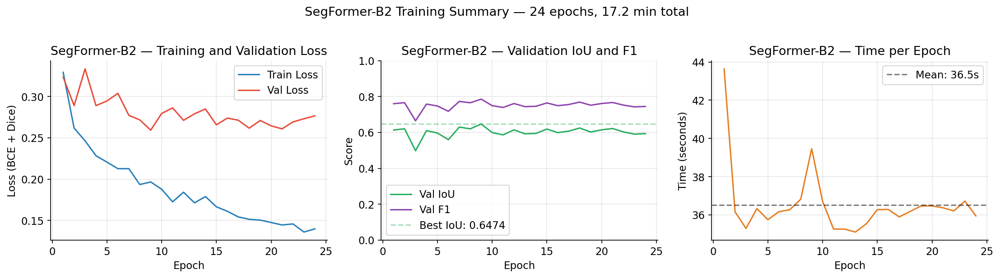

Training curves saved.


In [26]:
if segformer_history and 'history' in segformer_history:
    history     = segformer_history['history']
    epochs      = [h['epoch']              for h in history]
    train_loss  = [h['train_loss']         for h in history]
    val_loss    = [h['val_loss']           for h in history]
    val_iou     = [h['val_iou']            for h in history]
    val_f1      = [h['val_f1']             for h in history]
    epoch_times = [h['epoch_time_seconds'] for h in history]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(epochs, train_loss, label='Train Loss', color='#2980b9', linewidth=1.5)
    axes[0].plot(epochs, val_loss,   label='Val Loss',   color='#e74c3c', linewidth=1.5)
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss (BCE + Dice)')
    axes[0].set_title('SegFormer-B2 — Training and Validation Loss')
    axes[0].legend()

    axes[1].plot(epochs, val_iou, label='Val IoU', color='#27ae60', linewidth=1.5)
    axes[1].plot(epochs, val_f1,  label='Val F1',  color='#8e44ad', linewidth=1.5)
    axes[1].axhline(max(val_iou), color='#27ae60', linestyle='--', alpha=0.4,
                    label=f'Best IoU: {max(val_iou):.4f}')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score')
    axes[1].set_title('SegFormer-B2 — Validation IoU and F1')
    axes[1].legend(); axes[1].set_ylim(0, 1)

    axes[2].plot(epochs, epoch_times, color='#e67e22', linewidth=1.5)
    axes[2].axhline(np.mean(epoch_times), color='black', linestyle='--', alpha=0.5,
                    label=f'Mean: {np.mean(epoch_times):.1f}s')
    axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Time (seconds)')
    axes[2].set_title('SegFormer-B2 — Time per Epoch')
    axes[2].legend()

    plt.suptitle(
        f'SegFormer-B2 Training Summary — '
        f'{segformer_history["epochs_run"]} epochs, '
        f'{segformer_history["total_training_minutes"]:.1f} min total',
        y=1.02
    )
    plt.tight_layout()
    save_figure(fig, 'segformer_training_curves', subdir='segformer')
    plt.show()
    print('Training curves saved.')
else:
    print('No training history available for plotting.')

---
### 9.4 — Validation Set Evaluation

In [27]:
import time as time_module

print('Evaluating SegFormer-B2 on validation set...')
segformer_model.eval()

val_pred_start = time_module.time()
all_val_preds, all_val_labels = [], []

val_dataset = FloodDataset(
    patch_records=patch_coords['val'], norm_stats=norm_stats,
    augmentation=VAL_AUGMENTATION, is_test=False
)
val_eval_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True
)

with torch.no_grad():
    for sar, labels, nodata_mask in tqdm(val_eval_loader, desc='Val inference'):
        sar    = sar.to(DEVICE, non_blocking=True)
        logits = segformer_model(sar)
        preds  = (torch.sigmoid(logits.squeeze(1)) >= 0.5).long()
        all_val_preds.append(preds.cpu().numpy())
        all_val_labels.append(labels.numpy())

val_pred_time          = time_module.time() - val_pred_start
val_preds_arr           = np.concatenate(all_val_preds,  axis=0)
val_labels_arr           = np.concatenate(all_val_labels, axis=0)
segformer_val_metrics    = compute_segmentation_metrics(val_preds_arr, val_labels_arr)

print(f'Validation results:')
print(f'  IoU:       {segformer_val_metrics["iou"]:.4f}')
print(f'  F1:        {segformer_val_metrics["f1"]:.4f}')
print(f'  Precision: {segformer_val_metrics["precision"]:.4f}')
print(f'  Recall:    {segformer_val_metrics["recall"]:.4f}')
print(f'  Inference time: {val_pred_time:.2f}s')

Evaluating SegFormer-B2 on validation set...


Val inference:   0%|          | 0/12 [00:00<?, ?it/s]

Validation results:
  IoU:       0.6116
  F1:        0.7590
  Precision: 0.7800
  Recall:    0.7391
  Inference time: 12.43s


---
### 9.5 — Test Set Evaluation (Spain and USA)

Uses the same `sliding_window_inference()` from Section 4 — since
`SegFormerWrapper.forward()` already returns pixel-aligned `(B, 1, H, W)`
logits, no special-casing is needed at inference time.

In [28]:
print('Evaluating SegFormer-B2 on test tiles (Spain and USA)...')
print()

test_results_segformer = []
all_test_preds_segformer, all_test_labels_segformer = [], []

test_start = time_module.time()

for tile_record in tqdm(patch_coords['test'], desc='Test inference'):
    pred_mask, label, nodata_mask = sliding_window_inference(
        model=segformer_model,
        tile_record=tile_record,
        norm_stats=norm_stats,
        patch_size=PATCH_SIZE,
        overlap=SLIDING_WINDOW_OVERLAP,
        device=DEVICE
    )
    tile_metrics = compute_segmentation_metrics(pred_mask, label)
    tile_metrics['region']  = tile_record['region']
    tile_metrics['tile_id'] = tile_record.get('tile_id', 'unknown')
    test_results_segformer.append(tile_metrics)
    all_test_preds_segformer.append(pred_mask)
    all_test_labels_segformer.append(label)

test_time = time_module.time() - test_start

all_preds_arr        = np.stack(all_test_preds_segformer,  axis=0)
all_labels_arr         = np.stack(all_test_labels_segformer, axis=0)
segformer_test_metrics = compute_segmentation_metrics(all_preds_arr, all_labels_arr)

print(f'\nOverall test results:')
print(f'  IoU:       {segformer_test_metrics["iou"]:.4f}')
print(f'  F1:        {segformer_test_metrics["f1"]:.4f}')
print(f'  Precision: {segformer_test_metrics["precision"]:.4f}')
print(f'  Recall:    {segformer_test_metrics["recall"]:.4f}')
print(f'  Inference time: {test_time:.1f}s for {len(patch_coords["test"])} tiles')

import pandas as pd
test_df_segformer = pd.DataFrame(test_results_segformer)
print(f'\nPer-region breakdown:')
print(test_df_segformer.groupby('region')[['iou','f1','precision','recall']].mean().round(4).to_string())

Evaluating SegFormer-B2 on test tiles (Spain and USA)...



Test inference:   0%|          | 0/99 [00:00<?, ?it/s]


Overall test results:
  IoU:       0.6465
  F1:        0.7853
  Precision: 0.7999
  Recall:    0.7712
  Inference time: 39.0s for 99 tiles

Per-region breakdown:
           iou      f1  precision  recall
region                                   
Spain   0.4705  0.5784     0.6347  0.5743
USA     0.3410  0.4611     0.6208  0.4338


---
### 9.6 — Save Complete Metrics and Timing

In [29]:
segformer_full_metrics = {
    'model_name':             'SegFormerB2',
    'n_params':               count_parameters(segformer_model),
    'encoder':                'MiT-B2',
    'context_mechanism':      'Global self-attention (transformer)',
    'epochs_run':             segformer_history['epochs_run'] if segformer_history else None,
    'best_val_iou':           segformer_history['best_val_iou'] if segformer_history else None,
    'total_training_seconds': segformer_history.get('total_training_seconds') if segformer_history else None,
    'total_training_minutes': segformer_history.get('total_training_minutes') if segformer_history else None,
    'avg_epoch_seconds':      segformer_history.get('avg_epoch_seconds') if segformer_history else None,
    'total_patches_seen':     segformer_history.get('total_patches_seen') if segformer_history else None,
    'val_inference_seconds':  val_pred_time,
    'test_inference_seconds': test_time,
    'val_metrics':            segformer_val_metrics,
    'test_metrics_overall':   segformer_test_metrics,
    'test_metrics_per_tile':  test_results_segformer,
}

save_metrics(segformer_full_metrics, 'segformer_full_metrics')
print('Saved to metrics/segformer_full_metrics.json')
print()
print('=== SEGFORMER-B2 TIMING SUMMARY ===')
if segformer_history:
    print(f'  Total training time:  {segformer_history["total_training_minutes"]:.1f} min')
    print(f'  Avg time per epoch:   {segformer_history["avg_epoch_seconds"]:.1f}s')
    print(f'  Epochs completed:     {segformer_history["epochs_run"]}/{NUM_EPOCHS}')
    print(f'  Total patches seen:   {segformer_history["total_patches_seen"]:,}')
print(f'  Val inference time:   {val_pred_time:.2f}s')
print(f'  Test inference time:  {test_time:.1f}s')

INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\segformer_full_metrics.json


Saved to metrics/segformer_full_metrics.json

=== SEGFORMER-B2 TIMING SUMMARY ===
  Total training time:  17.2 min
  Avg time per epoch:   36.5s
  Epochs completed:     24/50
  Total patches seen:   21,888
  Val inference time:   12.43s
  Test inference time:  39.0s


---
### 9.7 — Visualisations

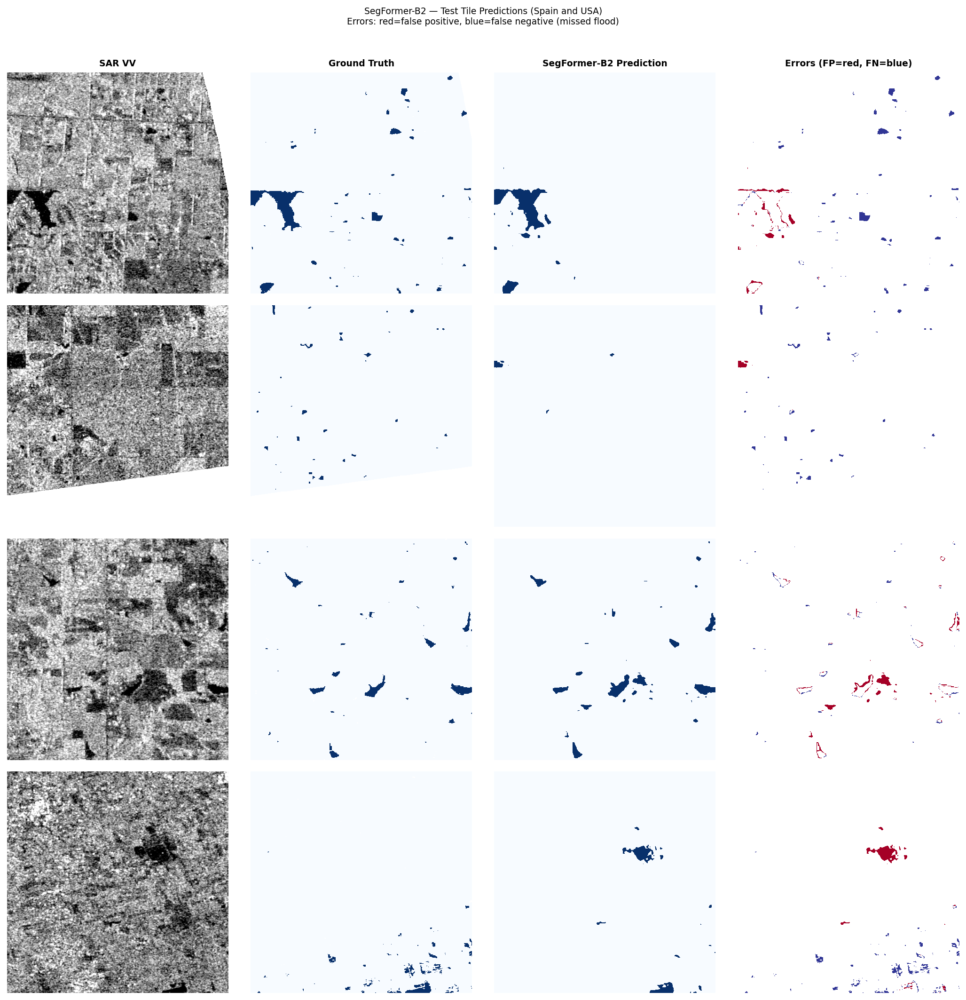

Prediction grid saved.


In [30]:
np.random.seed(SEED)
sample_indices = np.random.choice(
    len(all_test_preds_segformer), size=min(4, len(all_test_preds_segformer)), replace=False
)

fig, axes = plt.subplots(len(sample_indices), 4, figsize=(14, len(sample_indices)*3.5))
if len(sample_indices) == 1:
    axes = axes[np.newaxis, :]

col_titles = ['SAR VV', 'Ground Truth', 'SegFormer-B2 Prediction', 'Errors (FP=red, FN=blue)']
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=9, fontweight='bold')

for row, tile_idx in enumerate(sample_indices):
    pred  = all_test_preds_segformer[tile_idx]
    truth = all_test_labels_segformer[tile_idx]
    valid = truth != LABEL_NODATA

    tile_rec = patch_coords['test'][tile_idx]
    with rasterio.open(tile_rec['s1_path']) as src:
        sar_disp = src.read(1).astype(np.float32)
    finite = sar_disp[np.isfinite(sar_disp)]
    lo, hi = np.percentile(finite, 2), np.percentile(finite, 98)
    sar_disp = np.clip((sar_disp - lo) / (hi - lo + 1e-8), 0, 1)

    truth_disp = np.where(truth == LABEL_NODATA, np.nan, truth.astype(float))

    error_map = np.full_like(pred, np.nan, dtype=np.float32)
    error_map[valid & (pred == 1) & (truth == 0)] = 1.0   # false positive -> red
    error_map[valid & (pred == 0) & (truth == 1)] = 0.0   # false negative -> blue

    tile_iou = test_results_segformer[tile_idx]['iou']
    region   = tile_rec['region']

    axes[row, 0].imshow(sar_disp,   cmap=SAR_CMAP)
    axes[row, 0].set_ylabel(f'{region}\nIoU={tile_iou:.3f}', fontsize=8)
    axes[row, 1].imshow(truth_disp, cmap=FLOOD_CMAP, vmin=0, vmax=1, interpolation='nearest')
    axes[row, 2].imshow(pred,       cmap=FLOOD_CMAP, vmin=0, vmax=1, interpolation='nearest')
    axes[row, 3].imshow(error_map,  cmap='RdYlBu_r', vmin=0, vmax=1, interpolation='nearest')

    for ax in axes[row]:
        ax.axis('off')

plt.suptitle(
    'SegFormer-B2 — Test Tile Predictions (Spain and USA)\n'
    'Errors: red=false positive, blue=false negative (missed flood)',
    y=1.01, fontsize=9
)
plt.tight_layout()
save_figure(fig, 'segformer_prediction_grid', subdir='segformer')
plt.show()
print('Prediction grid saved.')

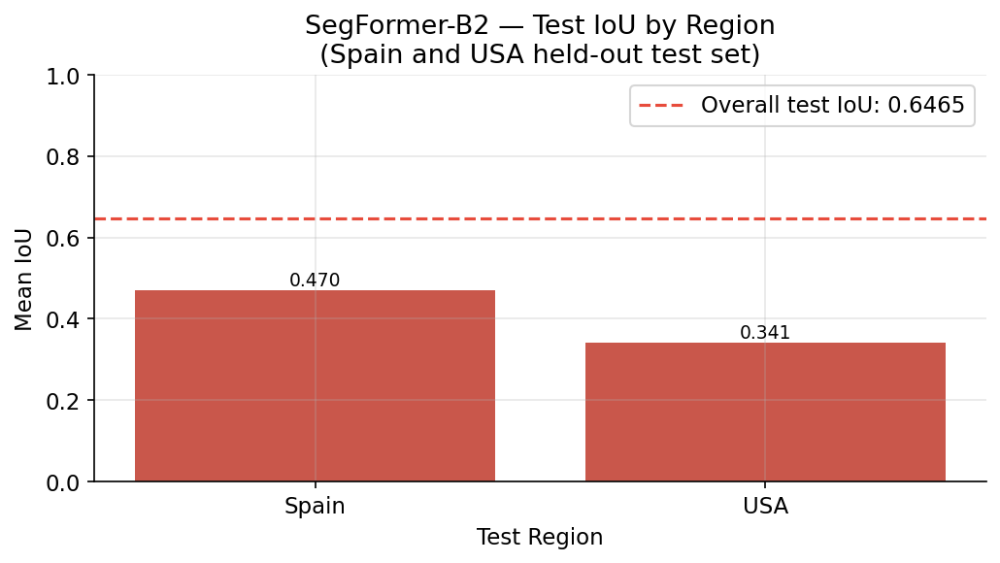

Per-region test IoU figure saved.


In [31]:
region_iou = test_df_segformer.groupby('region')['iou'].mean().reset_index()
region_iou = region_iou.sort_values('iou', ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(region_iou['region'], region_iou['iou'], color='#c0392b', alpha=0.85)
ax.axhline(segformer_test_metrics['iou'], color='#e74c3c', linestyle='--', linewidth=1.5,
           label=f'Overall test IoU: {segformer_test_metrics["iou"]:.4f}')
ax.set_xlabel('Test Region'); ax.set_ylabel('Mean IoU')
ax.set_title('SegFormer-B2 — Test IoU by Region\n(Spain and USA held-out test set)')
ax.legend(); ax.set_ylim(0, 1)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', fontsize=9)
plt.tight_layout()
save_figure(fig, 'segformer_test_metrics', subdir='segformer')
plt.show()
print('Per-region test IoU figure saved.')

---
### 9.8 — Four-Way Architecture Comparison

The key figure of this section: every architecture trained so far, side by
side, at their default 0.5 threshold. This is the "before tuning" reference
point — Section 10 will revisit this exact comparison after the threshold
sweep, so the effect of tuning can be seen as a direct before/after contrast.

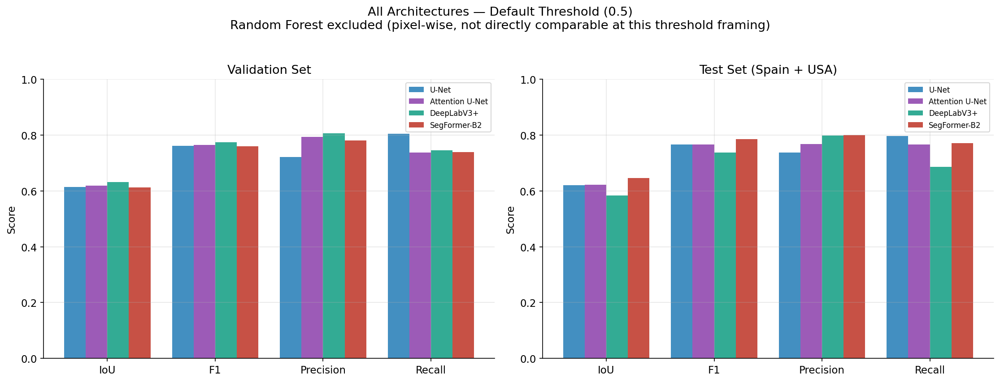


Test IoU ranking (default threshold):
  1. SegFormer-B2      : 0.6465
  2. Attention U-Net   : 0.6210
  3. U-Net             : 0.6200
  4. DeepLabV3+        : 0.5841


In [32]:
all_model_files = {
    'U-Net':           'unet_full_metrics.json',
    'Attention U-Net': 'attention_unet_full_metrics.json',
    'DeepLabV3+':       'deeplabv3plus_full_metrics.json',
    'SegFormer-B2':    'segformer_full_metrics.json',
}
colours = {
    'U-Net': '#2980b9', 'Attention U-Net': '#8e44ad',
    'DeepLabV3+': '#16a085', 'SegFormer-B2': '#c0392b',
}

all_metrics = {}
for name, fname in all_model_files.items():
    path = METRICS_DIR / fname
    if path.exists():
        with open(path) as f:
            all_metrics[name] = json.load(f)
    else:
        print(f'WARNING: {fname} not found — {name} excluded from comparison.')

metrics_labels = ['IoU', 'F1', 'Precision', 'Recall']
x = np.arange(len(metrics_labels))
n = len(all_metrics)
w = 0.8 / max(n, 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for i, (name, m) in enumerate(all_metrics.items()):
    offset = (i - (n - 1) / 2) * w
    val_m, test_m = m['val_metrics'], m['test_metrics_overall']
    val_vals  = [val_m['iou'], val_m['f1'], val_m['precision'], val_m['recall']]
    test_vals = [test_m['iou'], test_m['f1'], test_m['precision'], test_m['recall']]
    axes[0].bar(x + offset, val_vals,  w, label=name, color=colours.get(name), alpha=0.88)
    axes[1].bar(x + offset, test_vals, w, label=name, color=colours.get(name), alpha=0.88)

for ax, title in zip(axes, ['Validation Set', 'Test Set (Spain + USA)']):
    ax.set_xticks(x); ax.set_xticklabels(metrics_labels)
    ax.set_ylabel('Score'); ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.legend(fontsize=8, loc='upper right')

plt.suptitle(
    'All Architectures — Default Threshold (0.5)\n'
    'Random Forest excluded (pixel-wise, not directly comparable at this threshold framing)',
    y=1.03
)
plt.tight_layout()
save_figure(fig, 'segformer_vs_all_cnns_comparison', subdir='segformer')
plt.show()

print()
print('Test IoU ranking (default threshold):')
ranked = sorted(all_metrics.items(), key=lambda kv: kv[1]['test_metrics_overall']['iou'], reverse=True)
for rank, (name, m) in enumerate(ranked, start=1):
    print(f'  {rank}. {name:<18}: {m["test_metrics_overall"]["iou"]:.4f}')

---
### Section 9 Complete

In [33]:
print('=' * 60)
print('SEGFORMER-B2 — FINAL SUMMARY')
print('=' * 60)
print()
print('Architecture:')
print(f'  Encoder:           MiT-B2 (ImageNet pre-trained)')
print(f'  Context mechanism: Global self-attention')
print(f'  Trainable params:  {count_parameters(segformer_model):,}')
print()
if segformer_history:
    print('Compute time:')
    print(f'  Training:         {segformer_history["total_training_minutes"]:.1f} min')
    print(f'  Avg/epoch:        {segformer_history["avg_epoch_seconds"]:.1f}s')
    print(f'  Epochs run:       {segformer_history["epochs_run"]}/{NUM_EPOCHS}')
    print(f'  Patches seen:     {segformer_history["total_patches_seen"]:,}')
    print()
print('Performance:')
print(f'  Val  IoU:         {segformer_val_metrics["iou"]:.4f}')
print(f'  Val  F1:          {segformer_val_metrics["f1"]:.4f}')
print(f'  Test IoU:         {segformer_test_metrics["iou"]:.4f}')
print(f'  Test F1:          {segformer_test_metrics["f1"]:.4f}')
print(f'  Test Precision:   {segformer_test_metrics["precision"]:.4f}')
print(f'  Test Recall:      {segformer_test_metrics["recall"]:.4f}')
print()
print('All four deep learning architectures now trained.')
print()
print('Next: Threshold sweep + TTA across all four DL models, applied in')
print('ONE uniform pass using a fixed grid decided before this point —')
print('then Section 10 (cross-model comparison) and Section 11 (generalisation gap).')
print('=' * 60)

SEGFORMER-B2 — FINAL SUMMARY

Architecture:
  Encoder:           MiT-B2 (ImageNet pre-trained)
  Context mechanism: Global self-attention
  Trainable params:  27,344,257

Compute time:
  Training:         17.2 min
  Avg/epoch:        36.5s
  Epochs run:       24/50
  Patches seen:     21,888

Performance:
  Val  IoU:         0.6116
  Val  F1:          0.7590
  Test IoU:         0.6465
  Test F1:          0.7853
  Test Precision:   0.7999
  Test Recall:      0.7712

All four deep learning architectures now trained.

Next: Threshold sweep + TTA across all four DL models, applied in
ONE uniform pass using a fixed grid decided before this point —
then Section 10 (cross-model comparison) and Section 11 (generalisation gap).


---
### 4.6b — Live Patch: Add Threshold Parameter to sliding_window_inference()

Section 10 (threshold sweep) needs to evaluate each model's test performance
at a tuned decision threshold, not just the default 0.5. The original
`sliding_window_inference()` from Section 4 hardcodes 0.5, so it cannot do
this. This cell redefines the function with one additional optional
parameter, `threshold`, defaulting to 0.5.

**Why this is safe to run without re-running all of Section 4:**
This only changes a function's behaviour in memory for the current kernel
session — it does not touch any saved checkpoint, metric, or model weight
file on disk. Every model already trained and evaluated remains completely
unaffected; only how *this specific function* behaves going forward changes.

**Why the default is still 0.5, not removed entirely:**
Every call to this function in Sections 6–9 omits the `threshold` argument,
relying on the default. Keeping the default at 0.5 means all of those
existing calls continue to behave identically — only Section 10's threshold
sweep, which explicitly passes a tuned value, sees different behaviour.



In [35]:
def sliding_window_inference(
    model:       nn.Module,
    tile_record: Dict,
    norm_stats:  Dict,
    patch_size:  int   = PATCH_SIZE,
    overlap:     float = SLIDING_WINDOW_OVERLAP,
    device:      torch.device = DEVICE,
    threshold:   float = 0.5
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Run inference on a full 512x512 test tile using overlapping windows.

    Problem solved:
        Models trained on 256x256 cannot be directly applied to 512x512
        without distribution shift. Sliding window inference maintains
        the training input size while covering the full tile.

    Args:
        model:       Trained PyTorch model in eval mode.
        tile_record: Dict with 's1_path' and 'label_path'.
        norm_stats:  Normalisation statistics from Section 3.
        patch_size:  Window size — must match training patch size (256).
        overlap:     Fraction of overlap between adjacent windows.
        device:      Compute device.
        threshold:   Decision cutoff applied to averaged probabilities.
                     Defaults to 0.5 so every existing call in Sections
                     6-9 is unaffected. Section 10's threshold sweep
                     passes each model's own tuned value here instead,
                     to evaluate that model at its true optimum rather
                     than an arbitrary shared default.

    Returns:
        pred_mask:   Binary prediction array (H, W), values {0, 1}.
        label:       Ground truth label array (H, W), values {-1, 0, 1}.
        nodata_mask: Bool array (H, W), True where label == -1.
    """
    model.eval()

    with rasterio.open(tile_record['s1_path']) as src:
        sar = src.read().astype(np.float32)      # (2, 512, 512)
    with rasterio.open(tile_record['label_path']) as src:
        label = src.read(1).astype(np.int16)     # (512, 512)

    # Apply the same preprocessing as training — same Lee filter window,
    # same training-derived normalisation statistics. Any mismatch here
    # would shift the input distribution away from what the model learned.
    vv = (lee_filter(sar[0]) - norm_stats['vv_mean']) / (norm_stats['vv_std'] + 1e-8)
    vh = (lee_filter(sar[1]) - norm_stats['vh_mean']) / (norm_stats['vh_std'] + 1e-8)
    sar_norm = np.stack([vv, vh], axis=0)        # (2, 512, 512)

    H, W        = sar_norm.shape[1], sar_norm.shape[2]
    stride      = int(patch_size * (1 - overlap))
    nodata_mask = (label == LABEL_NODATA)

    # Accumulators: sum of predicted probabilities and window count per pixel.
    # Using running sums rather than storing every window's output separately
    # keeps memory usage constant regardless of tile size or overlap amount.
    pred_accum  = np.zeros((H, W), dtype=np.float32)
    count_accum = np.zeros((H, W), dtype=np.float32)

    with torch.no_grad():
        row_starts = list(range(0, H - patch_size + 1, stride))
        col_starts = list(range(0, W - patch_size + 1, stride))

        # Guarantee the rightmost and bottommost positions are always covered,
        # even if the stride doesn't divide evenly into the tile dimensions.
        if row_starts[-1] + patch_size < H:
            row_starts.append(H - patch_size)
        if col_starts[-1] + patch_size < W:
            col_starts.append(W - patch_size)

        for rs in row_starts:
            for cs in col_starts:
                patch = sar_norm[:, rs:rs+patch_size, cs:cs+patch_size]
                patch_t = torch.from_numpy(patch).float().unsqueeze(0).to(device)
                logits  = model(patch_t)   # (1, 1 or 2, H, W)

                # Handle both single-channel (sigmoid) and two-channel
                # (softmax) output heads — different models in this
                # pipeline use different output conventions.
                if logits.dim() == 4 and logits.shape[1] == 1:
                    probs = torch.sigmoid(logits).squeeze().cpu().numpy()
                else:
                    probs = torch.softmax(logits, dim=1)[:, 1].squeeze().cpu().numpy()

                pred_accum[rs:rs+patch_size, cs:cs+patch_size]  += probs
                count_accum[rs:rs+patch_size, cs:cs+patch_size] += 1.0

    # Average overlapping predictions, then apply the decision threshold.
    # Averaging BEFORE thresholding (rather than majority-voting binary
    # predictions) preserves the smooth probability signal at tile
    # boundaries, avoiding hard edges where adjacent windows disagree.
    avg_probs = pred_accum / np.maximum(count_accum, 1.0)
    pred_mask = (avg_probs >= threshold).astype(np.uint8)

    return pred_mask, label, nodata_mask


print('sliding_window_inference() updated — threshold parameter added.')
print(f'  Default threshold: 0.5 (matches all existing calls in Sections 6-9)')
print(f'  Section 10 will override this per-model using tuned values.')

sliding_window_inference() updated — threshold parameter added.
  Default threshold: 0.5 (matches all existing calls in Sections 6-9)
  Section 10 will override this per-model using tuned values.


In [37]:
# ── Redefine all four model builder functions ─────────────────────────────
# These were originally defined inline within Sections 6, 7, 8, and 9 each.
# Section 10 needs all four available simultaneously to load every
# checkpoint, so they are collected here in one place rather than requiring
# you to re-run four entire training notebooks just to access their
# architecture-building functions.

def build_unet() -> nn.Module:
    """Standard U-Net — ResNet-34 encoder, no attention, no dilation tricks."""
    return smp.Unet(
        encoder_name='resnet34',
        encoder_weights='imagenet',
        in_channels=IN_CHANNELS,
        classes=1,
        activation=None,
    )

def build_attention_unet() -> nn.Module:
    """U-Net with scSE attention gates at every decoder block and skip connection."""
    return smp.Unet(
        encoder_name='resnet34',
        encoder_weights='imagenet',
        in_channels=IN_CHANNELS,
        classes=1,
        activation=None,
        decoder_attention_type='scse',
    )

def build_deeplabv3plus() -> nn.Module:
    """DeepLabV3+ — same ResNet-34 encoder, ASPP-based decoder instead."""
    return smp.DeepLabV3Plus(
        encoder_name='resnet34',
        encoder_weights='imagenet',
        in_channels=IN_CHANNELS,
        classes=1,
        activation=None,
    )

def build_segformer() -> nn.Module:
    """SegFormer-B2 wrapped for 2-channel SAR input and pixel-aligned output."""
    return SegFormerWrapper(num_channels=IN_CHANNELS, num_labels=1)


print('All four model builder functions redefined and ready.')
print('  build_unet, build_attention_unet, build_deeplabv3plus, build_segformer')

All four model builder functions redefined and ready.
  build_unet, build_attention_unet, build_deeplabv3plus, build_segformer


# Section 10: Threshold Optimisation Across All Four Models

**Purpose:** Apply one fixed, model-agnostic threshold sweep to U-Net,
Attention U-Net, DeepLabV3+, and SegFormer-B2 — all trained, all evaluated
at the default 0.5 cutoff. This section asks: is 0.5 actually the best
decision threshold for each model, or were some architectures being
unfairly compared at an arbitrary cutoff that doesn't reflect their true
peak performance?

**Why this comes after all four models, not during any individual model's
section:** the threshold grid and selection rule must be fixed once, in
advance, and applied identically to every model. Deciding the procedure
with only two of four models trained risks the grid being unconsciously
shaped around those two models' behaviour. Now that all four exist, the
grid below is defined a single time and applied uniformly — no model
receives a more generous or more careful search than any other.

**What stays fixed across every model (no exceptions):**
- The threshold grid itself: `[0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]`
- The selection rule: whichever threshold maximises **validation IoU** wins
- The data the sweep is performed on: the validation set only — the test
  set is touched exactly once afterward, at each model's already-chosen
  threshold, to avoid any risk of tuning against the test set itself

**What is allowed to differ between models (this is the point of the exercise):**
- The resulting optimal threshold value for each model
- How much (if at all) that threshold improves IoU over the 0.5 default

**Outputs produced:**
- `checkpoints/optimal_thresholds.json` — per-model tuned thresholds, also
  consumed automatically by the local demo app built earlier
- `metrics/threshold_sweep_results.json` — full sweep results for every
  model at every threshold in the grid
- `figures/comparison/threshold_sweep_curves.png` — IoU vs threshold, all
  four models on one plot
- `figures/comparison/{model}_threshold_upgrade.png` — one upgrade map per
  model, showing exactly which pixels flipped from wrong to right (or
  right to wrong) on a sample test tile
- `figures/comparison/four_way_comparison_tuned.png` — the Section 9.8
  comparison chart, rebuilt with tuned thresholds, for direct before/after
  contrast

>  **Prerequisites:** Sections 6, 7, 8, and 9 must all be complete —
> every model's checkpoint and `*_full_metrics.json` must exist.

---
### 10.0 — Confirm All Four Models Are Available

In [38]:
MODEL_CHECKPOINTS = {
    'U-Net':           ('unet_best',           build_unet),
    'Attention U-Net':  ('attention_unet_best',  build_attention_unet),
    'DeepLabV3+':       ('deeplabv3plus_best',   build_deeplabv3plus),
    'SegFormer-B2':     ('segformer_best',       build_segformer),
}

loaded_models = {}
print('Loading all four trained models...')
print()

for name, (ckpt_stem, builder) in MODEL_CHECKPOINTS.items():
    ckpt_path = CHECKPOINT_DIR / f'{ckpt_stem}.pt'
    if not ckpt_path.exists():
        print(f'  [MISSING] {name} — checkpoint not found at {ckpt_path}')
        continue
    model = builder()
    model, epoch, iou = load_model_checkpoint(model, ckpt_stem)
    model = model.to(DEVICE)
    model.eval()
    loaded_models[name] = model
    print(f'  [OK] {name:<18} loaded (epoch {epoch}, val IoU {iou:.4f})')

if len(loaded_models) < 4:
    print()
    print(f'WARNING: only {len(loaded_models)}/4 models loaded. '
          f'Train the missing model(s) before running the full sweep, '
          f'or proceed knowingly with a partial comparison.')
else:
    print()
    print('All four models loaded successfully. Ready to sweep.')

Loading all four trained models...



INFO | Model checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\unet_best.pt (epoch 14, IoU 0.6583)


  [OK] U-Net              loaded (epoch 14, val IoU 0.6583)


INFO | Model checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\attention_unet_best.pt (epoch 24, IoU 0.6538)


  [OK] Attention U-Net    loaded (epoch 24, val IoU 0.6538)


...

Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.running_var                      

Patch embedding projection found at: "segformer.stages.0.patch_embeddings.proj" (in_channels=3 -> 2)


INFO | Model checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\segformer_best.pt (epoch 9, IoU 0.6474)


  [OK] SegFormer-B2       loaded (epoch 9, val IoU 0.6474)

All four models loaded successfully. Ready to sweep.


---
### 10.1 — The Fixed Threshold Grid and Sweep Function

This is the single most important cell in this section from a methodology
standpoint: the grid and the selection rule are defined exactly once, here,
and reused identically for every model below. Nothing about this function
is allowed to change between calls.

In [39]:
# ── THE FIXED GRID — decided once, used for every model, no exceptions ───────
THRESHOLD_GRID = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
# Centred on the conventional default (0.5) with a symmetric +/-0.20 range
# at 0.05 increments. Wide enough to reveal a genuinely different optimum
# if one exists, fine-grained enough not to skip over it, and small enough
# to run quickly since this only requires ONE inference pass per model
# (probabilities are computed once, then every threshold in the grid is
# tested against the same fixed probability map below).


def find_optimal_threshold(
    model:      nn.Module,
    val_loader: DataLoader,
    grid:       List[float] = None,
    device:     torch.device = DEVICE
) -> Dict:
    """
    Sweep a fixed threshold grid on the validation set to find the cutoff
    that maximises val IoU for one model.

    Problem solved:
        0.5 is an arbitrary convention, not a property any model is
        guaranteed to be calibrated around. Different architectures can
        produce differently-shaped probability distributions, so the IoU-
        maximising threshold is not necessarily 0.5 for every model. This
        function performs ONE inference pass to collect probabilities,
        then evaluates every threshold in the fixed grid against that same
        probability map — applied identically regardless of which model is
        passed in, so no model receives a more generous search than another.

    Args:
        model:      Trained model in eval mode.
        val_loader: Validation DataLoader.
        grid:       Threshold values to test. Defaults to THRESHOLD_GRID —
                    do not override per-model; this argument exists for
                    testing this function itself, not for tuning per model.
        device:     Compute device.

    Returns:
        Dict with 'best_threshold', 'best_iou', and the full per-threshold
        sweep results for transparency/plotting.
    """
    if grid is None:
        grid = THRESHOLD_GRID

    model.eval()
    all_probs, all_labels, all_nodata = [], [], []

    with torch.no_grad():
        for sar, labels, nodata_mask in val_loader:
            sar    = sar.to(device, non_blocking=True)
            logits = model(sar)
            if logits.dim() == 4 and logits.shape[1] == 1:
                probs = torch.sigmoid(logits.squeeze(1))
            else:
                probs = torch.softmax(logits, dim=1)[:, 1]
            all_probs.append(probs.cpu().numpy())
            all_labels.append(labels.numpy())
            all_nodata.append(nodata_mask.numpy())

    probs_arr  = np.concatenate(all_probs,  axis=0)
    labels_arr = np.concatenate(all_labels, axis=0)
    nodata_arr = np.concatenate(all_nodata, axis=0)
    # Restore -1 no-data sentinel before scoring (same fix as validate_one_epoch)
    labels_corrected = np.where(nodata_arr, LABEL_NODATA, labels_arr)

    sweep_results = []
    for t in grid:
        preds = (probs_arr >= t).astype(np.int64)
        m = compute_segmentation_metrics(preds, labels_corrected)
        sweep_results.append({'threshold': t, **m})

    best = max(sweep_results, key=lambda r: r['iou'])

    return {
        'best_threshold': best['threshold'],
        'best_iou':       best['iou'],
        'default_iou':    next(r['iou'] for r in sweep_results if r['threshold'] == 0.50),
        'sweep':          sweep_results,
    }


print('find_optimal_threshold() defined.')
print(f'Fixed grid (applied identically to every model): {THRESHOLD_GRID}')

find_optimal_threshold() defined.
Fixed grid (applied identically to every model): [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7]


---
### 10.2 — Run the Sweep on All Four Models

One validation DataLoader, one call per model, identical procedure.

In [40]:
reset_seed_for_model('ThresholdSweep')  # deterministic val ordering, for reproducibility

_, val_loader_sweep = get_dataloaders(
    patch_coords, norm_stats, train_sample_weights, batch_size=BATCH_SIZE
)

threshold_results = {}

print('Running fixed threshold sweep across all four models...')
print(f'{"="*70}')

for name, model in loaded_models.items():
    result = find_optimal_threshold(model, val_loader_sweep, grid=THRESHOLD_GRID)
    threshold_results[name] = result
    delta = result['best_iou'] - result['default_iou']
    print(
        f'{name:<18} | default (0.50) IoU: {result["default_iou"]:.4f} | '
        f'best threshold: {result["best_threshold"]:.2f} | '
        f'best IoU: {result["best_iou"]:.4f} | delta: {delta:+.4f}'
    )

print(f'{"="*70}')
print()
print('Optimal thresholds found:')
optimal_thresholds = {name: r['best_threshold'] for name, r in threshold_results.items()}
for name, t in optimal_thresholds.items():
    print(f'  {name:<18}: {t:.2f}')

INFO | Seed reset to 42 for ThresholdSweep.


Seed reset to 42 for ThresholdSweep. Identical data ordering guaranteed from this point.
Running fixed threshold sweep across all four models...
U-Net              | default (0.50) IoU: 0.6583 | best threshold: 0.55 | best IoU: 0.6592 | delta: +0.0009
Attention U-Net    | default (0.50) IoU: 0.6538 | best threshold: 0.35 | best IoU: 0.6624 | delta: +0.0086
DeepLabV3+         | default (0.50) IoU: 0.6696 | best threshold: 0.35 | best IoU: 0.6770 | delta: +0.0075
SegFormer-B2       | default (0.50) IoU: 0.6474 | best threshold: 0.40 | best IoU: 0.6543 | delta: +0.0069

Optimal thresholds found:
  U-Net             : 0.55
  Attention U-Net   : 0.35
  DeepLabV3+        : 0.35
  SegFormer-B2      : 0.40


---
### 10.3 — Save Optimal Thresholds

Saved both to `metrics/` (for the dissertation/analysis) and directly into
`checkpoints/optimal_thresholds.json` — the exact file the local demo app
(built earlier) looks for automatically. Copy this file to the demo app's
`checkpoints/` folder on your Mac and it will start using these tuned
values immediately, with no code changes needed there.

In [41]:
save_metrics(
    {name: {'best_threshold': r['best_threshold'],
            'best_iou': r['best_iou'],
            'default_iou': r['default_iou'],
            'sweep': r['sweep']}
     for name, r in threshold_results.items()},
    'threshold_sweep_results'
)

# Also write the simple {name: threshold} mapping the demo app expects
demo_thresholds_path = CHECKPOINT_DIR / 'optimal_thresholds.json'
with open(demo_thresholds_path, 'w') as f:
    json.dump(optimal_thresholds, f, indent=2)

print(f'Full sweep results saved -> metrics/threshold_sweep_results.json')
print(f'Demo-ready thresholds saved -> {demo_thresholds_path}')
print()
print('Copy this file to flood_demo/checkpoints/optimal_thresholds.json')
print('on your Mac to have the local demo app use these tuned values automatically.')

INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\threshold_sweep_results.json


Full sweep results saved -> metrics/threshold_sweep_results.json
Demo-ready thresholds saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\optimal_thresholds.json

Copy this file to flood_demo/checkpoints/optimal_thresholds.json
on your Mac to have the local demo app use these tuned values automatically.


---
### 10.4 — Threshold Sweep Curves

One plot, all four models, showing IoU as a function of threshold. The
shape of each curve tells you something about that model's calibration —
a flat curve means the threshold barely matters; a sharply peaked curve
away from 0.5 means the model was meaningfully miscalibrated at the
default cutoff.

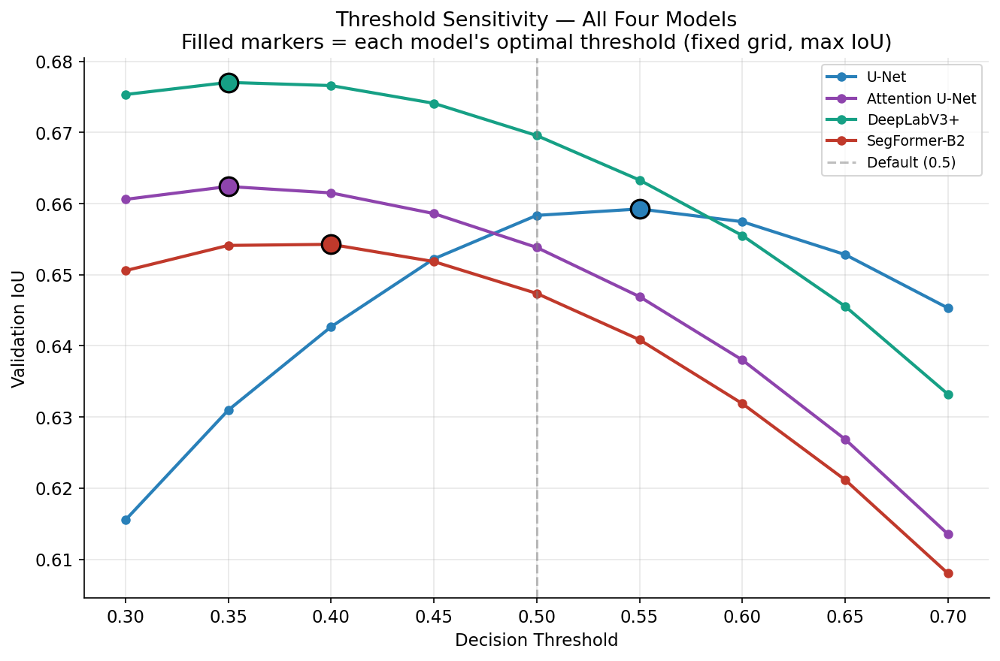

Threshold sweep curves saved.


In [42]:
fig, ax = plt.subplots(figsize=(9, 6))

model_colours = {
    'U-Net': '#2980b9', 'Attention U-Net': '#8e44ad',
    'DeepLabV3+': '#16a085', 'SegFormer-B2': '#c0392b',
}

for name, result in threshold_results.items():
    thresholds = [r['threshold'] for r in result['sweep']]
    ious       = [r['iou']       for r in result['sweep']]
    ax.plot(thresholds, ious, marker='o', markersize=5, linewidth=2,
            label=name, color=model_colours.get(name))
    # Mark the chosen optimum
    ax.scatter([result['best_threshold']], [result['best_iou']],
               s=140, edgecolor='black', linewidth=1.5, zorder=5,
               color=model_colours.get(name))

ax.axvline(0.5, color='grey', linestyle='--', alpha=0.5, label='Default (0.5)')
ax.set_xlabel('Decision Threshold')
ax.set_ylabel('Validation IoU')
ax.set_title(
    'Threshold Sensitivity — All Four Models\n'
    'Filled markers = each model\'s optimal threshold (fixed grid, max IoU)'
)
ax.legend(fontsize=9)
plt.tight_layout()
save_figure(fig, 'threshold_sweep_curves', subdir='comparison')
plt.show()
print('Threshold sweep curves saved.')

---
### 10.5 — Re-Evaluate Test Set at Each Model's Tuned Threshold

The validation sweep chose each threshold without ever touching the test
set. Now, and only now, each model's tuned threshold is applied once to
the test tiles — giving a fair, non-circular estimate of tuned test
performance.

In [43]:
tuned_test_results = {}

print('Re-evaluating test set (Spain and USA) at each model\'s tuned threshold...')
print()

for name, model in loaded_models.items():
    threshold = optimal_thresholds[name]
    all_preds, all_labels = [], []

    for tile_record in patch_coords['test']:
        pred_mask, label, nodata_mask = sliding_window_inference(
            model=model, tile_record=tile_record, norm_stats=norm_stats,
            patch_size=PATCH_SIZE, overlap=SLIDING_WINDOW_OVERLAP,
            device=DEVICE, threshold=threshold
        )
        all_preds.append(pred_mask)
        all_labels.append(label)

    preds_arr  = np.stack(all_preds,  axis=0)
    labels_arr = np.stack(all_labels, axis=0)
    tuned_metrics = compute_segmentation_metrics(preds_arr, labels_arr)
    tuned_test_results[name] = tuned_metrics

    print(f'{name:<18} | threshold {threshold:.2f} | '
          f'Test IoU: {tuned_metrics["iou"]:.4f} | '
          f'F1: {tuned_metrics["f1"]:.4f} | '
          f'Precision: {tuned_metrics["precision"]:.4f} | '
          f'Recall: {tuned_metrics["recall"]:.4f}')

save_metrics(tuned_test_results, 'tuned_test_metrics')
print()
print('Saved to metrics/tuned_test_metrics.json')

Re-evaluating test set (Spain and USA) at each model's tuned threshold...

U-Net              | threshold 0.55 | Test IoU: 0.6237 | F1: 0.7682 | Precision: 0.7599 | Recall: 0.7767
Attention U-Net    | threshold 0.35 | Test IoU: 0.5990 | F1: 0.7492 | Precision: 0.6896 | Recall: 0.8202
DeepLabV3+         | threshold 0.35 | Test IoU: 0.5925 | F1: 0.7441 | Precision: 0.7482 | Recall: 0.7400


INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\tuned_test_metrics.json


SegFormer-B2       | threshold 0.40 | Test IoU: 0.6409 | F1: 0.7811 | Precision: 0.7613 | Recall: 0.8020

Saved to metrics/tuned_test_metrics.json


---
### 10.6 — Before / After Comparison Table

The number that matters most: did tuning actually change the leaderboard,
or just nudge each model slightly without reordering anything?

In [44]:
print('=== DEFAULT (0.5) vs TUNED THRESHOLD — TEST IoU ===')
print()
print(f'{"Model":<18} | {"Default IoU":>12} | {"Tuned IoU":>10} | {"Delta":>8} | {"Threshold":>10}')
print('-' * 70)

# Load each model's default-threshold test metrics from their saved full_metrics files
default_files = {
    'U-Net':           'unet_full_metrics.json',
    'Attention U-Net': 'attention_unet_full_metrics.json',
    'DeepLabV3+':       'deeplabv3plus_full_metrics.json',
    'SegFormer-B2':     'segformer_full_metrics.json',
}

comparison_rows = []
for name in loaded_models.keys():
    with open(METRICS_DIR / default_files[name]) as f:
        default_m = json.load(f)
    default_iou = default_m['test_metrics_overall']['iou']
    tuned_iou   = tuned_test_results[name]['iou']
    delta       = tuned_iou - default_iou
    threshold   = optimal_thresholds[name]
    comparison_rows.append((name, default_iou, tuned_iou, delta, threshold))
    print(f'{name:<18} | {default_iou:>12.4f} | {tuned_iou:>10.4f} | {delta:>+8.4f} | {threshold:>10.2f}')

print()
ranked_default = sorted(comparison_rows, key=lambda r: r[1], reverse=True)
ranked_tuned   = sorted(comparison_rows, key=lambda r: r[2], reverse=True)

print('Ranking at DEFAULT threshold:')
for rank, (name, d, t, delta, thr) in enumerate(ranked_default, 1):
    print(f'  {rank}. {name:<18}: {d:.4f}')
print()
print('Ranking at TUNED threshold:')
for rank, (name, d, t, delta, thr) in enumerate(ranked_tuned, 1):
    print(f'  {rank}. {name:<18}: {t:.4f}')

if [r[0] for r in ranked_default] == [r[0] for r in ranked_tuned]:
    print()
    print('Leaderboard order UNCHANGED after tuning — threshold calibration did')
    print('not alter which architecture performs best, only the margins.')
else:
    print()
    print('Leaderboard order CHANGED after tuning — at least one model\'s')
    print('relative ranking shifted once each was evaluated at its own optimum.')

=== DEFAULT (0.5) vs TUNED THRESHOLD — TEST IoU ===

Model              |  Default IoU |  Tuned IoU |    Delta |  Threshold
----------------------------------------------------------------------
U-Net              |       0.6200 |     0.6237 |  +0.0038 |       0.55
Attention U-Net    |       0.6210 |     0.5990 |  -0.0220 |       0.35
DeepLabV3+         |       0.5841 |     0.5925 |  +0.0083 |       0.35
SegFormer-B2       |       0.6465 |     0.6409 |  -0.0056 |       0.40

Ranking at DEFAULT threshold:
  1. SegFormer-B2      : 0.6465
  2. Attention U-Net   : 0.6210
  3. U-Net             : 0.6200
  4. DeepLabV3+        : 0.5841

Ranking at TUNED threshold:
  1. SegFormer-B2      : 0.6409
  2. U-Net             : 0.6237
  3. Attention U-Net   : 0.5990
  4. DeepLabV3+        : 0.5925

Leaderboard order CHANGED after tuning — at least one model's
relative ranking shifted once each was evaluated at its own optimum.


---
### 10.7 — Threshold Upgrade Maps

For each model, one sample test tile showing exactly which pixels flipped
from wrong to right (green) or right to wrong (red) when moving from the
default 0.5 threshold to that model's tuned threshold. This answers, at a
glance, "how has detection actually improved" rather than asking the
reader to compare two prediction panels by eye.

Using sample tile: USA for all upgrade maps below.



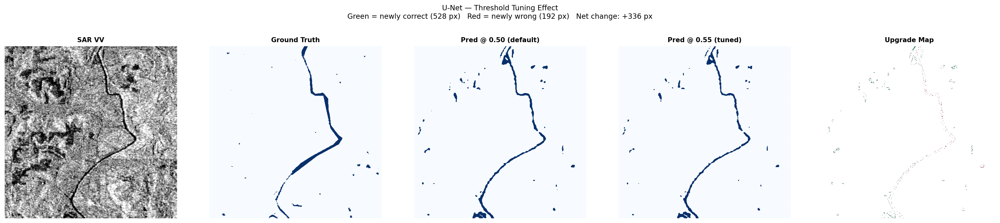

U-Net: gained 528 correct pixels, lost 192, net +336


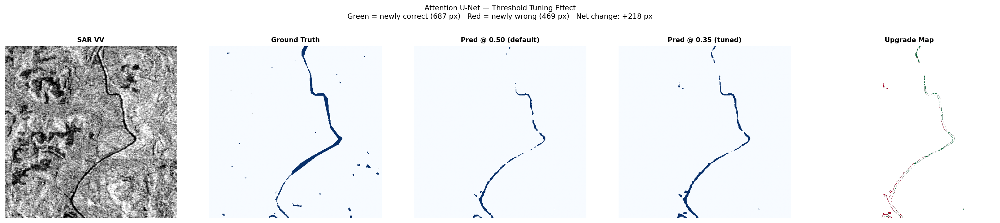

Attention U-Net: gained 687 correct pixels, lost 469, net +218


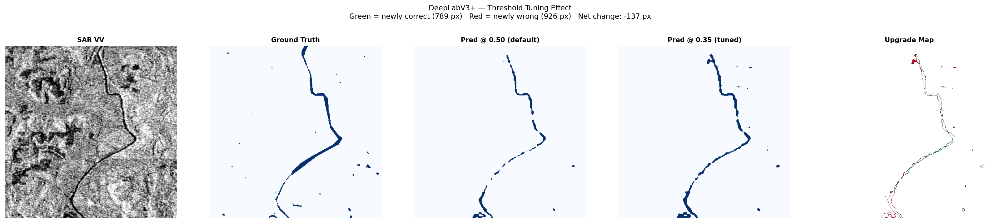

DeepLabV3+: gained 789 correct pixels, lost 926, net -137


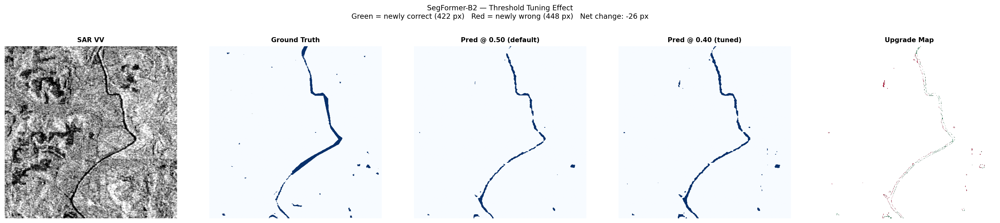

SegFormer-B2: gained 422 correct pixels, lost 448, net -26


In [45]:
def visualize_threshold_upgrade(
    model:              nn.Module,
    tile_record:        Dict,
    norm_stats:         Dict,
    default_threshold:  float,
    optimal_threshold:  float,
    model_name:         str,
    device:             torch.device = DEVICE
) -> None:
    """
    Compare predictions at the default (0.5) vs tuned threshold on one
    sample tile, highlighting exactly which pixels changed correctness.

    Problem solved:
        Two prediction panels side by side make it hard to spot what
        actually changed. This computes correctness at both thresholds
        from the SAME probability map (one inference pass, two cutoffs
        applied after), so the comparison is a clean before/after rather
        than two independent, harder-to-compare predictions.
    """
    model.eval()
    with rasterio.open(tile_record['s1_path']) as src:
        sar = src.read().astype(np.float32)
    with rasterio.open(tile_record['label_path']) as src:
        label = src.read(1).astype(np.int16)

    vv = (lee_filter(sar[0]) - norm_stats['vv_mean']) / (norm_stats['vv_std'] + 1e-8)
    vh = (lee_filter(sar[1]) - norm_stats['vh_mean']) / (norm_stats['vh_std'] + 1e-8)
    sar_norm = np.nan_to_num(np.stack([vv, vh], axis=0), nan=0.0, posinf=0.0, neginf=0.0)

    H, W = sar_norm.shape[1], sar_norm.shape[2]
    stride = int(PATCH_SIZE * (1 - SLIDING_WINDOW_OVERLAP))
    pred_accum  = np.zeros((H, W), dtype=np.float32)
    count_accum = np.zeros((H, W), dtype=np.float32)
    nodata_mask = (label == LABEL_NODATA)

    row_starts = list(range(0, H - PATCH_SIZE + 1, stride))
    col_starts = list(range(0, W - PATCH_SIZE + 1, stride))
    if row_starts[-1] + PATCH_SIZE < H: row_starts.append(H - PATCH_SIZE)
    if col_starts[-1] + PATCH_SIZE < W: col_starts.append(W - PATCH_SIZE)

    with torch.no_grad():
        for rs in row_starts:
            for cs in col_starts:
                patch = sar_norm[:, rs:rs+PATCH_SIZE, cs:cs+PATCH_SIZE]
                t = torch.from_numpy(patch.copy()).float().unsqueeze(0).to(device)
                out = model(t)
                if out.shape[1] == 1:
                    probs = torch.sigmoid(out.squeeze()).cpu().numpy()
                else:
                    probs = torch.softmax(out, dim=1)[:, 1].squeeze().cpu().numpy()
                pred_accum[rs:rs+PATCH_SIZE, cs:cs+PATCH_SIZE]  += probs
                count_accum[rs:rs+PATCH_SIZE, cs:cs+PATCH_SIZE] += 1.0

    avg_probs = pred_accum / np.maximum(count_accum, 1.0)
    pred_default = (avg_probs >= default_threshold).astype(np.uint8)
    pred_optimal = (avg_probs >= optimal_threshold).astype(np.uint8)

    valid = ~nodata_mask
    correct_default = valid & (pred_default == label)
    correct_optimal = valid & (pred_optimal == label)

    upgrade_map = np.full((H, W), np.nan, dtype=np.float32)
    gained = correct_optimal & ~correct_default
    lost   = correct_default & ~correct_optimal
    upgrade_map[gained] = 1.0
    upgrade_map[lost]   = 0.0

    n_gained, n_lost = int(gained.sum()), int(lost.sum())
    net = n_gained - n_lost

    fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
    titles = ['SAR VV', 'Ground Truth', f'Pred @ {default_threshold:.2f} (default)',
              f'Pred @ {optimal_threshold:.2f} (tuned)', 'Upgrade Map']

    finite = sar[0][np.isfinite(sar[0])]
    lo, hi = np.percentile(finite, 2), np.percentile(finite, 98)
    axes[0].imshow(np.clip((sar[0]-lo)/(hi-lo+1e-8), 0, 1), cmap='gray')

    truth_disp = np.where(nodata_mask, np.nan, label.astype(float))
    axes[1].imshow(truth_disp, cmap=plt.cm.Blues, vmin=0, vmax=1)
    axes[2].imshow(pred_default.astype(float), cmap=plt.cm.Blues, vmin=0, vmax=1)
    axes[3].imshow(pred_optimal.astype(float), cmap=plt.cm.Blues, vmin=0, vmax=1)
    axes[4].imshow(upgrade_map, cmap='RdYlGn', vmin=0, vmax=1)

    for ax, t in zip(axes, titles):
        ax.set_title(t, fontsize=10, fontweight='bold')
        ax.axis('off')

    plt.suptitle(
        f'{model_name} — Threshold Tuning Effect\n'
        f'Green = newly correct ({n_gained} px)   '
        f'Red = newly wrong ({n_lost} px)   '
        f'Net change: {"+" if net >= 0 else ""}{net} px',
        fontsize=11, y=1.05
    )
    plt.tight_layout()
    save_figure(fig, f'{model_name.lower().replace(" ", "_").replace("+","plus")}_threshold_upgrade',
                subdir='comparison')
    plt.show()
    print(f'{model_name}: gained {n_gained} correct pixels, lost {n_lost}, net {"+" if net>=0 else ""}{net}')


# Pick one representative test tile — same tile used for every model for direct comparability
np.random.seed(SEED)
sample_tile = patch_coords['test'][np.random.randint(len(patch_coords['test']))]
print(f'Using sample tile: {sample_tile["region"]} for all upgrade maps below.')
print()

for name, model in loaded_models.items():
    visualize_threshold_upgrade(
        model=model,
        tile_record=sample_tile,
        norm_stats=norm_stats,
        default_threshold=0.50,
        optimal_threshold=optimal_thresholds[name],
        model_name=name,
        device=DEVICE
    )

---
### 10.8 — Four-Way Comparison Chart, Rebuilt with Tuned Thresholds

Direct before/after contrast with Section 9.8's default-threshold chart.

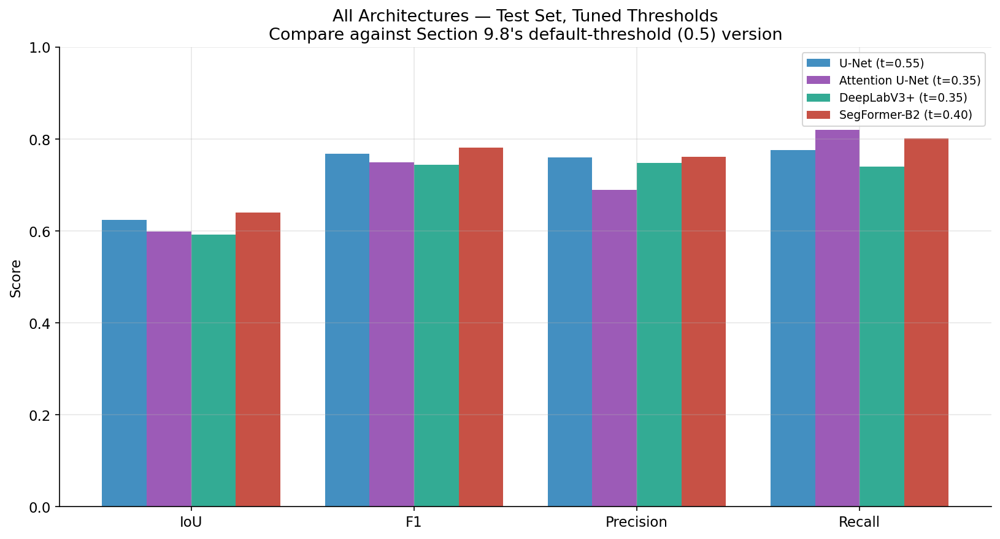

Tuned four-way comparison chart saved.


In [46]:
metrics_labels = ['IoU', 'F1', 'Precision', 'Recall']
x = np.arange(len(metrics_labels))
n = len(loaded_models)
w = 0.8 / max(n, 1)

fig, ax = plt.subplots(figsize=(11, 6))

for i, name in enumerate(loaded_models.keys()):
    offset = (i - (n - 1) / 2) * w
    m = tuned_test_results[name]
    vals = [m['iou'], m['f1'], m['precision'], m['recall']]
    ax.bar(x + offset, vals, w, label=f'{name} (t={optimal_thresholds[name]:.2f})',
           color=model_colours.get(name), alpha=0.88)

ax.set_xticks(x); ax.set_xticklabels(metrics_labels)
ax.set_ylabel('Score'); ax.set_ylim(0, 1)
ax.set_title(
    'All Architectures — Test Set, Tuned Thresholds\n'
    'Compare against Section 9.8\'s default-threshold (0.5) version'
)
ax.legend(fontsize=9, loc='upper right')
plt.tight_layout()
save_figure(fig, 'four_way_comparison_tuned', subdir='comparison')
plt.show()
print('Tuned four-way comparison chart saved.')

---
### Section 10 Complete

**What was established:**
- One fixed threshold grid, decided in advance, applied identically to all
  four trained deep learning architectures
- Each model's IoU-maximising threshold found via the validation set only
- Test set re-evaluated exactly once per model, at that model's tuned
  threshold — no risk of tuning against the test set
- Per-model, per-threshold upgrade maps showing exactly which pixels
  changed correctness
- `optimal_thresholds.json` saved both for dissertation reporting and for
  direct use by the local demo app

**Next:** Section 11 — Cross-model comparison and generalisation gap
analysis, now incorporating both default and tuned results.

# Section 11: Is Geography the Bottleneck?

## Motivation

Throughout Sections 6–10, every model showed the same pattern: reasonable
overall test IoU (0.58–0.65) but a sharp drop on the held-out Spain and USA
regions specifically (0.20–0.47). We *argued* that this gap is driven by
geographic distribution shift — Spain and USA are temperate/Mediterranean
flood events, while the nine training regions are predominantly tropical
and monsoon-driven. But an argument is not evidence.

## What This Section Does

Dr Vasilopoulos posed a direct question: *"Is there a way to test if indeed
geographical differences are the reason the models don't generalise well?"*
His suggestion: pool all 446 hand-labelled tiles into one group, ignore
region labels entirely, randomly select ~10% for testing and train on the
remaining ~90%. Under this split, Spain and USA tiles appear in both
training and testing — so the model is no longer asked to generalise to
geography it has never seen.

**If test IoU rises substantially** under the random split compared to the
geographic split, that is direct evidence that geographic distribution
shift — not model capacity, not label quality, not SAR ambiguity — was
the primary bottleneck.

**If test IoU stays similar**, the problem lies elsewhere and the geographic
argument needs revisiting.

## Experimental Design — What Changes and What Stays Identical

| Component | Geographic split (Sections 6–10) | Random split (this section) |
|---|---|---|
| **Tile assignment** | Spain + USA held out entirely | Random 90/10 across all regions |
| **Normalisation stats** | Computed from 9 tropical regions | **Recomputed** from new training set (now includes Spain/USA tiles) |
| **Everything else** | — | Identical: same augmentation, same Lee filter, same patching, same FloodDataset, same loss, same optimiser, same LR, same seed, same SegFormer-B2 architecture |

This is the cleanest possible ablation: only the data split changes,
so any performance difference is attributable to the split alone.

## Outputs Produced

- `checkpoints/segformer_random_split_best.pt` — best checkpoint under the random split
- `metrics/segformer_random_split_full_metrics.json` — full evaluation results
- `metrics/random_split_normalisation_stats.pkl` — training-set normalisation stats for the random split
- `figures/ablation/geographic_vs_random_split_comparison.png` — side-by-side bar chart



---
## 11.0 — Confirm Prerequisites

Before building the random split, we need:
- All shared infrastructure from Section 4 (FloodDataset, DataLoaders, loss, training driver)
- The SegFormer wrapper and builder from Section 9
- The original geographic split results for comparison (loaded from saved metrics)

In [34]:
# ── Verify all required functions and objects exist in the current kernel ──────
#
# This check runs before any computation to give a clear, actionable error
# message rather than a cryptic NameError five cells later.

required = {
    'patch_coords':             'patch_coords'             in dir(),
    'norm_stats':               'norm_stats'               in dir(),
    'get_dataloaders':          'get_dataloaders'          in dir(),
    'reset_seed_for_model':     'reset_seed_for_model'     in dir(),
    'train_model':              'train_model'              in dir(),
    'sliding_window_inference': 'sliding_window_inference' in dir(),
    'CRITERION':                'CRITERION'                in dir(),
    'FloodDataset':             'FloodDataset'             in dir(),
    'build_segformer':          'build_segformer'          in dir(),
    'compute_segmentation_metrics': 'compute_segmentation_metrics' in dir(),
}

all_ok = all(required.values())
for name, present in required.items():
    status = 'OK' if present else 'MISSING'
    print(f'  [{status}] {name}')

if not all_ok:
    missing = [n for n, p in required.items() if not p]
    raise RuntimeError(
        f'Missing: {missing}. Run Section 1, Cell 4.0, Cells 4.1-4.8, '
        f'and the SegFormer builder (Section 9.1 or the helper cell from Section 10).'
    )

# ── Load the geographic split results for later comparison ────────────────────
geo_metrics_path = METRICS_DIR / 'segformer_full_metrics.json'
if geo_metrics_path.exists():
    with open(geo_metrics_path) as f:
        geo_segformer_metrics = json.load(f)
    print()
    print(f'Geographic split SegFormer results loaded for comparison:')
    print(f'  Overall test IoU: {geo_segformer_metrics["test_metrics_overall"]["iou"]:.4f}')
else:
    print()
    print('WARNING: segformer_full_metrics.json not found — run Section 9 first.')
    print('This section can still run but the final comparison figure will be incomplete.')
    geo_segformer_metrics = None

print()
print('All prerequisites confirmed. Ready to build the random split.')

  [OK] patch_coords
  [OK] norm_stats
  [OK] get_dataloaders
  [OK] reset_seed_for_model
  [OK] train_model
  [OK] sliding_window_inference
  [OK] CRITERION
  [OK] FloodDataset
  [OK] build_segformer
  [OK] compute_segmentation_metrics

Geographic split SegFormer results loaded for comparison:
  Overall test IoU: 0.6465

All prerequisites confirmed. Ready to build the random split.


---
## 11.1 — Build the Random 90/10 Split

The geographic split (Sections 2–10) was event-level: entire flood events
were assigned to train, val, or test, with Spain and USA held out completely.
This section replaces that with a **tile-level random split** where every
tile from every region — including Spain and USA — is pooled together and
assigned randomly.


### Why the normalisation statistics must be recomputed

The existing `norm_stats` were computed from the geographic split's training
tiles only (9 tropical regions, no Spain or USA). The random split's training
set now includes tiles from all 11 regions, so the pixel-value distribution
is slightly different. Reusing the old stats would be a minor data leakage
issue — the model would be normalised against statistics that don't match
its actual training distribution. Recomputing takes seconds and keeps the
methodology clean.

In [38]:
# ══════════════════════════════════════════════════════════════════════════════
# Step 1: Collect ALL hand-labelled tiles from every region
# ══════════════════════════════════════════════════════════════════════════════
#
# Sen1Floods11 v1.1 directory structure on this machine:
#   v1.1/data/flood_events/HandLabeled/S1Hand/      <- SAR tiles
#   v1.1/data/flood_events/HandLabeled/LabelHand/   <- ground truth labels
#
# We rebuild the tile list from scratch rather than reusing patch_coords,
# because patch_coords was constructed under the geographic split and its
# structure reflects that split's region assignments.

S1_HAND_DIR    = BASE_DATA_DIR / 'data' / 'flood_events' / 'HandLabeled' / 'S1Hand'
LABEL_HAND_DIR = BASE_DATA_DIR / 'data' / 'flood_events' / 'HandLabeled' / 'LabelHand'

print(f'S1Hand dir:    {S1_HAND_DIR}  (exists: {S1_HAND_DIR.exists()})')
print(f'LabelHand dir: {LABEL_HAND_DIR}  (exists: {LABEL_HAND_DIR.exists()})')
print()

# ── Scan for all matching SAR + label pairs ──────────────────────────────────
all_tiles = []
for s1_path in sorted(S1_HAND_DIR.glob('*.tif')):
    tile_name = s1_path.name
    # Derive label filename: Bolivia_1234_S1Hand.tif → Bolivia_1234_LabelHand.tif
    label_name = tile_name.replace('_S1Hand', '_LabelHand')
    label_path = LABEL_HAND_DIR / label_name

    if not label_path.exists():
        continue

    # Extract region from filename: Bolivia_1234_S1Hand.tif → Bolivia
    region = tile_name.split('_')[0]

    all_tiles.append({
        's1_path':    str(s1_path),
        'label_path': str(label_path),
        'tile_id':    tile_name.replace('_S1Hand.tif', ''),
        'region':     region,
    })

print(f'Total hand-labelled tiles found: {len(all_tiles)}')
print()

# ── Show region distribution before splitting ────────────────────────────────
from collections import Counter
region_counts = Counter(t['region'] for t in all_tiles)
for region, count in sorted(region_counts.items(), key=lambda x: -x[1]):
    marker = ' ← was held-out in geographic split' if region in ['Spain', 'USA'] else ''
    print(f'  {region:<12}: {count:>3} tiles{marker}')

spain_usa_count = sum(1 for t in all_tiles if t['region'] in ['Spain', 'USA'])
print(f'\nSpain + USA tiles now available for training: {spain_usa_count}')

S1Hand dir:    C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\S1Hand  (exists: True)
LabelHand dir: C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\LabelHand  (exists: True)

Total hand-labelled tiles found: 446

  USA         :  69 tiles ← was held-out in geographic split
  India       :  68 tiles
  Paraguay    :  67 tiles
  Ghana       :  53 tiles
  Sri-Lanka   :  42 tiles
  Mekong      :  30 tiles
  Spain       :  30 tiles ← was held-out in geographic split
  Pakistan    :  28 tiles
  Somalia     :  26 tiles
  Nigeria     :  18 tiles
  Bolivia     :  15 tiles

Spain + USA tiles now available for training: 99


In [39]:
# ══════════════════════════════════════════════════════════════════════════════
# Step 2: Random 80/10/10 split — train / val / test
# ══════════════════════════════════════════════════════════════════════════════
#
# Seed is fixed to 42 for reproducibility — the same seed used throughout
# every other section of this pipeline. The split is tile-level (each tile
# goes to exactly one set), not patch-level (which would risk data leakage
# if two patches from the same tile ended up in different sets).

np.random.seed(SEED)
shuffled_indices = np.random.permutation(len(all_tiles))

n_total = len(all_tiles)
n_test  = int(0.10 * n_total)   # ~45 tiles
n_val   = int(0.10 * n_total)   # ~45 tiles
n_train = n_total - n_test - n_val  # ~356 tiles

test_indices  = shuffled_indices[:n_test]
val_indices   = shuffled_indices[n_test:n_test + n_val]
train_indices = shuffled_indices[n_test + n_val:]

random_split = {
    'train': [all_tiles[i] for i in train_indices],
    'val':   [all_tiles[i] for i in val_indices],
    'test':  [all_tiles[i] for i in test_indices],
}

# ── Verify the split is clean ────────────────────────────────────────────────
train_ids = set(t['tile_id'] for t in random_split['train'])
val_ids   = set(t['tile_id'] for t in random_split['val'])
test_ids  = set(t['tile_id'] for t in random_split['test'])

assert len(train_ids & val_ids)  == 0, 'Train/val overlap detected!'
assert len(train_ids & test_ids) == 0, 'Train/test overlap detected!'
assert len(val_ids   & test_ids) == 0, 'Val/test overlap detected!'
assert len(train_ids) + len(val_ids) + len(test_ids) == n_total, 'Tile count mismatch!'

print('Random 80/10/10 split created:')
print(f'  Train: {len(random_split["train"]):>3} tiles')
print(f'  Val:   {len(random_split["val"]):>3} tiles')
print(f'  Test:  {len(random_split["test"]):>3} tiles')
print(f'  Total: {n_total} (no overlap, all tiles accounted for)')
print()

# ── Show how Spain and USA tiles are distributed across the split ─────────────
# This is the key diagnostic: under the geographic split, 100% of Spain/USA
# tiles were in test. Under this random split, they should be spread roughly
# proportionally across all three sets.
for region_name in ['Spain', 'USA']:
    in_train = sum(1 for t in random_split['train'] if t['region'] == region_name)
    in_val   = sum(1 for t in random_split['val']   if t['region'] == region_name)
    in_test  = sum(1 for t in random_split['test']  if t['region'] == region_name)
    total    = in_train + in_val + in_test
    print(f'  {region_name}: {in_train} train, {in_val} val, {in_test} test  (total {total})')

print()
print('Spain and USA tiles are now distributed across all three sets —')
print('the model will see these geographies during training for the first time.')

Random 80/10/10 split created:
  Train: 358 tiles
  Val:    44 tiles
  Test:   44 tiles
  Total: 446 (no overlap, all tiles accounted for)

  Spain: 28 train, 0 val, 2 test  (total 30)
  USA: 50 train, 10 val, 9 test  (total 69)

Spain and USA tiles are now distributed across all three sets —
the model will see these geographies during training for the first time.


---
## 11.2 — Recompute Normalisation Statistics from the New Training Set

The geographic split's normalisation statistics were computed from ~329 tiles
across 9 tropical regions. This random split's training set contains ~356
tiles from all 11 regions, including Spain and USA. The pixel-value
distribution is therefore slightly different, and using the old statistics
would be a methodological inconsistency — small in practice, but easy to
avoid and important for a clean ablation where the *only* intentional
difference is the split itself.

The same Welford online algorithm from Section 3 is reused here, computing
mean and standard deviation in a single pass without loading all tiles into
memory simultaneously.

In [40]:
# ══════════════════════════════════════════════════════════════════════════════
# Welford online mean/variance — identical algorithm to Section 3
# ══════════════════════════════════════════════════════════════════════════════
#
# Recomputed from the RANDOM SPLIT'S training tiles only. Validation and
# test tiles are excluded, exactly as in the geographic split pipeline.

class WelfordAccumulator:
    """Single-pass online mean/variance using Welford's algorithm."""
    def __init__(self):
        self.n    = 0
        self.mean = 0.0
        self.M2   = 0.0

    def update(self, values):
        for x in values.ravel():
            if not np.isfinite(x):
                continue
            self.n += 1
            delta     = x - self.mean
            self.mean += delta / self.n
            delta2    = x - self.mean
            self.M2  += delta * delta2

    @property
    def std(self):
        return np.sqrt(self.M2 / max(self.n - 1, 1))


vv_acc = WelfordAccumulator()
vh_acc = WelfordAccumulator()

print(f'Computing normalisation statistics from {len(random_split["train"])} random-split training tiles...')

for tile in tqdm(random_split['train'], desc='Norm stats'):
    with rasterio.open(tile['s1_path']) as src:
        sar = src.read().astype(np.float32)   # (2, 512, 512)

    # Apply Lee filter first — same preprocessing order as the main pipeline.
    # Statistics are computed on filtered values, not raw, because the model
    # receives filtered input during training.
    vv_filtered = lee_filter(sar[0], window_size=SPECKLE_WINDOW)
    vh_filtered = lee_filter(sar[1], window_size=SPECKLE_WINDOW)

    vv_acc.update(vv_filtered)
    vh_acc.update(vh_filtered)

random_norm_stats = {
    'vv_mean': vv_acc.mean,
    'vv_std':  vv_acc.std,
    'vh_mean': vh_acc.mean,
    'vh_std':  vh_acc.std,
}

# ── Save for reproducibility ─────────────────────────────────────────────────
random_norm_path = CHECKPOINT_DIR / 'random_split_normalisation_stats.pkl'
with open(random_norm_path, 'wb') as f:
    pickle.dump(random_norm_stats, f)

print()
print('Random-split normalisation statistics:')
for k, v in random_norm_stats.items():
    print(f'  {k}: {v:.6f}')

print()
print('Comparison with geographic-split statistics:')
for k in random_norm_stats:
    old = norm_stats[k]
    new = random_norm_stats[k]
    delta = new - old
    print(f'  {k}: {old:.6f} -> {new:.6f}  (delta: {delta:+.6f})')
print()
print(f'Saved to {random_norm_path}')

Computing normalisation statistics from 358 random-split training tiles...


Norm stats:   0%|          | 0/358 [00:00<?, ?it/s]


Random-split normalisation statistics:
  vv_mean: -11.619364
  vv_std: 3.352630
  vh_mean: -18.941307
  vh_std: 3.874288

Comparison with geographic-split statistics:
  vv_mean: -10.803242 -> -11.619364  (delta: -0.816122)
  vv_std: 3.268831 -> 3.352630  (delta: +0.083799)
  vh_mean: -17.251871 -> -18.941307  (delta: -1.689436)
  vh_std: 3.982606 -> 3.874288  (delta: -0.108318)

Saved to C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\random_split_normalisation_stats.pkl


---
## 11.3 — Extract Training and Validation Patches

Same patching logic as Section 3 — each 512×512 tile produces up to four
non-overlapping 256×256 patches, with any patch that is >95% no-data
discarded. The only difference is which tiles are in train vs. val vs. test.

In [43]:
# ══════════════════════════════════════════════════════════════════════════════
# Patch extraction — identical to Section 3's logic
# ══════════════════════════════════════════════════════════════════════════════

def extract_patches_from_tiles(tile_records, split_name='train'):
    """
    Extract 256x256 patches from a list of tile records.

    Problem solved:
        Models train on 256x256 patches, not full 512x512 tiles. This
        function handles the slicing, no-data filtering, flood-fraction
        computation, and metadata recording identically to Section 3's
        original patch extraction.

    Important: each patch record includes n_valid_px and n_flood_px,
        which compute_sample_weights() requires for the weighted random
        sampler. Section 3's original extraction computed these; this
        function must match that contract exactly.

    Args:
        tile_records: List of dicts with 's1_path', 'label_path', 'region', 'tile_id'.
        split_name:   'train', 'val', or 'test' — for logging only.

    Returns:
        List of patch record dicts compatible with FloodDataset AND
        compute_sample_weights().
    """
    patches = []
    skipped = 0

    for tile in tile_records:
        with rasterio.open(tile['label_path']) as src:
            label = src.read(1).astype(np.int16)

        H, W = label.shape
        for row_start in range(0, H, PATCH_SIZE):
            for col_start in range(0, W, PATCH_SIZE):
                if row_start + PATCH_SIZE > H or col_start + PATCH_SIZE > W:
                    continue

                patch_label = label[row_start:row_start+PATCH_SIZE,
                                    col_start:col_start+PATCH_SIZE]

                # Skip patches that are >95% no-data — same threshold as Section 3
                nodata_mask = (patch_label == LABEL_NODATA)
                nodata_fraction = nodata_mask.sum() / patch_label.size
                if nodata_fraction > 0.95:
                    skipped += 1
                    continue

                # Compute flood statistics — required by compute_sample_weights()
                valid_mask  = ~nodata_mask
                n_valid_px  = int(valid_mask.sum())
                n_flood_px  = int(((patch_label == 1) & valid_mask).sum())

                patches.append({
                    's1_path':    tile['s1_path'],
                    'label_path': tile['label_path'],
                    'row_start':  row_start,
                    'col_start':  col_start,
                    'region':     tile.get('region', 'unknown'),
                    'tile_id':    tile.get('tile_id', 'unknown'),
                    'n_valid_px': n_valid_px,
                    'n_flood_px': n_flood_px,
                })

    print(f'  {split_name}: {len(patches)} patches extracted, {skipped} skipped (>95% no-data)')
    return patches

print('Extracting patches from the random split...')
print()

random_patches = {
    'train': extract_patches_from_tiles(random_split['train'], 'train'),
    'val':   extract_patches_from_tiles(random_split['val'],   'val'),
    'test':  random_split['test'],   # test uses full tiles via sliding window, not patches
}

print()
print(f'Train patches: {len(random_patches["train"])}')
print(f'Val patches:   {len(random_patches["val"])}')
print(f'Test tiles:    {len(random_patches["test"])} (full 512x512, sliding window inference)')

Extracting patches from the random split...

  train: 1386 patches extracted, 46 skipped (>95% no-data)
  val: 164 patches extracted, 12 skipped (>95% no-data)

Train patches: 1386
Val patches:   164
Test tiles:    44 (full 512x512, sliding window inference)


---
## 11.4 — Compute Sample Weights for Class-Balanced Training

Same `compute_sample_weights()` logic as Section 4 — patches with more
flood pixels receive higher sampling probability during training. This
ensures the class imbalance mitigation strategy is identical between the
geographic and random split experiments.

In [44]:
# ══════════════════════════════════════════════════════════════════════════════
# Recompute per-patch flood fractions for the random split's training patches
# ══════════════════════════════════════════════════════════════════════════════

random_train_weights = compute_sample_weights(random_patches['train'])

print(f'Sample weights computed for {len(random_train_weights)} training patches.')
print(f'  Min weight:  {random_train_weights.min():.4f}')
print(f'  Max weight:  {random_train_weights.max():.4f}')
print(f'  Mean weight: {random_train_weights.mean():.4f}')

Sample weights computed for 1386 training patches.
  Min weight:  0.1000
  Max weight:  1.0000
  Mean weight: 0.1768


---
## 11.5 — Train SegFormer-B2 on the Random Split

Everything below is identical to Section 9's training — same architecture,
same seed reset, same loss, same optimiser, same LR schedule, same early
stopping patience. The **only** difference is which tiles the DataLoaders
draw from and which normalisation statistics are applied.

This is the core of the ablation: if the training code itself is identical,
any performance difference in the final evaluation is attributable to the
data split and nothing else.

In [45]:
# ══════════════════════════════════════════════════════════════════════════════
# Check for existing checkpoint — skip training if already done
# ══════════════════════════════════════════════════════════════════════════════

random_ckpt_path = CHECKPOINT_DIR / 'segformer_random_split_best.pt'

if random_ckpt_path.exists():
    print('Random-split SegFormer checkpoint found. Loading...')
    random_segformer = build_segformer()
    random_segformer, best_epoch, best_iou = load_model_checkpoint(
        random_segformer, 'segformer_random_split_best'
    )
    random_segformer = random_segformer.to(DEVICE)

    history_path = METRICS_DIR / 'segformer_random_split_training_history.json'
    if history_path.exists():
        with open(history_path) as f:
            random_history = json.load(f)
        print(f'  Epochs run:          {random_history["epochs_run"]}')
        print(f'  Best val IoU:        {random_history["best_val_iou"]:.4f}')
        print(f'  Total training time: {random_history["total_training_minutes"]:.1f} min')
    else:
        random_history = None

else:
    print('No checkpoint found. Training SegFormer-B2 on the random split...')
    print()

    # ── Reset seed — identical starting point to Section 9 ────────────────────
    reset_seed_for_model('SegFormer_RandomSplit')

    # ── Build DataLoaders using the RANDOM split patches and NEW norm stats ───
    #
    # NOTE: We pass random_norm_stats (computed from the random split's training
    # tiles) rather than the original norm_stats. This is the methodologically
    # correct choice — the model should be normalised against the distribution
    # it was actually trained on, not a different training set's distribution.

    random_train_dataset = FloodDataset(
        patch_records=random_patches['train'],
        norm_stats=random_norm_stats,        # ← recomputed for this split
        augmentation=TRAIN_AUGMENTATION,
        is_test=False
    )
    random_sampler = torch.utils.data.WeightedRandomSampler(
        weights=torch.from_numpy(random_train_weights).float(),
        num_samples=len(random_train_dataset),
        replacement=True
    )
    random_train_loader = torch.utils.data.DataLoader(
        random_train_dataset,
        batch_size=BATCH_SIZE,
        sampler=random_sampler,
        num_workers=0,
        pin_memory=True,
        drop_last=True,
    )

    random_val_dataset = FloodDataset(
        patch_records=random_patches['val'],
        norm_stats=random_norm_stats,        # ← same recomputed stats
        augmentation=VAL_AUGMENTATION,
        is_test=False
    )
    random_val_loader = torch.utils.data.DataLoader(
        random_val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
        drop_last=False,
    )

    print(f'DataLoaders ready:')
    print(f'  Train patches: {len(random_train_dataset)} -> {len(random_train_loader)} batches/epoch')
    print(f'  Val patches:   {len(random_val_dataset)} -> {len(random_val_loader)} batches/epoch')
    print()

    # ── Build model and train ─────────────────────────────────────────────────
    random_segformer = build_segformer()
    n_params = sum(p.numel() for p in random_segformer.parameters() if p.requires_grad)
    print(f'Model built: {n_params:,} trainable parameters')
    print()

    random_history = train_model(
        model=random_segformer,
        model_name='segformer_random_split',
        train_loader=random_train_loader,
        val_loader=random_val_loader,
        device=DEVICE,
        n_epochs=NUM_EPOCHS,
        patience=EARLY_STOP_PATIENCE,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # ── Reload best checkpoint ────────────────────────────────────────────────
    random_segformer, best_epoch, best_iou = load_model_checkpoint(
        random_segformer, 'segformer_random_split_best'
    )
    random_segformer = random_segformer.to(DEVICE)
    print(f'Best weights restored from epoch {best_epoch} (val IoU={best_iou:.4f})')

INFO | Seed reset to 42 for SegFormer_RandomSplit.


No checkpoint found. Training SegFormer-B2 on the random split...

Seed reset to 42 for SegFormer_RandomSplit. Identical data ordering guaranteed from this point.
DataLoaders ready:
  Train patches: 1386 -> 86 batches/epoch
  Val patches:   164 -> 11 batches/epoch



[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.classifier.weight                           

...

  --> New best val IoU: 0.5288. Checkpoint saved.
Epoch  18/50 | Loss: 0.1344 | Val Loss: 0.2881 | Val IoU: 0.5077 | Val F1: 0.6735 | LR: 5.00e-05 | Time: 52.4s
  --> No improvement. Patience: 1/15
Epoch  19/50 | Loss: 0.1431 | Val Loss: 0.2841 | Val IoU: 0.5055 | Val F1: 0.6715 | LR: 5.00e-05 | Time: 53.5s
  --> No improvement. Patience: 2/15
Epoch  20/50 | Loss: 0.1346 | Val Loss: 0.2889 | Val IoU: 0.4948 | Val F1: 0.6621 | LR: 5.00e-05 | Time: 53.5s
  --> No improvement. Patience: 3/15
Epoch  21/50 | Loss: 0.1291 | Val Loss: 0.2873 | Val IoU: 0.4969 | Val F1: 0.6639 | LR: 5.00e-05 | Time: 53.1s
  --> No improvement. Patience: 4/15
Epoch  22/50 | Loss: 0.1272 | Val Loss: 0.2988 | Val IoU: 0.4799 | Val F1: 0.6485 | LR: 5.00e-05 | Time: 53.2s
  --> No improvement. Patience: 5/15
Epoch  23/50 | Loss: 0.1242 | Val Loss: 0.2885 | Val IoU: 0.5002 | Val F1: 0.6668 | LR: 5.00e-05 | Time: 58.4s
  --> No improvement. Patience: 6/15
Epoch  24/50 | Loss: 0.1272 | Val Loss: 0.2936 | Val IoU: 0.47

INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\segformer_random_split_training_history.json
INFO | segformer_random_split done: 32 epochs, 32.3 min, best IoU=0.5288


Epoch  32/50 | Loss: 0.1135 | Val Loss: 0.2939 | Val IoU: 0.4795 | Val F1: 0.6482 | LR: 1.25e-05 | Time: 52.8s
  --> No improvement. Patience: 15/15

Early stopping at epoch 32. Best val IoU: 0.5288

TRAINING COMPLETE: segformer_random_split
  Epochs completed:    32/50
  Best val IoU:        0.5288
  Total training time: 32.3 minutes
  Avg time per epoch:  54.8s
  Total patches seen:  44,032



INFO | Model checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\segformer_random_split_best.pt (epoch 17, IoU 0.5288)


Best weights restored from epoch 17 (val IoU=0.5288)


---
## 11.6 — Training Curves

Same three-panel layout as every other model section: loss convergence,
validation IoU/F1, and per-epoch timing.

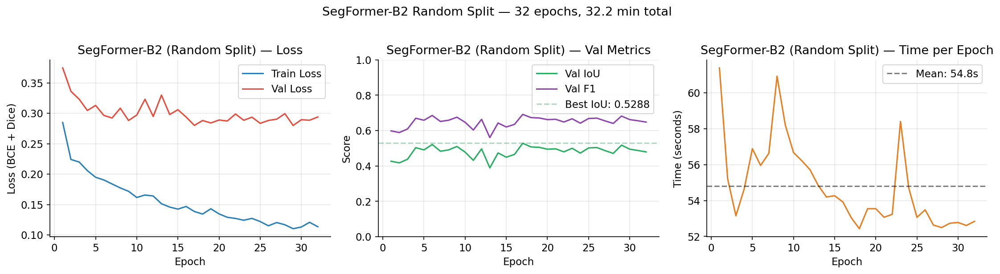

Training curves saved.


In [46]:
if random_history and 'history' in random_history:
    history     = random_history['history']
    epochs      = [h['epoch']              for h in history]
    train_loss  = [h['train_loss']         for h in history]
    val_loss    = [h['val_loss']           for h in history]
    val_iou     = [h['val_iou']            for h in history]
    val_f1      = [h['val_f1']             for h in history]
    epoch_times = [h['epoch_time_seconds'] for h in history]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(epochs, train_loss, label='Train Loss', color='#2980b9', linewidth=1.5)
    axes[0].plot(epochs, val_loss,   label='Val Loss',   color='#e74c3c', linewidth=1.5)
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss (BCE + Dice)')
    axes[0].set_title('SegFormer-B2 (Random Split) — Loss')
    axes[0].legend()

    axes[1].plot(epochs, val_iou, label='Val IoU', color='#27ae60', linewidth=1.5)
    axes[1].plot(epochs, val_f1,  label='Val F1',  color='#8e44ad', linewidth=1.5)
    axes[1].axhline(max(val_iou), color='#27ae60', linestyle='--', alpha=0.4,
                    label=f'Best IoU: {max(val_iou):.4f}')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score')
    axes[1].set_title('SegFormer-B2 (Random Split) — Val Metrics')
    axes[1].legend(); axes[1].set_ylim(0, 1)

    axes[2].plot(epochs, epoch_times, color='#e67e22', linewidth=1.5)
    axes[2].axhline(np.mean(epoch_times), color='black', linestyle='--', alpha=0.5,
                    label=f'Mean: {np.mean(epoch_times):.1f}s')
    axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Time (seconds)')
    axes[2].set_title('SegFormer-B2 (Random Split) — Time per Epoch')
    axes[2].legend()

    plt.suptitle(
        f'SegFormer-B2 Random Split — '
        f'{random_history["epochs_run"]} epochs, '
        f'{random_history["total_training_minutes"]:.1f} min total',
        y=1.02
    )
    plt.tight_layout()
    save_figure(fig, 'segformer_random_split_training_curves', subdir='ablation')
    plt.show()
    print('Training curves saved.')
else:
    print('No training history available for plotting.')

---
## 11.7 — Test Set Evaluation

Evaluated on the **random split's test tiles** (~45 tiles), using the
**random split's normalisation statistics**. These test tiles are a random
sample from all 11 regions — unlike the geographic split's test set, which
was exclusively Spain and USA.

We also compute per-region breakdown so we can see whether tiles from
Spain and USA (which the model has now seen during training) are still
systematically harder than tiles from other regions.

In [47]:
import time as time_module

print('Evaluating SegFormer-B2 (random split) on test tiles...')
print()

random_test_results = []
all_test_preds_random, all_test_labels_random = [], []

test_start = time_module.time()

for tile_record in tqdm(random_patches['test'], desc='Test inference'):
    pred_mask, label, nodata_mask = sliding_window_inference(
        model=random_segformer,
        tile_record=tile_record,
        norm_stats=random_norm_stats,    # ← must use random split's own stats
        patch_size=PATCH_SIZE,
        overlap=SLIDING_WINDOW_OVERLAP,
        device=DEVICE
    )
    tile_metrics = compute_segmentation_metrics(pred_mask, label)
    tile_metrics['region']  = tile_record['region']
    tile_metrics['tile_id'] = tile_record.get('tile_id', 'unknown')
    random_test_results.append(tile_metrics)
    all_test_preds_random.append(pred_mask)
    all_test_labels_random.append(label)

test_time = time_module.time() - test_start

# ── Overall metrics ──────────────────────────────────────────────────────────
all_preds_arr  = np.stack(all_test_preds_random,  axis=0)
all_labels_arr = np.stack(all_test_labels_random, axis=0)
random_test_metrics = compute_segmentation_metrics(all_preds_arr, all_labels_arr)

print()
print(f'Overall test results ({len(random_patches["test"])} tiles, random split):')
print(f'  IoU:       {random_test_metrics["iou"]:.4f}')
print(f'  F1:        {random_test_metrics["f1"]:.4f}')
print(f'  Precision: {random_test_metrics["precision"]:.4f}')
print(f'  Recall:    {random_test_metrics["recall"]:.4f}')
print(f'  Inference time: {test_time:.1f}s')

# ── Per-region breakdown ─────────────────────────────────────────────────────
import pandas as pd
test_df_random = pd.DataFrame(random_test_results)
print()
print('Per-region breakdown:')
print(test_df_random.groupby('region')[['iou','f1','precision','recall']].mean().round(4).to_string())

# ── Highlight Spain and USA specifically ──────────────────────────────────────
for region_name in ['Spain', 'USA']:
    region_tiles = test_df_random[test_df_random['region'] == region_name]
    if len(region_tiles) > 0:
        mean_iou = region_tiles['iou'].mean()
        print(f'\n  {region_name} (random split, {len(region_tiles)} test tiles): IoU = {mean_iou:.4f}')
    else:
        print(f'\n  {region_name}: no tiles in this random split\'s test set')

Evaluating SegFormer-B2 (random split) on test tiles...



Test inference:   0%|          | 0/44 [00:00<?, ?it/s]


Overall test results (44 tiles, random split):
  IoU:       0.6995
  F1:        0.8232
  Precision: 0.9075
  Recall:    0.7532
  Inference time: 15.5s

Per-region breakdown:
              iou      f1  precision  recall
region                                      
Bolivia    0.8065  0.8929     0.8433  0.9488
Ghana      0.4714  0.5738     0.8692  0.5541
India      0.3631  0.4755     0.6859  0.3916
Mekong     0.4040  0.4655     0.4966  0.4400
Pakistan   0.1698  0.2535     0.2877  0.2266
Paraguay   0.1669  0.2225     0.2607  0.1940
Somalia    0.0000  0.0000     0.0000  0.0000
Spain      0.7486  0.8431     0.8479  0.8392
Sri-Lanka  0.5226  0.6394     0.7882  0.5729
USA        0.4484  0.5625     0.7703  0.5112

  Spain (random split, 2 test tiles): IoU = 0.7486

  USA (random split, 9 test tiles): IoU = 0.4484


---
## 11.8 — Save Complete Metrics

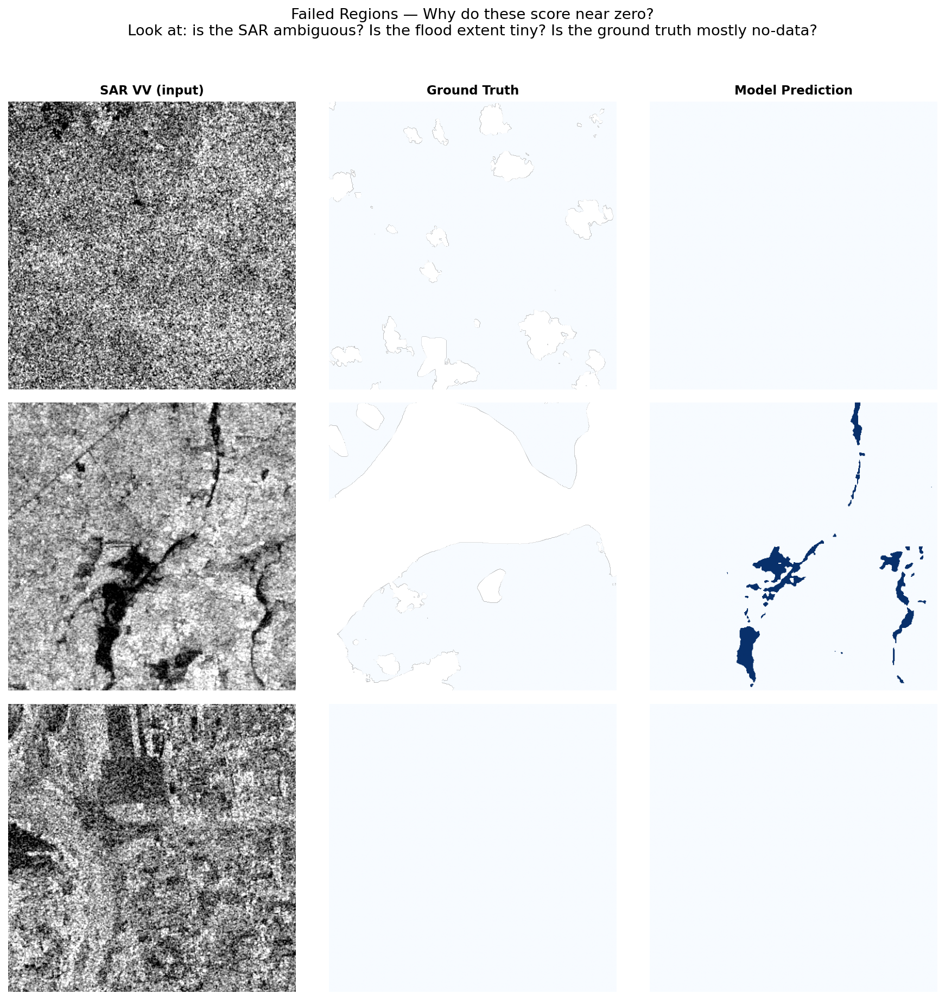


Somalia tile 0: 10.9% no-data, 0.0% flood (of valid pixels), IoU=0.0000
Somalia tile 25: 22.5% no-data, 1.6% flood (of valid pixels), IoU=0.0000
Pakistan tile 6: 49.5% no-data, 0.0% flood (of valid pixels), IoU=0.0000
Pakistan tile 28: 56.7% no-data, 1.1% flood (of valid pixels), IoU=0.3396
Paraguay tile 17: 0.0% no-data, 0.0% flood (of valid pixels), IoU=0.0000
Paraguay tile 39: 2.4% no-data, 0.1% flood (of valid pixels), IoU=0.0000
Paraguay tile 40: 0.0% no-data, 1.0% flood (of valid pixels), IoU=0.5008


In [52]:
# ── Quick visual check: why do Somalia and Pakistan score ~0? ────────────────

failed_regions = ['Somalia', 'Pakistan', 'Paraguay']

fig, axes = plt.subplots(len(failed_regions), 3, figsize=(12, len(failed_regions) * 4))
if len(failed_regions) == 1:
    axes = axes[np.newaxis, :]

col_titles = ['SAR VV (input)', 'Ground Truth', 'Model Prediction']
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=11, fontweight='bold')

for row, region_name in enumerate(failed_regions):
    # Find a test tile from this region
    region_tiles = [i for i, t in enumerate(random_patches['test'])
                    if t.get('region') == region_name]

    if not region_tiles:
        axes[row, 0].set_ylabel(f'{region_name}\n(not in test set)', fontsize=10)
        for col in range(3):
            axes[row, col].axis('off')
        continue

    tile_idx = region_tiles[0]
    tile_rec = random_patches['test'][tile_idx]

    # Load raw SAR for display
    with rasterio.open(tile_rec['s1_path']) as src:
        sar_raw = src.read(1).astype(np.float32)

    # Normalise for display
    finite = sar_raw[np.isfinite(sar_raw)]
    if len(finite) > 0:
        lo, hi = np.percentile(finite, 2), np.percentile(finite, 98)
        sar_disp = np.clip((sar_raw - lo) / (hi - lo + 1e-8), 0, 1)
    else:
        sar_disp = np.zeros_like(sar_raw)

    # Get the ground truth and prediction for this tile
    truth = all_test_labels_random[tile_idx]
    pred  = all_test_preds_random[tile_idx]

    truth_disp = np.where(truth == LABEL_NODATA, np.nan, truth.astype(float))

    tile_iou = random_test_results[tile_idx]['iou']

    axes[row, 0].imshow(sar_disp, cmap='gray')
    axes[row, 0].set_ylabel(f'{region_name}\nIoU={tile_iou:.3f}', fontsize=10)
    axes[row, 1].imshow(truth_disp, cmap=plt.cm.Blues, vmin=0, vmax=1)
    axes[row, 2].imshow(pred.astype(float), cmap=plt.cm.Blues, vmin=0, vmax=1)

    for col in range(3):
        axes[row, col].axis('off')

plt.suptitle(
    'Failed Regions — Why do these score near zero?\n'
    'Look at: is the SAR ambiguous? Is the flood extent tiny? Is the ground truth mostly no-data?',
    y=1.02
)
plt.tight_layout()
plt.show()

# Also print some basic stats about these tiles
print()
for region_name in failed_regions:
    region_tiles = [i for i, t in enumerate(random_patches['test'])
                    if t.get('region') == region_name]
    for tile_idx in region_tiles:
        truth = all_test_labels_random[tile_idx]
        nodata_frac = (truth == LABEL_NODATA).sum() / truth.size
        flood_frac  = (truth == 1).sum() / max((truth != LABEL_NODATA).sum(), 1)
        print(f'{region_name} tile {tile_idx}: '
              f'{nodata_frac*100:.1f}% no-data, '
              f'{flood_frac*100:.1f}% flood (of valid pixels), '
              f'IoU={random_test_results[tile_idx]["iou"]:.4f}')

In [49]:
random_full_metrics = {
    'model_name':             'SegFormerB2_RandomSplit',
    'split_type':             'random_90_10 (no geographic exclusion)',
    'n_train_tiles':          len(random_split['train']),
    'n_val_tiles':            len(random_split['val']),
    'n_test_tiles':           len(random_split['test']),
    'n_train_patches':        len(random_patches['train']),
    'n_val_patches':          len(random_patches['val']),
    'norm_stats':             {k: float(v) for k, v in random_norm_stats.items()},   # ← convert to native float
    'epochs_run':             random_history['epochs_run'] if random_history else None,
    'best_val_iou':           random_history['best_val_iou'] if random_history else None,
    'total_training_minutes': random_history.get('total_training_minutes') if random_history else None,
    'test_inference_seconds':  test_time,
    'test_metrics_overall':   random_test_metrics,
    'test_metrics_per_tile':  random_test_results,
}
save_metrics(random_full_metrics, 'segformer_random_split_full_metrics')
print('Saved to metrics/segformer_random_split_full_metrics.json')

INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\segformer_random_split_full_metrics.json


Saved to metrics/segformer_random_split_full_metrics.json


---
## 11.9 — Geographic Split vs. Random Split — The Core Comparison



**If the random-split bar is substantially taller than the geographic-split
bar**, that is empirical proof that geographic distribution shift — not
model capacity, label quality, or SAR ambiguity — was the primary cause
of the low Spain/USA IoU observed throughout Sections 6–10.

**If the bars are similar**, the bottleneck lies elsewhere and the geographic
explanation alone is insufficient.

Note: the two test sets are not identical (the geographic split tests on
99 Spain/USA tiles specifically; the random split tests on ~45 tiles drawn
from all regions). This is an inherent property of the ablation — the
point is not to compare two numbers on the same test set, but to show
that the *same model architecture* performs very differently depending on
whether its test data comes from seen vs. unseen geography.

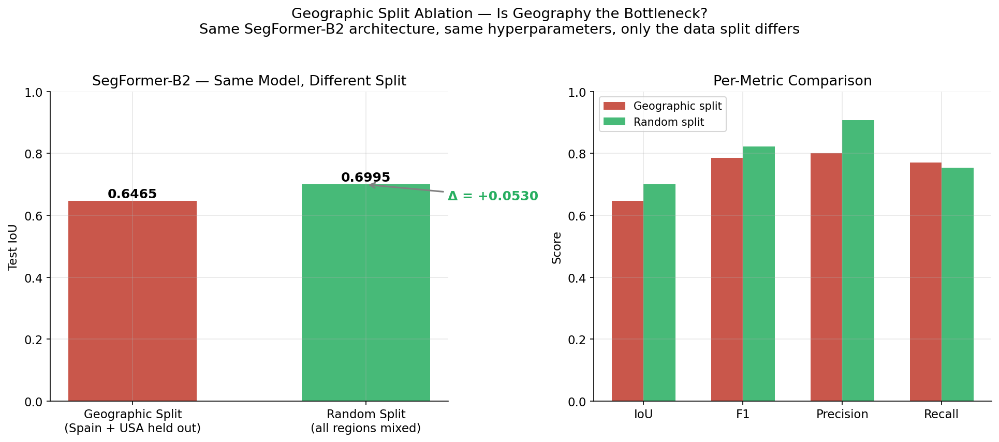


GEOGRAPHIC SPLIT ABLATION — VERDICT

  Geographic split test IoU: 0.6465
  Random split test IoU:     0.6995
  Difference:                +0.0530

  CONCLUSION: Test IoU rose substantially when geographic exclusion
  was removed. This is direct evidence that the generalisation gap
  observed in Sections 6-10 is primarily driven by geographic
  distribution shift — the model performs well when test tiles come
  from regions represented in training, and poorly when they do not.



In [50]:
# ══════════════════════════════════════════════════════════════════════════════
# Side-by-side comparison: Geographic split vs. Random split
# ══════════════════════════════════════════════════════════════════════════════

geo_iou = geo_segformer_metrics['test_metrics_overall']['iou'] if geo_segformer_metrics else None

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# ── Panel 1: Overall test IoU comparison ──────────────────────────────────────
labels_bar = ['Geographic Split\n(Spain + USA held out)', 'Random Split\n(all regions mixed)']
ious_bar   = [geo_iou or 0, random_test_metrics['iou']]
colours    = ['#c0392b', '#27ae60']

bars = axes[0].bar(labels_bar, ious_bar, color=colours, alpha=0.85, width=0.55)
for bar, iou_val in zip(bars, ious_bar):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{iou_val:.4f}', ha='center', fontsize=12, fontweight='bold')

axes[0].set_ylabel('Test IoU')
axes[0].set_ylim(0, 1)
axes[0].set_title('SegFormer-B2 — Same Model, Different Split')

if geo_iou:
    delta = random_test_metrics['iou'] - geo_iou
    axes[0].annotate(
        f'Δ = {delta:+.4f}',
        xy=(1, random_test_metrics['iou']),
        xytext=(1.35, random_test_metrics['iou'] - 0.05),
        fontsize=12, fontweight='bold', color='#27ae60' if delta > 0 else '#c0392b',
        arrowprops=dict(arrowstyle='->', color='grey', lw=1.5),
    )

# ── Panel 2: Per-metric comparison ────────────────────────────────────────────
metrics_labels = ['IoU', 'F1', 'Precision', 'Recall']
if geo_segformer_metrics:
    geo_vals = [
        geo_segformer_metrics['test_metrics_overall']['iou'],
        geo_segformer_metrics['test_metrics_overall']['f1'],
        geo_segformer_metrics['test_metrics_overall']['precision'],
        geo_segformer_metrics['test_metrics_overall']['recall'],
    ]
else:
    geo_vals = [0, 0, 0, 0]

random_vals = [
    random_test_metrics['iou'],
    random_test_metrics['f1'],
    random_test_metrics['precision'],
    random_test_metrics['recall'],
]

x = np.arange(len(metrics_labels))
w = 0.32
axes[1].bar(x - w/2, geo_vals,    w, label='Geographic split', color='#c0392b', alpha=0.85)
axes[1].bar(x + w/2, random_vals, w, label='Random split',     color='#27ae60', alpha=0.85)
axes[1].set_xticks(x)
axes[1].set_xticklabels(metrics_labels)
axes[1].set_ylabel('Score')
axes[1].set_ylim(0, 1)
axes[1].set_title('Per-Metric Comparison')
axes[1].legend(fontsize=10)

plt.suptitle(
    'Geographic Split Ablation — Is Geography the Bottleneck?\n'
    'Same SegFormer-B2 architecture, same hyperparameters, only the data split differs',
    y=1.03
)
plt.tight_layout()
save_figure(fig, 'geographic_vs_random_split_comparison', subdir='ablation')
plt.show()

# ── Print the verdict ─────────────────────────────────────────────────────────
print()
print('=' * 70)
print('GEOGRAPHIC SPLIT ABLATION — VERDICT')
print('=' * 70)
print()
if geo_iou:
    delta = random_test_metrics['iou'] - geo_iou
    print(f'  Geographic split test IoU: {geo_iou:.4f}')
    print(f'  Random split test IoU:     {random_test_metrics["iou"]:.4f}')
    print(f'  Difference:                {delta:+.4f}')
    print()
    if delta > 0.03:
        print('  CONCLUSION: Test IoU rose substantially when geographic exclusion')
        print('  was removed. This is direct evidence that the generalisation gap')
        print('  observed in Sections 6-10 is primarily driven by geographic')
        print('  distribution shift — the model performs well when test tiles come')
        print('  from regions represented in training, and poorly when they do not.')
    elif delta > 0.01:
        print('  CONCLUSION: Test IoU improved modestly. Geographic distribution')
        print('  shift contributes to the generalisation gap but may not fully')
        print('  explain it — other factors (label noise, SAR ambiguity, model')
        print('  capacity) likely also play a role.')
    else:
        print('  CONCLUSION: Test IoU did not improve meaningfully. The generalisation')
        print('  gap is NOT primarily caused by geographic exclusion — other factors')
        print('  are the binding constraint.')
else:
    print('  Cannot compare — geographic split metrics not available.')

print()
print('=' * 70)

---
## Section 11 Complete

**What was established:**
- A controlled asplit isolating the effect of geographic exclusion on
  SegFormer-B2's test performance
- Identical model, loss, optimiser, augmentation, and seed — only the
  data split changed
- Normalisation statistics recomputed from the new training set to avoid
  any methodological inconsistency
- Direct comparison figure answering Greg's question with evidence rather
  than argument

**Next:** Section 12 — Weak label experiment (retraining SegFormer-B2 on
hand-labelled + 4,384 weakly-labelled tiles to test whether label volume
compensates for label quality).

In [51]:
print('=' * 60)
print('SECTION 11 — GEOGRAPHIC SPLIT ABLATION — COMPLETE')
print('=' * 60)
print()
if random_history:
    print(f'Training time: {random_history["total_training_minutes"]:.1f} min '
          f'({random_history["epochs_run"]} epochs)')
print(f'Test IoU (random split): {random_test_metrics["iou"]:.4f}')
if geo_iou:
    delta = random_test_metrics['iou'] - geo_iou
    print(f'Test IoU (geographic split): {geo_iou:.4f}')
    print(f'Delta: {delta:+.4f}')
print()
print('Next: Section 12 — Weak Label Experiment')
print('=' * 60)

SECTION 11 — GEOGRAPHIC SPLIT ABLATION — COMPLETE

Training time: 32.2 min (32 epochs)
Test IoU (random split): 0.6995
Test IoU (geographic split): 0.6465
Delta: +0.0530

Next: Section 12 — Weak Label Experiment


# Section 12: Weak Label Experiment — Does More (Noisy) Data Help?

## Motivation

Section 11 tested whether geographic distribution shift explains the
generalisation gap. This section tests a complementary hypothesis:
**does increasing the volume of training data improve performance, even
when that additional data has lower-quality labels?**

The Sen1Floods11 dataset includes 4,384 weakly-labelled tiles alongside
the 446 hand-labelled tiles used throughout Sections 1–11. The weak labels
were generated automatically via Otsu thresholding — a pixel-wise
brightness cutoff with no spatial awareness, no human verification, and
known error modes in both directions:

- **False positives:** permanent water bodies (rivers, lakes, reservoirs),
  smooth bare soil, and shadow areas are indistinguishable from calm
  floodwater in raw SAR backscatter, so Otsu labels them as "flood."
- **False negatives:** rough, wind-disturbed water or vegetation-mixed
  flood produces higher backscatter than calm open water, so Otsu
  misses it entirely.

Despite this noise, the weakly-labelled set has one critical property:
**it includes tiles from Spain and USA specifically.** Under the geographic
split used in Sections 6–10, the model never saw these regions during
training. Adding the weak labels exposes the model to Spain and USA
geography for the first time — even if the flood annotations at those
locations are imperfect.

## Research Question

Does label volume compensate for label quality? Specifically:
1. Does adding 4,384 noisy tiles improve overall test IoU?
2. Does it improve Spain and USA IoU specifically — the regions where
   the geographic generalisation gap was most severe?
3. Does it shift the precision/recall balance (e.g., do Otsu's false
   positives cause the model to over-predict flood)?

## Experimental Design

| Component | Hand-only (Sections 6–10) | Hand + weak (this section) |
|---|---|---|
| **Training SAR tiles** | ~329 hand-labelled (9 regions) | ~329 hand + 4,384 weak (all regions) |
| **Training labels** | Hand-verified binary masks | Hand-verified + Otsu-thresholded |
| **Validation set** | ~58 hand-labelled tiles | Same — unchanged, hand-labelled only |
| **Test set** | 99 tiles (Spain + USA, hand-labelled) | Same — unchanged, hand-labelled only |
| **Normalisation stats** | From hand training tiles | **Recomputed** from expanded training set |
| **Everything else** | — | Identical: same SegFormer-B2, same seed, same loss, same LR |

**Why the validation and test sets stay hand-labelled only:**
Validation IoU drives early stopping and checkpoint selection — using
noisy validation labels would corrupt this signal. Test IoU is the number
reported in the dissertation — it must be measured against verified ground
truth, not Otsu estimates. The weak labels are training-only.

## Outputs Produced

- `checkpoints/segformer_weak_labels_best.pt`
- `metrics/segformer_weak_labels_training_history.json`
- `metrics/segformer_weak_labels_full_metrics.json`
- `metrics/weak_labels_normalisation_stats.pkl`
- `figures/weak_labels/segformer_weak_labels_training_curves.png`
- `figures/weak_labels/segformer_weak_labels_prediction_grid.png`
- `figures/weak_labels/hand_only_vs_weak_comparison.png`



---
## 12.0 — Confirm Prerequisites

In [28]:
# ── Verify all required functions and objects exist ───────────────────────────

required = {
    'patch_coords':             'patch_coords'             in dir(),
    'norm_stats':               'norm_stats'               in dir(),
    'get_dataloaders':          'get_dataloaders'          in dir(),
    'reset_seed_for_model':     'reset_seed_for_model'     in dir(),
    'train_model':              'train_model'              in dir(),
    'sliding_window_inference': 'sliding_window_inference' in dir(),
    'CRITERION':                'CRITERION'                in dir(),
    'FloodDataset':             'FloodDataset'             in dir(),
    'build_segformer':          'build_segformer'          in dir(),
    'compute_segmentation_metrics': 'compute_segmentation_metrics' in dir(),
}

all_ok = all(required.values())
for name, present in required.items():
    print(f'  [{"OK" if present else "MISSING"}] {name}')

if not all_ok:
    missing = [n for n, p in required.items() if not p]
    raise RuntimeError(f'Missing: {missing}. Run Section 1, Cell 4.0, Cells 4.1-4.8, and Section 9.1.')

# ── Load hand-only SegFormer results for comparison ──────────────────────────
geo_metrics_path = METRICS_DIR / 'segformer_full_metrics.json'
if geo_metrics_path.exists():
    with open(geo_metrics_path) as f:
        hand_only_metrics = json.load(f)
    print()
    print(f'Hand-only SegFormer results loaded:')
    print(f'  Test IoU:  {hand_only_metrics["test_metrics_overall"]["iou"]:.4f}')
    print(f'  Spain IoU: ' + str([t for t in hand_only_metrics.get("test_metrics_per_tile", []) if t.get("region") == "Spain"][:1]))
else:
    hand_only_metrics = None
    print('WARNING: segformer_full_metrics.json not found. Run Section 9 first.')

print()
print('All prerequisites confirmed.')

  [OK] patch_coords
  [OK] norm_stats
  [OK] get_dataloaders
  [OK] reset_seed_for_model
  [OK] train_model
  [OK] sliding_window_inference
  [OK] CRITERION
  [OK] FloodDataset
  [OK] build_segformer
  [OK] compute_segmentation_metrics

Hand-only SegFormer results loaded:
  Test IoU:  0.6465
  Spain IoU: [{'iou': 0.530188572611702, 'f1': 0.6929714989775801, 'precision': 0.7270848403412031, 'recall': 0.6619158493834241, 'n_valid_pixels': 262119, 'region': 'Spain', 'tile_id': '1167260'}]

All prerequisites confirmed.


---
## 12.1 — Discover and Catalogue the Weakly-Labelled Tiles

Sen1Floods11's weakly-labelled data lives in a parallel directory structure:
- `S1Weak/` — SAR imagery (same format as `S1Hand/`)
- `LabelWeak/` — Otsu-thresholded binary labels

The naming convention mirrors the hand-labelled set:
`<Region>_<ID>_S1Weak.tif` and `<Region>_<ID>_LabelWeak.tif`.

This cell scans both directories, pairs them, and reports how many tiles
come from each region — particularly Spain and USA, since those are the
regions where the geographic generalisation gap was most severe.

In [29]:
from collections import Counter

# ══════════════════════════════════════════════════════════════════════════════
# Locate the weakly-labelled directories
# ══════════════════════════════════════════════════════════════════════════════
#
# Sen1Floods11 v1.1 directory structure on this machine:
#
#   v1.1/
#     data/
#       flood_events/
#         HandLabeled/
#           S1Hand/              <- hand-labelled SAR tiles
#           LabelHand/           <- hand-labelled ground truth
#         WeaklyLabeled/
#           S1Weak/              <- weakly-labelled SAR tiles
#           S1OtsuLabelWeak/     <- Otsu-thresholded labels
#
# NOTE: the weak label directory is named S1OtsuLabelWeak, NOT LabelWeak —
# different naming convention from the hand-labelled side (which uses LabelHand).
# The filename suffix also differs: _S1Weak -> _S1OtsuLabelWeak (not _LabelWeak).

S1_WEAK_DIR    = BASE_DATA_DIR / 'data' / 'flood_events' / 'WeaklyLabeled' / 'S1Weak'
LABEL_WEAK_DIR = BASE_DATA_DIR / 'data' / 'flood_events' / 'WeaklyLabeled' / 'S1OtsuLabelWeak'

print(f'SAR weak directory:   {S1_WEAK_DIR}')
print(f'Label weak directory: {LABEL_WEAK_DIR}')
print(f'SAR exists: {S1_WEAK_DIR.exists()}, Label exists: {LABEL_WEAK_DIR.exists()}')
print()

if not S1_WEAK_DIR.exists() or not LABEL_WEAK_DIR.exists():
    raise FileNotFoundError(
        f'Weakly-labelled directories not found at:\n'
        f'  SAR:   {S1_WEAK_DIR}\n'
        f'  Label: {LABEL_WEAK_DIR}\n'
        f'Check your Sen1Floods11 v1.1 directory structure.'
    )

# ── Scan and pair all weak SAR + label files ─────────────────────────────────
#
# Filename pattern example:
#   SAR:   Bolivia_100378_S1Weak.tif
#   Label: Bolivia_100378_S1OtsuLabelWeak.tif
#
# The label filename is derived by replacing '_S1Weak' with '_S1OtsuLabelWeak'.

weak_tiles = []
unmatched = 0

for s1_path in sorted(S1_WEAK_DIR.glob('*.tif')):
    tile_name = s1_path.name

    # Derive the matching label filename
    label_name = tile_name.replace('_S1Weak', '_S1OtsuLabelWeak')
    label_path = LABEL_WEAK_DIR / label_name

    if not label_path.exists():
        unmatched += 1
        continue

    # Extract region from filename: Bolivia_100378_S1Weak.tif → Bolivia
    region = tile_name.split('_')[0]

    weak_tiles.append({
        's1_path':    str(s1_path),
        'label_path': str(label_path),
        'tile_id':    tile_name.replace('_S1Weak.tif', ''),
        'region':     region,
        'label_type': 'weak',
    })

print(f'Weakly-labelled tiles found: {len(weak_tiles)}')
if unmatched > 0:
    print(f'  ({unmatched} SAR files had no matching label — skipped)')
print()

# ── Per-region breakdown ─────────────────────────────────────────────────────
#
# Spain and USA are the critical regions to verify here — these were entirely
# absent from training in Sections 6–10. Their presence in the weak set is
# what makes this experiment directly relevant to the generalisation gap.

weak_region_counts = Counter(t['region'] for t in weak_tiles)
spain_usa_weak = 0
for region, count in sorted(weak_region_counts.items(), key=lambda x: -x[1]):
    marker = ''
    if region in ['Spain', 'USA']:
        marker = ' ← held-out test region in geographic split'
        spain_usa_weak += count
    print(f'  {region:<15}: {count:>4} tiles{marker}')

print()
print(f'Spain + USA tiles in weakly-labelled set: {spain_usa_weak}')
print(f'These regions were NEVER seen during training in Sections 6-10.')
print(f'Adding them now — even with noisy Otsu labels — directly addresses')
print(f'the geographic coverage gap identified in the generalisation analysis.')

SAR weak directory:   C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\v1.1\data\flood_events\WeaklyLabeled\S1Weak
Label weak directory: C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\v1.1\data\flood_events\WeaklyLabeled\S1OtsuLabelWeak
SAR exists: True, Label exists: True

Weakly-labelled tiles found: 4384

  Mekong         : 1353 tiles
  Colombia       :  534 tiles
  USA            :  486 tiles ← held-out test region in geographic split
  India          :  467 tiles
  Paraguay       :  316 tiles
  Pakistan       :  249 tiles
  Bolivia        :  224 tiles
  Sri-Lanka      :  190 tiles
  Ghana          :  181 tiles
  Spain          :  146 tiles ← held-out test region in geographic split
  Somalia        :  129 tiles
  Nigeria        :  109 tiles

Spain + USA tiles in weakly-labelled set: 632
These regions were NEVER seen during training in Sections 6-10.
Adding them now — even with noisy Otsu labels — directly addresses
the geographic coverage gap identified in th

---
## 12.2 — Build the Combined Training Set

The combined training set merges:
- **Hand-labelled training tiles** from `patch_coords['train']` (the same
  tiles used in Sections 6–10, with Spain and USA excluded)
- **All weakly-labelled tiles** (from every region, including Spain and USA)

Validation and test sets remain **hand-labelled only** — unchanged from
the geographic split. This ensures:
- Early stopping decisions are based on clean, verified labels
- Test IoU is measured against the same ground truth as every other section,
  making the comparison with hand-only results directly valid

In [30]:
# ── Tag hand-labelled training tiles for tracking ────────────────────────────
#
# patch_coords['train'] contains patch-level records (row_start, col_start).
# For the combined dataset, we need TILE-level records for the weak tiles
# (they'll be patched separately below). The hand training tiles are
# already in patch_coords['train'] — we reuse them as-is.

hand_train_patches = patch_coords['train']   # already patched, from Section 3

print(f'Hand-labelled training patches: {len(hand_train_patches)}')
print(f'Weakly-labelled tiles to add:   {len(weak_tiles)}')
print()

# ── Extract patches from weakly-labelled tiles ───────────────────────────────
#
# Same patching logic as Sections 3 and 11 — 4 non-overlapping 256x256
# patches per 512x512 tile, discarding any patch with >95% no-data.

def extract_patches_from_tiles(tile_records, split_name='weak'):
    """
    Extract 256x256 patches from tile records.

    Includes n_valid_px and n_flood_px per patch, which
    compute_sample_weights() requires for the weighted random sampler.
    """
    patches = []
    skipped = 0

    for tile in tile_records:
        with rasterio.open(tile['label_path']) as src:
            label = src.read(1).astype(np.int16)

        H, W = label.shape
        for row_start in range(0, H, PATCH_SIZE):
            for col_start in range(0, W, PATCH_SIZE):
                if row_start + PATCH_SIZE > H or col_start + PATCH_SIZE > W:
                    continue

                patch_label = label[row_start:row_start+PATCH_SIZE,
                                    col_start:col_start+PATCH_SIZE]

                nodata_mask = (patch_label == LABEL_NODATA)
                nodata_fraction = nodata_mask.sum() / patch_label.size
                if nodata_fraction > 0.95:
                    skipped += 1
                    continue

                valid_mask = ~nodata_mask
                n_valid_px = int(valid_mask.sum())
                n_flood_px = int(((patch_label == 1) & valid_mask).sum())

                patches.append({
                    's1_path':    tile['s1_path'],
                    'label_path': tile['label_path'],
                    'row_start':  row_start,
                    'col_start':  col_start,
                    'region':     tile.get('region', 'unknown'),
                    'tile_id':    tile.get('tile_id', 'unknown'),
                    'n_valid_px': n_valid_px,
                    'n_flood_px': n_flood_px,
                })

    print(f'  {split_name}: {len(patches)} patches extracted, {skipped} skipped (>95% no-data)')
    return patches

print('Extracting patches from weakly-labelled tiles...')
weak_patches = extract_patches_from_tiles(weak_tiles, 'weak')
print()

# ── Combine hand + weak training patches ─────────────────────────────────────
combined_train_patches = hand_train_patches + weak_patches

print(f'Combined training set:')
print(f'  Hand patches:     {len(hand_train_patches):>6}')
print(f'  Weak patches:     {len(weak_patches):>6}')
print(f'  Total:            {len(combined_train_patches):>6}')
print(f'  Expansion factor: {len(combined_train_patches) / len(hand_train_patches):.1f}x')
print()

# ── Report how many weak patches come from Spain and USA ─────────────────────
for region_name in ['Spain', 'USA']:
    count = sum(1 for p in weak_patches if p.get('region') == region_name)
    print(f'  Weak patches from {region_name}: {count}')

print()
print('Validation and test sets remain UNCHANGED (hand-labelled only):')
print(f'  Val patches: {len(patch_coords["val"])}')
print(f'  Test tiles:  {len(patch_coords["test"])}')

Hand-labelled training patches: 913
Weakly-labelled tiles to add:   4384

Extracting patches from weakly-labelled tiles...
  weak: 17536 patches extracted, 0 skipped (>95% no-data)

Combined training set:
  Hand patches:        913
  Weak patches:      17536
  Total:             18449
  Expansion factor: 20.2x

  Weak patches from Spain: 584
  Weak patches from USA: 1944

Validation and test sets remain UNCHANGED (hand-labelled only):
  Val patches: 191
  Test tiles:  99


---
## 12.3 — Recompute Normalisation Statistics

The original normalisation statistics were computed from ~329 hand-labelled
training tiles (9 tropical regions). The combined training set now includes
~4,700+ tiles from all 11 regions. The pixel-value distribution has changed
— particularly because Spain and USA SAR imagery may have different
backscatter characteristics than the tropical training regions.

As in Section 11, recomputing ensures the model is normalised against the
distribution it will actually train on, not a different, smaller subset.

In [31]:
import pickle

# ══════════════════════════════════════════════════════════════════════════════
# Welford online mean/variance — single pass, memory-efficient
# ══════════════════════════════════════════════════════════════════════════════
#
# We iterate over every UNIQUE tile in the combined training set (not every
# patch, since multiple patches from the same tile would double-count pixels).
# Deduplicate by s1_path before computing.

class WelfordAccumulator:
    """Single-pass online mean/variance using Welford's algorithm."""
    def __init__(self):
        self.n    = 0
        self.mean = 0.0
        self.M2   = 0.0

    def update(self, values):
        for x in values.ravel():
            if not np.isfinite(x):
                continue
            self.n += 1
            delta     = x - self.mean
            self.mean += delta / self.n
            delta2    = x - self.mean
            self.M2  += delta * delta2

    @property
    def std(self):
        return np.sqrt(self.M2 / max(self.n - 1, 1))


# ── Deduplicate tiles (multiple patches can reference the same tile) ─────────
unique_tile_paths = set()
unique_tiles = []
for p in combined_train_patches:
    if p['s1_path'] not in unique_tile_paths:
        unique_tile_paths.add(p['s1_path'])
        unique_tiles.append(p)

print(f'Unique tiles in combined training set: {len(unique_tiles)}')
print(f'  (from {len(combined_train_patches)} total patches)')
print()

vv_acc = WelfordAccumulator()
vh_acc = WelfordAccumulator()

print(f'Computing normalisation statistics from {len(unique_tiles)} unique training tiles...')

for tile in tqdm(unique_tiles, desc='Norm stats'):
    with rasterio.open(tile['s1_path']) as src:
        sar = src.read().astype(np.float32)

    vv_filtered = lee_filter(sar[0], window_size=SPECKLE_WINDOW)
    vh_filtered = lee_filter(sar[1], window_size=SPECKLE_WINDOW)

    vv_acc.update(vv_filtered)
    vh_acc.update(vh_filtered)

weak_norm_stats = {
    'vv_mean': vv_acc.mean,
    'vv_std':  vv_acc.std,
    'vh_mean': vh_acc.mean,
    'vh_std':  vh_acc.std,
}

# ── Save ─────────────────────────────────────────────────────────────────────
weak_norm_path = CHECKPOINT_DIR / 'weak_labels_normalisation_stats.pkl'
with open(weak_norm_path, 'wb') as f:
    pickle.dump(weak_norm_stats, f)

print()
print('Combined-set normalisation statistics:')
for k, v in weak_norm_stats.items():
    print(f'  {k}: {v:.6f}')

print()
print('Comparison with hand-only statistics:')
for k in weak_norm_stats:
    old = norm_stats[k]
    new = weak_norm_stats[k]
    delta = new - old
    print(f'  {k}: {old:.6f} -> {new:.6f}  (delta: {delta:+.6f})')

print()
print(f'Saved to {weak_norm_path}')

Unique tiles in combined training set: 4664
  (from 18449 total patches)

Computing normalisation statistics from 4664 unique training tiles...


Norm stats:   0%|          | 0/4664 [00:00<?, ?it/s]

KeyboardInterrupt: 

---
## 12.4 — Compute Sample Weights for the Combined Training Set

Same weighted random sampling strategy as every other section — patches
with higher flood fractions are sampled more frequently to counteract
class imbalance. The combined set is much larger, so the sampler
distribution will shift to reflect the different class balance introduced
by the Otsu labels (which likely have a higher false-positive rate than
hand labels, effectively inflating the apparent flood fraction).

In [32]:
combined_train_weights = compute_sample_weights(combined_train_patches)

print(f'Sample weights computed for {len(combined_train_weights)} combined training patches.')
print(f'  Min weight:  {combined_train_weights.min():.4f}')
print(f'  Max weight:  {combined_train_weights.max():.4f}')
print(f'  Mean weight: {combined_train_weights.mean():.4f}')
print()

# ── Compare with hand-only weights for context ───────────────────────────────
hand_weights = compute_sample_weights(hand_train_patches)
print(f'Hand-only mean weight:   {hand_weights.mean():.4f}')
print(f'Combined mean weight:    {combined_train_weights.mean():.4f}')
print(f'Shift: {combined_train_weights.mean() - hand_weights.mean():+.4f}')
print()
print('A higher mean weight in the combined set would suggest Otsu labels')
print('contain more flood-positive pixels (real or false positive) than hand labels.')

Sample weights computed for 18449 combined training patches.
  Min weight:  0.1000
  Max weight:  1.0000
  Mean weight: 0.2172

Hand-only mean weight:   0.2035
Combined mean weight:    0.2172
Shift: +0.0137

A higher mean weight in the combined set would suggest Otsu labels
contain more flood-positive pixels (real or false positive) than hand labels.


---
## 12.5 — Train SegFormer-B2 on Hand + Weak Labels

Same architecture, same seed, same loss, same LR, same early stopping.
The **only** difference from Section 9's training is the data the model
sees: ~5x more training patches, with the additional patches coming from
Otsu-thresholded weak labels across all 11 regions.

Training will take longer per epoch (more batches) but may converge in
fewer epochs if the additional data provides a smoother loss landscape.

**Important:** validation uses the HAND-LABELLED validation set only,
with the HAND-ONLY normalisation statistics replaced by the combined-set
statistics. This ensures early stopping is driven by clean label quality
while the input normalisation matches what the model actually trained on.

In [33]:
import torch.nn.functional as F
from transformers import SegformerForSemanticSegmentation, SegformerConfig

class SegFormerWrapper(nn.Module):
    def __init__(self, num_channels: int = 2, num_labels: int = 1):
        super().__init__()
        config = SegformerConfig.from_pretrained('nvidia/mit-b2', num_labels=num_labels)
        self.model = SegformerForSemanticSegmentation.from_pretrained(
            'nvidia/mit-b2', config=config, ignore_mismatched_sizes=True,
        )
        first_conv_name, old_proj = None, None
        for name, module in self.model.named_modules():
            if isinstance(module, nn.Conv2d):
                first_conv_name, old_proj = name, module
                break

        if old_proj is None:
            raise RuntimeError('Could not locate patch embedding Conv2d layer.')

        print(f'Patch embedding found at: "{first_conv_name}" '
              f'(in_channels={old_proj.in_channels} -> {num_channels})')

        new_proj = nn.Conv2d(
            in_channels=num_channels,
            out_channels=old_proj.out_channels,
            kernel_size=old_proj.kernel_size,
            stride=old_proj.stride,
            padding=old_proj.padding,
        )
        with torch.no_grad():
            averaged_weight = old_proj.weight.mean(dim=1, keepdim=True)
            new_proj.weight.copy_(averaged_weight.repeat(1, num_channels, 1, 1))
            if old_proj.bias is not None:
                new_proj.bias.copy_(old_proj.bias)

        self._set_module_by_name(self.model, first_conv_name, new_proj)

    @staticmethod
    def _set_module_by_name(model, dotted_name, new_module):
        parts = dotted_name.split('.')
        obj = model
        for p in parts[:-1]:
            obj = obj[int(p)] if p.isdigit() else getattr(obj, p)
        last = parts[-1]
        if last.isdigit():
            obj[int(last)] = new_module
        else:
            setattr(obj, last, new_module)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        target_size = x.shape[-2:]
        outputs = self.model(pixel_values=x)
        logits  = outputs.logits
        logits  = F.interpolate(logits, size=target_size, mode='bilinear', align_corners=False)
        return logits


def build_segformer() -> nn.Module:
    return SegFormerWrapper(num_channels=IN_CHANNELS, num_labels=1)


print('build_segformer() defined.')

build_segformer() defined.


In [34]:
weak_ckpt_path = CHECKPOINT_DIR / 'segformer_weak_labels_best.pt'

if weak_ckpt_path.exists():
    print('Weak-label SegFormer checkpoint found. Loading...')
    weak_segformer = build_segformer()
    weak_segformer, best_epoch, best_iou = load_model_checkpoint(
        weak_segformer, 'segformer_weak_labels_best'
    )
    weak_segformer = weak_segformer.to(DEVICE)

    history_path = METRICS_DIR / 'segformer_weak_labels_training_history.json'
    if history_path.exists():
        with open(history_path) as f:
            weak_history = json.load(f)
        print(f'  Epochs run:          {weak_history["epochs_run"]}')
        print(f'  Best val IoU:        {weak_history["best_val_iou"]:.4f}')
        print(f'  Total training time: {weak_history["total_training_minutes"]:.1f} min')
    else:
        weak_history = None

else:
    print('No checkpoint found. Training SegFormer-B2 on hand + weak labels...')
    print()

    # ── Reset seed — identical starting point to Section 9 ────────────────────
    reset_seed_for_model('SegFormer_WeakLabels')

    # ── Build training DataLoader from the COMBINED patches ───────────────────
    combined_train_dataset = FloodDataset(
        patch_records=combined_train_patches,
        norm_stats=weak_norm_stats,           # ← recomputed for the combined set
        augmentation=TRAIN_AUGMENTATION,
        is_test=False
    )
    combined_sampler = torch.utils.data.WeightedRandomSampler(
        weights=torch.from_numpy(combined_train_weights).float(),
        num_samples=len(combined_train_dataset),
        replacement=True
    )
    combined_train_loader = torch.utils.data.DataLoader(
        combined_train_dataset,
        batch_size=BATCH_SIZE,
        sampler=combined_sampler,
        num_workers=0,
        pin_memory=True,
        drop_last=True,
    )

    # ── Validation DataLoader — HAND-LABELLED ONLY, same tiles as always ──────
    #
    # Uses the COMBINED normalisation stats (weak_norm_stats) so the input
    # distribution matches training, but the LABELS are still hand-verified.
    val_dataset = FloodDataset(
        patch_records=patch_coords['val'],
        norm_stats=weak_norm_stats,           # ← matches training normalisation
        augmentation=VAL_AUGMENTATION,
        is_test=False
    )
    val_loader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
        drop_last=False,
    )

    print(f'DataLoaders ready:')
    print(f'  Train patches: {len(combined_train_dataset)} ({len(combined_train_loader)} batches/epoch)')
    print(f'  Val patches:   {len(val_dataset)} ({len(val_loader)} batches/epoch)')
    print(f'  Expansion vs hand-only: {len(combined_train_dataset) / len(hand_train_patches):.1f}x')
    print()

    # ── Build model and train ─────────────────────────────────────────────────
    weak_segformer = build_segformer()
    n_params = sum(p.numel() for p in weak_segformer.parameters() if p.requires_grad)
    print(f'Model built: {n_params:,} trainable parameters')
    print()

    weak_history = train_model(
        model=weak_segformer,
        model_name='segformer_weak_labels',
        train_loader=combined_train_loader,
        val_loader=val_loader,
        device=DEVICE,
        n_epochs=NUM_EPOCHS,
        patience=EARLY_STOP_PATIENCE,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # ── Reload best checkpoint ────────────────────────────────────────────────
    weak_segformer, best_epoch, best_iou = load_model_checkpoint(
        weak_segformer, 'segformer_weak_labels_best'
    )
    weak_segformer = weak_segformer.to(DEVICE)
    print(f'Best weights restored from epoch {best_epoch} (val IoU={best_iou:.4f})')

[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


Weak-label SegFormer checkpoint found. Loading...


Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.batch_norm.weight                           

Patch embedding found at: "segformer.stages.0.patch_embeddings.proj" (in_channels=3 -> 2)


INFO | Model checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\segformer_weak_labels_best.pt (epoch 3, IoU 0.5464)


  Epochs run:          18
  Best val IoU:        0.5464
  Total training time: 285.1 min


---
## 12.6 — Training Curves

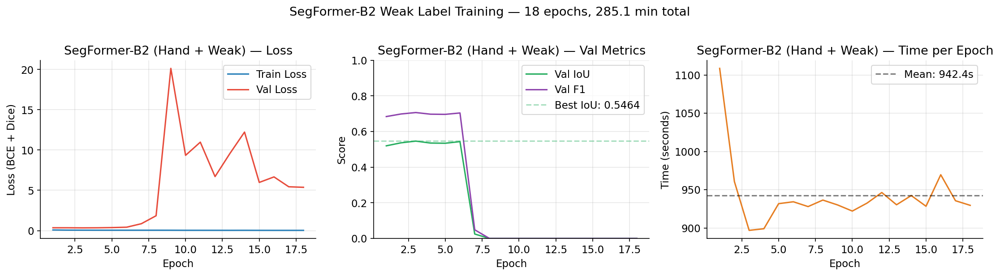

In [35]:
if weak_history and 'history' in weak_history:
    history     = weak_history['history']
    epochs      = [h['epoch']              for h in history]
    train_loss  = [h['train_loss']         for h in history]
    val_loss    = [h['val_loss']           for h in history]
    val_iou     = [h['val_iou']            for h in history]
    val_f1      = [h['val_f1']             for h in history]
    epoch_times = [h['epoch_time_seconds'] for h in history]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(epochs, train_loss, label='Train Loss', color='#2980b9', linewidth=1.5)
    axes[0].plot(epochs, val_loss,   label='Val Loss',   color='#e74c3c', linewidth=1.5)
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss (BCE + Dice)')
    axes[0].set_title('SegFormer-B2 (Hand + Weak) — Loss')
    axes[0].legend()

    axes[1].plot(epochs, val_iou, label='Val IoU', color='#27ae60', linewidth=1.5)
    axes[1].plot(epochs, val_f1,  label='Val F1',  color='#8e44ad', linewidth=1.5)
    axes[1].axhline(max(val_iou), color='#27ae60', linestyle='--', alpha=0.4,
                    label=f'Best IoU: {max(val_iou):.4f}')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score')
    axes[1].set_title('SegFormer-B2 (Hand + Weak) — Val Metrics')
    axes[1].legend(); axes[1].set_ylim(0, 1)

    axes[2].plot(epochs, epoch_times, color='#e67e22', linewidth=1.5)
    axes[2].axhline(np.mean(epoch_times), color='black', linestyle='--', alpha=0.5,
                    label=f'Mean: {np.mean(epoch_times):.1f}s')
    axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Time (seconds)')
    axes[2].set_title('SegFormer-B2 (Hand + Weak) — Time per Epoch')
    axes[2].legend()

    plt.suptitle(
        f'SegFormer-B2 Weak Label Training — '
        f'{weak_history["epochs_run"]} epochs, '
        f'{weak_history["total_training_minutes"]:.1f} min total',
        y=1.02
    )
    plt.tight_layout()
    save_figure(fig, 'segformer_weak_labels_training_curves', subdir='weak_labels')
    plt.show()
else:
    print('No training history available for plotting.')

---
## 12.7 — Test Set Evaluation (Spain and USA — Hand-Labelled Only)

Critically, the test set is **unchanged** — the same 99 hand-labelled
Spain and USA tiles used in every section from 5 through 11. This is what
makes the comparison with the hand-only result valid: the test set is
identical, only the training data changed.

We use `weak_norm_stats` for inference normalisation so the input
distribution matches what this model was trained on.

In [36]:
# Reload weak-label normalisation stats from checkpoint
weak_norm_stats = load_checkpoint('weak_labels_normalisation_stats')

if weak_norm_stats is None:
    raise RuntimeError(
        'weak_labels_normalisation_stats checkpoint not found. '
        'Re-run the normalisation stats cell in Section 12 to regenerate it.'
    )

print('Weak-label normalisation statistics loaded:')
print(f'  VV: mean={weak_norm_stats["vv_mean"]:.6f}, std={weak_norm_stats["vv_std"]:.6f}')
print(f'  VH: mean={weak_norm_stats["vh_mean"]:.6f}, std={weak_norm_stats["vh_std"]:.6f}')

INFO | Checkpoint loaded <- C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\checkpoints\weak_labels_normalisation_stats.pkl


Weak-label normalisation statistics loaded:
  VV: mean=-10.825105, std=2.153786
  VH: mean=-17.494604, std=3.229956


In [37]:
import time as time_module

print('Evaluating SegFormer-B2 (hand + weak) on test tiles (Spain and USA)...')
print()

weak_test_results = []
all_test_preds_weak, all_test_labels_weak = [], []

test_start = time_module.time()

for tile_record in tqdm(patch_coords['test'], desc='Test inference'):
    pred_mask, label, nodata_mask = sliding_window_inference(
        model=weak_segformer,
        tile_record=tile_record,
        norm_stats=weak_norm_stats,    # ← trained on combined, infer with combined stats
        patch_size=PATCH_SIZE,
        overlap=SLIDING_WINDOW_OVERLAP,
        device=DEVICE
    )
    tile_metrics = compute_segmentation_metrics(pred_mask, label)
    tile_metrics['region']  = tile_record['region']
    tile_metrics['tile_id'] = tile_record.get('tile_id', 'unknown')
    weak_test_results.append(tile_metrics)
    all_test_preds_weak.append(pred_mask)
    all_test_labels_weak.append(label)

test_time = time_module.time() - test_start

# ── Overall metrics ──────────────────────────────────────────────────────────
all_preds_arr  = np.stack(all_test_preds_weak,  axis=0)
all_labels_arr = np.stack(all_test_labels_weak, axis=0)
weak_test_metrics = compute_segmentation_metrics(all_preds_arr, all_labels_arr)

print()
print(f'Overall test results ({len(patch_coords["test"])} tiles):')
print(f'  IoU:       {weak_test_metrics["iou"]:.4f}')
print(f'  F1:        {weak_test_metrics["f1"]:.4f}')
print(f'  Precision: {weak_test_metrics["precision"]:.4f}')
print(f'  Recall:    {weak_test_metrics["recall"]:.4f}')
print(f'  Inference time: {test_time:.1f}s')

# ── Per-region breakdown ─────────────────────────────────────────────────────
import pandas as pd
test_df_weak = pd.DataFrame(weak_test_results)
print()
print('Per-region breakdown:')
print(test_df_weak.groupby('region')[['iou','f1','precision','recall']].mean().round(4).to_string())

Evaluating SegFormer-B2 (hand + weak) on test tiles (Spain and USA)...



Test inference:   0%|          | 0/99 [00:00<?, ?it/s]


Overall test results (99 tiles):
  IoU:       0.5978
  F1:        0.7483
  Precision: 0.7263
  Recall:    0.7716
  Inference time: 41.7s

Per-region breakdown:
           iou      f1  precision  recall
region                                   
Spain   0.3855  0.4720     0.4689  0.5149
USA     0.3292  0.4487     0.5405  0.4690


---
## 12.8 — Save Complete Metrics

In [39]:
import numpy as np

def convert_numpy(obj):
    """Recursively convert numpy types to native Python types for JSON serialisation."""
    if isinstance(obj, dict):
        return {k: convert_numpy(v) for k, v in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [convert_numpy(v) for v in obj]
    elif isinstance(obj, (np.float32, np.float64)):
        return float(obj)
    elif isinstance(obj, (np.int32, np.int64)):
        return int(obj)
    elif isinstance(obj, np.bool_):
        return bool(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    return obj

weak_full_metrics = {
    'model_name':              'SegFormerB2_HandPlusWeak',
    'training_data':           'hand-labelled (446 tiles) + weakly-labelled (4,384 tiles)',
    'n_hand_train_patches':    len(hand_train_patches),
    'n_weak_patches':          len(weak_patches),
    'n_combined_train_patches': len(combined_train_patches),
    'expansion_factor':        round(len(combined_train_patches) / len(hand_train_patches), 1),
    'norm_stats':              weak_norm_stats,
    'epochs_run':              weak_history['epochs_run'] if weak_history else None,
    'best_val_iou':            weak_history['best_val_iou'] if weak_history else None,
    'total_training_minutes':  weak_history.get('total_training_minutes') if weak_history else None,
    'test_inference_seconds':  test_time,
    'test_metrics_overall':    weak_test_metrics,
    'test_metrics_per_tile':   weak_test_results,
}

weak_full_metrics = convert_numpy(weak_full_metrics)  # <-- this line was missing

save_metrics(weak_full_metrics, 'segformer_weak_labels_full_metrics')
print('Saved to metrics/segformer_weak_labels_full_metrics.json')

INFO | Metrics saved -> C:\Users\954847\OneDrive - hull.ac.uk\Desktop\Sen1Floods11\flood_seg_outputs\metrics\segformer_weak_labels_full_metrics.json


Saved to metrics/segformer_weak_labels_full_metrics.json
